# Reproducing the FY2025 engine dispatches in SimPy: step log and evidence

**Goal.** A SimPy simulator, built on `code/reproduce_simulator.py` (the Lombok queue model), whose output equals the
FY2025 Gainesville–Alachua engine dispatch data, cancelled runs included. Later changes (for example move-ups) then start
from a simulator shown to reproduce today's system with today's inputs.

**Lombok → fire.** Damaged house → call; contractor → engine (a one-crew SimPy resource);
pre-construction delay + construction → turnout + travel + on-scene work; recovery curve → response and completion curves.

**How it was built.** One change at a time; after each change the code was run, its inputs and outputs printed and checked.
This notebook re-runs every step with the code exactly as it was at that step, including the checks that turned out
wrong and the fixes. The final file is `code/reproduce_dispatch_simulator.py`.

**Section 1 — Reproduce the current dispatching log.** All 37,194 engine runs get the same four CAD times as in 2025;
the rebuilt 32-column dispatch table equals the 2025 table; all 11 response curves match point for point (largest
difference 0.0); the simulator's `response_curves.csv` is byte-identical to the 2025 file the dashboard draws.
Step 1.7 adds an availability check inside `simulate` and is the gate: Section 2 runs only if, with every engine
available and the 2025 engine chosen, the log is still reproduced exactly.

**Section 2 — Any changes if using the protocol?** The SOC 2024 rule (the available engine with the shortest
estimated travel, GFR and ACFR pooled) picks the 2025 engine for 70% of runs (74% of first engines). Dispatch and
en-route curves do not move; first-on-scene curves move by up to 5 percentage points; against a control that uses
the same travel estimate, the rule is 0.3 min faster at the median and 0.9 min at P90. That gain is an optimistic
bound, because the rule is judged by the same estimate it minimises.

# Section 1 — Reproduce the current dispatching log

## Step 1.1 — New file; load the input and print it

**Change.** Created `code/reproduce_dispatch_simulator.py` with a constants block, `show_table` and `load_inputs`
(this first version also reads the 2025 response curves).
**Check.** 37,194 engine runs × 32 columns, 33,156 calls, 29 engines; the four CAD time columns are datetimes;
the 2025 curves have 2,291 rows.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="Pandas requires version")   # numexpr version notice from the environment
warnings.filterwarnings("ignore", message="invalid value encountered in cast")  # pandas 3 turning missing seconds into NaT

from pathlib import Path

import numpy as np
import pandas as pd
import simpy

PROJECT_ROOT = Path("/Users/qianchenyu/Documents/geoai_for_fire_research")                    # [SOURCE] project folder
DISPATCHES_PARQUET = PROJECT_ROOT / "data" / "derived" / "engine_dispatches_fy2025" / "engine_dispatches.parquet"  # [SOURCE]
OBSERVED_CURVES_CSV = PROJECT_ROOT / "data" / "reports" / "engine_dispatches_fy2025" / "response_curves.csv"         # [SOURCE]
TIME_COLUMNS = ["dispatched_at", "enroute_at", "arrived_at", "cleared_at"]  # [SOURCE] CAD times of one engine run, in order
VERBOSE = True                                                              # [DESIGN] print every input and output table


def show_table(name, table, verbose=VERBOSE):
    """Print a table's shape and first five rows, every column.

    Example: show_table("demo", pd.DataFrame({"a": [1, 2]})) -> None; prints "--- demo (2, 1)" and the rows
    """
    if verbose:
        with pd.option_context("display.width", 250, "display.max_columns", None):
            print(f"--- {name} {table.shape}\n{table.head(5).to_string()}\n")


def load_inputs(verbose=VERBOSE):
    """The 2025 dispatch table (one row per engine run) and the 2025 response curves.

    Example: load_inputs() -> (DataFrame (37194, 32), DataFrame (2291, 5))
    """
    dispatches = pd.read_parquet(DISPATCHES_PARQUET)
    observed_curves = pd.read_csv(OBSERVED_CURVES_CSV)
    show_table("2025 engine dispatches (input)", dispatches, verbose)
    show_table("2025 response curves (to reproduce)", observed_curves, verbose)
    if verbose:
        print(f"incidents {dispatches.incident_id.nunique():,}, engines {dispatches.engine_id.nunique()}, "
              f"time columns {dispatches[TIME_COLUMNS].dtypes.astype(str).to_dict()}")
    return dispatches, observed_curves

In [2]:
dispatches, observed_curves = load_inputs()

--- 2025 engine dispatches (input) (37194, 32)
   incident_id    call_received_at                      problem call_type protocol determinant_level determinant_code  priority  n_engines_sent  incident_lon  incident_lat jurisdiction  focal engine_id engine_type engine_agency  engine_lon_at_dispatch  engine_lat_at_dispatch from_station  at_home       dispatched_at          enroute_at          arrived_at          cleared_at  turnout_s  travel_s  on_scene_s  arrival_order  staged  cancelled  auto_aid                                qc_note
0  100124-0043 2024-10-01 01:52:55      E06 - BREATHING PROBLEM   Medical      E06              <NA>              E06  Moderate               1    -82.087103     29.602245         ACFR  False       E62           E       non-GFR              -82.086615               29.585837         <NA>     True 2024-10-01 01:53:16 2024-10-01 01:54:18 2024-10-01 02:00:55 2024-10-01 02:03:24         62       397         149              1   False      False     False     

As expected: 37,194 × 32, 33,156 calls, 29 engines, datetime columns, 2,291 curve rows.

## Step 1.2 — Replay input: seconds since midnight of the first day, and checks that would break an exact replay

**Change.** `build_runs` turns each run's call time and four CAD times into seconds since 2024-10-01 00:00 and prints
five checks: whole seconds; which times are recorded; a later time before an earlier one; dispatch before the call;
an engine dispatched again before its previous run cleared.

In [3]:
def build_runs(dispatches, verbose=VERBOSE):
    """Replay input: the call time and the CAD times of each engine run, in seconds since the first day's midnight.

    Example: build_runs(dispatches).loc[0, ["engine_id", "call_received_at", "dispatched_at"]].tolist()
             -> ['E62', 6775.0, 6796.0]  # 2024-10-01 01:52:55 and 01:53:16
    """
    day_zero = dispatches["call_received_at"].min().floor("D")
    runs = dispatches[["incident_id", "engine_id"]].copy()
    for column in ["call_received_at"] + TIME_COLUMNS:
        runs[column] = (dispatches[column] - day_zero).dt.total_seconds()
    show_table(f"engine runs, seconds since {day_zero}", runs, verbose)
    if verbose:
        stamps = runs[TIME_COLUMNS]
        gaps = stamps.ffill(axis=1).diff(axis=1).iloc[:, 1:]                  # between consecutive recorded times
        order = runs.sort_values(["engine_id", "dispatched_at"])
        previous_clear = order.groupby("engine_id")["cleared_at"].shift()
        print("all times whole seconds:", bool((stamps.stack() % 1 == 0).all()))
        print("times recorded (1 = present, order dispatched/enroute/arrived/cleared):",
              stamps.notna().astype(int).astype(str).agg("".join, axis=1).value_counts().to_dict())
        print("a later time before an earlier one:", int((gaps < 0).any(axis=1).sum()), "runs")
        print("dispatched before the call:", int((runs.dispatched_at < runs.call_received_at).sum()), "runs")
        print("engine dispatched again before its previous run cleared:", int((order.dispatched_at < previous_clear).sum()), "runs")
    return runs

In [4]:
runs = build_runs(dispatches)

--- engine runs, seconds since 2024-10-01 00:00:00 (37194, 7)
   incident_id engine_id  call_received_at  dispatched_at  enroute_at  arrived_at  cleared_at
0  100124-0043       E62            6775.0         6796.0      6858.0      7255.0      7404.0
1  100124-0113       E62           23852.0        23905.0     23956.0     24342.0     25096.0
2  100124-0165       E29           28106.0        28215.0     28215.0     28388.0     30243.0
3  100124-0184       E60           29358.0        29358.0     29358.0     29358.0     31952.0
4  100124-0313       E40           36718.0        36851.0     36891.0     37848.0     38593.0

all times whole seconds: False


times recorded (1 = present, order dispatched/enroute/arrived/cleared): {'1111': 30475, '1101': 6716, '1110': 2, '1100': 1}
a later time before an earlier one: 2 runs
dispatched before the call: 0 runs
engine dispatched again before its previous run cleared: 3 runs


"All times whole seconds: False" and three kinds of odd runs. Before changing anything, look at the rows behind each finding.

In [5]:
shown = ["incident_id", "engine_id", "call_received_at"] + TIME_COLUMNS + ["cancelled", "qc_note"]
print("stamps with a fraction of a second, per column:",
      {column: int((dispatches[column].dropna().dt.microsecond != 0).sum()) for column in ["call_received_at"] + TIME_COLUMNS})
print("missing time values (NaN) in the runs table:", int(runs[TIME_COLUMNS].isna().sum().sum()),
      "| NaN % 1 == 0 is", bool(np.nan % 1 == 0), "| pandas", pd.__version__, "keeps NaN in DataFrame.stack()")

out_of_order = dispatches[TIME_COLUMNS].ffill(axis=1).diff(axis=1).iloc[:, 1:].lt(pd.Timedelta(0)).any(axis=1)
print("\n--- times out of order\n" + dispatches.loc[out_of_order, shown].to_string())

by_engine = dispatches.sort_values(["engine_id", "dispatched_at"])
reassigned_new = by_engine.dispatched_at < by_engine.groupby("engine_id").cleared_at.shift()
reassigned_old = reassigned_new.shift(-1, fill_value=False)
reassigned = by_engine.index[reassigned_new | reassigned_old]
print("\n--- engine dispatched again before its previous run cleared (each previous run, then the new one)\n"
      + dispatches.loc[reassigned, shown].to_string())

no_clear = dispatches.cleared_at.isna()
print("\n--- no clear time\n" + dispatches.loc[no_clear, shown].to_string())

stamps with a fraction of a second, per column: {'call_received_at': 0, 'dispatched_at': 0, 'enroute_at': 0, 'arrived_at': 0, 'cleared_at': 0}
missing time values (NaN) in the runs table: 6720 | NaN % 1 == 0 is False | pandas 3.0.1 keeps NaN in DataFrame.stack()

--- times out of order
       incident_id engine_id    call_received_at       dispatched_at          enroute_at          arrived_at          cleared_at  cancelled            qc_note
7291   031425-0307       E28 2025-03-14 10:44:47 2025-03-14 10:45:32 2025-03-14 10:46:03 2025-03-14 11:16:59 2025-03-14 11:15:16      False  negative_on_scene
14718  082825-0263       E60 2025-08-28 09:27:15 2025-08-28 09:29:08 2025-08-28 09:29:07 2025-08-28 09:32:23 2025-08-28 09:39:04      False   negative_turnout

--- engine dispatched again before its previous run cleared (each previous run, then the new one)
       incident_id engine_id    call_received_at       dispatched_at          enroute_at          arrived_at          cleared_at  cancell

**What the rows show.**
- No stamp has a fraction of a second. The check was wrong: pandas 3 keeps missing values in `DataFrame.stack()`, and
  `NaN % 1 == 0` is False. Fix the check, not the data.
- 2 runs have times out of order (E28: cleared 1 min 43 s before arriving; E60: en route 1 s before dispatch). They are
  data errors; an exact replay must visit each run's times in time order.
- 3 runs: an engine dispatched 1–3 s before its previous run cleared (E2, E5, E7). In each, the new call, dispatch and
  en route share one second, as when a returning crew picks up a new call. A one-crew resource would make these runs
  wait 1–3 s, so the replay must let the newer run take the engine.
- 3 runs have no clear time (all on 2025-08-06 morning); their `cleared_at` stays missing.

**Fix.** Count missing values as fine in the whole-seconds check.

In [6]:
def build_runs(dispatches, verbose=VERBOSE):
    """Replay input: the call time and the CAD times of each engine run, in seconds since the first day's midnight.

    Example: build_runs(dispatches).loc[0, ["engine_id", "call_received_at", "dispatched_at"]].tolist()
             -> ['E62', 6775.0, 6796.0]  # 2024-10-01 01:52:55 and 01:53:16
    """
    day_zero = dispatches["call_received_at"].min().floor("D")
    runs = dispatches[["incident_id", "engine_id"]].copy()
    for column in ["call_received_at"] + TIME_COLUMNS:
        runs[column] = (dispatches[column] - day_zero).dt.total_seconds()
    show_table(f"engine runs, seconds since {day_zero}", runs, verbose)
    if verbose:
        stamps = runs[TIME_COLUMNS]
        gaps = stamps.ffill(axis=1).diff(axis=1).iloc[:, 1:]                  # between consecutive recorded times
        order = runs.sort_values(["engine_id", "dispatched_at"])
        previous_clear = order.groupby("engine_id")["cleared_at"].shift()
        print("all times whole seconds:", bool(((stamps % 1 == 0) | stamps.isna()).all().all()))
        print("times recorded (1 = present, order dispatched/enroute/arrived/cleared):",
              stamps.notna().astype(int).astype(str).agg("".join, axis=1).value_counts().to_dict())
        print("a later time before an earlier one:", int((gaps < 0).any(axis=1).sum()), "runs")
        print("dispatched before the call:", int((runs.dispatched_at < runs.call_received_at).sum()), "runs")
        print("engine dispatched again before its previous run cleared:", int((order.dispatched_at < previous_clear).sum()), "runs")
    return runs


runs = build_runs(dispatches)

--- engine runs, seconds since 2024-10-01 00:00:00 (37194, 7)
   incident_id engine_id  call_received_at  dispatched_at  enroute_at  arrived_at  cleared_at
0  100124-0043       E62            6775.0         6796.0      6858.0      7255.0      7404.0
1  100124-0113       E62           23852.0        23905.0     23956.0     24342.0     25096.0
2  100124-0165       E29           28106.0        28215.0     28215.0     28388.0     30243.0
3  100124-0184       E60           29358.0        29358.0     29358.0     29358.0     31952.0
4  100124-0313       E40           36718.0        36851.0     36891.0     37848.0     38593.0

all times whole seconds: True


times recorded (1 = present, order dispatched/enroute/arrived/cleared): {'1111': 30475, '1101': 6716, '1110': 2, '1100': 1}
a later time before an earlier one: 2 runs
dispatched before the call: 0 runs
engine dispatched again before its previous run cleared: 3 runs


## Step 1.3 — SimPy replay of the first day

**Change.** `choose_engines` (which engines a call gets; this version returns the engines that went in 2025),
`simulate` and `compare_times`. Each engine is a one-crew `simpy.PreemptiveResource`. A run takes its engine at its
first recorded time and visits its recorded times in time order; a newer run may take an engine that an older run
still holds, and the older run keeps its times.
**Check.** For the calls of 2024-10-01, every simulated time equals the recorded one.

In [7]:
FIRST_DAY_SECONDS = 86_400                                                  # [DESIGN] step-3 check runs the first day only


def choose_engines(call_runs):
    """Which engine runs a call gets. This version: the engines that went in 2025.

    Example: choose_engines([0]) -> [0]  # row labels in the runs table
    """
    return call_runs


def simulate(runs, verbose=VERBOSE):
    """Replay every call and engine run in SimPy; returns the simulated CAD times in seconds since day zero.

    Each engine is a one-crew simpy.PreemptiveResource. A run takes its engine at its first recorded time and passes
    its recorded times in time order (two 2025 runs have them out of order). A newer run may take an engine that is
    still on an older run, as when a returning crew picks up a new call (three 2025 runs); the older run keeps its times.

    Example: simulate(runs).loc[0].tolist() -> [6796.0, 6858.0, 7255.0, 7404.0]  # dispatched, enroute, arrived, cleared
    """
    env = simpy.Environment()
    engines = {engine_id: simpy.PreemptiveResource(env, capacity=1) for engine_id in runs["engine_id"].unique()}
    simulated = pd.DataFrame(np.nan, index=runs.index, columns=TIME_COLUMNS)

    def engine_run(row):
        recorded = runs.loc[row, TIME_COLUMNS].dropna().sort_values()
        yield env.timeout(recorded.iloc[0] - env.now)
        with engines[runs.at[row, "engine_id"]].request(priority=-recorded.iloc[0]) as engine:  # newer run ranks first
            yield engine
            for column, at in recorded.items():
                try:
                    yield env.timeout(at - env.now)
                except simpy.Interrupt:                                  # engine taken by a newer run
                    yield env.timeout(at - env.now)
                simulated.at[row, column] = env.now

    def call(call_runs):
        yield env.timeout(runs.at[call_runs[0], "call_received_at"] - env.now)
        for row in choose_engines(call_runs):
            env.process(engine_run(row))

    for call_runs in runs.groupby("incident_id", sort=False).groups.values():
        env.process(call(list(call_runs)))
    env.run()
    show_table("simulated CAD times, seconds since day zero", simulated, verbose)
    return simulated


def compare_times(runs, simulated, verbose=VERBOSE):
    """Count runs whose simulated CAD times differ from the recorded ones (missing equals missing).

    Example: compare_times(runs, simulated) -> 0  # int
    """
    same = (simulated == runs[TIME_COLUMNS]) | (simulated.isna() & runs[TIME_COLUMNS].isna())
    differing = int((~same.all(axis=1)).sum())
    if verbose:
        side_by_side = pd.concat({"2025": runs[TIME_COLUMNS], "simulated": simulated}, axis=1)
        print(f"{side_by_side.head(5).to_string()}\nruns compared {len(runs):,}; runs with any time different: {differing}\n")
    return differing

In [8]:
first_day = runs[runs.call_received_at < FIRST_DAY_SECONDS]
show_table("first day's runs (input)", first_day)
compare_times(first_day, simulate(first_day))

--- first day's runs (input) (109, 7)
   incident_id engine_id  call_received_at  dispatched_at  enroute_at  arrived_at  cleared_at
0  100124-0043       E62            6775.0         6796.0      6858.0      7255.0      7404.0
1  100124-0113       E62           23852.0        23905.0     23956.0     24342.0     25096.0
2  100124-0165       E29           28106.0        28215.0     28215.0     28388.0     30243.0
3  100124-0184       E60           29358.0        29358.0     29358.0     29358.0     31952.0
4  100124-0313       E40           36718.0        36851.0     36891.0     37848.0     38593.0

--- simulated CAD times, seconds since day zero (109, 4)
   dispatched_at  enroute_at  arrived_at  cleared_at
0         6796.0      6858.0      7255.0      7404.0
1        23905.0     23956.0     24342.0     25096.0
2        28215.0     28215.0     28388.0     30243.0
3        29358.0     29358.0     29358.0     31952.0
4        36851.0     36891.0     37848.0     38593.0

           2025      

0

## Step 1.4 — The full year

**Change.** Run every FY2025 run (the first-day constant is dropped from the file).
**Check.** All 37,194 runs get their recorded times, including the eight odd runs found in step 1.2.

In [9]:
show_table("all FY2025 runs (input)", runs)
simulated = simulate(runs)
compare_times(runs, simulated)

--- all FY2025 runs (input) (37194, 7)
   incident_id engine_id  call_received_at  dispatched_at  enroute_at  arrived_at  cleared_at
0  100124-0043       E62            6775.0         6796.0      6858.0      7255.0      7404.0
1  100124-0113       E62           23852.0        23905.0     23956.0     24342.0     25096.0
2  100124-0165       E29           28106.0        28215.0     28215.0     28388.0     30243.0
3  100124-0184       E60           29358.0        29358.0     29358.0     29358.0     31952.0
4  100124-0313       E40           36718.0        36851.0     36891.0     37848.0     38593.0



--- simulated CAD times, seconds since day zero (37194, 4)
   dispatched_at  enroute_at  arrived_at  cleared_at
0         6796.0      6858.0      7255.0      7404.0
1        23905.0     23956.0     24342.0     25096.0
2        28215.0     28215.0     28388.0     30243.0
3        29358.0     29358.0     29358.0     31952.0
4        36851.0     36891.0     37848.0     38593.0

           2025                                      simulated                                 
  dispatched_at enroute_at arrived_at cleared_at dispatched_at enroute_at arrived_at cleared_at
0        6796.0     6858.0     7255.0     7404.0        6796.0     6858.0     7255.0     7404.0
1       23905.0    23956.0    24342.0    25096.0       23905.0    23956.0    24342.0    25096.0
2       28215.0    28215.0    28388.0    30243.0       28215.0    28215.0    28388.0    30243.0
3       29358.0    29358.0    29358.0    31952.0       29358.0    29358.0    29358.0    31952.0
4       36851.0    36891.0    37848.0    38593

0

In [10]:
day_zero = dispatches["call_received_at"].min().floor("D")
to_clock = lambda frame: frame.apply(lambda column: (day_zero + pd.to_timedelta(column, unit="s")).dt.strftime("%m-%d %H:%M:%S"))
kind = pd.Series("", index=dispatches.index)
kind[out_of_order] = "times out of order"
kind[reassigned_old.reindex(dispatches.index)] = "reassigned: older run"
kind[reassigned_new.reindex(dispatches.index)] = "reassigned: newer run"
kind[no_clear] = "no clear time"
odd = kind.index[kind != ""]
odd_runs = pd.concat({"run": pd.concat([dispatches.loc[odd, ["engine_id"]], kind[odd].rename("kind")], axis=1),
                      "2025": to_clock(runs.loc[odd, TIME_COLUMNS]), "simulated": to_clock(simulated.loc[odd])}, axis=1)
print(odd_runs.to_string())
print("\nodd runs with any time different:", compare_times(runs.loc[odd], simulated.loc[odd], verbose=False))

            run                                   2025                                                       simulated                                                
      engine_id                   kind   dispatched_at      enroute_at      arrived_at      cleared_at   dispatched_at      enroute_at      arrived_at      cleared_at
7291        E28     times out of order  03-14 10:45:32  03-14 10:46:03  03-14 11:16:59  03-14 11:15:16  03-14 10:45:32  03-14 10:46:03  03-14 11:16:59  03-14 11:15:16
13763       E81          no clear time  08-06 08:51:04  08-06 08:52:00  08-06 08:59:23             NaN  08-06 08:51:04  08-06 08:52:00  08-06 08:59:23             NaN
13764       E40          no clear time  08-06 09:05:14  08-06 09:06:04             NaN             NaN  08-06 09:05:14  08-06 09:06:04             NaN             NaN
14718       E60     times out of order  08-28 09:29:08  08-28 09:29:07  08-28 09:32:23  08-28 09:39:04  08-28 09:29:08  08-28 09:29:07  08-28 09:32:23  08-28 09:39:0

## Step 1.5 — Rebuild the 32-column dispatch table from the simulation

**Change.** A `DAY_ZERO` constant (2024-10-01, the start of FY2025) replaces "midnight of the first call" in `build_runs`
(the same instant). `seconds_between` and `simulated_dispatch_table` rebuild the dispatch table: the four CAD times come
from SimPy, and from them turnout, travel and on-scene seconds, the cancelled flag, arrival order and engines per call,
with the dataset build's own formulas. The other 22 columns (call and engine attributes) are inputs and are carried over.
**Check.** Every column equals the 2025 table, so every chart drawn from it is the same.

In [11]:
DAY_ZERO = pd.Timestamp("2024-10-01")                                       # [SOURCE] FY2025 starts; simulation clock 0


def build_runs(dispatches, verbose=VERBOSE):
    """Replay input: the call time and the CAD times of each engine run, in seconds since DAY_ZERO.

    Example: build_runs(dispatches).loc[0, ["engine_id", "call_received_at", "dispatched_at"]].tolist()
             -> ['E62', 6775.0, 6796.0]  # 2024-10-01 01:52:55 and 01:53:16
    """
    runs = dispatches[["incident_id", "engine_id"]].copy()
    for column in ["call_received_at"] + TIME_COLUMNS:
        runs[column] = (dispatches[column] - DAY_ZERO).dt.total_seconds()
    show_table(f"engine runs, seconds since {DAY_ZERO}", runs, verbose)
    if verbose:
        stamps = runs[TIME_COLUMNS]
        gaps = stamps.ffill(axis=1).diff(axis=1).iloc[:, 1:]                  # between consecutive recorded times
        order = runs.sort_values(["engine_id", "dispatched_at"])
        previous_clear = order.groupby("engine_id")["cleared_at"].shift()
        print("all times whole seconds:", bool(((stamps % 1 == 0) | stamps.isna()).all().all()))
        print("times recorded (1 = present, order dispatched/enroute/arrived/cleared):",
              stamps.notna().astype(int).astype(str).agg("".join, axis=1).value_counts().to_dict())
        print("a later time before an earlier one:", int((gaps < 0).any(axis=1).sum()), "runs")
        print("dispatched before the call:", int((runs.dispatched_at < runs.call_received_at).sum()), "runs")
        print("engine dispatched again before its previous run cleared:", int((order.dispatched_at < previous_clear).sum()), "runs")
    return runs


def seconds_between(later, earlier):
    """Whole seconds from one time column to another; missing when either is missing (as in the dataset build).

    Example: seconds_between(pd.Series(pd.to_datetime(["2024-10-01 01:54:18"])),
                             pd.Series(pd.to_datetime(["2024-10-01 01:53:16"]))).tolist() -> [62]
    """
    return (later - earlier).dt.total_seconds().round().astype("Int64")


def simulated_dispatch_table(dispatches, simulated, verbose=VERBOSE):
    """The dispatch table rebuilt from the simulation: CAD times from SimPy, and from them the durations,
    cancelled flag, arrival order and engines per call, with the dataset's own formulas. The other 22 columns
    (call and engine attributes) are inputs and are carried over.

    Example: simulated_dispatch_table(dispatches, simulated).shape -> (37194, 32)
    """
    table = dispatches.copy()
    for column in TIME_COLUMNS:
        table[column] = (DAY_ZERO + pd.to_timedelta(simulated[column], unit="s")).astype(dispatches[column].dtype)
    table["turnout_s"] = seconds_between(table["enroute_at"], table["dispatched_at"])
    table["travel_s"] = seconds_between(table["arrived_at"], table["enroute_at"])
    table["on_scene_s"] = seconds_between(table["cleared_at"], table["arrived_at"])
    table["cancelled"] = table["arrived_at"].isna().astype("boolean")
    table["arrival_order"] = table.groupby("incident_id")["arrived_at"].rank(method="first").astype("Int64")
    table["n_engines_sent"] = table.groupby("incident_id")["engine_id"].transform("size").astype("Int64")
    show_table("simulated dispatch table", table, verbose)
    if verbose:
        differing = [column for column in dispatches.columns if not table[column].equals(dispatches[column])]
        print(f"columns that differ from the 2025 table: {differing}; whole table equal: {table.equals(dispatches)}\n")
    return table

In [12]:
runs_before = runs
runs = build_runs(dispatches, verbose=False)
print("runs table unchanged by DAY_ZERO:", runs.equals(runs_before))
simulated = simulate(runs, verbose=False)
table = simulated_dispatch_table(dispatches, simulated)

runs table unchanged by DAY_ZERO: True


--- simulated dispatch table (37194, 32)
   incident_id    call_received_at                      problem call_type protocol determinant_level determinant_code  priority  n_engines_sent  incident_lon  incident_lat jurisdiction  focal engine_id engine_type engine_agency  engine_lon_at_dispatch  engine_lat_at_dispatch from_station  at_home       dispatched_at          enroute_at          arrived_at          cleared_at  turnout_s  travel_s  on_scene_s  arrival_order  staged  cancelled  auto_aid                                qc_note
0  100124-0043 2024-10-01 01:52:55      E06 - BREATHING PROBLEM   Medical      E06              <NA>              E06  Moderate               1    -82.087103     29.602245         ACFR  False       E62           E       non-GFR              -82.086615               29.585837         <NA>     True 2024-10-01 01:53:16 2024-10-01 01:54:18 2024-10-01 02:00:55 2024-10-01 02:03:24         62       397         149              1   False      False     False           

## Step 1.6 — Response curves from the simulated table

**Change.** `response_curves` (the definition behind the 2025 dashboard curves: the share of calls that reached each
stage within t minutes of their own call), `compare_curves` and `write_outputs`. First comparison: against the 2025
curves as read from their CSV file.

In [13]:
RESPONSE_GRID_MINUTES = np.round(np.arange(0, 20.0001, 0.1), 1)             # [SOURCE] grid of the 2025 response curves
COMPLETION_GRID_MINUTES = np.arange(0, 241, 1.0)                            # [SOURCE] grid of the 2025 completion curves
AREA_LABELS = {True: "inside city", False: "outside city"}                  # [SOURCE] focal = call inside Gainesville
PRIORITY_LABELS = ["Low", "Moderate", "High", "(missing)"]                  # [SOURCE] 2025 priority groups
OUTPUT_DIR = PROJECT_ROOT / "data" / "reports" / "reproduce_dispatch_simulator"  # [DESIGN]


def response_curves(table, verbose=VERBOSE):
    """Share of calls that reached each stage within t minutes of their own call, defined as the 2025 curves are.

    The denominator is every call in the group, so calls no engine reached keep a curve below 100%.

    Example: response_curves(table).query("curve == 'stages' and series == 'first_on_scene' and minute == 20.0")
             ["share"].tolist() -> [0.856...]
    """
    per_call = table.groupby("incident_id").agg(
        call=("call_received_at", "min"), dispatched=("dispatched_at", "min"), en_route=("enroute_at", "min"),
        first_on_scene=("arrived_at", "min"), last_cleared=("cleared_at", "max"),
        focal=("focal", "first"), priority=("priority", "first"))
    minutes = {stage: (per_call[stage] - per_call["call"]).dt.total_seconds() / 60
               for stage in ["dispatched", "en_route", "first_on_scene", "last_cleared"]}
    area = per_call["focal"].map(AREA_LABELS)
    priority = per_call["priority"].astype("string").fillna("(missing)")
    specs = [("stages", stage, minutes[stage], RESPONSE_GRID_MINUTES) for stage in ["dispatched", "en_route", "first_on_scene"]]
    specs += [("completion", stage, minutes[stage], COMPLETION_GRID_MINUTES) for stage in ["first_on_scene", "last_cleared"]]
    specs += [("first_on_scene_by_area", label, minutes["first_on_scene"][area == label], RESPONSE_GRID_MINUTES)
              for label in AREA_LABELS.values()]
    specs += [("first_on_scene_by_priority", label, minutes["first_on_scene"][priority == label], RESPONSE_GRID_MINUTES)
              for label in PRIORITY_LABELS]
    pieces = []
    for curve, series, values, grid in specs:
        reached = np.sort(values.dropna().to_numpy())
        pieces.append(pd.DataFrame({"curve": curve, "series": series, "minute": grid,
                                    "share": np.searchsorted(reached, grid, side="right") / len(values),
                                    "incidents": len(values)}))
    curves = pd.concat(pieces, ignore_index=True)
    show_table("simulated response curves", curves, verbose)
    return curves


def compare_curves(simulated_curves, observed_curves, verbose=VERBOSE):
    """Per curve: grid points, points found in both, the largest |simulated - 2025| share, and the call counts.

    Example: compare_curves(simulated_curves, observed_curves)["max_abs_difference"].max() -> 0.0
    """
    both = simulated_curves.merge(observed_curves, on=["curve", "series", "minute"], how="outer",
                                  suffixes=("_simulated", "_2025"), indicator=True)
    both["abs_difference"] = (both["share_simulated"] - both["share_2025"]).abs()
    check = both.groupby(["curve", "series"], sort=False).agg(
        points=("minute", "size"), points_in_both=("_merge", lambda merge: int((merge == "both").sum())),
        max_abs_difference=("abs_difference", "max"),
        calls_simulated=("incidents_simulated", "first"), calls_2025=("incidents_2025", "first")).reset_index()
    if verbose:
        print(f"--- simulated vs 2025 curves {check.shape}\n{check.to_string()}\n")
    return check


def write_outputs(table, curves, check):
    """Save the simulated dispatch table, its response curves and the curve check."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    table.to_parquet(OUTPUT_DIR / "simulated_dispatches.parquet", index=False)
    curves.to_csv(OUTPUT_DIR / "response_curves.csv", index=False)
    check.to_csv(OUTPUT_DIR / "curve_check.csv", index=False)
    print(f"wrote simulated_dispatches.parquet, response_curves.csv and curve_check.csv to {OUTPUT_DIR}")

In [14]:
curves = response_curves(table)
check_against_csv = compare_curves(curves, observed_curves)

--- simulated response curves (2291, 5)
    curve      series  minute     share  incidents
0  stages  dispatched     0.0  0.010677      33156
1  stages  dispatched     0.1  0.010828      33156
2  stages  dispatched     0.2  0.016618      33156
3  stages  dispatched     0.3  0.031276      33156
4  stages  dispatched     0.4  0.052509      33156

--- simulated vs 2025 curves (11, 7)
                         curve          series  points  points_in_both  max_abs_difference  calls_simulated  calls_2025
0                   completion  first_on_scene     241             241        9.150666e-17            33156       33156
1                   completion    last_cleared     241             241        1.110223e-16            33156       33156
2       first_on_scene_by_area     inside city     201             201        9.194034e-17            18732       18732
3       first_on_scene_by_area    outside city     201             201        9.714451e-17            14420       14420
4   first_on_sce

Every point and every call count lines up, but the largest difference is about 1e-16, not 0. Compare the files
themselves, and read our own file back the same way.

In [15]:
import hashlib

write_outputs(table, curves, check_against_csv)
for path in [OUTPUT_DIR / "response_curves.csv", OBSERVED_CURVES_CSV]:
    print(hashlib.sha256(path.read_bytes()).hexdigest(), path.relative_to(PROJECT_ROOT))
our_file_read_back = pd.read_csv(OUTPUT_DIR / "response_curves.csv")
print("largest |in memory - our own file read back|:", float((curves["share"] - our_file_read_back["share"]).abs().max()))

wrote simulated_dispatches.parquet, response_curves.csv and curve_check.csv to /Users/qianchenyu/Documents/geoai_for_fire_research/data/reports/reproduce_dispatch_simulator
6aca9550cd96c978b87c81d54a065d3595a49e492197349db79b743dc1a8d621 data/reports/reproduce_dispatch_simulator/response_curves.csv
6aca9550cd96c978b87c81d54a065d3595a49e492197349db79b743dc1a8d621 data/reports/engine_dispatches_fy2025/response_curves.csv
largest |in memory - our own file read back|: 1.1102230246251565e-16


The two files are byte-identical, and our own curves differ from our own file read back by the same 1e-16. The gap
comes from writing floats to text and reading them back, not from the simulation.

**Fix.** Compare in memory against the curves computed by the same function on the 2025 table; `load_inputs` no longer
reads the CSV, which is kept for a byte check inside `write_outputs`.

In [16]:
def load_inputs(verbose=VERBOSE):
    """The 2025 dispatch table, one row per engine run.

    Example: load_inputs() -> DataFrame (37194, 32)
    """
    dispatches = pd.read_parquet(DISPATCHES_PARQUET)
    show_table("2025 engine dispatches (input)", dispatches, verbose)
    if verbose:
        print(f"incidents {dispatches.incident_id.nunique():,}, engines {dispatches.engine_id.nunique()}, "
              f"time columns {dispatches[TIME_COLUMNS].dtypes.astype(str).to_dict()}")
    return dispatches


def write_outputs(table, curves, check):
    """Save the simulated dispatch table, its response curves and the curve check; say whether the curve file
    is byte-identical to the 2025 one the dashboard draws."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    table.to_parquet(OUTPUT_DIR / "simulated_dispatches.parquet", index=False)
    curves.to_csv(OUTPUT_DIR / "response_curves.csv", index=False)
    check.to_csv(OUTPUT_DIR / "curve_check.csv", index=False)
    same_file = (OUTPUT_DIR / "response_curves.csv").read_bytes() == OBSERVED_CURVES_CSV.read_bytes()
    print(f"wrote simulated_dispatches.parquet, response_curves.csv and curve_check.csv to {OUTPUT_DIR}\n"
          f"response_curves.csv byte-identical to {OBSERVED_CURVES_CSV.relative_to(PROJECT_ROOT)}: {same_file}")

In [17]:
dispatches = load_inputs(verbose=False)
curves_2025 = response_curves(dispatches, verbose=False)        # same definition on the 2025 table
check = compare_curves(curves, curves_2025)
write_outputs(table, curves, check)

--- simulated vs 2025 curves (11, 7)
                         curve          series  points  points_in_both  max_abs_difference  calls_simulated  calls_2025
0                   completion  first_on_scene     241             241                 0.0            33156       33156
1                   completion    last_cleared     241             241                 0.0            33156       33156
2       first_on_scene_by_area     inside city     201             201                 0.0            18732       18732
3       first_on_scene_by_area    outside city     201             201                 0.0            14420       14420
4   first_on_scene_by_priority       (missing)     201             201                 0.0             4029        4029
5   first_on_scene_by_priority            High     201             201                 0.0             9121        9121
6   first_on_scene_by_priority             Low     201             201                 0.0            11728       11728
7  

## Section 1 evidence

One table of what was compared, and the curves drawn from the 2025 data and from the simulation on the same axes.

In [18]:
same_file = (OUTPUT_DIR / "response_curves.csv").read_bytes() == OBSERVED_CURVES_CSV.read_bytes()
evidence = pd.DataFrame([
    ("engine runs, four CAD times each", f"{len(runs):,} runs", f"{compare_times(runs, simulated, verbose=False)} runs differ"),
    ("rebuilt dispatch table", f"{table.shape[1]} columns × {len(table):,} rows",
     f"{sum(not table[column].equals(dispatches[column]) for column in dispatches.columns)} columns differ"),
    ("response and completion curves", f"{len(check)} curves, {int(check['points'].sum()):,} points",
     f"largest |difference| {check['max_abs_difference'].max()}"),
    ("calls behind each curve", f"{len(check)} curves", f"{int((check['calls_simulated'] != check['calls_2025']).sum())} differ"),
    ("response_curves.csv", "simulated file vs the 2025 dashboard file", "byte-identical" if same_file else "DIFFERENT"),
], columns=["compared", "how much", "result"])
evidence

,compared,how much,result
0,"engine runs, four CAD times each","37,194 runs",0 runs differ
1,rebuilt dispatch table,"32 columns × 37,194 rows",0 columns differ
2,response and completion curves,"11 curves, 2,291 points",largest |difference| 0.0
3,calls behind each curve,11 curves,0 differ
4,response_curves.csv,simulated file vs the 2025 dashboard file,byte-identical


**Added after review: RMSE in every panel.** `compare_curves` now also reports, for each curve, the RMSE between the
simulated curve and its 2025 curve (share of calls, over the curve's time grid). In the figures the simulated curve is
solid and the 2025 record dashed on top, and each panel's title carries its RMSE.

In [19]:
from sklearn.metrics import root_mean_squared_error


def compare_curves(simulated_curves, observed_curves, verbose=VERBOSE):
    """Per curve: grid points, points found in both, RMSE and largest |simulated - 2025| share, and the call counts.

    Example: compare_curves(simulated_curves, observed_curves)[["rmse", "max_abs_difference"]].max().tolist() -> [0.0, 0.0]
    """
    both = simulated_curves.merge(observed_curves, on=["curve", "series", "minute"], how="outer",
                                  suffixes=("_simulated", "_2025"), indicator=True)
    both["abs_difference"] = (both["share_simulated"] - both["share_2025"]).abs()
    by_curve = both.groupby(["curve", "series"], sort=False)
    check = by_curve.agg(
        points=("minute", "size"), points_in_both=("_merge", lambda merge: int((merge == "both").sum())),
        max_abs_difference=("abs_difference", "max"),
        calls_simulated=("incidents_simulated", "first"), calls_2025=("incidents_2025", "first")).reset_index()
    check.insert(4, "rmse", [root_mean_squared_error(part["share_2025"], part["share_simulated"]) for _, part in by_curve])
    if verbose:
        print(f"--- simulated vs 2025 curves {check.shape}\n{check.to_string()}\n")
    return check


check = compare_curves(curves, curves_2025)

--- simulated vs 2025 curves (11, 8)
                         curve          series  points  points_in_both  rmse  max_abs_difference  calls_simulated  calls_2025
0                   completion  first_on_scene     241             241   0.0                 0.0            33156       33156
1                   completion    last_cleared     241             241   0.0                 0.0            33156       33156
2       first_on_scene_by_area     inside city     201             201   0.0                 0.0            18732       18732
3       first_on_scene_by_area    outside city     201             201   0.0                 0.0            14420       14420
4   first_on_scene_by_priority       (missing)     201             201   0.0                 0.0             4029        4029
5   first_on_scene_by_priority            High     201             201   0.0                 0.0             9121        9121
6   first_on_scene_by_priority             Low     201             201   0.0     

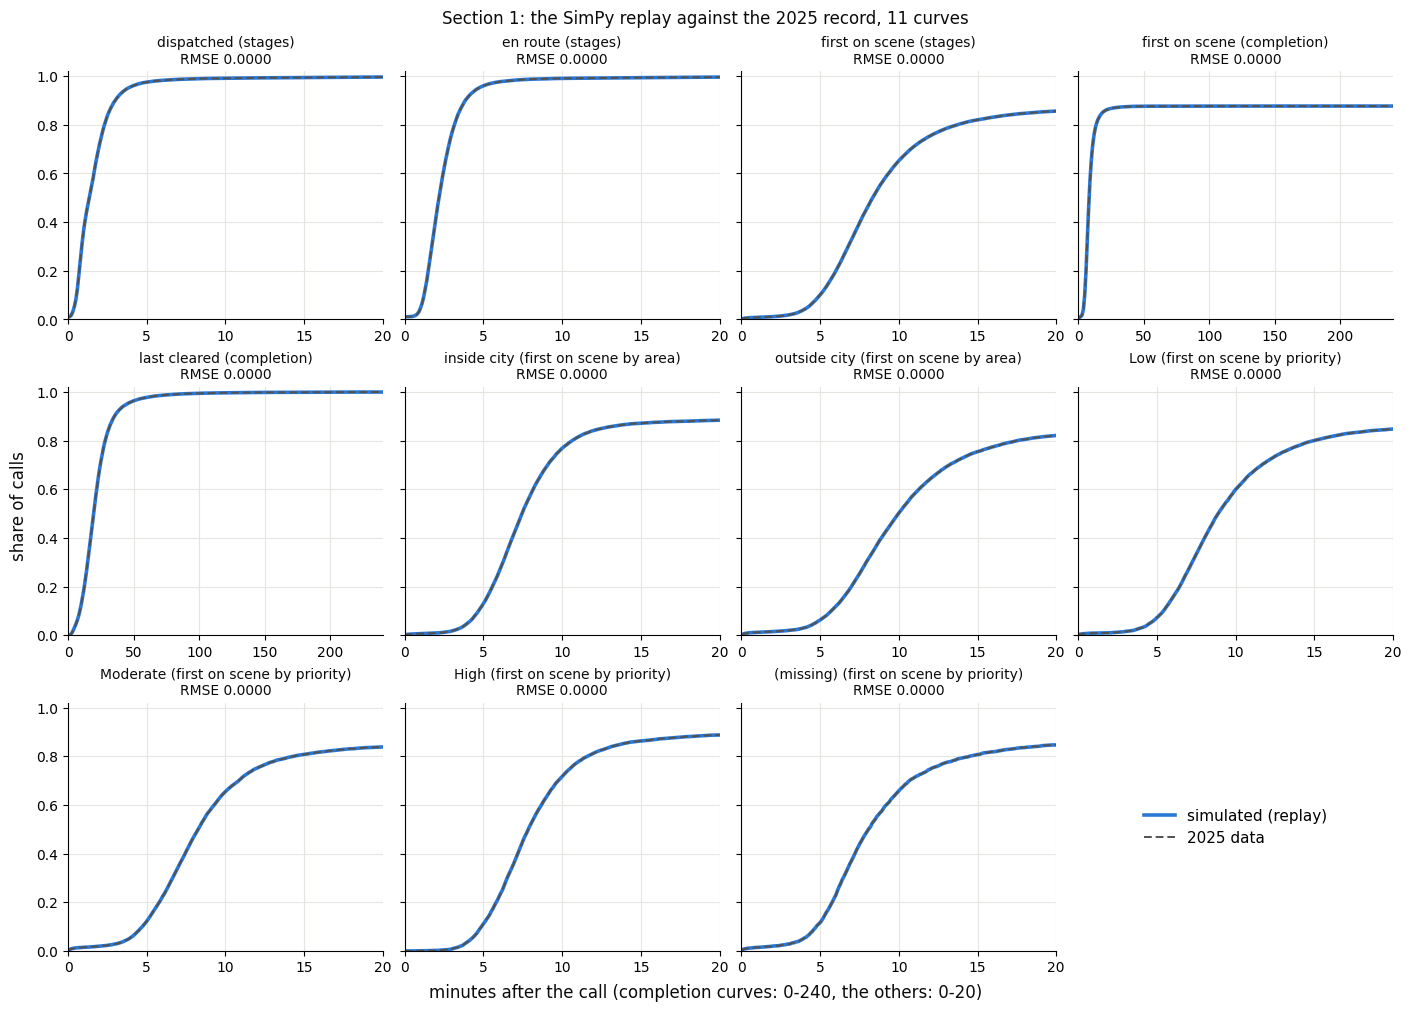

In [20]:
import matplotlib.pyplot as plt

CURVE_STYLES = {                                                            # [DESIGN] simulated solid underneath, 2025 dashed on top
    "simulated": dict(color="#2a78d6", linewidth=2.6),
    "2025 data": dict(color="#52514e", linewidth=1.4, linestyle=(0, (4, 2))),
}
INK, GRID = "#0b0b0b", "#e6e5e0"                                            # [DESIGN] text and grid colours


def plot_curves(simulated_curves, check, simulated_label, title):
    """The 11 curves, one panel each: the simulated curve solid, the 2025 curve dashed, the RMSE in the panel title.

    Example: plot_curves(curves, check, "simulated (replay)", "Section 1 ...") -> None; draws a 3 x 4 figure
    """
    rmse = check.set_index(["curve", "series"])["rmse"]
    curve_names = list(curves_2025[["curve", "series"]].drop_duplicates().itertuples(index=False))
    figure, axes = plt.subplots(3, 4, figsize=(14, 10), constrained_layout=True, sharey=True)
    for ax, (curve, series) in zip(axes.flat, curve_names):
        for label, frame, style in [(simulated_label, simulated_curves, CURVE_STYLES["simulated"]),
                                    ("2025 data", curves_2025, CURVE_STYLES["2025 data"])]:
            line = frame[(frame.curve == curve) & (frame.series == series)]
            ax.plot(line.minute, line.share, label=label, **style)
        ax.set_title(f"{series.replace('_', ' ')} ({curve.replace('_', ' ')})\nRMSE {rmse[(curve, series)]:.4f}",
                     fontsize=10, color=INK)
        ax.set(xlim=(0, line.minute.max()), ylim=(0, 1.02))
        ax.grid(color=GRID, linewidth=0.8)
        ax.spines[["top", "right"]].set_visible(False)
    axes.flat[-1].axis("off")
    axes.flat[-1].legend(*axes.flat[0].get_legend_handles_labels(), loc="center", frameon=False, fontsize=11)
    figure.supxlabel("minutes after the call (completion curves: 0-240, the others: 0-20)", color=INK)
    figure.supylabel("share of calls", color=INK)
    figure.suptitle(title, color=INK)
    plt.show()


plot_curves(curves, check, "simulated (replay)", "Section 1: the SimPy replay against the 2025 record, 11 curves")

## Step 1.7 — Gate before Section 2: an availability check inside `simulate`

**Change.**
- When a run starts, `simulate` now asks which engines CAD may send (`available`) and which one goes (`choose`), and
  it records the engine used.
- An engine other than 2025's gets a new travel time (`shift_arrival`).
- The defaults are the Section 1 rules, `all_engines_available` and `dispatched_in_2025`.
- `compare_times` now also compares the engine, and `simulated_dispatch_table` writes the engine used. It also
  turns seconds into times so that missing values become NaT without a pandas warning.
- The SimPy resources are renamed `engine_pool`, because `engines` will be the engine table.

**Gate.** With every engine available and the 2025 engine chosen, the simulator must still reproduce the 2025 log
exactly. `check_section_1` stops the notebook if it does not. It is rerun after every later change to `simulate`.

In [21]:
def all_engines_available(engine_pool, now_seconds, engines):
    """Section 1 rule for availability: every engine counts as available, whatever it is doing.

    Example: all_engines_available({"E1": ..., "E62": ...}, 6796.0, None) -> ['E1', 'E62']
    """
    return list(engine_pool)


def dispatched_in_2025(run, available_engines, estimated_travel):
    """Section 1 rule for the choice: the engine that went in 2025, keeping its recorded times (travel None).

    Example: dispatched_in_2025(runs.loc[0], ["E1", "E62"], None) -> ('E62', None)
    """
    return run["engine_id"], None


def shift_arrival(times, travel_seconds):
    """A run's CAD times with arrival and clear moved so that travel takes travel_seconds; a run with no en-route
    or no arrival time (cancelled) keeps its times.

    Example: shift_arrival(pd.Series({"dispatched_at": 0.0, "enroute_at": 60.0, "arrived_at": 400.0, "cleared_at": 900.0}),
                           300.0).tolist() -> [0.0, 60.0, 360.0, 860.0]
    """
    if pd.isna(times["enroute_at"]) or pd.isna(times["arrived_at"]):
        return times
    shift = times["enroute_at"] + travel_seconds - times["arrived_at"]
    return times + pd.Series({"dispatched_at": 0.0, "enroute_at": 0.0, "arrived_at": shift, "cleared_at": shift})


def simulate(runs, available=all_engines_available, choose=dispatched_in_2025, engines=None, estimated_travel=None,
             verbose=VERBOSE):
    """Replay every call in SimPy; returns per run the simulated CAD times (seconds since day zero) and the engine used.

    Each engine is a one-crew simpy.PreemptiveResource. When a run starts (its first recorded time), `available`
    lists the engines CAD may send and `choose` picks one with a travel time (None keeps the recorded times). The run
    then passes its times in time order (two 2025 runs have them out of order). A newer run may take an engine that is
    still on an older run, as when a returning crew picks up a new call (three 2025 runs); the older run keeps its times.
    The defaults (every engine available, the 2025 engine goes) replay the 2025 log.

    Example: simulate(runs).loc[0].tolist() -> [6796.0, 6858.0, 7255.0, 7404.0, 'E62']  # 4 CAD times, engine
    """
    env = simpy.Environment()
    engine_pool = {engine_id: simpy.PreemptiveResource(env, capacity=1) for engine_id in runs["engine_id"].unique()}
    simulated = pd.DataFrame(np.nan, index=runs.index, columns=TIME_COLUMNS)
    simulated["engine_id"] = pd.Series(index=runs.index, dtype="object")

    def engine_run(row):
        recorded = runs.loc[row, TIME_COLUMNS].dropna().sort_values()
        yield env.timeout(recorded.iloc[0] - env.now)
        engine_id, travel_seconds = choose(runs.loc[row], available(engine_pool, env.now, engines), estimated_travel)
        if travel_seconds is not None:
            recorded = shift_arrival(runs.loc[row, TIME_COLUMNS], travel_seconds).dropna().sort_values()
        simulated.at[row, "engine_id"] = engine_id
        with engine_pool[engine_id].request(priority=-recorded.iloc[0]) as engine:  # newer run ranks first
            yield engine
            for column, at in recorded.items():
                try:
                    yield env.timeout(at - env.now)
                except simpy.Interrupt:                                  # engine taken by a newer run
                    yield env.timeout(at - env.now)
                simulated.at[row, column] = env.now

    def call(call_runs):
        yield env.timeout(runs.at[call_runs[0], "call_received_at"] - env.now)
        for row in choose_engines(call_runs):
            env.process(engine_run(row))

    for call_runs in runs.groupby("incident_id", sort=False).groups.values():
        env.process(call(list(call_runs)))
    env.run()
    show_table("simulated CAD times (seconds since day zero) and engine used", simulated, verbose)
    return simulated


def compare_times(runs, simulated, verbose=VERBOSE):
    """Count runs whose simulated CAD times or engine differ from the recorded ones (missing equals missing).

    Example: compare_times(runs, simulated) -> 0  # int
    """
    columns = TIME_COLUMNS + ["engine_id"]
    same = (simulated[columns] == runs[columns]) | (simulated[columns].isna() & runs[columns].isna())
    differing = int((~same.all(axis=1)).sum())
    if verbose:
        side_by_side = pd.concat({"2025": runs[columns], "simulated": simulated[columns]}, axis=1)
        print(f"{side_by_side.head(5).to_string()}\nruns compared {len(runs):,}; runs with any time or engine different: {differing}\n")
    return differing


def simulated_dispatch_table(dispatches, simulated, engines=None, verbose=VERBOSE):
    """The dispatch table rebuilt from the simulation: CAD times from SimPy, and from them the durations,
    cancelled flag, arrival order and engines per call, with the dataset's own formulas. Call attributes are inputs
    and are carried over. Where the simulation used another engine than 2025, the engine columns describe that engine
    as sent from its home station (auto_aid unknown).

    Example: simulated_dispatch_table(dispatches, simulated).shape -> (37194, 32)
    """
    table = dispatches.copy()
    for column in TIME_COLUMNS:
        seconds = simulated[column]                              # missing stays missing (NaT) without a pandas cast warning
        table[column] = (DAY_ZERO + pd.to_timedelta(seconds.fillna(0), unit="s").where(seconds.notna())).astype(dispatches[column].dtype)
    other_engine = (simulated["engine_id"] != dispatches["engine_id"]).to_numpy()
    if other_engine.any():
        sent = engines.set_index("engine_id").loc[simulated.loc[other_engine, "engine_id"]]
        table.loc[other_engine, "engine_id"] = sent.index.to_numpy()
        for column, source in [("engine_type", "engine_type"), ("engine_agency", "engine_agency"),
                               ("engine_lon_at_dispatch", "home_lon"), ("engine_lat_at_dispatch", "home_lat"),
                               ("from_station", "home_station")]:
            table.loc[other_engine, column] = sent[source].to_numpy()
        table.loc[other_engine, "at_home"] = True
        table.loc[other_engine, "auto_aid"] = pd.NA
    table["turnout_s"] = seconds_between(table["enroute_at"], table["dispatched_at"])
    table["travel_s"] = seconds_between(table["arrived_at"], table["enroute_at"])
    table["on_scene_s"] = seconds_between(table["cleared_at"], table["arrived_at"])
    table["cancelled"] = table["arrived_at"].isna().astype("boolean")
    table["arrival_order"] = table.groupby("incident_id")["arrived_at"].rank(method="first").astype("Int64")
    table["n_engines_sent"] = table.groupby("incident_id")["engine_id"].transform("size").astype("Int64")
    show_table("simulated dispatch table", table, verbose)
    if verbose:
        differing = [column for column in dispatches.columns if not table[column].equals(dispatches[column])]
        print(f"columns that differ from the 2025 table: {differing}; whole table equal: {table.equals(dispatches)}\n")
    return table

In [22]:
def check_section_1():
    """Gate: with every engine available and the 2025 engine chosen, the simulator still reproduces the 2025 log.
    Stops the notebook (AssertionError) if any of the three checks is not 0.

    Example: check_section_1() -> None; prints the three checks and "gate passed"
    """
    gate_simulated = simulate(runs, verbose=False)
    gate_table = simulated_dispatch_table(dispatches, gate_simulated, verbose=False)
    gate_curves = response_curves(gate_table, verbose=False)
    checks = {"runs with any time or engine different": compare_times(runs, gate_simulated, verbose=False),
              "dispatch-table columns different": sum(not gate_table[column].equals(dispatches[column])
                                                      for column in dispatches.columns),
              "largest |curve difference|": float(compare_curves(gate_curves, curves_2025, verbose=False)["max_abs_difference"].max())}
    print(checks)
    assert all(value == 0 for value in checks.values()), "Section 1 is no longer reproduced: Section 2 does not run"
    print("gate passed: Section 2 may run\n")


check_section_1()

{'runs with any time or engine different': 0, 'dispatch-table columns different': 0, 'largest |curve difference|': 0.0}
gate passed: Section 2 may run



# Section 2 — Any changes if using the protocol?

GFR SOC 2024 (printed p. 70 and 146): CAD recommends the quickest unit from AVL positions and road travel times, with
GFR and ACFR engines pooled. First-due areas are used only when CAD is down.

Here, when a run starts, the available engine with the shortest estimated travel goes.
- **Kept as recorded:** the calls, how many engines each call got, and the dispatch, turnout and on-scene times.
- **Changed:** which engine goes. For an engine other than 2025's, the travel time too, estimated from the
  straight-line distance from its home station.

## Step 2.1 — Engine table

**Change.** `load_engines` reads each engine's type, agency and home position, plus its first and last FY2025
dispatch, taken here as the span it is in service.
**Check.** All 29 engines have home positions; list which engines serve only part of the year.

In [23]:
ENGINES_CSV = PROJECT_ROOT / "data" / "derived" / "engine_dispatches_fy2025" / "engines.csv"                         # [SOURCE]


def load_engines(verbose=VERBOSE):
    """The engines: type, agency, home station position, and first and last FY2025 dispatch (the in-service span).

    Example: load_engines().loc[0, ["engine_id", "home_station"]].tolist() -> ['E1', 'GFR_01']
    """
    engines = pd.read_csv(ENGINES_CSV, parse_dates=["first_seen", "last_seen"])
    show_table("engines (input)", engines, verbose)
    if verbose:
        print(f"engines {len(engines)}, agencies {engines.engine_agency.value_counts().to_dict()}, "
              f"missing home position {int(engines.home_lon.isna().sum())}, no home station {int(engines.home_station.isna().sum())}\n"
              f"in service for part of the year only: "
              f"{engines.loc[(engines.first_seen > DAY_ZERO + pd.Timedelta(days=7)) | (engines.last_seen < pd.Timestamp('2025-09-23')), ['engine_id', 'first_seen', 'last_seen', 'n_dispatches']].to_string(index=False)}\n")
    return engines


engines = load_engines()

--- engines (input) (29, 9)
  engine_id engine_type engine_agency  n_dispatches          first_seen           last_seen   home_lon   home_lat home_station
0        E1           E           GFR          2142 2024-10-01 10:09:09 2025-09-30 18:24:48 -82.324909  29.646787       GFR_01
1        Q1           Q           GFR           428 2025-03-20 09:02:11 2025-09-16 15:38:32 -82.324914  29.646828       GFR_01
2        E2           E           GFR          2690 2024-10-01 18:20:02 2025-09-30 21:42:32 -82.355012  29.635526       GFR_02
3        Q2           Q           GFR           444 2025-01-14 13:06:39 2025-09-30 19:32:00 -82.354995  29.635522       GFR_02
4        E3           E           GFR          4185 2024-10-01 01:38:18 2025-09-30 20:37:27 -82.306791  29.659937       GFR_03

engines 29, agencies {'non-GFR': 18, 'GFR': 11}, missing home position 0, no home station 4
in service for part of the year only: engine_id          first_seen           last_seen  n_dispatches
       Q1 2025-

## Step 2.2 — Travel time from straight-line distance

**Change.** `fit_travel_speed` uses one speed: the median of (straight-line km from the engine's AVL position at
dispatch to the call) ÷ (recorded travel hours), over 2025 runs with a plausible travel time.
**Check.** Estimated vs recorded travel, by distance band.

In [24]:
import pyproj

GEOD = pyproj.Geod(ellps="WGS84")                                           # [STANDARD] distances on the WGS84 ellipsoid
DISTANCE_BANDS_KM = [0, 1, 2, 4, 8, 16, 60]                                 # [DESIGN] bands for checking the travel estimate


def straight_line_km(lon_from, lat_from, lon_to, lat_to):
    """Geodesic (straight-line) distance in km on the WGS84 ellipsoid; arrays in, array out.

    Example: straight_line_km(-82.3249, 29.6468, -82.3550, 29.6355) -> 3.17 (km)
    """
    return GEOD.inv(lon_from, lat_from, lon_to, lat_to)[2] / 1000


def fit_travel_speed(dispatches, verbose=VERBOSE):
    """One speed that turns straight-line distance into travel time, fitted on 2025 runs: the median of
    (km from the engine's dispatch position to the call) / (recorded travel hours).

    Example: fit_travel_speed(dispatches) -> 22.5  # km/h (float)
    """
    usable = dispatches[dispatches.travel_s.gt(0).fillna(False)
                        & ~dispatches.qc_note.str.contains("implausible|equals_incident")
                        & dispatches[["engine_lon_at_dispatch", "incident_lon"]].notna().all(axis=1)]
    distance_km = straight_line_km(usable.engine_lon_at_dispatch.to_numpy(), usable.engine_lat_at_dispatch.to_numpy(),
                                   usable.incident_lon.to_numpy(), usable.incident_lat.to_numpy())
    recorded_minutes = usable.travel_s.to_numpy(dtype=float) / 60
    speed_kmh = float(np.median(distance_km / (recorded_minutes / 60)))
    if verbose:
        estimated_minutes = distance_km / speed_kmh * 60
        bands = pd.cut(distance_km, DISTANCE_BANDS_KM)
        error = pd.DataFrame({"band_km": bands, "recorded_min": recorded_minutes, "estimated_min": estimated_minutes,
                              "abs_error_min": np.abs(estimated_minutes - recorded_minutes)})
        print(f"runs used {len(usable):,} of {len(dispatches):,}; fitted speed {speed_kmh:.1f} km/h (straight line)\n"
              f"estimated vs recorded travel, by straight-line distance:\n"
              f"{error.groupby('band_km', observed=True).median().assign(runs=error.groupby('band_km', observed=True).size()).round(2).to_string()}\n"
              f"all runs: median |error| {np.median(error.abs_error_min):.2f} min\n")
    return speed_kmh


speed_kmh = fit_travel_speed(dispatches)

runs used 30,273 of 37,194; fitted speed 22.5 km/h (straight line)
estimated vs recorded travel, by straight-line distance:
          recorded_min  estimated_min  abs_error_min   runs
band_km                                                    
(0, 1]            3.28           1.65           1.60   5988
(1, 2]            4.63           3.97           1.02   9192
(2, 4]            6.18           7.62           1.67  10446
(4, 8]            8.88          14.01           5.35   3526
(8, 16]          12.70          26.18          14.25   1057
(16, 60]         17.88          50.00          30.69     64
all runs: median |error| 1.68 min



One speed (22.5 km/h on a straight line) gets both ends wrong:
- **Short trips are underestimated** (under 1 km: 1.7 vs 3.3 min), because every trip has a fixed start-up part.
- **Long trips are overestimated** (8–16 km: 26 vs 12.7 min), because long trips use faster roads.

**Fix.** `fit_travel_curve`:
1. Cut the runs into 40 equal-count distance bins.
2. Take each bin's median km and median travel.
3. Join them with straight lines, never decreasing, and extend the end slopes.

Ranking engines needs only distance, so this changes travel times but not which engine is quickest.

In [25]:
import scipy.interpolate

TRAVEL_CURVE_BINS = 40                                                      # [DESIGN] equal-count distance bins of the travel curve


def fit_travel_curve(dispatches, verbose=VERBOSE):
    """Travel time from straight-line distance, fitted on 2025 runs: runs are cut into equal-count distance bins and
    each bin gives (median km, median travel seconds); between bins it is linear, beyond them it extends the end
    slopes. Distance is from the engine's dispatch position (AVL) to the call.

    Example: fit_travel_curve(dispatches)(np.array([1.0, 5.0])) -> array([235., 507.])  # seconds
    """
    usable = dispatches[dispatches.travel_s.gt(0).fillna(False)
                        & ~dispatches.qc_note.str.contains("implausible|equals_incident")
                        & dispatches[["engine_lon_at_dispatch", "incident_lon"]].notna().all(axis=1)]
    distance_km = straight_line_km(usable.engine_lon_at_dispatch.to_numpy(), usable.engine_lat_at_dispatch.to_numpy(),
                                   usable.incident_lon.to_numpy(), usable.incident_lat.to_numpy())
    recorded_seconds = usable.travel_s.to_numpy(dtype=float)
    bins = pd.qcut(distance_km, TRAVEL_CURVE_BINS, labels=False)
    points = pd.DataFrame({"km": distance_km, "seconds": recorded_seconds}).groupby(bins).median()
    points["seconds"] = np.maximum.accumulate(points["seconds"].to_numpy())   # never shorter for a longer distance
    travel_curve = scipy.interpolate.interp1d(points["km"], points["seconds"], fill_value="extrapolate")
    if verbose:
        estimated_minutes = travel_curve(distance_km) / 60
        recorded_minutes = recorded_seconds / 60
        error = pd.DataFrame({"band_km": pd.cut(distance_km, DISTANCE_BANDS_KM), "recorded_min": recorded_minutes,
                              "estimated_min": estimated_minutes, "abs_error_min": np.abs(estimated_minutes - recorded_minutes)})
        by_band = error.groupby("band_km", observed=True)
        print(f"runs used {len(usable):,} of {len(dispatches):,}; curve through {len(points)} bin medians, "
              f"e.g. 1 km -> {travel_curve(1.0) / 60:.1f} min, 5 km -> {travel_curve(5.0) / 60:.1f} min, "
              f"20 km -> {travel_curve(20.0) / 60:.1f} min\n"
              f"estimated vs recorded travel, by straight-line distance (medians):\n"
              f"{by_band.median().assign(runs=by_band.size()).round(2).to_string()}\n"
              f"all runs: median |error| {np.median(error.abs_error_min):.2f} min\n")
    return travel_curve


travel_curve = fit_travel_curve(dispatches)

runs used 30,273 of 37,194; curve through 40 bin medians, e.g. 1 km -> 3.9 min, 5 km -> 8.5 min, 20 km -> 21.0 min
estimated vs recorded travel, by straight-line distance (medians):
          recorded_min  estimated_min  abs_error_min   runs
band_km                                                    
(0, 1]            3.28           3.40           0.82   5988
(1, 2]            4.63           4.68           0.95   9192
(2, 4]            6.18           6.44           1.11  10446
(4, 8]            8.88           8.67           1.60   3526
(8, 16]          12.70          12.73           2.44   1057
(16, 60]         17.88          20.00           3.88     64
all runs: median |error| 1.05 min



## Step 2.3 — Estimated travel from every engine to every call

**Change.** `estimate_travel_seconds` gives, for every run and every engine, the estimated travel from the engine's
home station to the call. The value is missing when the engine is outside its service span at the dispatch time.
**Check.**
- Look at the first rows.
- See how the 2025 engine ranks among the in-service engines, whether or not they are busy.

In [26]:
def estimate_travel_seconds(dispatches, engines, travel_curve, verbose=VERBOSE):
    """Estimated travel seconds from every engine's home station to every run's call (rows: runs, columns: engines);
    missing when the engine is outside its FY2025 service span at the dispatch time or the call has no location.

    Example: estimate_travel_seconds(dispatches, engines, travel_curve).shape -> (37194, 29)
    """
    call_lon, call_lat = dispatches["incident_lon"].to_numpy(), dispatches["incident_lat"].to_numpy()
    located = ~np.isnan(call_lon)
    estimates = pd.DataFrame(np.nan, index=dispatches.index, columns=engines["engine_id"])
    for engine in engines.itertuples():
        km = np.full(len(dispatches), np.nan)
        km[located] = straight_line_km(np.full(located.sum(), engine.home_lon), np.full(located.sum(), engine.home_lat),
                                       call_lon[located], call_lat[located])
        in_service = dispatches["dispatched_at"].between(engine.first_seen, engine.last_seen).to_numpy()
        estimates[engine.engine_id] = np.where(in_service, travel_curve(km), np.nan)
    show_table("estimated travel seconds, home station -> call (rows: runs)", estimates.round(0), verbose)
    if verbose:
        rank = estimates.rank(axis=1, method="min")                          # 1 = shortest; same-station engines tie
        rank_of_2025_engine = rank.to_numpy()[np.arange(len(rank)), rank.columns.get_indexer(dispatches["engine_id"])]
        print("rank of the engine that went in 2025 among in-service engines (by estimated travel from home):",
              pd.Series(rank_of_2025_engine).clip(upper=4).map({1: "1st", 2: "2nd", 3: "3rd", 4: "4th or later"})
              .fillna("no estimate").value_counts(normalize=True).round(3).to_dict(), "\n")
    return estimates


estimated_travel = estimate_travel_seconds(dispatches, engines, travel_curve)

--- estimated travel seconds, home station -> call (rows: runs) (37194, 29)
engine_id     E1  Q1  E2  Q2      E3     E4      E5  E7      Q8      E9      Q9  E21  E22  Q23  E24  E25  E28  Q28     E29    E40  E42    E60  E61     E62  E63  E64  E80  E81  E82
0            NaN NaN NaN NaN  1368.0    NaN     NaN NaN     NaN  1709.0  1708.0  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN    NaN  NaN    NaN  NaN   305.0  NaN  NaN  NaN  NaN  NaN
1            NaN NaN NaN NaN  1386.0    NaN  1563.0 NaN  1729.0  1724.0  1722.0  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN    NaN  NaN    NaN  NaN   273.0  NaN  NaN  NaN  NaN  NaN
2            NaN NaN NaN NaN  1908.0    NaN  1723.0 NaN  1560.0  1740.0  1741.0  NaN  NaN  NaN  NaN  NaN  NaN  NaN   200.0    NaN  NaN    NaN  NaN  3005.0  NaN  NaN  NaN  NaN  NaN
3            NaN NaN NaN NaN   449.0  780.0   667.0 NaN   830.0   830.0   829.0  NaN  NaN  NaN  NaN  NaN  NaN  NaN  2132.0    NaN  NaN   48.0  NaN  1207.0  NaN  NaN  NaN  NaN  NaN
4          649.0 NaN NaN

The first rows are missing most engines. E1's first FY2025 dispatch is at 10:09 on 2024-10-01, so before then it counts
as out of service. Every engine does the same at the start and end of the year.

**Fix.** An engine whose first (last) dispatch falls within 7 days of the year's start (end) is in service from the
start (to the end). Only engines that joined or left mid-year keep their own span.

In [27]:
YEAR_END = pd.Timestamp("2025-10-01")                                       # [SOURCE] FY2025 ends (exclusive)
SERVICE_EDGE_DAYS = 7                                                       # [DESIGN] first/last dispatch this close to the year's edge = in service all year


def load_engines(verbose=VERBOSE):
    """The engines: type, agency, home station position, and the span each one is in service. An engine whose first
    (last) FY2025 dispatch falls within SERVICE_EDGE_DAYS of the year's start (end) is in service from the start
    (to the end); otherwise its span starts (ends) at that dispatch.

    Example: load_engines().loc[0, ["engine_id", "home_station", "in_service_from"]].tolist()
             -> ['E1', 'GFR_01', Timestamp('2024-10-01 00:00:00')]
    """
    engines = pd.read_csv(ENGINES_CSV, parse_dates=["first_seen", "last_seen"])
    edge = pd.Timedelta(days=SERVICE_EDGE_DAYS)
    engines["in_service_from"] = engines["first_seen"].where(engines["first_seen"] > DAY_ZERO + edge, DAY_ZERO)
    engines["in_service_to"] = engines["last_seen"].where(engines["last_seen"] < YEAR_END - edge, YEAR_END)
    show_table("engines (input)", engines, verbose)
    if verbose:
        part_year = (engines["in_service_from"] > DAY_ZERO) | (engines["in_service_to"] < YEAR_END)
        print(f"engines {len(engines)}, agencies {engines.engine_agency.value_counts().to_dict()}, "
              f"missing home position {int(engines.home_lon.isna().sum())}, no home station {int(engines.home_station.isna().sum())}\n"
              f"in service for part of the year only:\n"
              f"{engines.loc[part_year, ['engine_id', 'in_service_from', 'in_service_to', 'n_dispatches']].to_string(index=False)}\n")
    return engines


def estimate_travel_seconds(dispatches, engines, travel_curve, verbose=VERBOSE):
    """Estimated travel seconds from every engine's home station to every run's call (rows: runs, columns: engines);
    missing when the engine is outside its FY2025 service span at the dispatch time or the call has no location.

    Example: estimate_travel_seconds(dispatches, engines, travel_curve).shape -> (37194, 29)
    """
    call_lon, call_lat = dispatches["incident_lon"].to_numpy(), dispatches["incident_lat"].to_numpy()
    located = ~np.isnan(call_lon)
    estimates = pd.DataFrame(np.nan, index=dispatches.index, columns=engines["engine_id"])
    for engine in engines.itertuples():
        km = np.full(len(dispatches), np.nan)
        km[located] = straight_line_km(np.full(located.sum(), engine.home_lon), np.full(located.sum(), engine.home_lat),
                                       call_lon[located], call_lat[located])
        in_service = dispatches["dispatched_at"].between(engine.in_service_from, engine.in_service_to).to_numpy()
        estimates[engine.engine_id] = np.where(in_service, travel_curve(km), np.nan)
    show_table("estimated travel seconds, home station -> call (rows: runs)", estimates.round(0), verbose)
    if verbose:
        rank = estimates.rank(axis=1, method="min")                          # 1 = shortest; same-station engines tie
        rank_of_2025_engine = rank.to_numpy()[np.arange(len(rank)), rank.columns.get_indexer(dispatches["engine_id"])]
        print("rank of the engine that went in 2025 among in-service engines (by estimated travel from home):",
              pd.Series(rank_of_2025_engine).clip(upper=4).map({1: "1st", 2: "2nd", 3: "3rd", 4: "4th or later"})
              .fillna("no estimate").value_counts(normalize=True).round(3).to_dict(), "\n")
    return estimates


engines = load_engines()

--- engines (input) (29, 11)
  engine_id engine_type engine_agency  n_dispatches          first_seen           last_seen   home_lon   home_lat home_station     in_service_from       in_service_to
0        E1           E           GFR          2142 2024-10-01 10:09:09 2025-09-30 18:24:48 -82.324909  29.646787       GFR_01 2024-10-01 00:00:00 2025-10-01 00:00:00
1        Q1           Q           GFR           428 2025-03-20 09:02:11 2025-09-16 15:38:32 -82.324914  29.646828       GFR_01 2025-03-20 09:02:11 2025-09-16 15:38:32
2        E2           E           GFR          2690 2024-10-01 18:20:02 2025-09-30 21:42:32 -82.355012  29.635526       GFR_02 2024-10-01 00:00:00 2025-10-01 00:00:00
3        Q2           Q           GFR           444 2025-01-14 13:06:39 2025-09-30 19:32:00 -82.354995  29.635522       GFR_02 2025-01-14 13:06:39 2025-10-01 00:00:00
4        E3           E           GFR          4185 2024-10-01 01:38:18 2025-09-30 20:37:27 -82.306791  29.659937       GFR_03 2024-10-0

E22 (138 dispatches a year) is flagged only because it had a quiet week at the end of the year.

**Fix.** Widen the edge to 14 days. Then only Q1, Q2 and Q9 joined or left mid-year.

In [28]:
SERVICE_EDGE_DAYS = 14                                                      # [DESIGN] first/last dispatch this close to the year's edge = in service all year
engines = load_engines()
estimated_travel = estimate_travel_seconds(dispatches, engines, travel_curve)

--- engines (input) (29, 11)
  engine_id engine_type engine_agency  n_dispatches          first_seen           last_seen   home_lon   home_lat home_station     in_service_from       in_service_to
0        E1           E           GFR          2142 2024-10-01 10:09:09 2025-09-30 18:24:48 -82.324909  29.646787       GFR_01 2024-10-01 00:00:00 2025-10-01 00:00:00
1        Q1           Q           GFR           428 2025-03-20 09:02:11 2025-09-16 15:38:32 -82.324914  29.646828       GFR_01 2025-03-20 09:02:11 2025-09-16 15:38:32
2        E2           E           GFR          2690 2024-10-01 18:20:02 2025-09-30 21:42:32 -82.355012  29.635526       GFR_02 2024-10-01 00:00:00 2025-10-01 00:00:00
3        Q2           Q           GFR           444 2025-01-14 13:06:39 2025-09-30 19:32:00 -82.354995  29.635522       GFR_02 2025-01-14 13:06:39 2025-10-01 00:00:00
4        E3           E           GFR          4185 2024-10-01 01:38:18 2025-09-30 20:37:27 -82.306791  29.659937       GFR_03 2024-10-0

--- estimated travel seconds, home station -> call (rows: runs) (37194, 29)
engine_id      E1  Q1      E2  Q2      E3      E4      E5      E7      Q8      E9      Q9     E21     E22     Q23     E24     E25     E28     Q28     E29     E40     E42     E60     E61     E62     E63     E64     E80     E81     E82
0          1433.0 NaN  1563.0 NaN  1368.0  1678.0  1545.0  1814.0  1710.0  1709.0  1708.0  2462.0  2270.0  1970.0  2264.0  2170.0  2756.0  2755.0  2992.0  1353.0   894.0  1182.0   796.0   305.0  1037.0  1326.0  2006.0  1937.0  2387.0
1          1450.0 NaN  1579.0 NaN  1386.0  1695.0  1563.0  1834.0  1729.0  1724.0  1722.0  2482.0  2292.0  1987.0  2281.0  2190.0  2771.0  2770.0  3012.0  1375.0   908.0  1199.0   815.0   273.0  1027.0  1328.0  2021.0  1949.0  2397.0
2          1880.0 NaN  1810.0 NaN  1908.0  1676.0  1723.0  1449.0  1560.0  1740.0  1741.0   791.0  1184.0  1417.0  1171.0  1085.0  1233.0  1236.0   200.0  2307.0  2928.0  2106.0  2455.0  3005.0  3068.0  2551.0  1537.0  176

## Step 2.4 — `define_available_engines`

**Change.** Lists the engines CAD can send at a moment: in service then, and not on a run in the simulation.
**Check.** The rule is not plugged in yet. Replay 2025 (the 2025 engine still goes) and count how often that engine was
missing from the available list when its run started. Only the three reassigned runs from Section 1 should be.

In [29]:
def define_available_engines(engine_pool, now_seconds, engines):
    """Section 2 rule for availability: engines in service at this moment (load_engines spans) and not on a run
    in the simulation.

    Example: define_available_engines(engine_pool, 6796.0, engines) -> ['E1', 'E2', 'E4', ...]  # 25 of 29: Q1, Q2 not yet in service; E3, E9 on runs
    """
    now = DAY_ZERO + pd.Timedelta(seconds=now_seconds)
    in_service = engines.loc[engines["in_service_from"].le(now) & engines["in_service_to"].ge(now), "engine_id"]
    return [engine_id for engine_id in in_service if engine_pool[engine_id].count == 0]


def check_2025_engine_available():
    """Replay 2025 with define_available_engines in place and list the runs whose 2025 engine was not available.

    Example: check_2025_engine_available() -> list of row labels (3 expected)
    """
    available_counts, engine_not_available = [], []

    def dispatched_in_2025_and_checked(run, available_engines, estimated_travel):
        available_counts.append(len(available_engines))
        if run["engine_id"] not in available_engines:
            engine_not_available.append(run.name)
        return dispatched_in_2025(run, available_engines, estimated_travel)

    simulate(runs, available=define_available_engines, choose=dispatched_in_2025_and_checked, engines=engines, verbose=False)
    print("available engines when a run starts:", pd.Series(available_counts).describe(percentiles=[0.01, 0.5]).round(1).to_dict())
    print(f"runs whose 2025 engine was not in the available list: {len(engine_not_available)}")
    print(dispatches.loc[engine_not_available, ["incident_id", "engine_id", "dispatched_at", "cleared_at"]].head(12).to_string(), "\n")
    return engine_not_available


not_available = check_2025_engine_available()

available engines when a run starts: {'count': 37194.0, 'mean': 25.7, 'std': 1.6, 'min': 13.0, '1%': 21.0, '50%': 26.0, 'max': 28.0}
runs whose 2025 engine was not in the available list: 64
       incident_id engine_id       dispatched_at          cleared_at
16330  100224-0662        E7 2024-10-02 15:11:28 2024-10-02 15:13:33
78     100324-0039       E61 2024-10-03 02:05:48 2024-10-03 02:22:40
159    100524-0356       E21 2024-10-05 11:43:50 2024-10-05 12:07:49
16574  100624-0731        E2 2024-10-06 20:44:46 2024-10-06 20:48:53
16673  100824-0689        E3 2024-10-08 15:54:59 2024-10-08 16:22:39
17212  101724-0735        E9 2024-10-17 18:48:45 2024-10-17 18:49:47
17214  101724-0735        E4 2024-10-17 18:49:47 2024-10-17 19:09:47
1330   110124-0718       E81 2024-11-01 17:46:08 2024-11-01 18:23:13
1331   110124-0724       E80 2024-11-01 17:46:08 2024-11-01 18:23:43
18360  110624-0425        E3 2024-11-06 11:29:08 2024-11-06 12:08:08
18359  110624-0428        E5 2024-11-06 11:29:08 20

In [30]:
by_engine = dispatches.sort_values(["engine_id", "dispatched_at"])
gap_seconds = (by_engine.dispatched_at - by_engine.groupby("engine_id").cleared_at.shift()).dt.total_seconds()
print("seconds from the same engine's previous clear to this dispatch, for these runs:",
      gap_seconds.loc[not_available].value_counts().sort_index().to_dict())
print("runs in 2025 dispatched in the very second the same engine's previous run cleared:", int((gap_seconds == 0).sum()))

seconds from the same engine's previous clear to this dispatch, for these runs: {-3.0: 1, -2.0: 1, -1.0: 1, 0.0: 61}
runs in 2025 dispatched in the very second the same engine's previous run cleared: 89


- **61 runs** start in the very second their engine's previous run clears. SimPy happened to ask "who is free?" for the
  new run before it processed the old run's clear.
- **The other 3** are the reassigned runs.

**Fix in `simulate`.** After a run reaches its start time, `yield env.timeout(0)` lets everything else in that same
second (a clear, for example) happen first. Then rerun the gate and the check.

In [31]:
def simulate(runs, available=all_engines_available, choose=dispatched_in_2025, engines=None, estimated_travel=None,
             verbose=VERBOSE):
    """Replay every call in SimPy; returns per run the simulated CAD times (seconds since day zero) and the engine used.

    Each engine is a one-crew simpy.PreemptiveResource. When a run starts (its first recorded time), `available`
    lists the engines CAD may send and `choose` picks one with a travel time (None keeps the recorded times). The run
    then passes its times in time order (two 2025 runs have them out of order). A newer run may take an engine that is
    still on an older run, as when a returning crew picks up a new call (three 2025 runs); the older run keeps its times.
    The defaults (every engine available, the 2025 engine goes) replay the 2025 log.

    Example: simulate(runs).loc[0].tolist() -> [6796.0, 6858.0, 7255.0, 7404.0, 'E62']  # 4 CAD times, engine
    """
    env = simpy.Environment()
    engine_pool = {engine_id: simpy.PreemptiveResource(env, capacity=1) for engine_id in runs["engine_id"].unique()}
    simulated = pd.DataFrame(np.nan, index=runs.index, columns=TIME_COLUMNS)
    simulated["engine_id"] = pd.Series(index=runs.index, dtype="object")

    def engine_run(row):
        recorded = runs.loc[row, TIME_COLUMNS].dropna().sort_values()
        yield env.timeout(recorded.iloc[0] - env.now)
        yield env.timeout(0)                                     # runs clearing in this same second free their engines first
        engine_id, travel_seconds = choose(runs.loc[row], available(engine_pool, env.now, engines), estimated_travel)
        if travel_seconds is not None:
            recorded = shift_arrival(runs.loc[row, TIME_COLUMNS], travel_seconds).dropna().sort_values()
        simulated.at[row, "engine_id"] = engine_id
        with engine_pool[engine_id].request(priority=-recorded.iloc[0]) as engine:  # newer run ranks first
            yield engine
            for column, at in recorded.items():
                try:
                    yield env.timeout(at - env.now)
                except simpy.Interrupt:                                  # engine taken by a newer run
                    yield env.timeout(at - env.now)
                simulated.at[row, column] = env.now

    def call(call_runs):
        yield env.timeout(runs.at[call_runs[0], "call_received_at"] - env.now)
        for row in choose_engines(call_runs):
            env.process(engine_run(row))

    for call_runs in runs.groupby("incident_id", sort=False).groups.values():
        env.process(call(list(call_runs)))
    env.run()
    show_table("simulated CAD times (seconds since day zero) and engine used", simulated, verbose)
    return simulated


check_section_1()
not_available = check_2025_engine_available()

{'runs with any time or engine different': 0, 'dispatch-table columns different': 0, 'largest |curve difference|': 0.0}
gate passed: Section 2 may run



available engines when a run starts: {'count': 37194.0, 'mean': 25.7, 'std': 1.6, 'min': 13.0, '1%': 21.0, '50%': 26.0, 'max': 28.0}
runs whose 2025 engine was not in the available list: 3
       incident_id engine_id       dispatched_at          cleared_at
34360  081525-0346        E5 2025-08-15 10:59:50 2025-08-15 11:08:14
35702  090525-0416        E2 2025-09-05 11:45:27 2025-09-05 12:19:09
37161  093025-0552        E7 2025-09-30 13:15:13 2025-09-30 13:43:37 



## Step 2.5 — `dispatch_by_protocol`, first day

**Change.**
- The available engine with the shortest estimated travel goes.
- If that is the 2025 engine, it keeps its 2025 times; another engine gets its estimated travel.
- With no available engine, or no call location, the 2025 engine goes.

In [32]:
def dispatch_by_protocol(run, available_engines, estimated_travel):
    """Section 2 rule for the choice (GFR SOC 2024, printed p. 70 and 146): CAD sends the available engine with the
    shortest estimated travel time, GFR and ACFR pooled. If the 2025 engine is among the quickest (engines of one
    station tie), it goes with its 2025 times; another engine goes with its estimated travel from home. With no
    available engine or no call location, the 2025 engine goes with its 2025 times.

    Example: dispatch_by_protocol(runs.loc[0], ["E62", "E3"], estimated_travel) -> ('E62', None)
    """
    candidates = estimated_travel.loc[run.name, available_engines].dropna()
    if candidates.empty or candidates.get(run["engine_id"]) == candidates.min():
        return run["engine_id"], None
    return candidates.idxmin(), float(candidates.min())


first_day = runs[runs.call_received_at < FIRST_DAY_SECONDS]
try:
    simulate(first_day, available=define_available_engines, choose=dispatch_by_protocol, engines=engines,
             estimated_travel=estimated_travel, verbose=False)
except KeyError as error:
    print("KeyError:", error)

KeyError: 'E22'


`KeyError: 'E22'`. The engine pool is built from the engines in `runs`. E22 was in service on the first day but did
not run, so it was not in the pool.

**Fix in `simulate`.** When an engine table is given, the pool holds every engine in it. Then rerun the gate.

In [33]:
def simulate(runs, available=all_engines_available, choose=dispatched_in_2025, engines=None, estimated_travel=None,
             verbose=VERBOSE):
    """Replay every call in SimPy; returns per run the simulated CAD times (seconds since day zero) and the engine used.

    Each engine is a one-crew simpy.PreemptiveResource. When a run starts (its first recorded time), `available`
    lists the engines CAD may send and `choose` picks one with a travel time (None keeps the recorded times). The run
    then passes its times in time order (two 2025 runs have them out of order). A newer run may take an engine that is
    still on an older run, as when a returning crew picks up a new call (three 2025 runs); the older run keeps its times.
    The defaults (every engine available, the 2025 engine goes) replay the 2025 log.

    Example: simulate(runs).loc[0].tolist() -> [6796.0, 6858.0, 7255.0, 7404.0, 'E62']  # 4 CAD times, engine
    """
    env = simpy.Environment()
    engine_ids = runs["engine_id"].unique() if engines is None else engines["engine_id"]   # every engine CAD could send
    engine_pool = {engine_id: simpy.PreemptiveResource(env, capacity=1) for engine_id in engine_ids}
    simulated = pd.DataFrame(np.nan, index=runs.index, columns=TIME_COLUMNS)
    simulated["engine_id"] = pd.Series(index=runs.index, dtype="object")

    def engine_run(row):
        recorded = runs.loc[row, TIME_COLUMNS].dropna().sort_values()
        yield env.timeout(recorded.iloc[0] - env.now)
        yield env.timeout(0)                                     # runs clearing in this same second free their engines first
        engine_id, travel_seconds = choose(runs.loc[row], available(engine_pool, env.now, engines), estimated_travel)
        if travel_seconds is not None:
            recorded = shift_arrival(runs.loc[row, TIME_COLUMNS], travel_seconds).dropna().sort_values()
        simulated.at[row, "engine_id"] = engine_id
        with engine_pool[engine_id].request(priority=-recorded.iloc[0]) as engine:  # newer run ranks first
            yield engine
            for column, at in recorded.items():
                try:
                    yield env.timeout(at - env.now)
                except simpy.Interrupt:                                  # engine taken by a newer run
                    yield env.timeout(at - env.now)
                simulated.at[row, column] = env.now

    def call(call_runs):
        yield env.timeout(runs.at[call_runs[0], "call_received_at"] - env.now)
        for row in choose_engines(call_runs):
            env.process(engine_run(row))

    for call_runs in runs.groupby("incident_id", sort=False).groups.values():
        env.process(call(list(call_runs)))
    env.run()
    show_table("simulated CAD times (seconds since day zero) and engine used", simulated, verbose)
    return simulated


check_section_1()

{'runs with any time or engine different': 0, 'dispatch-table columns different': 0, 'largest |curve difference|': 0.0}
gate passed: Section 2 may run



In [34]:
def show_first_day_choices(first_day, protocol):
    """First-day runs where the rule picked another engine, with both engines' estimated and simulated travel; and
    two checks: same-engine runs keep every 2025 time, and dispatch and en-route times never move.

    Example: show_first_day_choices(first_day, protocol) -> None (prints)
    """
    view = pd.DataFrame({
        "call": first_day.incident_id, "engine_2025": first_day.engine_id, "engine_protocol": protocol.engine_id,
        "est_travel_2025_engine_min": [estimated_travel.at[row, engine] / 60 for row, engine in first_day.engine_id.items()],
        "est_travel_protocol_engine_min": [estimated_travel.at[row, engine] / 60 for row, engine in protocol.engine_id.items()],
        "travel_2025_min": (first_day.arrived_at - first_day.enroute_at) / 60,
        "travel_protocol_min": (protocol.arrived_at - protocol.enroute_at) / 60}).round(1)
    different = view.engine_2025 != view.engine_protocol
    same_times = ((protocol.loc[~different, TIME_COLUMNS] == first_day.loc[~different, TIME_COLUMNS])
                  | first_day.loc[~different, TIME_COLUMNS].isna()).all().all()
    fixed_times = ((protocol[["dispatched_at", "enroute_at"]] == first_day[["dispatched_at", "enroute_at"]])
                   | first_day[["dispatched_at", "enroute_at"]].isna()).all().all()
    print(f"first day: {len(view)} runs; protocol picked the 2025 engine in {(~different).sum()} ({(~different).mean():.0%})\n"
          f"same-engine runs keep all 2025 times: {bool(same_times)} | dispatch and en-route never move: {bool(fixed_times)}\n"
          f"runs where the protocol picked another engine:\n{view[different].to_string()}\n")


protocol_first_day = simulate(first_day, available=define_available_engines, choose=dispatch_by_protocol, engines=engines,
                              estimated_travel=estimated_travel, verbose=False)
show_first_day_choices(first_day, protocol_first_day)

first day: 109 runs; protocol picked the 2025 engine in 76 (70%)
same-engine runs keep all 2025 times: True | dispatch and en-route never move: True
runs where the protocol picked another engine:
              call engine_2025 engine_protocol  est_travel_2025_engine_min  est_travel_protocol_engine_min  travel_2025_min  travel_protocol_min
4      100124-0313         E40              E3                        16.5                             8.7             16.0                  8.7
5      100124-0351         E81             Q23                         3.7                            11.7              3.8                 11.7
9      100124-0376         Q28             E80                        14.1                             8.4              NaN                  NaN
11     100124-0463         E21             E29                        13.6                            12.2             13.1                 12.2
13     100124-0505         E60              E3                        12.4     

76 of 109 runs (70%) get the 2025 engine. Dispatch and en-route times never move, and runs that keep their engine keep
all their times. The differences come from three places:
- **Same-station ties counted as different.** E9 and Q9 sit at one station; their estimates differ by a fraction of a
  second, so they count as different engines.
- **Earlier choices.** An engine sent first is busy later.
- **The straight-line estimate.** It ranks engines differently from the road network.

**Fix.** Estimates within 10 seconds of the quickest count as equally quick. If the 2025 engine is among them, it goes.

In [35]:
QUICKEST_TIE_SECONDS = 10                                                   # [DESIGN] estimates this close to the quickest count as equally quick


def dispatch_by_protocol(run, available_engines, estimated_travel):
    """Section 2 rule for the choice (GFR SOC 2024, printed p. 70 and 146): CAD sends the available engine with the
    shortest estimated travel time, GFR and ACFR pooled. Engines within QUICKEST_TIE_SECONDS of the quickest count as
    equally quick (two engines of one station); if the 2025 engine is among them it goes with its 2025 times. Another
    engine goes with its estimated travel from home. With no available engine or no call location, the 2025 engine
    goes with its 2025 times.

    Example: dispatch_by_protocol(runs.loc[0], ["E62", "E3"], estimated_travel) -> ('E62', None)
    """
    candidates = estimated_travel.loc[run.name, available_engines].dropna()
    if candidates.empty or candidates.get(run["engine_id"], np.inf) <= candidates.min() + QUICKEST_TIE_SECONDS:
        return run["engine_id"], None
    return candidates.idxmin(), float(candidates.min())


protocol_first_day = simulate(first_day, available=define_available_engines, choose=dispatch_by_protocol, engines=engines,
                              estimated_travel=estimated_travel, verbose=False)
show_first_day_choices(first_day, protocol_first_day)

first day: 109 runs; protocol picked the 2025 engine in 81 (74%)
same-engine runs keep all 2025 times: True | dispatch and en-route never move: True
runs where the protocol picked another engine:
              call engine_2025 engine_protocol  est_travel_2025_engine_min  est_travel_protocol_engine_min  travel_2025_min  travel_protocol_min
4      100124-0313         E40              E3                        16.5                             8.7             16.0                  8.7
5      100124-0351         E81             Q23                         3.7                            11.7              3.8                 11.7
9      100124-0376         Q28             E80                        14.1                             8.4              NaN                  NaN
11     100124-0463         E21             E29                        13.6                            12.2             13.1                 12.2
13     100124-0505         E60              E3                        12.4     

## Step 2.6 — The full year

**Change.** `compare_engines` reports four things:
- the share of runs that got the 2025 engine: all runs, the first engine of each call, and inside / outside the city;
- the travel change where another engine went;
- the number of runs whose engine was still on an earlier run (0 when every choice was an available engine).

In [36]:
def compare_engines(runs, simulated, dispatches, verbose=VERBOSE):
    """How often the simulation sent the 2025 engine (all runs, the first engine of each call, inside and outside
    the city), how travel changed where it sent another engine, and how many runs found their engine still on an
    earlier run (0 when every choice was an available engine).

    Example: compare_engines(runs, protocol, dispatches).loc["all runs", "same_engine_share"] -> 0.698
    """
    same_engine = simulated["engine_id"] == runs["engine_id"]
    first_engine = runs.sort_values("dispatched_at").groupby("incident_id").head(1).index
    area = dispatches["focal"].map(AREA_LABELS)
    groups = {"all runs": runs.index, "first engine of each call": first_engine,
              **{label: runs.index[area == label] for label in AREA_LABELS.values()}}
    summary = pd.DataFrame({"runs": {name: len(rows) for name, rows in groups.items()},
                            "same_engine_share": {name: same_engine[rows].mean() for name, rows in groups.items()}})
    travel_change_min = ((simulated.arrived_at - simulated.enroute_at) - (runs.arrived_at - runs.enroute_at)) / 60
    by_engine = simulated.sort_values(["engine_id", "dispatched_at"])
    still_on_earlier_run = int((by_engine["dispatched_at"] < by_engine.groupby("engine_id")["cleared_at"].shift()).sum())
    if verbose:
        changed = travel_change_min[~same_engine].dropna()
        print(f"--- engines: simulation vs 2025\n{summary.round(3).to_string()}\n"
              f"runs with another engine and an arrival: {len(changed):,}; travel change (min): median {changed.median():.2f}, "
              f"P10 {changed.quantile(0.1):.2f}, P90 {changed.quantile(0.9):.2f}\n"
              f"runs whose engine was still on an earlier run: {still_on_earlier_run}\n")
    return summary


protocol = simulate(runs, available=define_available_engines, choose=dispatch_by_protocol, engines=engines,
                    estimated_travel=estimated_travel)
engine_check = compare_engines(runs, protocol, dispatches)

--- simulated CAD times (seconds since day zero) and engine used (37194, 5)
   dispatched_at  enroute_at    arrived_at    cleared_at engine_id
0         6796.0      6858.0   7255.000000   7404.000000       E62
1        23905.0     23956.0  24342.000000  25096.000000       E62
2        28215.0     28215.0  28388.000000  30243.000000       E29
3        29358.0     29358.0  29358.000000  31952.000000       E60
4        36851.0     36891.0  37412.624272  38157.624272        E3

--- engines: simulation vs 2025
                            runs  same_engine_share
all runs                   37194              0.698
first engine of each call  33156              0.735
inside city                21015              0.713
outside city               16175              0.678
runs with another engine and an arrival: 7,884; travel change (min): median -0.27, P10 -5.58, P90 2.78
runs whose engine was still on an earlier run: 0



## Step 2.7 — Curves and first-on-scene times under the protocol

**Change.**
- `compare_first_on_scene`: median and P90 minutes from the call to the first engine on scene, the measure the SOC
  targets use.
- `write_outputs` now takes a file-name prefix and extra tables.

In [37]:
def compare_first_on_scene(tables, verbose=VERBOSE):
    """Minutes from the call to the first engine on scene, median and P90 of the calls an engine reached, for all
    calls and inside / outside the city; one column per table, plus the last column minus the first.

    Example: compare_first_on_scene({"2025": dispatches, "protocol": protocol_table}).loc["all calls P90"]
             -> 2025 13.22, protocol 12.30, difference -0.92  # minutes
    """
    columns = {}
    for name, table in tables.items():
        per_call = table.groupby("incident_id").agg(call=("call_received_at", "min"), first_on_scene=("arrived_at", "min"),
                                                     focal=("focal", "first"))
        minutes = (per_call["first_on_scene"] - per_call["call"]).dt.total_seconds() / 60
        area = per_call["focal"].map(AREA_LABELS)
        groups = {"all calls": minutes, **{label: minutes[area == label] for label in AREA_LABELS.values()}}
        columns[name] = pd.Series({**{f"{group} median": values.median() for group, values in groups.items()},
                                   **{f"{group} P90": values.quantile(0.9) for group, values in groups.items()}})
    summary = pd.DataFrame(columns)
    summary["difference"] = summary.iloc[:, -1] - summary.iloc[:, 0]
    if verbose:
        print(f"--- minutes from call to first engine on scene\n{summary.round(2).to_string()}\n")
    return summary


def write_outputs(table, curves, check, prefix="", extra_tables=None):
    """Save the simulated dispatch table, its response curves, the curve check and any extra tables, file names
    starting with `prefix`; say whether the curve file is byte-identical to the 2025 one the dashboard draws."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    table.to_parquet(OUTPUT_DIR / f"{prefix}simulated_dispatches.parquet", index=False)
    curves.to_csv(OUTPUT_DIR / f"{prefix}response_curves.csv", index=False)
    check.to_csv(OUTPUT_DIR / f"{prefix}curve_check.csv", index=False)
    for name, extra in (extra_tables or {}).items():
        extra.to_csv(OUTPUT_DIR / f"{prefix}{name}.csv")
    same_file = (OUTPUT_DIR / f"{prefix}response_curves.csv").read_bytes() == OBSERVED_CURVES_CSV.read_bytes()
    print(f"wrote {prefix}simulated_dispatches.parquet, {prefix}response_curves.csv, {prefix}curve_check.csv"
          f"{''.join(f', {prefix}{name}.csv' for name in (extra_tables or {}))} to {OUTPUT_DIR}\n"
          f"{prefix}response_curves.csv byte-identical to {OBSERVED_CURVES_CSV.relative_to(PROJECT_ROOT)}: {same_file}\n")


protocol_table = simulated_dispatch_table(dispatches, protocol, engines)
protocol_curves = response_curves(protocol_table)
protocol_check = compare_curves(protocol_curves, curves_2025)
first_on_scene = compare_first_on_scene({"2025": dispatches, "protocol": protocol_table})
write_outputs(protocol_table, protocol_curves, protocol_check, prefix="protocol_",
              extra_tables={"engine_check": engine_check, "first_on_scene": first_on_scene})

--- simulated dispatch table (37194, 32)
   incident_id    call_received_at                      problem call_type protocol determinant_level determinant_code  priority  n_engines_sent  incident_lon  incident_lat jurisdiction  focal engine_id engine_type engine_agency  engine_lon_at_dispatch  engine_lat_at_dispatch from_station  at_home       dispatched_at          enroute_at                 arrived_at                 cleared_at  turnout_s  travel_s  on_scene_s  arrival_order  staged  cancelled  auto_aid                                qc_note
0  100124-0043 2024-10-01 01:52:55      E06 - BREATHING PROBLEM   Medical      E06              <NA>              E06  Moderate               1    -82.087103     29.602245         ACFR  False       E62           E       non-GFR              -82.086615               29.585837         <NA>     True 2024-10-01 01:53:16 2024-10-01 01:54:18 2024-10-01 02:00:55.000000 2024-10-01 02:03:24.000000         62       397         149              1   False    

## Step 2.8 — Control: how much of the change comes from estimating travel?

Where the rule sent another engine, the travel time is an estimate. In the control, the same runs keep their 2025
engine but also get that engine's estimated travel from home. The protocol minus the control is the effect of the
engine choice alone.

In [38]:
other_engine = protocol["engine_id"] != runs["engine_id"]
control_times = runs[TIME_COLUMNS].copy()
for row in runs.index[other_engine]:
    control_times.loc[row] = shift_arrival(runs.loc[row, TIME_COLUMNS], estimated_travel.at[row, runs.at[row, "engine_id"]])
control_table = simulated_dispatch_table(dispatches, control_times.assign(engine_id=runs["engine_id"]), engines, verbose=False)
first_on_scene_with_control = compare_first_on_scene(
    {"2025": dispatches, "control: 2025 engines, estimated travel on the same runs": control_table,
     "protocol": protocol_table}, verbose=False)
first_on_scene_with_control["protocol - control"] = first_on_scene_with_control["protocol"] - \
    first_on_scene_with_control["control: 2025 engines, estimated travel on the same runs"]
first_on_scene_with_control.round(2)

,2025,"control: 2025 engines, estimated travel on the same runs",protocol,difference,protocol - control
all calls median,7.83,8.08,7.77,-0.07,-0.32
inside city median,7.13,7.43,7.18,0.05,-0.25
outside city median,9.18,9.38,8.84,-0.34,-0.54
all calls P90,13.22,13.23,12.30,-0.92,-0.93
inside city P90,10.80,10.90,10.42,-0.38,-0.48
outside city P90,15.65,15.40,14.18,-1.47,-1.22


**Estimating travel alone hardly moves the P90** (13.22 → 13.23 min). It lengthens the median a little (7.83 → 8.08),
because the 2025 engines' estimated travel from home is longer than what they actually drove.

**Against the control**, the rule is 0.32 min faster at the median and 0.93 min faster at P90 (0.48 inside the city,
1.22 outside).

**This is still an optimistic bound.** The rule picks the engine whose estimate is smallest, and is then judged by
that same estimate. In 2025, CAD chose with live AVL positions and road travel times that this estimate does not know.

## Section 2 evidence

The gate once more with the final `simulate`, then the tables, the curves under the protocol against 2025, and the
final file run on its own (both sections).

In [39]:
check_section_1()
engine_check.round(3)

{'runs with any time or engine different': 0, 'dispatch-table columns different': 0, 'largest |curve difference|': 0.0}
gate passed: Section 2 may run



,runs,same_engine_share
all runs,37194,0.698
first engine of each call,33156,0.735
inside city,21015,0.713
outside city,16175,0.678


In [40]:
protocol_check.round(4)

,curve,series,points,points_in_both,rmse,max_abs_difference,calls_simulated,calls_2025
0,completion,first_on_scene,241,241,0.0045,0.0284,33156,33156
1,completion,last_cleared,241,241,0.0022,0.0098,33156,33156
2,first_on_scene_by_area,inside city,201,201,0.0099,0.0231,18732,18732
3,first_on_scene_by_area,outside city,201,201,0.0260,0.0476,14420,14420
4,first_on_scene_by_priority,(missing),201,201,0.0146,0.0248,4029,4029
5,first_on_scene_by_priority,High,201,201,0.0098,0.0173,9121,9121
6,first_on_scene_by_priority,Low,201,201,0.0240,0.0464,11728,11728
7,first_on_scene_by_priority,Moderate,201,201,0.0117,0.0248,8278,8278
8,stages,dispatched,201,201,0.0000,0.0000,33156,33156
9,stages,en_route,201,201,0.0000,0.0000,33156,33156


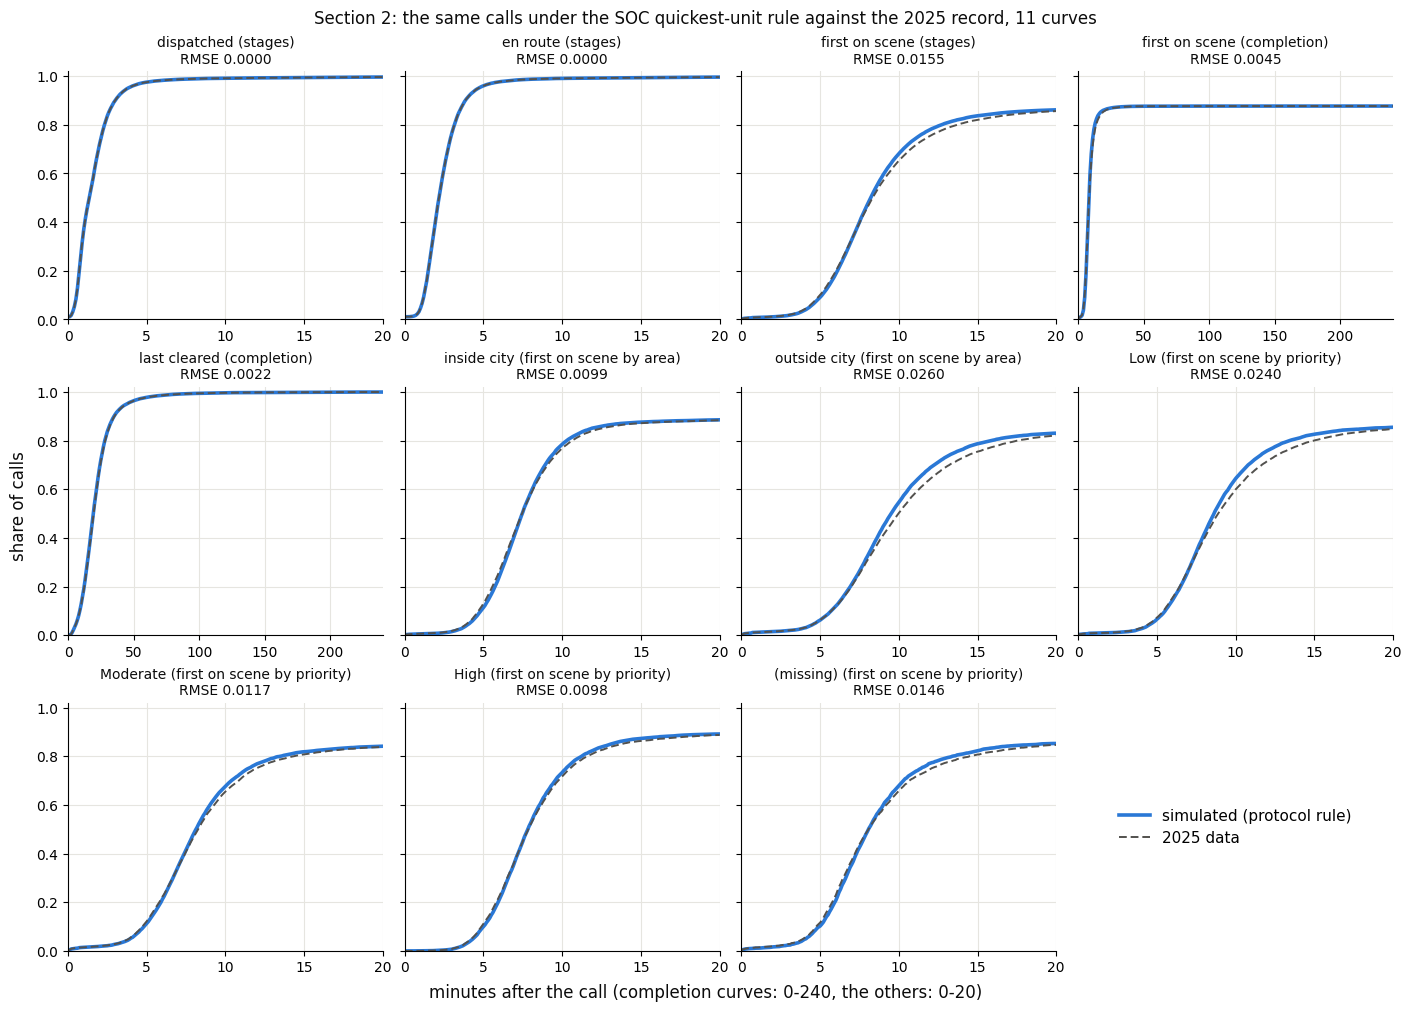

In [41]:
plot_curves(protocol_curves, protocol_check, "simulated (protocol rule)",
            "Section 2: the same calls under the SOC quickest-unit rule against the 2025 record, 11 curves")

# Section 3 — The same rule with travel along the road network

Section 2 ranked engines by straight-line distance from their home station. CAD ranks them by travel time along
roads (SOC 2024, printed p. 70: road direction and speed limits). Here both the ranking and the travel time of a
substituted engine come from the county drive network (OpenStreetMap through osmnx, free-flow speeds), calibrated on
2025 runs. Two calibration forms are fitted the same way, and the one with the smaller out-of-sample error is kept:
- **Linear:** travel = a + b × free-flow network time. This is the form we used for San Francisco.
- **Kolesar, Walker & Hausner (1975):** travel = 2√(D / acceleration) up to a breakpoint, then a straight line in D,
  where D is the shortest road distance. This is the classic fire-engine model.

`simulate`, `define_available_engines` and `dispatch_by_protocol` do not change; only the travel table they receive
changes.

## Step 3.1 — Road network

**Change.** `load_road_network` reads the graph and keeps its largest strongly connected part.
**Check.** Size, free-flow speeds, missing travel times.

In [42]:
import networkx as nx
import osmnx as ox

ROAD_NETWORK_GRAPHML = PROJECT_ROOT / "data" / "raw" / "gnv_alachua" / "alachua_drive.graphml"  # [SOURCE] OSM drive network, free-flow speed_kph and travel_time (osmnx)


def load_road_network(verbose=VERBOSE):
    """The county drive network, cut to its largest strongly connected part so that every node can reach every other.

    Example: load_road_network().number_of_nodes() -> 15048
    """
    full_graph = ox.load_graphml(ROAD_NETWORK_GRAPHML)
    graph = ox.truncate.largest_component(full_graph, strongly=True)
    if verbose:
        edges = ox.convert.graph_to_gdfs(graph, nodes=False)
        print(f"road network: {full_graph.number_of_nodes():,} nodes, {full_graph.number_of_edges():,} edges; largest strongly "
              f"connected part kept: {graph.number_of_nodes():,} nodes, {graph.number_of_edges():,} edges\n"
              f"edge speed_kph (free flow, OSM): median {edges.speed_kph.median():.0f}, P10 {edges.speed_kph.quantile(0.1):.0f}, "
              f"P90 {edges.speed_kph.quantile(0.9):.0f}; edge travel_time missing: {int(edges.travel_time.isna().sum())}\n")
    return graph


graph = load_road_network()

road network: 15,085 nodes, 36,242 edges; largest strongly connected part kept: 15,048 nodes, 36,197 edges
edge speed_kph (free flow, OSM): median 40, P10 40, P90 65; edge travel_time missing: 0



## Step 3.2 — Calls and stations on the network

**Change.** `snap_to_network` finds the nearest network node to each run's call and each engine's home station.
**Check.** How far the points are from the network.

In [43]:
SNAP_WARN_M = 500                                                           # [DESIGN] a call this far from the road network is reported


def snap_to_network(graph, dispatches, engines, verbose=VERBOSE):
    """Nearest network node to each run's call and to each engine's home station, with the snap distance in metres
    (a call without coordinates gets no node).

    Example: snap_to_network(graph, dispatches, engines)[1].loc[0, ["engine_id", "snap_m"]].tolist() -> ['E1', 12.3...]
    """
    located = dispatches["incident_lon"].notna()
    nodes, meters = ox.distance.nearest_nodes(graph, X=dispatches.loc[located, "incident_lon"].to_numpy(),
                                              Y=dispatches.loc[located, "incident_lat"].to_numpy(), return_dist=True)
    call_nodes = pd.DataFrame({"node": pd.Series(nodes, index=dispatches.index[located], dtype="Int64"),
                               "snap_m": pd.Series(meters, index=dispatches.index[located])}).reindex(dispatches.index)
    nodes, meters = ox.distance.nearest_nodes(graph, X=engines["home_lon"].to_numpy(), Y=engines["home_lat"].to_numpy(),
                                              return_dist=True)
    engine_nodes = pd.DataFrame({"engine_id": engines["engine_id"], "node": pd.Series(nodes, dtype="Int64"), "snap_m": meters})
    show_table("calls snapped to the network (rows: runs)", call_nodes, verbose)
    show_table("engine home stations snapped to the network", engine_nodes, verbose)
    if verbose:
        print(f"call snap distance (m): median {call_nodes.snap_m.median():.0f}, P90 {call_nodes.snap_m.quantile(0.9):.0f}, "
              f"P99 {call_nodes.snap_m.quantile(0.99):.0f}; over {SNAP_WARN_M} m: {int((call_nodes.snap_m > SNAP_WARN_M).sum())} runs; "
              f"no coordinates: {int(call_nodes.node.isna().sum())} runs\n"
              f"engine snap distance (m): median {engine_nodes.snap_m.median():.0f}, max {engine_nodes.snap_m.max():.0f}; "
              f"distinct home nodes: {engine_nodes.node.nunique()} for {len(engine_nodes)} engines\n")
    return call_nodes, engine_nodes


call_nodes, engine_nodes = snap_to_network(graph, dispatches, engines)

--- calls snapped to the network (rows: runs) (37194, 2)
        node      snap_m
0  666957816   74.815862
1   84910563   29.307305
2   84882940  113.935883
3   84826992  200.208110
4   84853411   23.342101

--- engine home stations snapped to the network (29, 3)
  engine_id        node     snap_m
0        E1    84918009  35.035384
1        Q1    84855238  36.471538
2        E2   618869091  51.480986
3        Q2   618869091  51.433319
4        E3  5971432219  72.511009

call snap distance (m): median 66, P90 216, P99 705; over 500 m: 778 runs; no coordinates: 4 runs
engine snap distance (m): median 51, max 201; distinct home nodes: 28 for 29 engines



- **Calls:** half are within 66 m of a node; 778 runs (2.1%) are over 500 m away, mostly rural ACFR calls at the end
  of long driveways. This off-network leg is the same for every engine that could go to a call, so it does not
  change the ranking; the calibration absorbs its average.
- **Stations:** within 201 m. The 29 engines sit on 28 nodes (E1 and Q1 land a few metres apart).

## Step 3.3 — Network time and distance from every station to every call

**Change.** `network_from_stations` runs shortest paths from each station node, once by free-flow time and once by
road length (for each pair of nodes, the parallel edge with the smaller weight counts).
**Check.** Unreachable pairs, and road vs straight-line distance.

In [44]:
import scipy.sparse.csgraph

def network_from_stations(graph, dispatches, call_nodes, engine_nodes, verbose=VERBOSE):
    """Free-flow network time (seconds, fastest path) and shortest road distance (km) from every engine's home node to
    every run's call node (rows: runs, columns: engines); missing for a call without coordinates.

    Example: network_from_stations(graph, dispatches, call_nodes, engine_nodes)[0].loc[0, "E62"] -> 287.0 (seconds), roughly
    """
    node_list = list(graph.nodes)
    position = pd.Series(np.arange(len(node_list)), index=node_list)
    sources = engine_nodes["node"].astype("int64").unique()
    from_sources = {}
    for weight in ["travel_time", "length"]:                     # parallel edges keep their smallest weight
        matrix = nx.to_scipy_sparse_array(ox.convert.to_digraph(graph, weight=weight), nodelist=node_list, weight=weight)
        from_sources[weight] = scipy.sparse.csgraph.dijkstra(matrix, directed=True, indices=position[sources].to_numpy())
    engine_rows = pd.Series(np.arange(len(sources)), index=sources)[engine_nodes["node"].astype("int64")].to_numpy()
    located = call_nodes["node"].notna().to_numpy()
    call_columns = position[call_nodes.loc[located, "node"].astype("int64")].to_numpy()
    tables = []
    for weight, scale in [("travel_time", 1.0), ("length", 1 / 1000)]:
        values = np.full((len(dispatches), len(engine_nodes)), np.nan)
        values[located] = from_sources[weight][engine_rows][:, call_columns].T * scale
        tables.append(pd.DataFrame(values, index=dispatches.index, columns=engine_nodes["engine_id"]))
    network_seconds, network_km = tables
    show_table("network free-flow seconds, home station -> call (rows: runs)", network_seconds.round(0), verbose)
    if verbose:
        own = network_km.columns.get_indexer(dispatches["engine_id"])
        own_km = network_km.to_numpy()[np.arange(len(dispatches)), own]
        line_km = straight_line_km(dispatches["engine_lon_at_dispatch"].to_numpy(), dispatches["engine_lat_at_dispatch"].to_numpy(),
                                   dispatches["incident_lon"].to_numpy(), dispatches["incident_lat"].to_numpy())
        at_home = dispatches["at_home"].astype(bool).to_numpy() & (line_km > 1)
        print(f"unreachable pairs: {int(np.isinf(network_seconds.to_numpy()).sum())}; "
              f"road km / straight-line km for the 2025 engine leaving home, trips over 1 km: "
              f"median {np.nanmedian(own_km[at_home] / line_km[at_home]):.2f}\n")
    return network_seconds, network_km


network_seconds, network_km = network_from_stations(graph, dispatches, call_nodes, engine_nodes)

--- network free-flow seconds, home station -> call (rows: runs) (37194, 29)
engine_id      E1      Q1      E2      Q2      E3      E4      E5      E7      Q8      E9      Q9     E21     E22     Q23     E24     E25     E28     Q28     E29     E40     E42     E60     E61     E62     E63     E64     E80     E81     E82
0          1098.0  1094.0  1349.0  1349.0  1029.0  1451.0  1363.0  1736.0  1603.0  1560.0  1554.0  2196.0  2202.0  1823.0  2100.0  1959.0  2535.0  2532.0  2670.0   827.0   605.0   805.0   811.0   108.0   957.0  1070.0  1901.0  1808.0  2206.0
1          1136.0  1131.0  1387.0  1387.0  1066.0  1488.0  1400.0  1773.0  1640.0  1598.0  1592.0  2234.0  2239.0  1860.0  2137.0  1996.0  2572.0  2569.0  2707.0   921.0   699.0   842.0   848.0   141.0   990.0  1107.0  1939.0  1845.0  2243.0
2          1581.0  1586.0  1333.0  1333.0  1645.0  1210.0  1323.0  1165.0  1229.0  1241.0  1235.0   471.0   977.0  1102.0  1130.0   711.0   850.0   856.0    59.0  2147.0  2559.0  1911.0  2483.0  27

No pair is unreachable. Trips over 1 km that left from home are 1.28 times as long on the road as in a straight
line (median), a usual detour factor.

## Step 3.4 — Two calibration forms, fitted and tested the same way

**Change.**
- `compare_travel_models` fits both forms on runs that left from home between 2024-10 and 2025-06. Each fit
  minimises the mean absolute error.
- It then tests both forms on the runs of 2025-07 to 2025-09, next to the Section 2 straight-line curve.

**Check.** Out-of-sample error, overall and by road distance. The form with the smaller mean |error| is kept.

In [45]:
import scipy.optimize

TRAVEL_TEST_FROM = pd.Timestamp("2025-07-01")                               # [DESIGN] travel models fit on Oct-Jun runs, tested on Jul-Sep


def linear_travel_model(parameters, network_seconds, network_km):
    """Travel seconds = a + b x free-flow network seconds (the form of our San Francisco calibration).

    Example: linear_travel_model([60.0, 1.2], np.array([300.0]), None) -> array([420.])
    """
    intercept, slope = parameters
    return intercept + slope * network_seconds


def kolesar_travel_model(parameters, network_seconds, network_km):
    """Kolesar, Walker & Hausner (1975): an engine accelerates, then cruises. Travel seconds = 2 sqrt(D / acceleration)
    up to D = speed^2 / acceleration, then speed / acceleration + D / speed, with D the shortest road distance in km.
    The parameters are log(acceleration, km/s^2) and log(speed, km/s), so both stay positive.

    Example: kolesar_travel_model(np.log([0.0001, 0.015]), None, np.array([1.0])) -> array([200.])
    """
    acceleration, speed = np.exp(parameters)
    breakpoint_km = speed ** 2 / acceleration
    return np.where(network_km <= breakpoint_km, 2 * np.sqrt(network_km / acceleration),
                    speed / acceleration + network_km / speed)


def compare_travel_models(dispatches, engines, network_seconds, network_km, travel_curve, verbose=VERBOSE):
    """Fit both forms by least mean |error| on runs that left from home before TRAVEL_TEST_FROM, test them and the
    step-2 straight-line curve on the later runs, and keep the network form with the smaller test mean |error|.

    Example: compare_travel_models(dispatches, engines, network_seconds, network_km, travel_curve)[0]
             -> 'linear on network time'  # chosen form; [1] is a function (seconds, km) -> travel seconds
    """
    rows = np.arange(len(dispatches))
    own_engine = network_seconds.columns.get_indexer(dispatches["engine_id"])
    seconds, km = network_seconds.to_numpy()[rows, own_engine], network_km.to_numpy()[rows, own_engine]
    homes = engines.set_index("engine_id").loc[dispatches["engine_id"], ["home_lon", "home_lat"]].to_numpy()
    line_km = straight_line_km(homes[:, 0], homes[:, 1], dispatches["incident_lon"].to_numpy(), dispatches["incident_lat"].to_numpy())
    observed = dispatches["travel_s"].to_numpy(dtype=float, na_value=np.nan)
    usable = (dispatches["at_home"].astype(bool).to_numpy() & (observed > 0) & np.isfinite(seconds)
              & ~dispatches["qc_note"].str.contains("implausible|equals_incident").to_numpy())
    train = usable & (dispatches["dispatched_at"] < TRAVEL_TEST_FROM).to_numpy()
    test = usable & ~train
    forms = {"linear on network time": (linear_travel_model, [60.0, 1.0]),
             "Kolesar 1975 on road distance": (kolesar_travel_model, np.log([1e-4, 0.015]))}
    fitted = {}
    for name, (model, start) in forms.items():
        result = scipy.optimize.minimize(lambda parameters: np.mean(np.abs(model(parameters, seconds[train], km[train]) - observed[train])),
                                         start, method="Nelder-Mead", options={"maxiter": 10_000, "xatol": 1e-8, "fatol": 1e-8})
        fitted[name] = (model, result.x)
    predictions = {name: model(parameters, seconds[test], km[test]) for name, (model, parameters) in fitted.items()}
    predictions["step 2: straight-line curve"] = travel_curve(line_km[test])
    errors_min = {name: (predicted - observed[test]) / 60 for name, predicted in predictions.items()}
    comparison = pd.DataFrame({name: {"test runs": len(error), "mean |error| min": np.mean(np.abs(error)),
                                      "median |error| min": np.median(np.abs(error)), "bias min": np.mean(error)}
                               for name, error in errors_min.items()}).T
    chosen = min(fitted, key=lambda name: comparison.loc[name, "mean |error| min"])
    model, parameters = fitted[chosen]
    if verbose:
        bands = pd.cut(km[test], DISTANCE_BANDS_KM)
        by_band = pd.DataFrame({name: pd.Series(np.abs(error)).groupby(bands, observed=True).median()
                                for name, error in errors_min.items()})
        by_band["runs"] = pd.Series(bands).value_counts().reindex(by_band.index)
        print(f"fit on {train.sum():,} runs before {TRAVEL_TEST_FROM.date()} that left from home, tested on {test.sum():,} later runs\n"
              f"parameters: linear a = {fitted['linear on network time'][1][0]:.1f} s, b = {fitted['linear on network time'][1][1]:.3f}; "
              f"Kolesar acceleration = {np.exp(fitted['Kolesar 1975 on road distance'][1][0]) * 1e6:.1f} mm/s^2, "
              f"speed = {np.exp(fitted['Kolesar 1975 on road distance'][1][1]) * 3600:.1f} km/h\n"
              f"{comparison.round(3).to_string()}\n"
              f"median |error| (min) by road distance (km):\n{by_band.round(2).to_string()}\n"
              f"chosen: {chosen}\n")
    return chosen, lambda network_seconds, network_km: model(parameters, network_seconds, network_km), comparison


chosen_form, network_travel_model, travel_comparison = compare_travel_models(
    dispatches, engines, network_seconds, network_km, travel_curve)

fit on 19,349 runs before 2025-07-01 that left from home, tested on 6,410 later runs
parameters: linear a = 148.4 s, b = 1.002; Kolesar acceleration = 100.7 mm/s^2, speed = 80.4 km/h
                               test runs  mean |error| min  median |error| min  bias min
linear on network time            6410.0             1.547               0.926    -0.569
Kolesar 1975 on road distance     6410.0             1.566               0.940    -0.635
step 2: straight-line curve       6410.0             1.636               1.014    -0.618
median |error| (min) by road distance (km):
          linear on network time  Kolesar 1975 on road distance  step 2: straight-line curve  runs
(0, 1]                      0.75                           0.75                         0.74   853
(1, 2]                      0.85                           0.83                         0.93  1376
(2, 4]                      0.87                           0.92                         0.97  2433
(4, 8]               

- **Kept: the linear form.** Test mean |error| is 1.55 min, against 1.57 for Kolesar and 1.64 for the straight line.
- **Linear parameters:** a = 148 s and b = 1.00. The free-flow network time is about right, and every trip adds a
  fixed 2.5 minutes (moving off, finding the address).
- **Kolesar parameters:** the model has no intercept, so it can only absorb that fixed part through a very low
  acceleration (0.1 m/s²).
- **Bias:** all three forms are about 0.6 min low on average. Fitting to absolute error targets the median, while
  travel times are right-skewed.
- **By distance:** the network helps most at 4–16 km.

## Step 3.5 — The rule with network travel

**Change.** `estimate_network_travel_seconds` builds the table of estimated travel, run × engine, from the chosen
form and drops engines outside their service span. The rule is then run with this table.
**Check.** How often the 2025 engine is the quickest by this estimate, and how often the rule now picks it.

In [46]:
def estimate_network_travel_seconds(dispatches, engines, network_seconds, network_km, travel_model, verbose=VERBOSE):
    """Estimated travel seconds from every engine's home station to every run's call along the road network (the chosen
    travel model); missing when the engine is outside its service span at the dispatch time or the call has no location.

    Example: estimate_network_travel_seconds(dispatches, engines, network_seconds, network_km, travel_model).shape -> (37194, 29)
    """
    estimates = pd.DataFrame(travel_model(network_seconds.to_numpy(), network_km.to_numpy()),
                             index=dispatches.index, columns=network_seconds.columns)
    for engine in engines.itertuples():
        out_of_service = ~dispatches["dispatched_at"].between(engine.in_service_from, engine.in_service_to)
        estimates.loc[out_of_service, engine.engine_id] = np.nan
    show_table("estimated travel seconds along the road network, home station -> call (rows: runs)", estimates.round(0), verbose)
    if verbose:
        rank = estimates.rank(axis=1, method="min")                          # 1 = shortest; same-node engines tie
        rank_of_2025_engine = rank.to_numpy()[np.arange(len(rank)), rank.columns.get_indexer(dispatches["engine_id"])]
        print("rank of the engine that went in 2025 among in-service engines (by estimated network travel from home):",
              pd.Series(rank_of_2025_engine).clip(upper=4).map({1: "1st", 2: "2nd", 3: "3rd", 4: "4th or later"})
              .fillna("no estimate").value_counts(normalize=True).round(3).to_dict(), "\n")
    return estimates


network_travel = estimate_network_travel_seconds(dispatches, engines, network_seconds, network_km, network_travel_model)
network_protocol = simulate(runs, available=define_available_engines, choose=dispatch_by_protocol, engines=engines,
                            estimated_travel=network_travel)
network_engine_check = compare_engines(runs, network_protocol, dispatches)
network_table = simulated_dispatch_table(dispatches, network_protocol, engines, verbose=False)
network_curves = response_curves(network_table, verbose=False)
network_check = compare_curves(network_curves, curves_2025)

--- estimated travel seconds along the road network, home station -> call (rows: runs) (37194, 29)
engine_id      E1  Q1      E2  Q2      E3      E4      E5      E7      Q8      E9      Q9     E21     E22     Q23     E24     E25     E28     Q28     E29     E40     E42     E60     E61     E62     E63     E64     E80     E81     E82
0          1250.0 NaN  1501.0 NaN  1180.0  1603.0  1515.0  1889.0  1756.0  1713.0  1707.0  2350.0  2356.0  1975.0  2253.0  2112.0  2689.0  2687.0  2825.0   977.0   755.0   956.0   962.0   257.0  1108.0  1221.0  2054.0  1961.0  2359.0
1          1287.0 NaN  1538.0 NaN  1217.0  1640.0  1552.0  1926.0  1793.0  1750.0  1744.0  2388.0  2393.0  2013.0  2290.0  2149.0  2727.0  2724.0  2862.0  1072.0   849.0   993.0   999.0   290.0  1140.0  1258.0  2092.0  1998.0  2397.0
2          1734.0 NaN  1484.0 NaN  1798.0  1362.0  1474.0  1317.0  1380.0  1392.0  1386.0   621.0  1128.0  1253.0  1281.0   861.0  1001.0  1007.0   208.0  2301.0  2714.0  2065.0  2637.0  2856.0  2987

--- simulated CAD times (seconds since day zero) and engine used (37194, 5)
   dispatched_at  enroute_at    arrived_at    cleared_at engine_id
0         6796.0      6858.0   7255.000000   7404.000000       E62
1        23905.0     23956.0  24342.000000  25096.000000       E62
2        28215.0     28215.0  28388.000000  30243.000000       E29
3        29358.0     29358.0  29358.000000  31952.000000       E60
4        36851.0     36891.0  37311.489828  38056.489828        E3

--- engines: simulation vs 2025
                            runs  same_engine_share
all runs                   37194              0.743
first engine of each call  33156              0.785
inside city                21015              0.766
outside city               16175              0.714
runs with another engine and an arrival: 6,400; travel change (min): median -0.35, P10 -5.79, P90 3.25
runs whose engine was still on an earlier run: 0

--- simulated vs 2025 curves (11, 8)
                         curve         

- **The 2025 engine is the quickest by estimate:** in 65.8% of runs, up from 62.0% with straight lines.
- **The rule now picks the 2025 engine:** in 74.3% of runs, up from 69.8%.

## Step 3.6 — Evaluation matrix

**Change.**
- `control_table` turns the Section 2.8 control into a function.
- `evaluation_column` scores one version of the rule on fixed rows.
- `evaluation_matrix` puts the versions side by side.

The 2025 record column is the Section 1 replay.

In [47]:
def control_table(runs, simulated, dispatches, engines, estimated_travel):
    """Control for a run of a rule: every run keeps its 2025 engine, but where the rule sent another engine the 2025
    engine also gets its estimated travel, so that rule minus control isolates the choice of engine.

    Example: control_table(runs, protocol, dispatches, engines, estimated_travel).shape -> (37194, 32)
    """
    other_engine = (simulated["engine_id"] != runs["engine_id"]).to_numpy()
    control_times = runs[TIME_COLUMNS].copy()
    for row in runs.index[other_engine]:
        control_times.loc[row] = shift_arrival(runs.loc[row, TIME_COLUMNS], estimated_travel.at[row, runs.at[row, "engine_id"]])
    return simulated_dispatch_table(dispatches, control_times.assign(engine_id=runs["engine_id"]), engines, verbose=False)


def evaluation_column(runs, simulated, dispatches, table, control, check, travel_test_error_min):
    """One version of the dispatch rule scored on the fixed rows of the evaluation matrix: travel estimate error,
    same-engine shares, curve RMSE, and first-on-scene minutes (with rule minus control at P90).

    Example: evaluation_column(runs, protocol, dispatches, protocol_table, control, protocol_check, 1.64)
             ["same engine: all runs"] -> 0.698
    """
    same_engine = simulated["engine_id"] == runs["engine_id"]
    first_engine = runs.sort_values("dispatched_at").groupby("incident_id").head(1).index
    at_home = dispatches["at_home"].astype(bool)
    multi_engine = dispatches["n_engines_sent"] > 1
    other_agency = (dispatches["engine_agency"] == "GFR") != (dispatches["jurisdiction"] == "GFR")
    timing = compare_first_on_scene({"rule": table, "control": control}, verbose=False)
    rmse = check.set_index(["curve", "series"])["rmse"]
    return pd.Series({
        "travel estimate: test mean |error| (min)": travel_test_error_min,
        "same engine: all runs": same_engine.mean(),
        "same engine: first engine of each call": same_engine[first_engine].mean(),
        "same engine: single-engine calls": same_engine[~multi_engine].mean(),
        "same engine: multi-engine calls": same_engine[multi_engine].mean(),
        "same engine: 2025 engine at home": same_engine[at_home].mean(),
        "same engine: 2025 engine away from home": same_engine[~at_home].mean(),
        "same engine: 2025 engine from the other agency": same_engine[other_agency].mean(),
        "curve RMSE: first on scene, all calls": rmse[("stages", "first_on_scene")],
        "curve RMSE: first on scene, inside city": rmse[("first_on_scene_by_area", "inside city")],
        "curve RMSE: first on scene, outside city": rmse[("first_on_scene_by_area", "outside city")],
        "curve RMSE: largest of the 11 curves": rmse.max(),
        "first on scene: median (min)": timing.loc["all calls median", "rule"],
        "first on scene: P90 (min)": timing.loc["all calls P90", "rule"],
        "first on scene: P90 rule minus control (min)": timing.loc["all calls P90", "rule"] - timing.loc["all calls P90", "control"],
    })


def evaluation_matrix(columns, verbose=VERBOSE):
    """The evaluation matrix: one column per version of the rule, the same rows for every version.

    Example: evaluation_matrix({"2025 record": column_2025, "step 2: straight line": column_2}).shape -> (15, 2)
    """
    matrix = pd.DataFrame(columns)
    if verbose:
        print(f"--- evaluation matrix\n{matrix.round(3).to_string()}\n")
    return matrix


replay = simulate(runs, verbose=False)
columns = {
    "2025 record": evaluation_column(runs, replay, dispatches, dispatches, dispatches, check, np.nan),
    "step 2: straight line": evaluation_column(
        runs, protocol, dispatches, protocol_table, control_table(runs, protocol, dispatches, engines, estimated_travel),
        protocol_check, travel_comparison.loc["step 2: straight-line curve", "mean |error| min"]),
    "step 3: road network": evaluation_column(
        runs, network_protocol, dispatches, network_table,
        control_table(runs, network_protocol, dispatches, engines, network_travel),
        network_check, travel_comparison.loc[chosen_form, "mean |error| min"]),
}
evaluation = evaluation_matrix(columns)

--- evaluation matrix
                                                2025 record  step 2: straight line  step 3: road network
travel estimate: test mean |error| (min)                NaN                  1.636                 1.547
same engine: all runs                                 1.000                  0.698                 0.743
same engine: first engine of each call                1.000                  0.735                 0.785
same engine: single-engine calls                      1.000                  0.764                 0.816
same engine: multi-engine calls                       1.000                  0.411                 0.427
same engine: 2025 engine at home                      1.000                  0.729                 0.780
same engine: 2025 engine away from home               1.000                  0.531                 0.545
same engine: 2025 engine from the other agency        1.000                  0.510                 0.564
curve RMSE: first on scene, all c

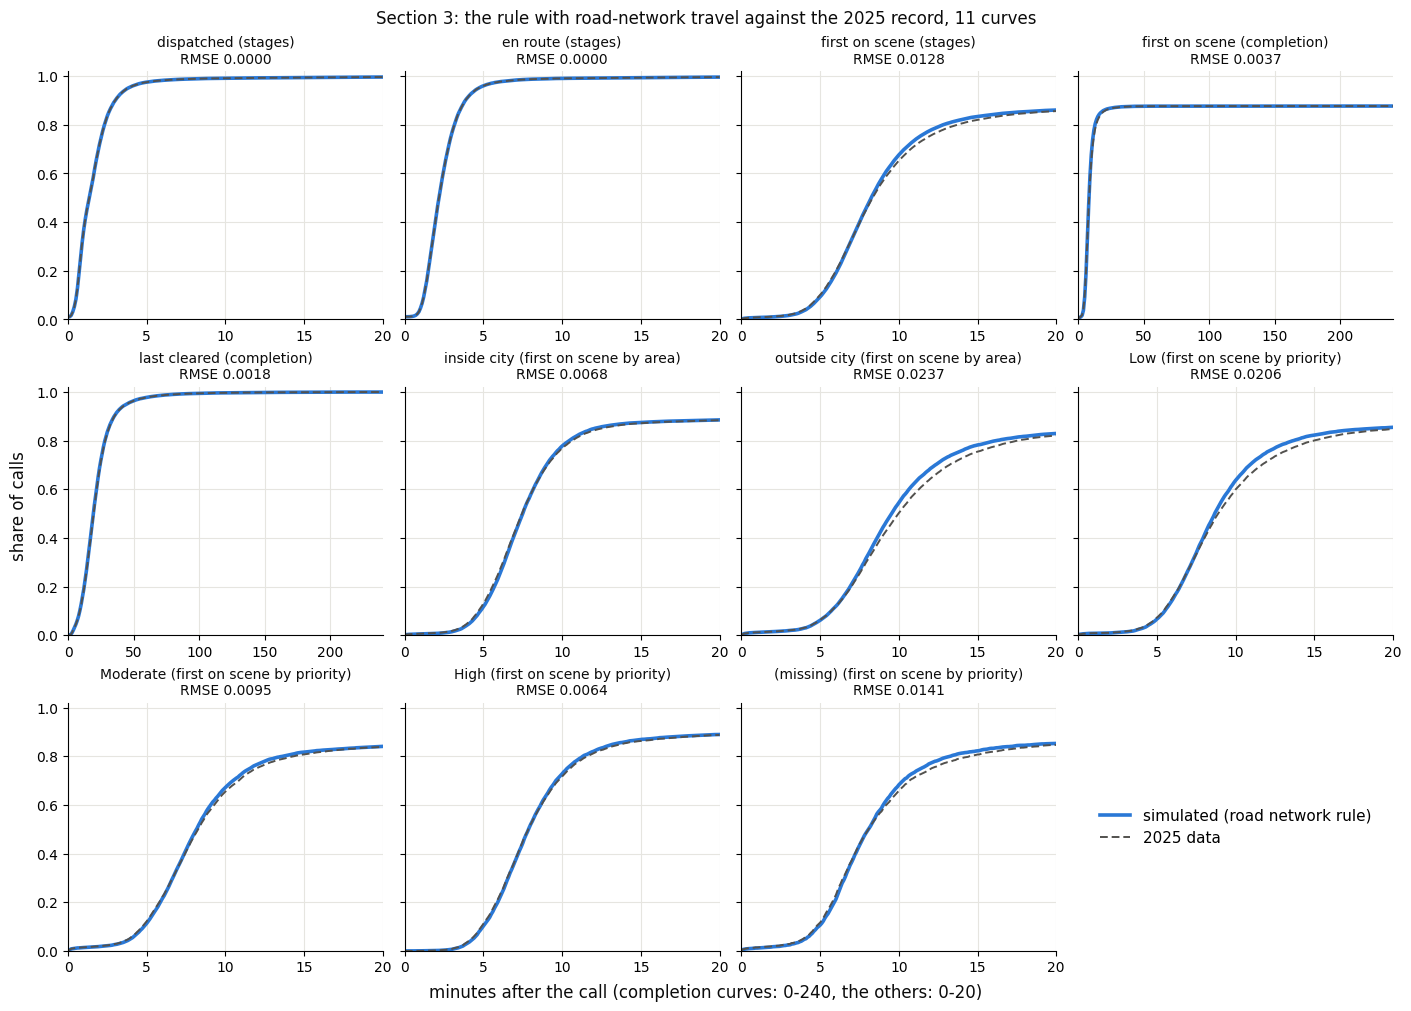

In [48]:
plot_curves(network_curves, network_check, "simulated (road network rule)",
            "Section 3: the rule with road-network travel against the 2025 record, 11 curves")

The road network helps where expected: single-engine calls whose 2025 engine left from home (same engine 73% → 78%),
and the first engine of each call (73.5% → 78.5%). Multi-engine calls (unit types) and engines away from home
(positions) hardly move. Rule minus control at P90 stays about −0.95 min: the rule still looks faster mostly because
it is judged by the estimate it minimises.

# Section 4 — The GFR / ACFR line

SOC 2024 (printed p. 30–31): since 2019-10-01, automatic aid between GFR and ACFR covers "a limited set of emergent
calls for service inside an updated boundary". The list of call types is not published, and the boundary has no
public map layer.

Here the line is drawn by call type only:
- A call keeps its own agency's engines (GFR versus everyone else).
- An engine from the other agency may go only if the call type is on the automatic-aid list.
- The list is learnt from FY2024 aid records, so FY2025 tests it.

## Step 4.1 — Which calls get an engine from the other agency?

In [49]:
other_agency_run = (dispatches["engine_agency"] == "GFR") != (dispatches["jurisdiction"] == "GFR")
by_type = dispatches.assign(other_agency=other_agency_run).groupby("protocol").agg(
    runs=("other_agency", "size"), other_agency_runs=("other_agency", "sum"), other_agency_share=("other_agency", "mean"))
print(f"FY2025 engine runs from the other agency: {other_agency_run.sum():,} ({other_agency_run.mean():.1%}); "
      f"flagged automatic aid: {dispatches.loc[other_agency_run, 'auto_aid'].mean():.1%}")
print(by_type.sort_values("other_agency_runs", ascending=False).head(12).round(3).to_string())
print(dispatches.assign(other_agency=other_agency_run).groupby(["jurisdiction", "priority"], dropna=False)["other_agency"]
      .agg(["size", "mean"]).round(3).to_string())

FY2025 engine runs from the other agency: 1,499 (4.0%); flagged automatic aid: 79.5%
          runs  other_agency_runs  other_agency_share
protocol                                             
E06       3025                301                 0.1
F69       1744                253               0.145
E10       2402                245               0.102
E31       2367                234               0.099
F77       3065                121               0.039
E17       3392                 88               0.026
E28        725                 77               0.106
E09        488                 42               0.086
F71        410                 26               0.063
F60        353                 12               0.034
E12       1280                 11               0.009
E23       1037                 11               0.011
                       size   mean
jurisdiction priority             
ACFR         High      4113  0.138
             Low       6007  0.011
             Modera

- **Size:** 1,499 runs (4.0%) used an engine from the other agency, and 79.5% of them are flagged automatic aid.
- **Call types:** almost all are emergent: breathing problems, structure fires, chest pain, unconscious, crashes,
  strokes, cardiac arrests.
- **Priority:** low-priority calls almost never get one (1.1% in the ACFR area, 0.4% in the GFR area).

## Step 4.2 — The rule

**Change.**
- `load_aid_protocols`: the call types with at least one engine sent by automatic aid in FY2024.
- `apply_agency_boundaries`: removes, for every run, the other agency's engines unless the call type is on that
  list. The rule itself does not change.

In [50]:
AUTOMATIC_AID_FY2024 = PROJECT_ROOT / "data" / "raw" / "gnv_alachua" / "acfr_gfr_automatic_aid_fy2024.parquet"  # [SOURCE] GFR-ACFR automatic aid dispatches, FY2024


def load_aid_protocols(dispatches, verbose=VERBOSE):
    """Call types (protocol codes) that may get an engine from the other agency: those with at least one engine sent
    by automatic aid in FY2024 (SOC 2024, printed p. 31: aid covers "a limited set of emergent calls"; the list itself
    is not published). Learnt from FY2024 so that FY2025 can test it.

    Example: sorted(load_aid_protocols(dispatches))[:3] -> ['E02', 'E06', 'E09']
    """
    aid = pd.read_parquet(AUTOMATIC_AID_FY2024)
    engine_aid = aid[aid["Radio_Name"].str.match(r"^(E|Q)\d+$")]
    aid_protocols = set(engine_aid["Problem"].str.extract(r"^([EF]\d{2})", expand=False).dropna())
    show_table("FY2024 automatic aid dispatches (input)", aid, verbose)
    if verbose:
        cross = (dispatches["engine_agency"] == "GFR") != (dispatches["jurisdiction"] == "GFR")
        print(f"engine aid dispatches in FY2024: {len(engine_aid):,}; call types with any: {len(aid_protocols)} -> {sorted(aid_protocols)}\n"
              f"FY2025 runs from the other agency whose call type is in the list: {dispatches.loc[cross, 'protocol'].isin(aid_protocols).mean():.1%} "
              f"of {cross.sum():,}; FY2025 runs whose call type is in the list: {dispatches['protocol'].isin(aid_protocols).mean():.1%}\n")
    return aid_protocols


def apply_agency_boundaries(estimated_travel, dispatches, engines, aid_protocols, verbose=VERBOSE):
    """Estimated travel with the agency line drawn in: an engine of the other agency (GFR vs everyone else) is removed
    (missing) for a call unless the call type gets automatic aid. Calls keep their own agency's engines.

    Example: apply_agency_boundaries(estimated_travel, dispatches, engines, aid_protocols).loc[0].isna().sum() -> 13
    """
    engine_is_gfr = (engines.set_index("engine_id").loc[estimated_travel.columns, "engine_agency"] == "GFR").to_numpy()
    call_in_gfr = (dispatches["jurisdiction"] == "GFR").to_numpy()
    aid_call = dispatches["protocol"].isin(aid_protocols).to_numpy()
    other_agency = engine_is_gfr[None, :] != call_in_gfr[:, None]
    bounded = estimated_travel.mask(other_agency & ~aid_call[:, None])
    show_table("estimated travel with agency boundaries (rows: runs)", bounded.round(0), verbose)
    if verbose:
        own = bounded.columns.get_indexer(dispatches["engine_id"])
        engine_removed = bounded.isna().to_numpy()[np.arange(len(bounded)), own] & estimated_travel.notna().to_numpy()[np.arange(len(bounded)), own]
        print(f"run x engine pairs removed by the boundary: {(bounded.isna() & estimated_travel.notna()).to_numpy().mean():.1%}; "
              f"runs whose 2025 engine is now outside the rule: {int(engine_removed.sum())} ({engine_removed.mean():.2%})\n")
    return bounded


aid_protocols = load_aid_protocols(dispatches)
boundary_travel = apply_agency_boundaries(network_travel, dispatches, engines, aid_protocols)

--- FY2024 automatic aid dispatches (input) (1819, 13)
   OBJECTID_1 Radio_Name                      Problem Determinant Master_Incident_Number                       Location_Name  Latitude  Longitude Response_Date Resp_Area  Juri    GIS_LAT   GIS_LONG
0           1         E9  E31D - UNCONSCIOUS/FAINTING       31D04            050124-0006                          City Place  29621412   82394800    2024-05-01     FS23W  ACFR  29.621412 -82.394800
1           2         E9    E06D - BREATHING PROBLEMS      06D02A            050124-0040                                 NaN  29644078   82406505    2024-05-01     FS23W  ACFR  29.644078 -82.406505
2           3        SQ3    E06E - BREATHING PROBLEMS      06E01A            050124-0261                                 NaN  29635316   82279770    2024-05-01    ACNH52  ACFR  29.635316 -82.279770
3           4         E7    E10C - CHEST PAIN CHARLIE       10C01            050124-0363  UF Health at Springhill Building 2  29691923   82434146    2024

- **The list:** 15 call types. They cover 94.0% of FY2025's other-agency runs, so the FY2024 list holds in 2025.
- **Calls on the list:** about half of all runs; the other half may use only their own agency's engines.
- **Effect on the table:** 24.5% of run × engine pairs are removed. 90 of the 2025 runs (0.24%) used an engine
  this rule now excludes.

## Step 4.3 — The rule with the agency line, and the evaluation matrix

In [51]:
boundary_protocol = simulate(runs, available=define_available_engines, choose=dispatch_by_protocol, engines=engines,
                             estimated_travel=boundary_travel)
boundary_engine_check = compare_engines(runs, boundary_protocol, dispatches)
boundary_table = simulated_dispatch_table(dispatches, boundary_protocol, engines, verbose=False)
boundary_curves = response_curves(boundary_table, verbose=False)
boundary_check = compare_curves(boundary_curves, curves_2025)
columns["step 4: + agency boundaries"] = evaluation_column(
    runs, boundary_protocol, dispatches, boundary_table,
    control_table(runs, boundary_protocol, dispatches, engines, network_travel),   # travel itself is unchanged
    boundary_check, travel_comparison.loc[chosen_form, "mean |error| min"])
evaluation = evaluation_matrix(columns)

--- simulated CAD times (seconds since day zero) and engine used (37194, 5)
   dispatched_at  enroute_at    arrived_at    cleared_at engine_id
0         6796.0      6858.0   7255.000000   7404.000000       E62
1        23905.0     23956.0  24342.000000  25096.000000       E62
2        28215.0     28215.0  28388.000000  30243.000000       E29
3        29358.0     29358.0  29358.000000  31952.000000       E60
4        36851.0     36891.0  37311.489828  38056.489828        E3

--- engines: simulation vs 2025
                            runs  same_engine_share
all runs                   37194              0.775
first engine of each call  33156              0.817
inside city                21015              0.780
outside city               16175              0.769
runs with another engine and an arrival: 5,684; travel change (min): median -0.05, P10 -4.94, P90 3.73
runs whose engine was still on an earlier run: 0

--- simulated vs 2025 curves (11, 8)
                         curve         

--- evaluation matrix
                                                2025 record  step 2: straight line  step 3: road network  step 4: + agency boundaries
travel estimate: test mean |error| (min)                NaN                  1.636                 1.547                        1.547
same engine: all runs                                 1.000                  0.698                 0.743                        0.775
same engine: first engine of each call                1.000                  0.735                 0.785                        0.817
same engine: single-engine calls                      1.000                  0.764                 0.816                        0.848
same engine: multi-engine calls                       1.000                  0.411                 0.427                        0.460
same engine: 2025 engine at home                      1.000                  0.729                 0.780                        0.813
same engine: 2025 engine away from home 

In [52]:
other_agency_shares = {}
for name, version_table in [("2025 record", dispatches), ("step 2: straight line", protocol_table),
                            ("step 3: road network", network_table), ("step 4: + agency boundaries", boundary_table)]:
    other = (version_table["engine_agency"] == "GFR") != (version_table["jurisdiction"] == "GFR")
    other_agency_shares[name] = {"runs with an engine from the other agency": other.mean(),
                                 "  in the GFR area": other[version_table["jurisdiction"] == "GFR"].mean(),
                                 "  in the ACFR area": other[version_table["jurisdiction"] == "ACFR"].mean()}
pd.DataFrame(other_agency_shares).round(3)

,2025 record,step 2: straight line,step 3: road network,step 4: + agency boundaries
runs with an engine from the other agency,0.040,0.098,0.097,0.050
in the GFR area,0.019,0.037,0.032,0.017
in the ACFR area,0.068,0.177,0.182,0.093


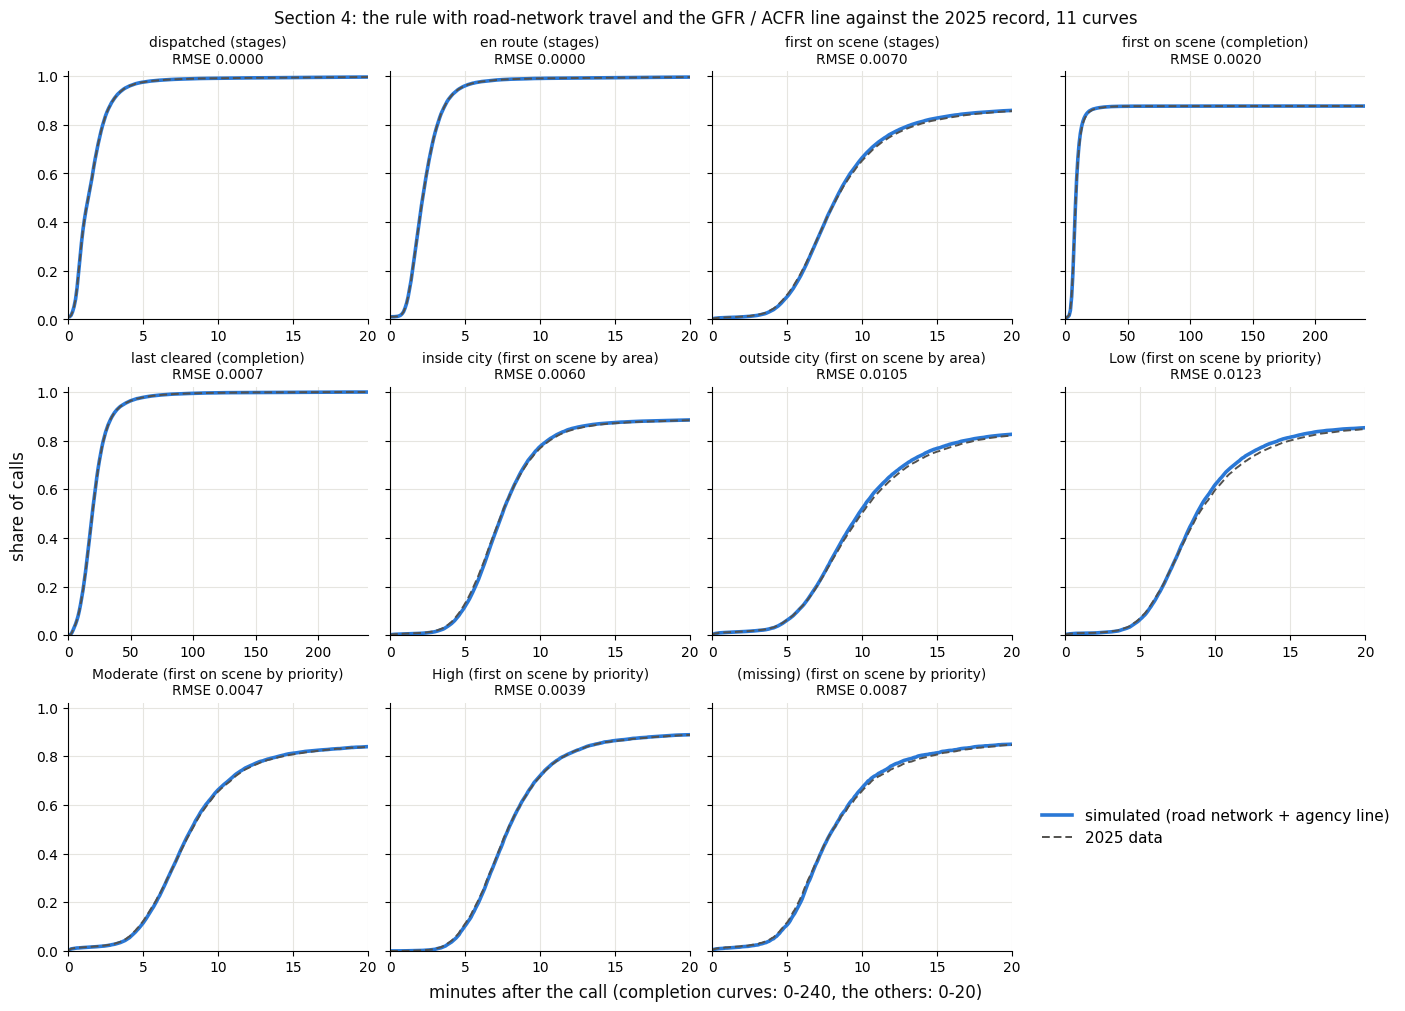

In [53]:
plot_curves(boundary_curves, boundary_check, "simulated (road network + agency line)",
            "Section 4: the rule with road-network travel and the GFR / ACFR line against the 2025 record, 11 curves")

The agency line helps more than the road network did:
- **Same engine:** 74.3% → 77.5% of runs, and 81.7% of first engines.
- **First-on-scene curve RMSE:** 0.013 → 0.007. Outside the city it halves, 0.024 → 0.011.
- **First-on-scene P90:** moves back toward the record (12.43 → 12.83 min, record 13.22).
- **Rule minus control at P90:** shrinks from −0.95 to −0.62 min.

The reason is in the last table:
- **Without the line, the rule over-uses the other agency.** It sends an engine from the other agency in 9.7% of
  runs, against 4.0% in 2025. In the ACFR area the rule's figure is 18%, against 6.8%.
- **With the line, it is close to the record:** 5.0%.

(An earlier guess in this conversation, that the line would matter little because only 4% of 2025 runs crossed it,
was wrong: what matters is how often the rule would cross it.)

# Section 5 — Where idle engines are

Sections 2–4 keep every idle engine at its home station: an engine that clears a call is home that same second, with
no drive back. CAD instead ranks units by where they are (SOC 2024, printed p. 70), using AVL.

**AVL (automatic vehicle location).** Each apparatus carries a GPS unit that keeps reporting its position to CAD. The
FY2025 data keep one snapshot of it: where the dispatched engine was when CAD assigned it (`Latitude_At_Assign_Time`,
`Longitude_At_Assign_Time` → `engine_lon_at_dispatch`, `engine_lat_at_dispatch`). There are no tracks between
dispatches, and no positions for the engines CAD did not send.

Where an engine can be when CAD sends it (the cases discussed):
1. At its home station.
2. Standing by at or near the last call's scene.
3. On the way back from the last call. Cases 2 and 3 are one case in the model: on the way home, with some share of
   the drive done.
4. At another station (cover, move-up, training).
5. Elsewhere (fuel, hospital, errands, inspections).
6. Still on another call, and sent from it.

## Step 5.0a — Where engines were when CAD sent them in 2025

Each run gets one case from its AVL position. The tests run in this order, and a later one overrides an earlier one:
- elsewhere;
- within 150 m of another station;
- sent before the calibrated drive home from its last call was over;
- within 300 m of the last call's scene;
- at home (the dataset's 150 m station radius);
- sent before its last run cleared.

In [54]:
AT_STATION_M = 150     # [SOURCE] station radius of the dataset build (AT_STATION_RADIUS_M)
NEAR_SCENE_M = 300     # [DESIGN] scene radius for this check

stations = pd.read_csv(PROJECT_ROOT / "data" / "derived" / "engine_dispatches_fy2025" / "stations.csv")
show_table("stations", stations)
every_run = np.arange(len(dispatches))
own_engine = network_seconds.columns.get_indexer(dispatches["engine_id"])
home_to_call_s = network_travel_model(network_seconds.to_numpy()[every_run, own_engine], network_km.to_numpy()[every_run, own_engine])
by_engine = dispatches.assign(home_to_call_s=home_to_call_s).sort_values(["engine_id", "dispatched_at"])
previous_run = by_engine.groupby("engine_id")
gap_s = (by_engine["dispatched_at"] - previous_run["cleared_at"].shift()).dt.total_seconds()
engine_lon, engine_lat = by_engine["engine_lon_at_dispatch"].to_numpy(), by_engine["engine_lat_at_dispatch"].to_numpy()
to_previous_scene_m = straight_line_km(engine_lon, engine_lat, previous_run["incident_lon"].shift().to_numpy(),
                                       previous_run["incident_lat"].shift().to_numpy()) * 1000
to_station_m = np.column_stack([straight_line_km(engine_lon, engine_lat, np.full(len(by_engine), station.lon),
                                                 np.full(len(by_engine), station.lat)) * 1000 for station in stations.itertuples()])
home_station = engines.set_index("engine_id")["home_station"].reindex(by_engine["engine_id"]).to_numpy()
to_other_station_m = np.where(stations["station_id"].to_numpy()[None, :] == home_station[:, None], np.inf, to_station_m).min(axis=1)

engine_case = pd.Series("case 5: elsewhere", index=by_engine.index)
engine_case[to_other_station_m <= AT_STATION_M] = "case 4: at another station"
engine_case[(gap_s >= 0) & (gap_s < previous_run["home_to_call_s"].shift())] = "case 3: on the way back from the last call"
engine_case[to_previous_scene_m <= NEAR_SCENE_M] = "case 2: at or near the last call's scene"
engine_case[by_engine["at_home"].astype(bool)] = "case 1: at its home station"
engine_case[gap_s < 0] = "case 6: sent before its last run cleared"
engine_case[by_engine["engine_lon_at_dispatch"].isna()] = "no position recorded"
case_table = pd.DataFrame({"runs": engine_case.value_counts(), "share": engine_case.value_counts(normalize=True)}).sort_index()
case_table["median minutes since last clear"] = (gap_s / 60).groupby(engine_case).median()
case_table.round(3)

--- stations (26, 6)
  station_id                                      name listed_jurisdiction        lon        lat                       source_layer
0      CO_12              Fire Station 12 (Mobile DRC)          Alachua Co -82.272859  29.638773  acdps_fire_ems_stations_2025.gpkg
1      CO_15               Rescue 15/Station 15 (ACFR)          Alachua Co -82.436446  29.589158  acdps_fire_ems_stations_2025.gpkg
2      CO_16               Rescue 16/Station 16 (ACFR)          Alachua Co -82.436194  29.667514  acdps_fire_ems_stations_2025.gpkg
3      CO_17  Rescue 17/Station 17 (ACFR) (Mobile DRC)          Alachua Co -82.495573  29.685776  acdps_fire_ems_stations_2025.gpkg
4      CO_19  Rescue 19/Station 19 (ACFR) (Mobile DRC)          Alachua Co -82.389587  29.635767  acdps_fire_ems_stations_2025.gpkg



,runs,share,median minutes since last clear
case 1: at its home station,31393,0.844,164.383
case 2: at or near the last call's scene,666,0.018,0.842
case 3: on the way back from the last call,1016,0.027,2.733
case 4: at another station,518,0.014,138.250
case 5: elsewhere,3598,0.097,155.392
case 6: sent before its last run cleared,3,0.000,-0.033


- **Most runs leave from home:** 84.4%.
- **Of the other 15.6%,** the largest group is elsewhere (9.7% of all runs). Then come on the way back (2.7%), near
  the last scene (1.8%) and at another station (1.4%).
- **Cases 2 and 3 together,** the case Steps 5.1 and 5.1b model, are 4.5% of runs.

## Step 5.0b — Case 6: an engine turned to another call

Section 1 found 3 runs sent 1–3 s before the engine's previous run cleared. A larger group appears when the previous
run was cancelled: CAD turned the engine, still on the road, to a new call.

In [55]:
DIVERTED_WITHIN_S = 60   # [DESIGN] a new run this soon after a cancelled one counts as the engine being turned

previous_cancelled = previous_run["cancelled"].shift().astype("boolean").fillna(False)
diverted = previous_cancelled & (gap_s <= DIVERTED_WITHIN_S)
print(f"runs that start within {DIVERTED_WITHIN_S} s of the same engine's previous run being cancelled: "
      f"{int(diverted.sum())} ({diverted.mean():.2%}); gap (s): {gap_s[diverted].describe(percentiles=[0.5]).round(1).to_dict()}")
print(f"share of all {int(dispatches['cancelled'].sum()):,} cancelled runs followed this way: "
      f"{diverted.sum() / dispatches['cancelled'].sum():.1%}")
pd.crosstab(previous_run["priority"].shift()[diverted].fillna("(missing)"), by_engine.loc[diverted, "priority"].fillna("(missing)"),
            rownames=["priority of the cancelled run"], colnames=["priority of the new run"])

runs that start within 60 s of the same engine's previous run being cancelled: 214 (0.58%); gap (s): {'count': 214.0, 'mean': 14.1, 'std': 17.8, 'min': -2.0, '50%': 5.0, 'max': 60.0}
share of all 6,717 cancelled runs followed this way: 3.2%


priority of the new run,(missing),High,Low,Moderate
priority of the cancelled run,,,,
(missing),9,5,7,6
High,7,13,17,12
Low,8,15,33,24
Moderate,12,14,18,14


- **214 runs (0.58%)** start within 60 s of the engine's previous run being cancelled. The median gap is 5 s.
- **Priority moves both ways** (for example Low → High in 15 runs, High → Low in 17), so this is not only an upgrade
  to a more urgent call.
- **The replay already represents it:** the cancelled run clears without arriving, and the new run starts. Case 6
  needs no new rule for now.

## Step 5.0 — `simulate` remembers where each engine last cleared

**Change.**
- `simulate` keeps `engine_state`: for each engine, the second it last cleared and the run it cleared (None if that
  run never arrived, as for a cancelled run).
- A new argument, `where_engines_are` (default None), is called just before the choice. It may change this run's
  travel estimates using `engine_state`. With None, nothing changes.
- So that `where_engines_are` can change it first, `choose` now gets this run's row of the travel table (engine →
  seconds) instead of the whole table. `dispatched_in_2025` and `dispatch_by_protocol` take that row.

**Check.** The gate (Section 1 still reproduced), and Step 4 reproduced exactly.

In [56]:
def dispatched_in_2025(run, available_engines, travel_for_run):
    """Section 1 rule for the choice: the engine that went in 2025, keeping its recorded times (travel None).

    Example: dispatched_in_2025(runs.loc[0], ["E1", "E62"], None) -> ('E62', None)
    """
    return run["engine_id"], None


def dispatch_by_protocol(run, available_engines, travel_for_run):
    """Section 2 rule for the choice (GFR SOC 2024, printed p. 70 and 146): CAD sends the available engine with the
    shortest estimated travel time, GFR and ACFR pooled. Engines within QUICKEST_TIE_SECONDS of the quickest count as
    equally quick (two engines of one station); if the 2025 engine is among them it goes with its 2025 times. Another
    engine goes with its estimated travel. With no available engine or no call location, the 2025 engine goes with its
    2025 times. travel_for_run: estimated seconds from every engine to this run's call (engine id -> seconds).

    Example: dispatch_by_protocol(runs.loc[0], ["E62", "E3"], estimated_travel.loc[0]) -> ('E62', None)
    """
    candidates = travel_for_run[available_engines].dropna()
    if candidates.empty or candidates.get(run["engine_id"], np.inf) <= candidates.min() + QUICKEST_TIE_SECONDS:
        return run["engine_id"], None
    return candidates.idxmin(), float(candidates.min())


def simulate(runs, available=all_engines_available, choose=dispatched_in_2025, engines=None, estimated_travel=None,
             where_engines_are=None, verbose=VERBOSE):
    """Replay every call in SimPy; returns per run the simulated CAD times (seconds since day zero) and the engine used.

    Each engine is a one-crew simpy.PreemptiveResource. When a run starts (its first recorded time), `available`
    lists the engines CAD may send and `choose` picks one with a travel time (None keeps the recorded times). The run
    then passes its times in time order (two 2025 runs have them out of order). A newer run may take an engine that is
    still on an older run, as when a returning crew picks up a new call (three 2025 runs); the older run keeps its times.
    The defaults (every engine available, the 2025 engine goes) replay the 2025 log.
    Each engine's last clear (time, and the run whose scene it left; None for a cancelled run) is kept in engine_state;
    where_engines_are, if given, turns the travel table's row into travel from where the engines are now.

    Example: simulate(runs).loc[0].tolist() -> [6796.0, 6858.0, 7255.0, 7404.0, 'E62']  # 4 CAD times, engine
    """
    env = simpy.Environment()
    engine_ids = runs["engine_id"].unique() if engines is None else engines["engine_id"]   # every engine CAD could send
    engine_pool = {engine_id: simpy.PreemptiveResource(env, capacity=1) for engine_id in engine_ids}
    engine_state = {}                                            # engine id -> (last clear, seconds; run left, or None)
    simulated = pd.DataFrame(np.nan, index=runs.index, columns=TIME_COLUMNS)
    simulated["engine_id"] = pd.Series(index=runs.index, dtype="object")

    def engine_run(row):
        recorded = runs.loc[row, TIME_COLUMNS].dropna().sort_values()
        yield env.timeout(recorded.iloc[0] - env.now)
        yield env.timeout(0)                                     # runs clearing in this same second free their engines first
        travel_for_run = None if estimated_travel is None else estimated_travel.loc[row]   # every engine -> this call, seconds
        if where_engines_are is not None:
            travel_for_run = where_engines_are(row, env.now, engine_state, travel_for_run)
        engine_id, travel_seconds = choose(runs.loc[row], available(engine_pool, env.now, engines), travel_for_run)
        if travel_seconds is not None:
            recorded = shift_arrival(runs.loc[row, TIME_COLUMNS], travel_seconds).dropna().sort_values()
        simulated.at[row, "engine_id"] = engine_id
        taken_by_newer_run = False
        with engine_pool[engine_id].request(priority=-recorded.iloc[0]) as engine:  # newer run ranks first
            yield engine
            for column, at in recorded.items():
                try:
                    yield env.timeout(at - env.now)
                except simpy.Interrupt:                                  # engine taken by a newer run
                    taken_by_newer_run = True
                    yield env.timeout(at - env.now)
                simulated.at[row, column] = env.now
        if not taken_by_newer_run:
            engine_state[engine_id] = (env.now, row if "arrived_at" in recorded.index else None)

    def call(call_runs):
        yield env.timeout(runs.at[call_runs[0], "call_received_at"] - env.now)
        for row in choose_engines(call_runs):
            env.process(engine_run(row))

    for call_runs in runs.groupby("incident_id", sort=False).groups.values():
        env.process(call(list(call_runs)))
    env.run()
    show_table("simulated CAD times (seconds since day zero) and engine used", simulated, verbose)
    return simulated


check_section_1()
step_4_again = simulate(runs, available=define_available_engines, choose=dispatch_by_protocol, engines=engines,
                        estimated_travel=boundary_travel, verbose=False)
print(f"Step 4 rerun with the new simulate equals Step 4: {step_4_again.equals(boundary_protocol)}")

{'runs with any time or engine different': 0, 'dispatch-table columns different': 0, 'largest |curve difference|': 0.0}
gate passed: Section 2 may run



Step 4 rerun with the new simulate equals Step 4: True


## Step 5.1 — Cases 2 and 3: an engine that cleared is on its way home

**Change.**
- `make_seconds_from_node`: free-flow seconds from any network node to all others. Shortest paths are run on demand,
  and the last `NODES_KEPT` scene nodes are kept in memory.
- `travel_while_returning` (the version of this step): an engine that cleared t seconds ago from scene S, with a
  calibrated drive home of R seconds, is t/R of the way home. Its travel to the new call is
  (1 − t/R) × travel(S → call) + t/R × travel(home → call).
- Engines that are home, or whose last run never arrived, keep the travel from home.
- The rule runs as in Step 4, with `where_engines_are` set to `travel_while_returning`.

**Check.** The evaluation matrix, and how often each version sends an engine that is still driving home.

In [57]:
import functools

RETURN_CHECK_SECONDS = 3600                                                 # [DESIGN] an engine cleared longer ago than this is home (no drive is longer)
NODES_KEPT = 512                                                            # [DESIGN] shortest-path arrays kept in memory, one per scene node


def make_seconds_from_node(graph):
    """Free-flow network seconds from one node to every node, computed once per node and kept (least recently used
    nodes are dropped after NODES_KEPT); returns that function and each node's position in its arrays.

    Example: seconds_from_node, node_position = make_seconds_from_node(graph)
             seconds_from_node(84918009)[node_position[84855238]] -> 41.0 (seconds), roughly
    """
    node_list = list(graph.nodes)
    node_position = pd.Series(np.arange(len(node_list)), index=node_list)
    matrix = nx.to_scipy_sparse_array(ox.convert.to_digraph(graph, weight="travel_time"), nodelist=node_list, weight="travel_time")

    @functools.lru_cache(maxsize=NODES_KEPT)
    def seconds_from_node(node):
        return scipy.sparse.csgraph.dijkstra(matrix, directed=True, indices=int(node_position[node]))

    return seconds_from_node, node_position


def travel_while_returning(row, now, engine_state, travel_for_run, call_nodes, home_nodes, seconds_from_node, node_position,
                           travel_model):
    """Cases 2 and 3: travel to this run's call for engines still driving home from their last call. An engine that
    cleared t seconds ago from scene S, on a drive home that takes R seconds (calibrated, scene -> home), is t / R of
    the way home; its travel is (1 - t/R) x travel(S -> call) + t/R x travel(home -> call). Other engines keep the
    travel from home. The travel model must be the linear one, which uses network seconds only.

    Example: travel_while_returning(row, now, engine_state, network_travel.loc[row], call_nodes, home_nodes, seconds_from_node,
                                    node_position, network_travel_model)["E3"] -> 512.0 (seconds), roughly
    """
    call_node = call_nodes.at[row, "node"]
    if pd.isna(call_node):
        return travel_for_run
    adjusted = travel_for_run.copy()
    for engine_id, (cleared_s, scene_row) in engine_state.items():
        elapsed = now - cleared_s
        if scene_row is None or elapsed >= RETURN_CHECK_SECONDS or pd.isna(adjusted.get(engine_id)):
            continue
        scene_node = call_nodes.at[scene_row, "node"]
        if pd.isna(scene_node):
            continue
        from_scene = seconds_from_node(int(scene_node))
        drive_home = float(travel_model(from_scene[node_position[home_nodes[engine_id]]], np.nan))
        if elapsed >= drive_home:
            continue
        share_home = elapsed / drive_home
        from_scene_to_call = float(travel_model(from_scene[node_position[int(call_node)]], np.nan))
        adjusted[engine_id] = (1 - share_home) * from_scene_to_call + share_home * travel_for_run[engine_id]
    return adjusted


assert chosen_form == "linear on network time", "travel_while_returning needs the linear travel model"
seconds_from_node, node_position = make_seconds_from_node(graph)
home_nodes = engine_nodes.set_index("engine_id")["node"].astype("int64")
returning_protocol = simulate(
    runs, available=define_available_engines, choose=dispatch_by_protocol, engines=engines, estimated_travel=boundary_travel,
    where_engines_are=lambda row, now, state, travel: travel_while_returning(
        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model))
returning_engine_check = compare_engines(runs, returning_protocol, dispatches)
returning_table = simulated_dispatch_table(dispatches, returning_protocol, engines, verbose=False)
returning_curves = response_curves(returning_table, verbose=False)
returning_check = compare_curves(returning_curves, curves_2025)
columns["step 5.1: + returning engines"] = evaluation_column(
    runs, returning_protocol, dispatches, returning_table,
    control_table(runs, returning_protocol, dispatches, engines, network_travel),
    returning_check, travel_comparison.loc[chosen_form, "mean |error| min"])
evaluation = evaluation_matrix(columns)

--- simulated CAD times (seconds since day zero) and engine used (37194, 5)
   dispatched_at  enroute_at    arrived_at    cleared_at engine_id
0         6796.0      6858.0   7255.000000   7404.000000       E62
1        23905.0     23956.0  24342.000000  25096.000000       E62
2        28215.0     28215.0  28388.000000  30243.000000       E29
3        29358.0     29358.0  29358.000000  31952.000000       E60
4        36851.0     36891.0  37311.489828  38056.489828        E3

--- engines: simulation vs 2025
                            runs  same_engine_share
all runs                   37194              0.773
first engine of each call  33156              0.815
inside city                21015              0.777
outside city               16175              0.768
runs with another engine and an arrival: 5,736; travel change (min): median -0.03, P10 -4.91, P90 3.66
runs whose engine was still on an earlier run: 0

--- simulated vs 2025 curves (11, 8)
                         curve         

--- evaluation matrix
                                                2025 record  step 2: straight line  step 3: road network  step 4: + agency boundaries  step 5.1: + returning engines
travel estimate: test mean |error| (min)                NaN                  1.636                 1.547                        1.547                          1.547
same engine: all runs                                 1.000                  0.698                 0.743                        0.775                          0.773
same engine: first engine of each call                1.000                  0.735                 0.785                        0.817                          0.815
same engine: single-engine calls                      1.000                  0.764                 0.816                        0.848                          0.847
same engine: multi-engine calls                       1.000                  0.411                 0.427                        0.460                    

In [58]:
def returning_at_dispatch(table):
    """True where the engine that went was still within its calibrated drive home from its previous (arrived) call.

    Example: returning_at_dispatch(dispatches).sum() -> 1407
    """
    own = network_seconds.columns.get_indexer(table["engine_id"])
    home_to_call = pd.Series(network_travel_model(network_seconds.to_numpy()[every_run, own], network_km.to_numpy()[every_run, own]),
                             index=table.index)
    in_order = table.assign(home_to_call=home_to_call).sort_values(["engine_id", "dispatched_at"])
    earlier = in_order.groupby("engine_id")
    gap = (in_order["dispatched_at"] - earlier["cleared_at"].shift()).dt.total_seconds()
    return ((gap >= 0) & (gap < earlier["home_to_call"].shift()) & earlier["arrived_at"].shift().notna()).reindex(table.index)


def returning_check_table(tables):
    """Runs sent to an engine still driving home, per version, and the same-engine share by where the 2025 engine was.

    Example: returning_check_table({"2025 record": dispatches, "step 4": boundary_table}) -> DataFrame, 3 groups x versions
    """
    print("runs sent to an engine still driving home from its last call:",
          {name: int(returning_at_dispatch(table).sum()) for name, table in tables.items()})
    returning_2025 = returning_at_dispatch(dispatches)
    at_home_2025 = dispatches["at_home"].astype(bool)
    groups = {"2025 engine at home": at_home_2025, "2025 engine driving home (return window)": returning_2025 & ~at_home_2025,
              "2025 engine away, other reasons": ~at_home_2025 & ~returning_2025}
    summary = pd.DataFrame({name: {group: (table["engine_id"] == dispatches["engine_id"])[mask].mean() for group, mask in groups.items()}
                            for name, table in tables.items() if name != "2025 record"})
    summary.insert(0, "runs", {group: int(mask.sum()) for group, mask in groups.items()})
    return summary.round(3)


returning_check_table({"2025 record": dispatches, "step 4": boundary_table, "step 5.1": returning_table})

runs sent to an engine still driving home from its last call: {'2025 record': 1407, 'step 4': 1260, 'step 5.1': 1150}


,runs,step 4,step 5.1
2025 engine at home,31395,0.813,0.811
2025 engine driving home (return window),1214,0.672,0.655
"2025 engine away, other reasons",4585,0.545,0.544


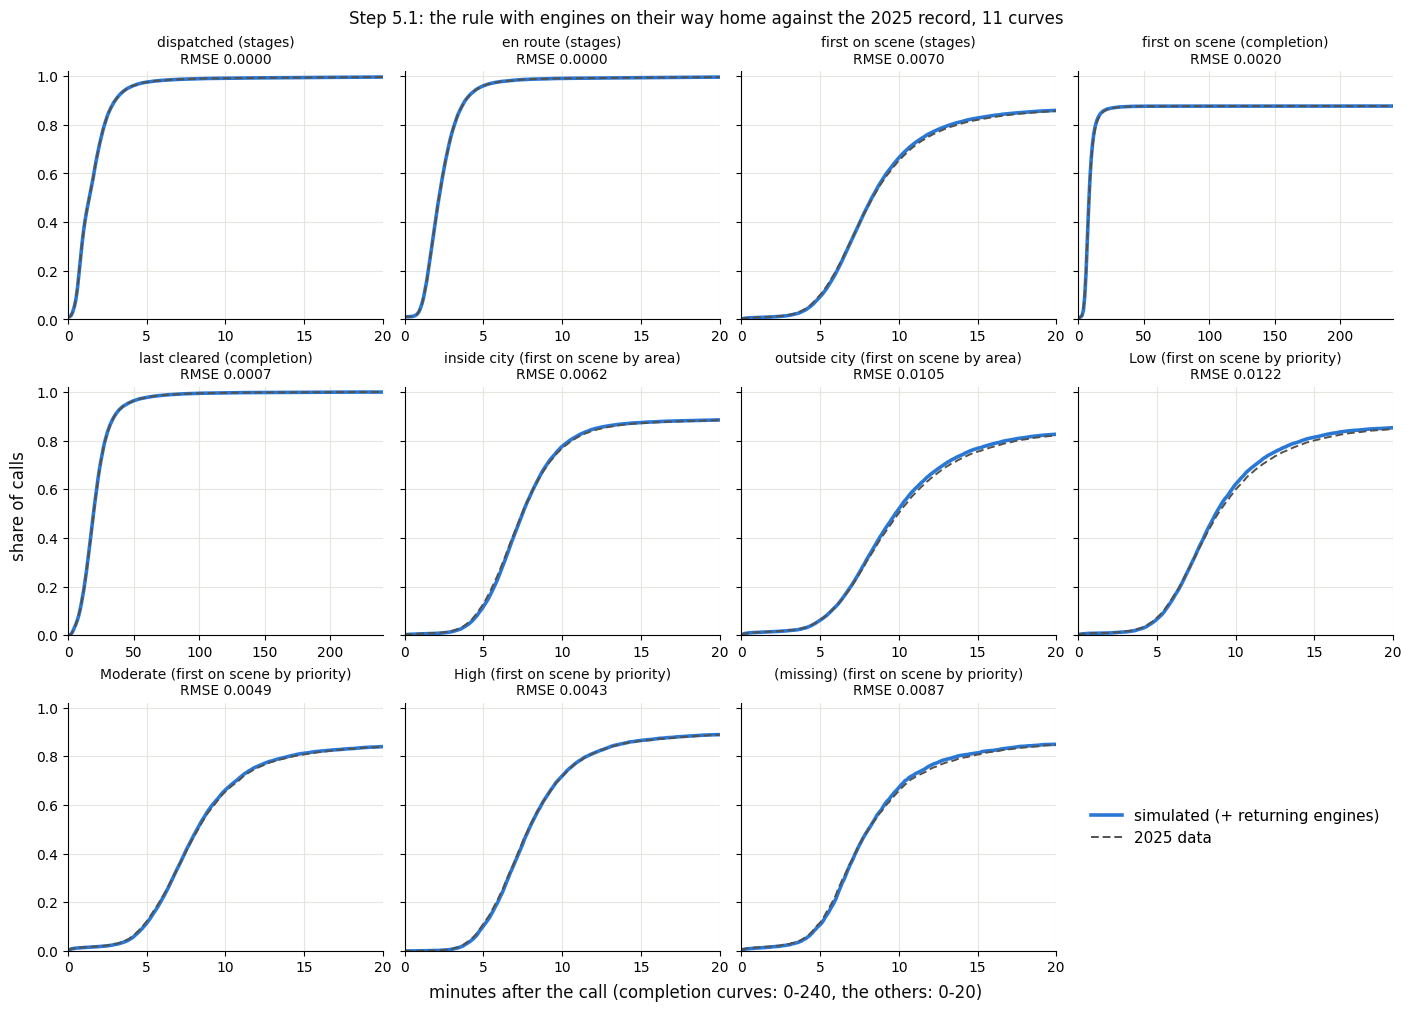

In [59]:
plot_curves(returning_curves, returning_check, "simulated (+ returning engines)",
            "Step 5.1: the rule with engines on their way home against the 2025 record, 11 curves")

**No measurable change.**
- **Same engine:** 77.5% → 77.3% of runs. The curve RMSEs and P90 stay where Step 4 left them.
- **Engines still driving home:** the rule sends one in 1,150 runs, against 1,260 in Step 4 and 1,407 in the record.
- **Where the 2025 engine was driving home,** the rule agrees with CAD in 65.5% of runs, against 67.2% in Step 4.

Knowing that these engines are away from home makes the rule send them less often, while CAD sent them more often.
Step 5.1 made up one assumption, how far home an engine is; Step 5.1b checks it against AVL.

## Step 5.1b — The drive home fitted to AVL positions

Step 5.1 assumes an engine leaves the scene the second it clears, and drives home in the calibrated time. The AVL
position of engines sent soon after a call shows where they really were.

**Change 1.** `return_progress(t, R, dwell_s, slowdown)`: the engine stays `dwell_s` seconds near the scene, then drives
home `slowdown` times slower than the calibrated drive R. Step 5.1 is dwell 0, slowdown 1. `travel_while_returning`
now calls it, with those defaults.
**Check.** With the defaults, the simulation equals Step 5.1 exactly.

In [60]:
def return_progress(elapsed_s, drive_home_s, dwell_s=0.0, slowdown=1.0):
    """Share of the drive home done elapsed_s after clearing, or None once home: the engine stays dwell_s near the scene,
    then drives home slowdown times slower than the calibrated drive of drive_home_s. Step 5.1 used dwell 0, slowdown 1.

    Example: return_progress(120.0, 600.0) -> 0.2; return_progress(120.0, 600.0, dwell_s=60.0, slowdown=1.5) -> 0.0667
    """
    if elapsed_s >= dwell_s + slowdown * drive_home_s:
        return None
    return max(0.0, elapsed_s - dwell_s) / (slowdown * drive_home_s)


def travel_while_returning(row, now, engine_state, travel_for_run, call_nodes, home_nodes, seconds_from_node, node_position,
                           travel_model, dwell_s=0.0, slowdown=1.0):
    """Cases 2 and 3: travel to this run's call for engines still driving home from their last call. An engine that
    cleared t seconds ago from scene S is a share p = return_progress(t, R, dwell_s, slowdown) of the way home, R being
    the calibrated drive S -> home; its travel is (1 - p) x travel(S -> call) + p x travel(home -> call). Other engines
    keep the travel from home. The travel model must be the linear one, which uses network seconds only.

    Example: travel_while_returning(row, now, engine_state, network_travel.loc[row], call_nodes, home_nodes, seconds_from_node,
                                    node_position, network_travel_model)["E3"] -> 512.0 (seconds), roughly
    """
    call_node = call_nodes.at[row, "node"]
    if pd.isna(call_node):
        return travel_for_run
    adjusted = travel_for_run.copy()
    for engine_id, (cleared_s, scene_row) in engine_state.items():
        elapsed = now - cleared_s
        if scene_row is None or elapsed >= RETURN_CHECK_SECONDS or pd.isna(adjusted.get(engine_id)):
            continue
        scene_node = call_nodes.at[scene_row, "node"]
        if pd.isna(scene_node):
            continue
        from_scene = seconds_from_node(int(scene_node))
        drive_home = float(travel_model(from_scene[node_position[home_nodes[engine_id]]], np.nan))
        share_home = return_progress(elapsed, drive_home, dwell_s, slowdown)
        if share_home is None:
            continue
        from_scene_to_call = float(travel_model(from_scene[node_position[int(call_node)]], np.nan))
        adjusted[engine_id] = (1 - share_home) * from_scene_to_call + share_home * travel_for_run[engine_id]
    return adjusted


print(f"return_progress(120.0, 600.0) = {return_progress(120.0, 600.0)}; "
      f"return_progress(120.0, 600.0, dwell_s=60.0, slowdown=1.5) = {return_progress(120.0, 600.0, dwell_s=60.0, slowdown=1.5):.4f}")
returning_again = simulate(
    runs, available=define_available_engines, choose=dispatch_by_protocol, engines=engines, estimated_travel=boundary_travel,
    where_engines_are=lambda row, now, state, travel: travel_while_returning(
        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model),
    verbose=False)
print(f"Step 5.1 rerun with return_progress equals Step 5.1: {returning_again.equals(returning_protocol)}")

return_progress(120.0, 600.0) = 0.2; return_progress(120.0, 600.0, dwell_s=60.0, slowdown=1.5) = 0.0667


Step 5.1 rerun with return_progress equals Step 5.1: True


**Change 2, first try.** `fit_return_progress` takes the runs whose engine:
- was away from home when sent;
- had arrived at its previous call and cleared it under an hour before;
- stood in the corridor between that scene and home (scene → engine → home at most 1.5 × scene → home).

The actual share of the way home is scene → engine / (scene → engine + engine → home). Dwell and slowdown are fitted
on 2024-10 to 2025-06 and tested on 2025-07 to 2025-09.

In [61]:
RETURN_CORRIDOR_FACTOR = 1.5                                                # [DESIGN] scene -> engine -> home within this x scene -> home = on the way home
RETURN_MIN_KM = 0.3                                                         # [DESIGN] scenes this close to home give no usable share of the way


def fit_return_progress(dispatches, engines, call_nodes, home_nodes, seconds_from_node, node_position, travel_model,
                        verbose=VERBOSE):
    """Fit return_progress's dwell and slowdown to where engines really were (AVL position at dispatch, CAD fields
    Latitude/Longitude_At_Assign_Time) when sent on their way home: runs whose engine was away from home, had arrived at
    its previous call, cleared it under RETURN_CHECK_SECONDS before, and stood in the corridor between that scene and
    home (scene -> engine -> home at most RETURN_CORRIDOR_FACTOR x scene -> home, straight line). The actual share of the
    way home is scene -> engine / (scene -> engine + engine -> home). Fit by least mean |share error| on runs before
    TRAVEL_TEST_FROM, tested on the later ones next to step 5.1 (dwell 0, slowdown 1).

    Example: fit_return_progress(...)[:2] -> (60.0, 1.5)  # dwell seconds, slowdown, roughly
    """
    order = dispatches.sort_values(["engine_id", "dispatched_at"])
    previous = order.groupby("engine_id")
    sample = pd.DataFrame({"engine_id": order["engine_id"], "dispatched_at": order["dispatched_at"],
                           "scene_row": pd.Series(order.index, index=order.index).groupby(order["engine_id"]).shift(),
                           "elapsed_s": (order["dispatched_at"] - previous["cleared_at"].shift()).dt.total_seconds(),
                           "previous_arrived": previous["arrived_at"].shift().notna(),
                           "away": ~order["at_home"].astype(bool)})
    sample = sample[sample.previous_arrived & sample.away & sample.elapsed_s.between(0, RETURN_CHECK_SECONDS, inclusive="left")].copy()
    sample["scene_row"] = sample["scene_row"].astype(int)
    scene = dispatches.loc[sample["scene_row"], ["incident_lon", "incident_lat"]].to_numpy()
    home = engines.set_index("engine_id").loc[sample["engine_id"], ["home_lon", "home_lat"]].to_numpy()
    avl = dispatches.loc[sample.index, ["engine_lon_at_dispatch", "engine_lat_at_dispatch"]].to_numpy()
    scene_to_engine = straight_line_km(scene[:, 0], scene[:, 1], avl[:, 0], avl[:, 1])
    engine_to_home = straight_line_km(avl[:, 0], avl[:, 1], home[:, 0], home[:, 1])
    scene_to_home = straight_line_km(scene[:, 0], scene[:, 1], home[:, 0], home[:, 1])
    sample["actual_share"] = scene_to_engine / (scene_to_engine + engine_to_home)
    in_corridor = (scene_to_engine + engine_to_home <= RETURN_CORRIDOR_FACTOR * scene_to_home) & (scene_to_home >= RETURN_MIN_KM)
    scene_nodes = call_nodes.loc[sample["scene_row"], "node"].to_numpy()
    usable = in_corridor & ~pd.isna(scene_nodes)
    sample = sample[usable].copy()
    sample["drive_home_s"] = [float(travel_model(seconds_from_node(int(scene_node))[node_position[home_nodes[engine_id]]], np.nan))
                              for scene_node, engine_id in zip(scene_nodes[usable], sample["engine_id"])]
    train = (sample["dispatched_at"] < TRAVEL_TEST_FROM).to_numpy()

    def predicted_share(parameters, part):
        dwell_s, slowdown = np.exp(parameters)
        return [1.0 if share is None else share for share in
                (return_progress(elapsed, drive, dwell_s, slowdown) for elapsed, drive in zip(part.elapsed_s, part.drive_home_s))]

    result = scipy.optimize.minimize(lambda parameters: np.mean(np.abs(np.array(predicted_share(parameters, sample[train]))
                                                                       - sample[train].actual_share)),
                                     np.log([60.0, 1.5]), method="Nelder-Mead", options={"maxiter": 2000, "xatol": 1e-6, "fatol": 1e-8})
    dwell_s, slowdown = np.exp(result.x)
    test = sample[~train].copy()
    test["step 5.1 (no dwell, no slowdown)"] = predicted_share(np.log([1e-9, 1.0]), test)
    test["AVL-fitted"] = predicted_share(result.x, test)
    comparison = pd.DataFrame({name: {"test runs": len(test), "mean |share error|": np.mean(np.abs(test[name] - test.actual_share)),
                                      "median predicted share": np.median(test[name])}
                               for name in ["step 5.1 (no dwell, no slowdown)", "AVL-fitted"]}).T
    if verbose:
        by_minute = test.groupby(pd.cut(test.elapsed_s / 60, [0, 1, 2, 4, 8, 60]), observed=True)[
            ["actual_share", "step 5.1 (no dwell, no slowdown)", "AVL-fitted"]].median()
        by_minute["runs"] = test.groupby(pd.cut(test.elapsed_s / 60, [0, 1, 2, 4, 8, 60]), observed=True).size()
        print(f"runs sent on their way home: {len(sample):,} (fit {train.sum():,} before {TRAVEL_TEST_FROM.date()}, test {len(test):,}); "
              f"median actual share of the way home {sample.actual_share.median():.2f}\n"
              f"fitted: dwell {dwell_s:.0f} s near the scene, then {slowdown:.2f} x the calibrated drive home\n"
              f"{comparison.round(3).to_string()}\nmedian share by minutes since clear (test runs):\n{by_minute.round(2).to_string()}\n")
    return dwell_s, slowdown, comparison


first_try = fit_return_progress(dispatches, engines, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model)

runs sent on their way home: 1,666 (fit 1,236 before 2025-07-01, test 430); median actual share of the way home 0.28
fitted: dwell 0 s near the scene, then 1.81 x the calibrated drive home
                                  test runs  mean |share error|  median predicted share
step 5.1 (no dwell, no slowdown)      430.0               0.267                   0.565
AVL-fitted                            430.0               0.226                   0.312
median share by minutes since clear (test runs):
           actual_share  step 5.1 (no dwell, no slowdown)  AVL-fitted  runs
elapsed_s                                                                  
(0, 1]             0.05                              0.07        0.04   105
(1, 2]             0.24                              0.27        0.15    56
(2, 4]             0.30                              0.48        0.27    67
(4, 8]             0.55                              0.89        0.49    77
(8, 60]            0.59                   

**The first try is wrong.** It fits a slowdown of 1.81 and looks better than Step 5.1 (test error 0.267 → 0.226), but
the sample is biased:
- It keeps only engines that were *not yet home* when CAD sent them.
- Eight minutes after a clear most engines are home. The few still out are the slow ones, so the 8–60 min row shows a
  share of only 0.59.
- The fit therefore learns the stragglers' speed.

An earlier remark in this conversation, that engines stay near the scene longer than Step 5.1 assumes, came from this
same biased sample.

**Change 2, fixed.** Keep the engines that were already home (their share is 1). The by-minute table now also shows
the share of runs at home.

In [62]:
RETURN_MINUTE_BANDS = [0, 1, 2, 4, 8, 60]                                   # [DESIGN] minutes-since-clear bands for checking the return progress


def fit_return_progress(dispatches, engines, call_nodes, home_nodes, seconds_from_node, node_position, travel_model,
                        verbose=VERBOSE):
    """Fit return_progress's dwell and slowdown to where engines really were (AVL position at dispatch, CAD fields
    Latitude/Longitude_At_Assign_Time) when sent soon after a call: runs whose engine had arrived at its previous call,
    cleared it under RETURN_CHECK_SECONDS before, and stood in the corridor between that scene and home (scene -> engine
    -> home at most RETURN_CORRIDOR_FACTOR x scene -> home, straight line), home included: keeping only engines still
    out would keep only the slow ones and bias the fit toward slow drives. The actual share of the
    way home is scene -> engine / (scene -> engine + engine -> home). Fit by least mean |share error| on runs before
    TRAVEL_TEST_FROM, tested on the later ones next to step 5.1 (dwell 0, slowdown 1).

    Example: fit_return_progress(...)[:2] -> (0.0, 1.18)  # dwell seconds, slowdown, roughly
    """
    order = dispatches.sort_values(["engine_id", "dispatched_at"])
    previous = order.groupby("engine_id")
    sample = pd.DataFrame({"engine_id": order["engine_id"], "dispatched_at": order["dispatched_at"],
                           "scene_row": pd.Series(order.index, index=order.index).groupby(order["engine_id"]).shift(),
                           "elapsed_s": (order["dispatched_at"] - previous["cleared_at"].shift()).dt.total_seconds(),
                           "previous_arrived": previous["arrived_at"].shift().notna(),
                           "at_home": order["at_home"].astype(bool)})
    sample = sample[sample.previous_arrived & sample.elapsed_s.between(0, RETURN_CHECK_SECONDS, inclusive="left")].copy()
    sample["scene_row"] = sample["scene_row"].astype(int)
    scene = dispatches.loc[sample["scene_row"], ["incident_lon", "incident_lat"]].to_numpy()
    home = engines.set_index("engine_id").loc[sample["engine_id"], ["home_lon", "home_lat"]].to_numpy()
    avl = dispatches.loc[sample.index, ["engine_lon_at_dispatch", "engine_lat_at_dispatch"]].to_numpy()
    scene_to_engine = straight_line_km(scene[:, 0], scene[:, 1], avl[:, 0], avl[:, 1])
    engine_to_home = straight_line_km(avl[:, 0], avl[:, 1], home[:, 0], home[:, 1])
    scene_to_home = straight_line_km(scene[:, 0], scene[:, 1], home[:, 0], home[:, 1])
    sample["actual_share"] = scene_to_engine / (scene_to_engine + engine_to_home)
    in_corridor = (scene_to_engine + engine_to_home <= RETURN_CORRIDOR_FACTOR * scene_to_home) & (scene_to_home >= RETURN_MIN_KM)
    scene_nodes = call_nodes.loc[sample["scene_row"], "node"].to_numpy()
    usable = in_corridor & ~pd.isna(scene_nodes)
    sample = sample[usable].copy()
    sample["drive_home_s"] = [float(travel_model(seconds_from_node(int(scene_node))[node_position[home_nodes[engine_id]]], np.nan))
                              for scene_node, engine_id in zip(scene_nodes[usable], sample["engine_id"])]
    train = (sample["dispatched_at"] < TRAVEL_TEST_FROM).to_numpy()

    def predicted_share(part, dwell_s, slowdown):
        return [1.0 if share is None else share for share in
                (return_progress(elapsed, drive, dwell_s, slowdown) for elapsed, drive in zip(part.elapsed_s, part.drive_home_s))]

    result = scipy.optimize.minimize(lambda parameters: np.mean(np.abs(np.array(predicted_share(sample[train], *np.exp(parameters)))
                                                                       - sample[train].actual_share)),
                                     np.log([60.0, 1.5]), method="Nelder-Mead", options={"maxiter": 10_000, "xatol": 1e-8, "fatol": 1e-8})
    dwell_s, slowdown = np.exp(result.x)
    test = sample[~train].copy()
    test["step 5.1 (no dwell, no slowdown)"] = predicted_share(test, 0.0, 1.0)
    test["AVL-fitted"] = predicted_share(test, dwell_s, slowdown)
    comparison = pd.DataFrame({name: {"test runs": len(test), "mean |share error|": np.mean(np.abs(test[name] - test.actual_share)),
                                      "median predicted share": np.median(test[name])}
                               for name in ["step 5.1 (no dwell, no slowdown)", "AVL-fitted"]}).T
    if verbose:
        minute_band = pd.cut(test.elapsed_s / 60, RETURN_MINUTE_BANDS)
        by_minute = test.groupby(minute_band, observed=True)[["actual_share", "step 5.1 (no dwell, no slowdown)", "AVL-fitted"]].median()
        by_minute["share at home"] = test.groupby(minute_band, observed=True).at_home.mean()
        by_minute["runs"] = test.groupby(minute_band, observed=True).size()
        print(f"runs sent within {RETURN_CHECK_SECONDS // 60} min of clearing a call they reached, in the scene -> home corridor: "
              f"{len(sample):,}, {sample.at_home.mean():.0%} at home (fit {train.sum():,} before {TRAVEL_TEST_FROM.date()}, "
              f"test {len(test):,}); median actual share of the way home {sample.actual_share.median():.2f}\n"
              f"fitted ({result.message}): dwell {dwell_s:.0f} s near the scene, then {slowdown:.2f} x the calibrated drive home\n"
              f"{comparison.round(3).to_string()}\nmedian share by minutes since clear (test runs):\n{by_minute.round(2).to_string()}\n")
    return dwell_s, slowdown, comparison


fitted_dwell_s, fitted_slowdown, progress_comparison = fit_return_progress(
    dispatches, engines, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model)

runs sent within 60 min of clearing a call they reached, in the scene -> home corridor: 7,515, 78% at home (fit 5,558 before 2025-07-01, test 1,957); median actual share of the way home 0.99
fitted (Optimization terminated successfully.): dwell 0 s near the scene, then 1.18 x the calibrated drive home
                                  test runs  mean |share error|  median predicted share
step 5.1 (no dwell, no slowdown)     1957.0               0.072                     1.0
AVL-fitted                           1957.0               0.071                     1.0
median share by minutes since clear (test runs):
           actual_share  step 5.1 (no dwell, no slowdown)  AVL-fitted  share at home  runs
elapsed_s                                                                                 
(0, 1]             0.05                              0.07        0.06           0.01   106
(1, 2]             0.29                              0.28        0.24           0.10    62
(2, 4]             0

- **Sample:** 7,515 runs, 78% of them at home.
- **Fit:** no dwell, and the drive home takes 1.18 × the calibrated time.
- **Test error:** 0.071, against 0.072 for Step 5.1. By minute the two are close: at 2–4 min the actual median share is
  0.48, Step 5.1 says 0.54 and the fit 0.45.
- **So Step 5.1's assumption was nearly right:** engines leave when they clear, and drive home a little slower than
  the calibrated time.

**Change 3.** The rule runs with the fitted dwell and slowdown.

In [63]:
avl_protocol = simulate(
    runs, available=define_available_engines, choose=dispatch_by_protocol, engines=engines, estimated_travel=boundary_travel,
    where_engines_are=lambda row, now, state, travel: travel_while_returning(
        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model,
        fitted_dwell_s, fitted_slowdown))
avl_engine_check = compare_engines(runs, avl_protocol, dispatches)
avl_table = simulated_dispatch_table(dispatches, avl_protocol, engines, verbose=False)
avl_curves = response_curves(avl_table, verbose=False)
avl_check = compare_curves(avl_curves, curves_2025)
columns["step 5.1b: + AVL-fitted return"] = evaluation_column(
    runs, avl_protocol, dispatches, avl_table, control_table(runs, avl_protocol, dispatches, engines, network_travel),
    avl_check, travel_comparison.loc[chosen_form, "mean |error| min"])
evaluation = evaluation_matrix(columns)

--- simulated CAD times (seconds since day zero) and engine used (37194, 5)
   dispatched_at  enroute_at    arrived_at    cleared_at engine_id
0         6796.0      6858.0   7255.000000   7404.000000       E62
1        23905.0     23956.0  24342.000000  25096.000000       E62
2        28215.0     28215.0  28388.000000  30243.000000       E29
3        29358.0     29358.0  29358.000000  31952.000000       E60
4        36851.0     36891.0  37311.489828  38056.489828        E3

--- engines: simulation vs 2025
                            runs  same_engine_share
all runs                   37194              0.773
first engine of each call  33156              0.814
inside city                21015              0.776
outside city               16175              0.768
runs with another engine and an arrival: 5,759; travel change (min): median -0.02, P10 -4.91, P90 3.66
runs whose engine was still on an earlier run: 0

--- simulated vs 2025 curves (11, 8)
                         curve         

--- evaluation matrix
                                                2025 record  step 2: straight line  step 3: road network  step 4: + agency boundaries  step 5.1: + returning engines  step 5.1b: + AVL-fitted return
travel estimate: test mean |error| (min)                NaN                  1.636                 1.547                        1.547                          1.547                           1.547
same engine: all runs                                 1.000                  0.698                 0.743                        0.775                          0.773                           0.773
same engine: first engine of each call                1.000                  0.735                 0.785                        0.817                          0.815                           0.814
same engine: single-engine calls                      1.000                  0.764                 0.816                        0.848                          0.847                          

In [64]:
returning_check_table({"2025 record": dispatches, "step 4": boundary_table, "step 5.1": returning_table, "step 5.1b": avl_table})

runs sent to an engine still driving home from its last call: {'2025 record': 1407, 'step 4': 1260, 'step 5.1': 1150, 'step 5.1b': 1124}


,runs,step 4,step 5.1,step 5.1b
2025 engine at home,31395,0.813,0.811,0.811
2025 engine driving home (return window),1214,0.672,0.655,0.647
"2025 engine away, other reasons",4585,0.545,0.544,0.544


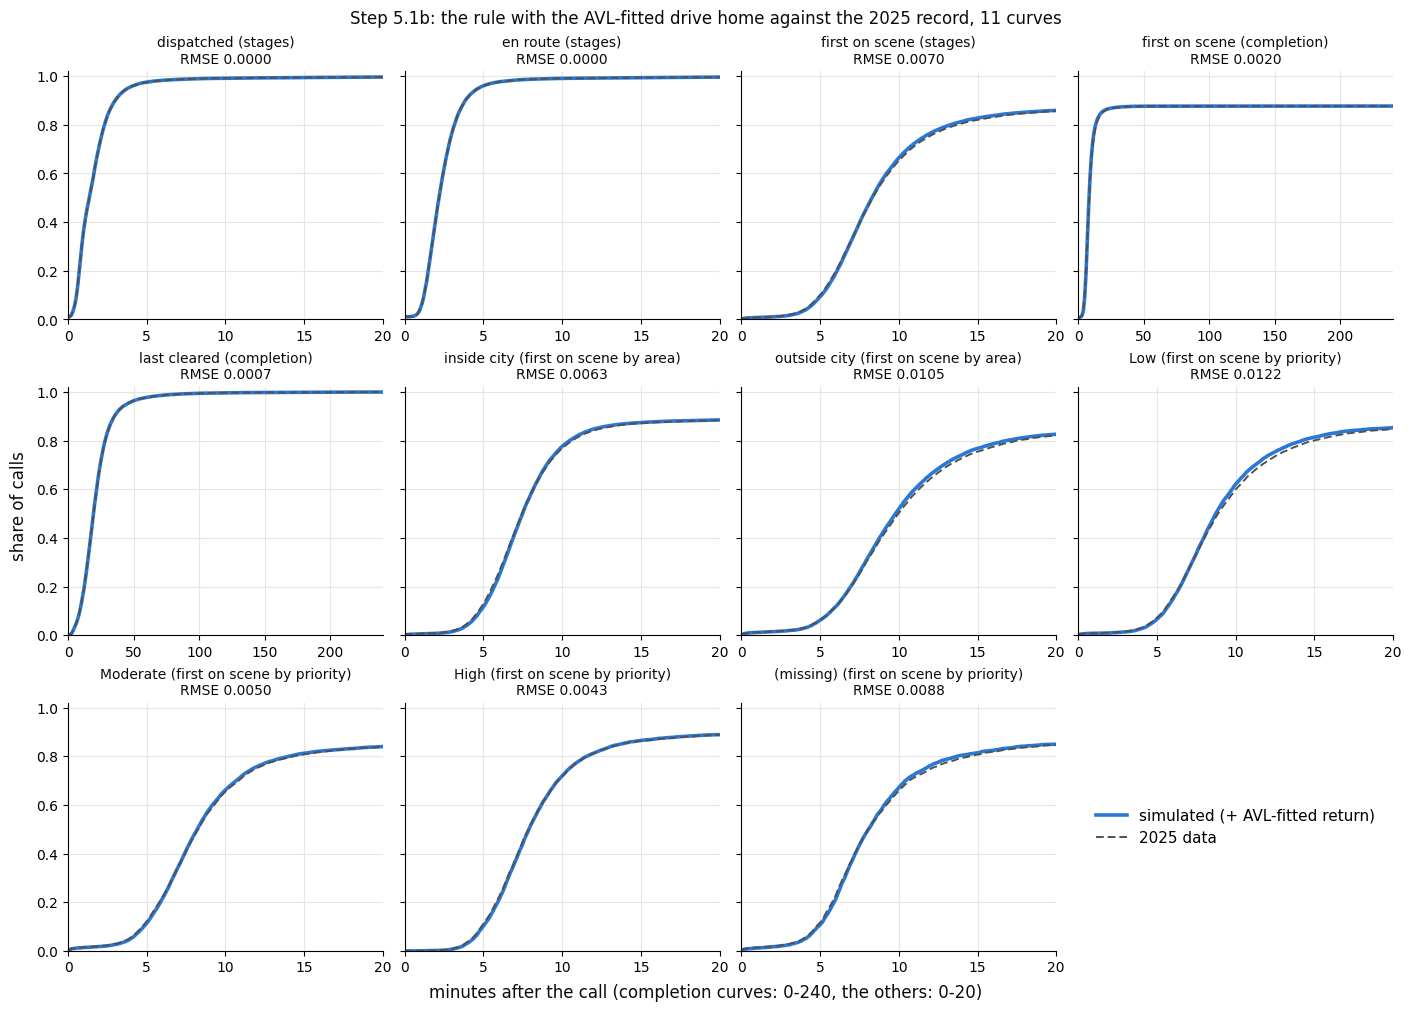

In [65]:
plot_curves(avl_curves, avl_check, "simulated (+ AVL-fitted return)",
            "Step 5.1b: the rule with the AVL-fitted drive home against the 2025 record, 11 curves")

**Still no measurable change.** Same engine 77.3% (first engine 81.4%), curve RMSE 0.007, P90 12.83 min, as in Step 5.1.
Where the 2025 engine was driving home, the rule agrees in 64.7% of runs (Step 4: 67.2%).

What this says:
- **The drive-home model is not what keeps the rule from matching CAD.** With the AVL fit it is about right.
- **Cases 2 and 3 are only 4.5% of runs** (Step 5.0a). Case 5 (elsewhere, 9.7%) and case 4 (another station, 1.4%)
  are larger, and the rule still puts those engines at home.
- **Open question:** CAD sends engines that are driving home more often than the rule does (1,407 runs against 1,124).

# Section 6 — M0: no run keeps its 2025 times, and its check E0

research.md, Step 1: in the protocol run, 82.8% of first arrivals still take their historical times, so a different
decision cannot change an outcome. M0 removes this: every engine moves from its simulated position with modeled
travel, recorded on-scene durations start at the simulated arrival, cancelled requests are released at their recorded
elapsed time, waiting requests are served by priority, and committed engines are never pulled. E0: the protocol run
is checked against the same curves, overall and for multi-engine, away-from-home and cross-agency calls
(first-on-scene curve RMSE at most 0.03, no state violations).

**Input/output check before running (gpt-6-astra, read-only).** Round 1 asked for three changes: keep a cancelled
request's deadline while it waits; keep where an engine is after a cancelled run; handle the five invalid timelines and
count bad timelines in E0. Round 2 asked for three more: a cancelled request that gets an engine late still ends at its
recorded release; an expired request keeps its release time; requests with no engine get no engine fields and are not
counted in n_engines_sent. Round 3: PASS.

## Step 6.1 — Shared functions: `simulate`, `simulated_dispatch_table`, `travel_while_returning`

**Change.**
- `simulate`: if `choose` returns no engine, the run waits; each clear offers engines to waiting runs by `wait_rank`
  (SOC priority), then by waiting time; a served run moves its times by its wait. No busy engine is ever taken.
  `counterfactual=True` (M0 only) adds: a cancelled request stops waiting at its recorded release, keeps that release if
  it is served late, and an engine released from a cancelled run stays f of the way out. `report` returns the waits,
  the runs that kept 2025 times, engines taken, runs never served and cancelled requests with no engine.
- `simulated_dispatch_table`: rows with no engine get no engine fields; `n_engines_sent` counts engines, not requests.
- `travel_while_returning`: an engine stored as (release, run, f) is f of the way from home to that call and drives back.

**Check.** The gate (Section 1 still exact) and Step 5.1b unchanged with the new functions.

In [66]:
PRIORITY_RANK = {"High": 0, "Moderate": 1, "Low": 2}                        # [SOURCE] SOC 2024 Appendix E risk levels; waiting runs are served in this order, missing last
E0_RMSE_LIMIT = 0.03                                                        # [DESIGN] research.md E0: first-on-scene curve RMSE at most this


def simulate(runs, available=all_engines_available, choose=dispatched_in_2025, engines=None, estimated_travel=None,
             where_engines_are=None, wait_rank=None, report=None, counterfactual=False, verbose=VERBOSE):
    """Replay every call in SimPy; returns per run the simulated CAD times (seconds since day zero) and the engine used.

    Each engine is a one-crew simpy.PreemptiveResource. When a run starts (its first recorded time), `available`
    lists the engines CAD may send and `choose` picks one with a travel time (None keeps the recorded times). The run
    then passes its times in time order (two 2025 runs have them out of order). A newer run may take an engine that is
    still on an older run, as when a returning crew picks up a new call (three 2025 runs); the older run keeps its times.
    The defaults (every engine available, the 2025 engine goes) replay the 2025 log.
    Each engine's last clear (time, and the run whose scene it left; None for a cancelled run) is kept in engine_state;
    where_engines_are, if given, turns the travel table's row into travel from where the engines are now.
    If `choose` returns no engine (None), the run waits and never takes a busy engine: each clear offers the engines to
    the waiting runs in order of wait_rank (lower first; all equal if None), then of waiting time, and a run that gets
    an engine moves all its times by its wait. counterfactual=True (M0) adds two rules: a request cancelled in the
    record stops waiting at its recorded release and gets no engine, and an engine released from a cancelled run it
    was driving to stays where it was (a share of the way to that call, kept in engine_state for where_engines_are).
    `report`, if a dict, receives the rows that kept their recorded times (kept_recorded), the waits (waited_seconds:
    row -> seconds), the rows whose engine a newer run took (taken_by_newer_run), the rows still waiting at the end
    (never_served) and the cancelled requests that never got an engine (cancelled_while_waiting).

    Example: simulate(runs).loc[0].tolist() -> [6796.0, 6858.0, 7255.0, 7404.0, 'E62']  # 4 CAD times, engine
    """
    env = simpy.Environment()
    engine_ids = runs["engine_id"].unique() if engines is None else engines["engine_id"]   # every engine CAD could send
    engine_pool = {engine_id: simpy.PreemptiveResource(env, capacity=1) for engine_id in engine_ids}
    engine_state = {}                                            # engine id -> (last clear, seconds; run left, or None)
    simulated = pd.DataFrame(np.nan, index=runs.index, columns=TIME_COLUMNS)
    simulated["engine_id"] = pd.Series(index=runs.index, dtype="object")
    waiting = []                                                 # runs with no engine yet: (rank, since, row, wake-up event)
    kept_recorded, waited_seconds, taken_by_newer_run_rows, cancelled_while_waiting = [], {}, [], []

    def pick(row):
        travel_for_run = None if estimated_travel is None else estimated_travel.loc[row]   # every engine -> this call, seconds
        if where_engines_are is not None:
            travel_for_run = where_engines_are(row, env.now, engine_state, travel_for_run)
        return choose(runs.loc[row], available(engine_pool, env.now, engines), travel_for_run)

    def serve_waiting():
        # ponytail: waiting runs are offered engines only at clears; an engine entering service mid-wait waits for the next clear
        for item in sorted(waiting, key=lambda item: item[:2]):
            engine_id, travel_seconds = pick(item[2])
            if engine_id is not None:
                waiting.remove(item)                             # the request is granted now, so the next run sees the engine busy
                item[3].succeed((engine_id, travel_seconds, engine_pool[engine_id].request(priority=-env.now)))

    def engine_run(row):
        times = runs.loc[row, TIME_COLUMNS]
        start = times.dropna().min()
        yield env.timeout(start - env.now)
        yield env.timeout(0)                                     # runs clearing in this same second free their engines first
        engine_id, travel_seconds = pick(row)
        request = None
        if engine_id is None:                                    # no engine to send: wait for a clear
            wake = env.event()
            item = (0 if wait_rank is None else wait_rank[row], env.now, row, wake)
            waiting.append(item)
            cancelled = counterfactual and pd.isna(times["arrived_at"])   # M0: its release time is exogenous
            if cancelled:                                        # it stops waiting at its recorded release
                yield wake | env.timeout(max(0.0, times["cleared_at"] - env.now))
                if not wake.triggered:
                    waiting.remove(item)
                    cancelled_while_waiting.append(row)
                    simulated.at[row, "cleared_at"] = env.now    # the request ends here, with no engine
                    return
            engine_id, travel_seconds, request = yield wake
            waited_seconds[row] = env.now - start
            release = times["cleared_at"]
            times = times + waited_seconds[row]                  # the run starts when it gets its engine
            if cancelled:                                        # ...but a cancelled run still ends at its recorded release
                times["cleared_at"] = release
                if times["enroute_at"] > release:
                    times["enroute_at"] = np.nan
        if travel_seconds is None:
            kept_recorded.append(row)
        recorded = (times if travel_seconds is None else shift_arrival(times, travel_seconds)).dropna().sort_values()
        simulated.at[row, "engine_id"] = engine_id
        taken_by_newer_run = False
        if request is None:
            request = engine_pool[engine_id].request(priority=-recorded.iloc[0])   # newer run ranks first
        with request as engine:
            yield engine
            for column, at in recorded.items():
                try:
                    yield env.timeout(at - env.now)
                except simpy.Interrupt:                                  # engine taken by a newer run
                    taken_by_newer_run = True
                    yield env.timeout(at - env.now)
                simulated.at[row, column] = env.now
        enroute_s = simulated.at[row, "enroute_at"]
        if taken_by_newer_run:
            taken_by_newer_run_rows.append(row)
        elif counterfactual and "arrived_at" not in recorded.index and travel_seconds and not pd.isna(enroute_s):
            # ponytail: the share of the way out assumes the engine left from home; one that left another scene is placed on its home -> call line
            outbound_share = min(1.0, max(0.0, (env.now - enroute_s) / travel_seconds))
            engine_state[engine_id] = (env.now, row, outbound_share) if outbound_share > 0 else (env.now, None)
        else:
            engine_state[engine_id] = (env.now, row if "arrived_at" in recorded.index else None)
        serve_waiting()

    def call(call_runs):
        yield env.timeout(runs.at[call_runs[0], "call_received_at"] - env.now)
        for row in choose_engines(call_runs):
            env.process(engine_run(row))

    for call_runs in runs.groupby("incident_id", sort=False).groups.values():
        env.process(call(list(call_runs)))
    env.run()
    show_table("simulated CAD times (seconds since day zero) and engine used", simulated, verbose)
    if report is not None:
        report.update(kept_recorded=kept_recorded, waited_seconds=waited_seconds, taken_by_newer_run=taken_by_newer_run_rows,
                      never_served=[item[2] for item in waiting], cancelled_while_waiting=cancelled_while_waiting)
    return simulated


def simulated_dispatch_table(dispatches, simulated, engines=None, verbose=VERBOSE):
    """The dispatch table rebuilt from the simulation: CAD times from SimPy, and from them the durations,
    cancelled flag, arrival order and engines per call, with the dataset's own formulas. Call attributes are inputs
    and are carried over. Where the simulation used another engine than 2025, the engine columns describe that engine
    as sent from its home station (auto_aid unknown).

    Example: simulated_dispatch_table(dispatches, simulated).shape -> (37194, 32)
    """
    table = dispatches.copy()
    for column in TIME_COLUMNS:
        seconds = simulated[column]                              # missing stays missing (NaT) without a pandas cast warning
        table[column] = (DAY_ZERO + pd.to_timedelta(seconds.fillna(0), unit="s").where(seconds.notna())).astype(dispatches[column].dtype)
    no_engine = simulated["engine_id"].isna()
    if no_engine.any():                                          # M0: a request cancelled before any engine was free
        for column in ["engine_id", "engine_type", "engine_agency", "engine_lon_at_dispatch", "engine_lat_at_dispatch",
                       "from_station", "at_home", "auto_aid"]:
            table.loc[no_engine, column] = None
    other_engine = (simulated["engine_id"].notna() & (simulated["engine_id"] != dispatches["engine_id"])).to_numpy()
    if other_engine.any():
        sent = engines.set_index("engine_id").loc[simulated.loc[other_engine, "engine_id"]]
        table.loc[other_engine, "engine_id"] = sent.index.to_numpy()
        for column, source in [("engine_type", "engine_type"), ("engine_agency", "engine_agency"),
                               ("engine_lon_at_dispatch", "home_lon"), ("engine_lat_at_dispatch", "home_lat"),
                               ("from_station", "home_station")]:
            table.loc[other_engine, column] = sent[source].to_numpy()
        table.loc[other_engine, "at_home"] = True
        table.loc[other_engine, "auto_aid"] = pd.NA
    table["turnout_s"] = seconds_between(table["enroute_at"], table["dispatched_at"])
    table["travel_s"] = seconds_between(table["arrived_at"], table["enroute_at"])
    table["on_scene_s"] = seconds_between(table["cleared_at"], table["arrived_at"])
    table["cancelled"] = table["arrived_at"].isna().astype("boolean")
    table["arrival_order"] = table.groupby("incident_id")["arrived_at"].rank(method="first").astype("Int64")
    table["n_engines_sent"] = table.groupby("incident_id")["engine_id"].transform("count").astype("Int64")  # engines, not requests
    show_table("simulated dispatch table", table, verbose)
    if verbose:
        differing = [column for column in dispatches.columns if not table[column].equals(dispatches[column])]
        print(f"columns that differ from the 2025 table: {differing}; whole table equal: {table.equals(dispatches)}\n")
    return table


def travel_while_returning(row, now, engine_state, travel_for_run, call_nodes, home_nodes, seconds_from_node, node_position,
                           travel_model, dwell_s=0.0, slowdown=1.0):
    """Cases 2 and 3: travel to this run's call for engines still driving home from their last call. An engine that
    cleared t seconds ago from scene S is a share p = return_progress(t, R, dwell_s, slowdown) of the way home, R being
    the calibrated drive S -> home; its travel is (1 - p) x travel(S -> call) + p x travel(home -> call). Other engines
    keep the travel from home. The travel model must be the linear one, which uses network seconds only.
    Section 6 (M0) also stores engines released from a cancelled run as (release, run, f): they were f of the way from
    home to that call and drive back from there without dwelling, so p = 1 - f x (1 - their progress back).

    Example: travel_while_returning(row, now, engine_state, network_travel.loc[row], call_nodes, home_nodes, seconds_from_node,
                                    node_position, network_travel_model)["E3"] -> 512.0 (seconds), roughly
    """
    call_node = call_nodes.at[row, "node"]
    if pd.isna(call_node):
        return travel_for_run
    adjusted = travel_for_run.copy()
    for engine_id, (cleared_s, scene_row, *outbound) in engine_state.items():
        elapsed = now - cleared_s
        if scene_row is None or elapsed >= RETURN_CHECK_SECONDS or pd.isna(adjusted.get(engine_id)):
            continue
        scene_node = call_nodes.at[scene_row, "node"]
        if pd.isna(scene_node):
            continue
        from_scene = seconds_from_node(int(scene_node))
        drive_home = float(travel_model(from_scene[node_position[home_nodes[engine_id]]], np.nan))
        if outbound:                                             # M0: released from a cancelled run, f of the way out
            progress_back = return_progress(elapsed, outbound[0] * drive_home, 0.0, slowdown)
            share_home = None if progress_back is None else 1 - outbound[0] * (1 - progress_back)
        else:
            share_home = return_progress(elapsed, drive_home, dwell_s, slowdown)
        if share_home is None:
            continue
        from_scene_to_call = float(travel_model(from_scene[node_position[int(call_node)]], np.nan))
        adjusted[engine_id] = (1 - share_home) * from_scene_to_call + share_home * travel_for_run[engine_id]
    return adjusted

In [67]:
check_section_1()
avl_again = simulate(
    runs, available=define_available_engines, choose=dispatch_by_protocol, engines=engines, estimated_travel=boundary_travel,
    where_engines_are=lambda row, now, state, travel: travel_while_returning(
        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model,
        fitted_dwell_s, fitted_slowdown), verbose=False)
print("Step 5.1b rerun with the new functions, runs with any time or engine different:",
      compare_times(avl_protocol, avl_again, verbose=False))
print("Step 5.1b dispatch table rebuilt with the new function equals the earlier one:",
      simulated_dispatch_table(dispatches, avl_again, engines, verbose=False).equals(avl_table))

{'runs with any time or engine different': 0, 'dispatch-table columns different': 0, 'largest |curve difference|': 0.0}
gate passed: Section 2 may run



Step 5.1b rerun with the new functions, runs with any time or engine different: 0
Step 5.1b dispatch table rebuilt with the new function equals the earlier one: True


## Step 6.2 — Usable timelines for M0

**Change.** `clean_runs_for_m0` repairs five runs for M0 only (Sections 1–5 keep the raw record): a negative turnout or
on-scene time becomes 0; two runs that arrived but never cleared get the median on-scene time; one run that neither
arrived nor cleared is released after the median dispatch-to-clear time of cancelled runs.
**Check.** The printed rows are exactly the five.

In [68]:
def clean_runs_for_m0(runs, verbose=VERBOSE):
    """Runs with a usable timeline for M0 (Sections 1-5 keep the raw record): a negative turnout or on-scene time
    becomes 0, a run that arrived but never cleared stays the median on-scene time of complete runs, and a run that
    neither arrived nor cleared is released after the median dispatch-to-clear time of cancelled runs.

    Example: clean_runs_for_m0(runs).loc[14718, ["dispatched_at", "enroute_at"]] -> equal (was 1 s apart, reversed)
    """
    cleaned = runs.copy()
    complete = cleaned["arrived_at"].notna() & cleaned["cleared_at"].notna()
    cancelled = cleaned["arrived_at"].isna() & cleaned["cleared_at"].notna()
    median_on_scene = (cleaned["cleared_at"] - cleaned["arrived_at"])[complete].median()                 # [SOURCE] 730 s in FY2025
    median_cancelled = (cleaned["cleared_at"] - cleaned["dispatched_at"])[cancelled].median()            # [SOURCE] 333 s in FY2025
    cleaned["enroute_at"] = cleaned["enroute_at"].clip(lower=cleaned["dispatched_at"])
    cleaned["cleared_at"] = cleaned["cleared_at"].clip(lower=cleaned["arrived_at"])
    cleaned["cleared_at"] = cleaned["cleared_at"].fillna(cleaned["arrived_at"] + median_on_scene)
    cleaned["cleared_at"] = cleaned["cleared_at"].fillna(cleaned["dispatched_at"] + median_cancelled)
    if verbose:
        changed = (cleaned[TIME_COLUMNS] != runs[TIME_COLUMNS]) & ~(cleaned[TIME_COLUMNS].isna() & runs[TIME_COLUMNS].isna())
        rows = changed.any(axis=1)
        print(f"--- M0 timelines repaired: {int(rows.sum())} runs (median on-scene {median_on_scene:.0f} s, "
              f"median cancelled {median_cancelled:.0f} s)\n"
              f"{pd.concat({'2025': runs.loc[rows, TIME_COLUMNS], 'M0': cleaned.loc[rows, TIME_COLUMNS]}, axis=1).to_string()}\n")
    return cleaned


m0_runs = clean_runs_for_m0(runs)

--- M0 timelines repaired: 5 runs (median on-scene 730 s, median cancelled 333 s)
               2025                                                M0                                    
      dispatched_at  enroute_at  arrived_at  cleared_at dispatched_at  enroute_at  arrived_at  cleared_at
7291     14208332.0  14208363.0  14210219.0  14210116.0    14208332.0  14208363.0  14210219.0  14210219.0
13763    26729464.0  26729520.0  26729963.0         NaN    26729464.0  26729520.0  26729963.0  26730693.0
13764    26730314.0  26730364.0         NaN         NaN    26730314.0  26730364.0         NaN  26730647.0
14718    28632548.0  28632547.0  28632743.0  28633144.0    28632548.0  28632548.0  28632743.0  28633144.0
33796    26729154.0  26729212.0  26729455.0         NaN    26729154.0  26729212.0  26729455.0  26730185.0



## Step 6.3 — The M0 rule `dispatch_closest`

**Change.** The available engine with the shortest modeled travel goes, always with that travel; equal travel goes to
the engine listed first, never to the 2025 engine; no available engine returns (None, None) and the run waits. Calls
without a location (4 runs) keep their 2025 engine and times.
**Check.** The first five runs of the year with every engine free: chosen engine and travel next to the 2025 engine.

In [69]:
def dispatch_closest(run, available_engines, travel_for_run):
    """Section 6 rule for the choice (M0): the available engine with the shortest modeled travel from where it is now
    goes, always with that travel, so no run keeps its 2025 times. Equal travel goes to the engine listed first (engines
    table order), never to the 2025 engine. With no available engine it returns (None, None) and the run waits
    (simulate). A call without a location has no travel for any engine: its 2025 engine goes with its 2025 times when
    free, otherwise the run waits for that engine.

    Example: dispatch_closest(runs.loc[0], ["E62", "E3"], boundary_travel.loc[0]) -> ('E62', 257.05...)  # seconds
             dispatch_closest(runs.loc[0], [], boundary_travel.loc[0]) -> (None, None)
    """
    if travel_for_run.isna().all():                              # call without coordinates (4 runs)
        return (run["engine_id"], None) if run["engine_id"] in available_engines else (None, None)
    candidates = travel_for_run[available_engines].dropna()
    if candidates.empty:
        return None, None
    return candidates.idxmin(), float(candidates.min())


all_free = engines["engine_id"].tolist()
print(pd.DataFrame([(row, runs.at[row, "engine_id"], *dispatch_closest(runs.loc[row], all_free, boundary_travel.loc[row]))
                    for row in runs.index[:5]], columns=["run", "2025 engine", "M0 engine", "modeled travel s"]).to_string(index=False))
print(dispatch_closest(runs.loc[0], [], boundary_travel.loc[0]))

 run 2025 engine M0 engine  modeled travel s
   0         E62       E62        257.054336
   1         E62       E62        289.890661
   2         E29       E29        207.798588
   3         E60       E60        148.418269
   4         E40        E3        420.489828
(None, None)


## Step 6.4 — Small cases with hand-calculated answers

**Check.** One engine and four runs (waiting by priority; a cancelled request that gives up), the rebuilt table for a
request with no engine, an engine half way out after a cancellation, and a cancelled request served late.

In [70]:
def small_cases():
    """The smoke tests, inside a function so that they do not overwrite runs or dispatches."""
    free_engines = lambda pool, now, engines: [e for e, resource in pool.items() if resource.count == 0]

    # 1. one engine, four runs: A busy until 900 s; D (cancelled in the record at 350 s) gives up; C (most urgent) then B
    runs = pd.DataFrame({"incident_id": ["A", "B", "C", "D"], "engine_id": ["E1"] * 4, "call_received_at": [0.0, 90.0, 190.0, 140.0],
                         "dispatched_at": [0.0, 100.0, 200.0, 150.0], "enroute_at": [60.0, 160.0, 230.0, 180.0],
                         "arrived_at": [300.0, 400.0, 500.0, np.nan], "cleared_at": [900.0, 1000.0, 800.0, 350.0]})
    travel = pd.DataFrame({"E1": [240.0] * 4}, index=runs.index)
    rank = pd.Series([1, 2, 0, 1], index=runs.index)
    report = {}
    print("test 1 input runs:\n", runs.to_string(), "\nrank:", rank.tolist())
    out = simulate(runs, available=free_engines, choose=dispatch_closest, estimated_travel=travel, wait_rank=rank,
                       report=report, counterfactual=True, verbose=False)
    print("output:\n", out.to_string(), "\nreport:", report)
    expected = np.array([[0.0, 60.0, 300.0, 900.0], [1470.0, 1530.0, 1770.0, 2370.0], [900.0, 930.0, 1170.0, 1470.0],
                         [np.nan, np.nan, np.nan, 350.0]])
    assert np.allclose(out[TIME_COLUMNS].to_numpy(float), expected, equal_nan=True), "times differ from the hand calculation"
    assert report["cancelled_while_waiting"] == [3] and pd.isna(out.at[3, "engine_id"]) and report["never_served"] == []
    assert report["waited_seconds"] == {1: 1370.0, 2: 700.0} and report["taken_by_newer_run"] == []
    print("test 1 passed: D gives up at 350 s without an engine (its release is kept); C is served at 900 s, B at 1470 s; no engine taken")

    # 1b. the rebuilt dispatch table: the request that got no engine has no engine fields and is not counted as an engine
    recorded = runs.copy()
    dispatches = recorded[["incident_id", "engine_id"]].copy()
    for column in ["call_received_at"] + TIME_COLUMNS:
        dispatches[column] = DAY_ZERO + pd.to_timedelta(recorded[column], unit="s")
    dispatches = dispatches.astype({"engine_id": "string"}).assign(
        engine_type=pd.array(["E"] * 4, dtype="string"), engine_agency=pd.array(["GFR"] * 4, dtype="string"),
        engine_lon_at_dispatch=-82.3, engine_lat_at_dispatch=29.65, from_station=pd.array(["GFR_01"] * 4, dtype="string"),
        at_home=pd.array([True] * 4, dtype="boolean"), auto_aid=pd.array([False] * 4, dtype="boolean"))
    table = simulated_dispatch_table(dispatches, out, verbose=False)
    print(table[["incident_id", "engine_id", "engine_type", "at_home", "cleared_at", "n_engines_sent", "cancelled"]].to_string())
    assert pd.isna(table.at[3, "engine_id"]) and pd.isna(table.at[3, "engine_type"]) and pd.isna(table.at[3, "at_home"])
    assert table.at[3, "n_engines_sent"] == 0 and table.at[3, "cleared_at"] == DAY_ZERO + pd.Timedelta(seconds=350)
    print("test 1b passed\n")

    # 3. a cancelled request (dispatched 100 s, cancelled 350 s) that gets an engine at 300 s still ends at 350 s, without en route
    runs3 = pd.DataFrame({"incident_id": ["H", "I"], "engine_id": ["E3", "E3"], "call_received_at": [0.0, 90.0],
                          "dispatched_at": [0.0, 100.0], "enroute_at": [30.0, 160.0], "arrived_at": [100.0, np.nan],
                          "cleared_at": [300.0, 350.0]})
    out3 = simulate(runs3, available=free_engines, choose=dispatch_closest,
                        estimated_travel=pd.DataFrame({"E3": [70.0, 70.0]}, index=runs3.index), counterfactual=True, verbose=False)
    print("test 3 output:\n", out3.to_string())
    assert np.allclose(out3.loc[1, TIME_COLUMNS].to_numpy(float), [300.0, np.nan, np.nan, 350.0], equal_nan=True)
    print("test 3 passed: I gets E3 at 300 s and is released at its recorded 350 s; its en route (360 s) is dropped\n")

    # 2. engine E2 is sent to F, cancelled 100 s after going en route on a 200 s drive: it is half way out at release
    runs2 = pd.DataFrame({"incident_id": ["F", "G"], "engine_id": ["E2", "E2"], "call_received_at": [0.0, 190.0],
                          "dispatched_at": [0.0, 190.0], "enroute_at": [30.0, 200.0], "arrived_at": [np.nan, 500.0],
                          "cleared_at": [130.0, 900.0]})
    travel2 = pd.DataFrame({"E2": [200.0, 200.0]}, index=runs2.index)
    seen = []
    snapshot = lambda row, now, state, travel_row: (seen.append((row, now, dict(state))), travel_row)[1]
    simulate(runs2, available=free_engines, choose=dispatch_closest, estimated_travel=travel2, where_engines_are=snapshot,
                 counterfactual=True, verbose=False)
    print("test 2 engine_state seen by run G:", seen[-1])
    assert seen[-1][2]["E2"] == (130.0, 0, 0.5), "E2 should be (release 130 s, run F, half way out)"
    call_nodes = pd.DataFrame({"node": [1, 3]}, index=[0, 1])                # run F's scene is node 1, run G's call node 3
    node_position = pd.Series([0, 1, 2], index=[1, 2, 3])
    from_scene = np.array([0.0, 600.0, 300.0])                              # scene -> scene, -> home (node 2), -> call (node 3)
    adjusted = travel_while_returning(1, 190.0, {"E2": (130.0, 0, 0.5)}, pd.Series({"E2": 500.0}), call_nodes,
                                          pd.Series({"E2": 2}), lambda node: from_scene, node_position, lambda s, km: s)
    print("test 2 travel to G from half way out, 60 s into the drive back:", adjusted["E2"], "(hand: 0.4 x 300 + 0.6 x 500 = 420)")
    assert np.isclose(adjusted["E2"], 420.0)
    print("test 2 passed")


small_cases()

test 1 input runs:
   incident_id engine_id  call_received_at  dispatched_at  enroute_at  arrived_at  cleared_at
0           A        E1               0.0            0.0        60.0       300.0       900.0
1           B        E1              90.0          100.0       160.0       400.0      1000.0
2           C        E1             190.0          200.0       230.0       500.0       800.0
3           D        E1             140.0          150.0       180.0         NaN       350.0 
rank: [1, 2, 0, 1]
output:
    dispatched_at  enroute_at  arrived_at  cleared_at engine_id
0            0.0        60.0       300.0       900.0        E1
1         1470.0      1530.0      1770.0      2370.0        E1
2          900.0       930.0      1170.0      1470.0        E1
3            NaN         NaN         NaN       350.0       NaN 
report: {'kept_recorded': [], 'waited_seconds': {2: np.float64(700.0), 1: np.float64(1370.0)}, 'taken_by_newer_run': [], 'never_served': [], 'cancelled_while_waiting': [3

## Step 6.5 — The full year under M0

**Change.** The Step 5.1b setting (road network, agency line, AVL-fitted drive home) with `dispatch_closest`, waiting by
SOC priority and `counterfactual=True`, on the repaired runs.

--- simulated CAD times (seconds since day zero) and engine used (37194, 5)
   dispatched_at  enroute_at    arrived_at    cleared_at engine_id
0         6796.0      6858.0   7115.054336   7264.054336       E62
1        23905.0     23956.0  24245.890661  24999.890661       E62
2        28215.0     28215.0  28422.798588  30277.798588       E29
3        29358.0     29358.0  29506.418269  32100.418269       E60
4        36851.0     36891.0  37311.489828  38056.489828        E3

--- engines: simulation vs 2025
                            runs  same_engine_share
all runs                   37194              0.692
first engine of each call  33156              0.736
inside city                21015              0.680
outside city               16175              0.707
runs with another engine and an arrival: 8,280; travel change (min): median 0.15, P10 -4.22, P90 3.28
runs whose engine was still on an earlier run: 0

--- simulated vs 2025 curves (11, 8)
                         curve          

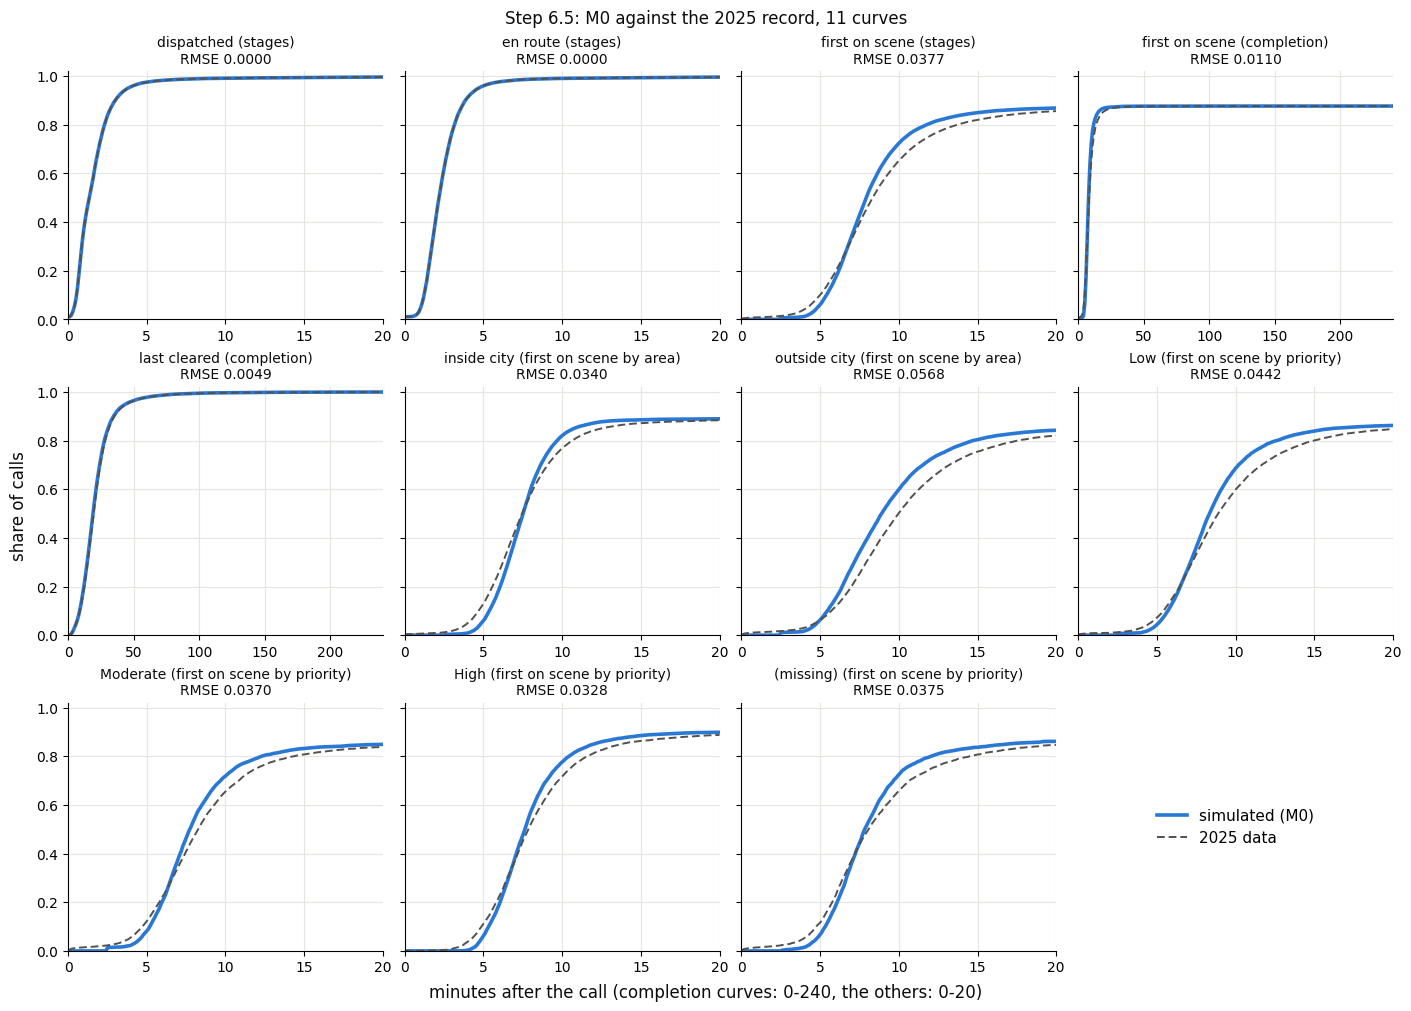

In [71]:
wait_rank = dispatches["priority"].astype("string").map(PRIORITY_RANK).fillna(len(PRIORITY_RANK))
m0_report = {}
m0_protocol = simulate(
    m0_runs, available=define_available_engines, choose=dispatch_closest, engines=engines, estimated_travel=boundary_travel,
    where_engines_are=lambda row, now, state, travel: travel_while_returning(
        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model,
        fitted_dwell_s, fitted_slowdown),
    wait_rank=wait_rank, report=m0_report, counterfactual=True)
m0_engine_check = compare_engines(runs, m0_protocol, dispatches)
m0_table = simulated_dispatch_table(dispatches, m0_protocol, engines, verbose=False)
m0_curves = response_curves(m0_table, verbose=False)
m0_check = compare_curves(m0_curves, curves_2025)
plot_curves(m0_curves, m0_check, "simulated (M0)", "Step 6.5: M0 against the 2025 record, 11 curves")

## Step 6.6 — E0

**Check.** State checks, first-on-scene curve RMSE by stratum, the evaluation matrix with M0 added (its last row is M0
minus the 2025 record at P90), and the E0 decision.

In [72]:
def share_first_arrivals_as_recorded(runs, simulated):
    """Share of calls whose simulated first arrival is the second recorded in 2025 (calls with no arrival count as not equal).

    Example: share_first_arrivals_as_recorded(runs, simulate(runs)) -> 0.877  # the replay: every call that had an arrival
             share_first_arrivals_as_recorded(runs, m0_protocol) -> 0.0001  # M0 (FY2025)
    """
    first_simulated = simulated["arrived_at"].groupby(runs["incident_id"]).min()
    first_2025 = runs["arrived_at"].groupby(runs["incident_id"]).min()
    return float((first_simulated == first_2025).mean())


def check_counterfactual_run(runs, simulated, dispatches, report, verbose=VERBOSE):
    """E0 state checks of a run that should be counterfactual-consistent. The first six must be 0; kept 2025 times
    must not exceed the runs of calls without a location; the rest describe the run.

    Example: check_counterfactual_run(runs, m0_protocol, dispatches, m0_report)["runs never served"] -> 0
    """
    served = simulated["engine_id"].notna()
    order = simulated[served].sort_values(["engine_id", "dispatched_at"])
    still_busy = order["dispatched_at"] < order.groupby("engine_id")["cleared_at"].shift()
    out_of_order = (simulated[TIME_COLUMNS].ffill(axis=1).diff(axis=1).iloc[:, 1:] < 0).any(axis=1)
    waits = pd.Series(report["waited_seconds"], dtype=float)
    checks = pd.Series({
        "runs never served": len(report["never_served"]),
        "runs whose engine was taken by a newer run": len(report["taken_by_newer_run"]),
        "runs sent while their engine was still on an earlier run": int(still_busy.sum()),
        "runs with an arrival in 2025 but none simulated": int((runs["arrived_at"].notna() & simulated["arrived_at"].isna()).sum()),
        "runs with times out of order": int(out_of_order.sum()),
        "runs served without a clear": int((served & simulated["cleared_at"].isna()).sum()),
        "runs that kept their 2025 times": len(report["kept_recorded"]),
        "runs of calls without a location": int(dispatches["incident_lon"].isna().sum()),
        "cancelled requests that never got an engine": len(report["cancelled_while_waiting"]),
        "calls whose first arrival is the recorded second (share)": share_first_arrivals_as_recorded(runs, simulated),
        "runs that waited for an engine": len(waits),
        "wait seconds: median": waits.median(),
        "wait seconds: max": waits.max(),
    })
    if verbose:
        print(f"--- E0 state checks\n{checks.round(4).to_string()}\n")
        if len(waits):
            ranks = dispatches.loc[waits.index, "priority"].astype("string").fillna("(missing)")
            print(f"waits by priority (count, median s):\n{waits.groupby(ranks).agg(['size', 'median']).round(0).to_string()}\n")
    return checks


def compare_curves_by_stratum(table, dispatches, verbose=VERBOSE):
    """E0 strata: RMSE and largest |simulated - 2025| share of the first-on-scene curve, for all calls, multi-engine
    calls, calls whose first 2025 engine was sent away from home, and calls with an engine from the other agency.
    Strata come from the 2025 record, so both curves use the same calls.

    Example: compare_curves_by_stratum(m0_table, dispatches).columns.tolist() -> ['calls', 'rmse', 'max_abs_difference']
    """
    first_sent = dispatches.sort_values("dispatched_at").groupby("incident_id").head(1)
    other_agency = (dispatches["engine_agency"] == "GFR") != (dispatches["jurisdiction"] == "GFR")
    strata = {"all calls": dispatches["incident_id"].unique(),
              "multi-engine calls": dispatches.loc[dispatches["n_engines_sent"] > 1, "incident_id"].unique(),
              "first engine sent away from home": first_sent.loc[~first_sent["at_home"].astype(bool), "incident_id"].unique(),
              "calls with an other-agency engine": dispatches.loc[other_agency, "incident_id"].unique()}
    rows = {}
    for name, incidents in strata.items():
        check = compare_curves(response_curves(table[table["incident_id"].isin(incidents)], verbose=False),
                               response_curves(dispatches[dispatches["incident_id"].isin(incidents)], verbose=False),
                               verbose=False).set_index(["curve", "series"]).loc[("stages", "first_on_scene")]
        rows[name] = {"calls": len(incidents), "rmse": check["rmse"], "max_abs_difference": check["max_abs_difference"]}
    by_stratum = pd.DataFrame(rows).T
    if verbose:
        print(f"--- E0 first-on-scene curve, simulated vs 2025, by stratum\n{by_stratum.round(4).to_string()}\n")
    return by_stratum


def decide_e0(states, by_stratum, verbose=VERBOSE):
    """E0 decision (research.md): first-on-scene curve RMSE for all calls at most E0_RMSE_LIMIT, no state violation,
    and only calls without a location keep their 2025 times.

    Example: decide_e0(e0_states, e0_strata) -> False  # FY2025: no state violation, but RMSE 0.0377 > 0.03
    """
    violations = states[["runs never served", "runs whose engine was taken by a newer run",
                         "runs sent while their engine was still on an earlier run",
                         "runs with an arrival in 2025 but none simulated", "runs with times out of order",
                         "runs served without a clear"]].sum()
    passed = bool(by_stratum.loc["all calls", "rmse"] <= E0_RMSE_LIMIT and violations == 0
                  and states["runs that kept their 2025 times"] <= states["runs of calls without a location"])
    if verbose:
        print(f"E0: RMSE all calls {by_stratum.loc['all calls', 'rmse']:.4f} (limit {E0_RMSE_LIMIT}), state violations "
              f"{int(violations)}, kept 2025 times {int(states['runs that kept their 2025 times'])} "
              f"(calls without a location {int(states['runs of calls without a location'])}) -> passed: {passed}\n")
    return passed


print(f"step 5.1b: calls whose first arrival is the recorded second: {share_first_arrivals_as_recorded(runs, avl_protocol):.1%}")
e0_states = check_counterfactual_run(runs, m0_protocol, dispatches, m0_report)
e0_strata = compare_curves_by_stratum(m0_table, dispatches)
columns["step 6 (M0): modeled travel for every run"] = evaluation_column(
    runs, m0_protocol, dispatches, m0_table, dispatches, m0_check, travel_comparison.loc[chosen_form, "mean |error| min"])
evaluation = evaluation_matrix(columns)
e0_passed = decide_e0(e0_states, e0_strata)

step 5.1b: calls whose first arrival is the recorded second: 72.6%
--- E0 state checks
runs never served                                           0.0000
runs whose engine was taken by a newer run                  0.0000
runs sent while their engine was still on an earlier run    0.0000
runs with an arrival in 2025 but none simulated             0.0000
runs with times out of order                                0.0000
runs served without a clear                                 0.0000
runs that kept their 2025 times                             4.0000
runs of calls without a location                            4.0000
cancelled requests that never got an engine                 0.0000
calls whose first arrival is the recorded second (share)    0.0001
runs that waited for an engine                              0.0000
wait seconds: median                                           NaN
wait seconds: max                                              NaN



--- E0 first-on-scene curve, simulated vs 2025, by stratum
                                     calls    rmse  max_abs_difference
all calls                          33156.0  0.0377              0.0743
multi-engine calls                  2941.0  0.0441              0.1102
first engine sent away from home    4823.0  0.0435              0.0950
calls with an other-agency engine   1371.0  0.0193              0.0532

--- evaluation matrix
                                                2025 record  step 2: straight line  step 3: road network  step 4: + agency boundaries  step 5.1: + returning engines  step 5.1b: + AVL-fitted return  step 6 (M0): modeled travel for every run
travel estimate: test mean |error| (min)                NaN                  1.636                 1.547                        1.547                          1.547                           1.547                                      1.547
same engine: all runs                                 1.000                  0.698 

## Step 6.7 — Why the first-on-scene curve misses

**Check.** Quantiles of call-to-first-arrival minutes (2025, Step 5.1b, M0), and modeled against recorded travel for
runs where M0 sent the same engine from home as in 2025.

In [73]:
def first_on_scene_minutes(table):
    """Minutes from the call to the first engine on scene, per call, and whether the call is inside the city.

    Example: first_on_scene_minutes(dispatches)[0].median() -> 7.83
    """
    per_call = table.groupby("incident_id").agg(call=("call_received_at", "min"), first=("arrived_at", "min"),
                                                 focal=("focal", "first"))
    return (per_call["first"] - per_call["call"]).dt.total_seconds() / 60, per_call["focal"]


quantiles = {}
for name, table in [("2025 record", dispatches), ("step 5.1b", avl_table), ("M0", m0_table)]:
    minutes, focal = first_on_scene_minutes(table)
    for area, mask in [("all calls", pd.Series(True, index=minutes.index)), ("inside city", focal), ("outside city", ~focal)]:
        quantiles[(area, name)] = minutes[mask].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(2).tolist()
print(pd.DataFrame(quantiles, index=["P10", "P25", "P50", "P75", "P90"]).T.to_string())

same_from_home = ((m0_table["engine_id"] == dispatches["engine_id"]) & dispatches["at_home"].astype(bool)
                  & dispatches["travel_s"].notna() & m0_table["travel_s"].notna() & ~dispatches["staged"].astype(bool))
gap = (m0_table["travel_s"] - dispatches["travel_s"])[same_from_home].astype(float) / 60
print(f"same engine sent from home, {int(same_from_home.sum()):,} runs: modeled minus recorded travel (min) median "
      f"{gap.median():.2f}, P10 {gap.quantile(0.1):.2f}, P90 {gap.quantile(0.9):.2f}; SD recorded "
      f"{dispatches['travel_s'][same_from_home].astype(float).std() / 60:.2f}, modeled "
      f"{m0_table['travel_s'][same_from_home].astype(float).std() / 60:.2f}")
for area, mask in [("inside city", dispatches["focal"]), ("outside city", ~dispatches["focal"])]:
    part = (m0_table["travel_s"] - dispatches["travel_s"])[same_from_home & mask].astype(float) / 60
    print(f"  {area}: {len(part):,} runs, median {part.median():.2f} min, mean {part.mean():.2f} min")

                           P10   P25   P50    P75    P90
all calls    2025 record  4.83  6.17  7.83  10.08  13.22
inside city  2025 record  4.58  5.75  7.13   8.78  10.80
outside city 2025 record  5.48  7.12  9.18  11.96  15.65
all calls    step 5.1b    4.93  6.23  7.82   9.92  12.83
inside city  step 5.1b    4.70  5.87  7.18   8.73  10.62
outside city step 5.1b    5.48  7.10  9.03  11.65  15.00
all calls    M0           5.28  6.30  7.56   9.17  11.41
inside city  M0           5.28  6.19  7.27   8.43   9.77
outside city M0           5.28  6.49  8.24  10.52  13.38
same engine sent from home, 19,687 runs: modeled minus recorded travel (min) median -0.07, P10 -2.68, P90 1.37; SD recorded 3.70, modeled 2.05
  inside city: 11,614 runs, median 0.22 min, mean -0.18 min
  outside city: 8,072 runs, median -0.62 min, mean -1.19 min


## Section 6 evidence

- **Sections 1–5 are unchanged.** The gate passes, Step 5.1b rerun with the new functions is identical, and the 30
  output files of Sections 1–5 written by the full script are byte-identical to those written before the change.
- **M0 is counterfactual-consistent.** Calls whose first arrival is the recorded second: 72.6% in Step 5.1b, 0.01% in
  M0. Only the 4 runs of calls without a location keep their 2025 times. State checks: 0 runs never served, 0 engines
  taken, 0 double bookings, 0 lost arrivals, 0 timelines out of order, 0 runs without a clear. No run had to wait: under
  the agency line an eligible engine was always free.
- **E0 fails on the curve.** First-on-scene curve RMSE 0.0377 (limit 0.03): inside the city 0.034, outside 0.057;
  multi-engine calls 0.044, first engine sent away from home 0.044, calls with an other-agency engine 0.019. Median
  first arrival 7.56 min (2025: 7.83), P90 11.41 min (2025: 13.22).
- **Why (Step 6.7).** M0's distribution is narrower: P10 5.28 against 4.83 min and P90 11.41 against 13.22 min. Where M0
  sent the same engine from home, modeled travel has an SD of 2.05 min against 3.70 min recorded, and outside the city
  it is shorter by 0.62 min (median) and 1.19 min (mean). The deterministic travel model (148 s + free-flow time, fitted
  for the median) removes the spread of real drives and underestimates rural drives. Steps 3–5 hid this because most
  first arrivals kept their recorded times.
- **Next (to decide):** model travel variability and the rural bias, then re-run E0.

# Section 7 — M0.1: the spread of real travel, and E0 again

E0 failed under M0 (first-on-scene curve RMSE 0.0377 > 0.03) because every trip took exactly its modeled travel, which
compresses the curve: too few slow trips, and rural trips too short on average. M0.1 keeps the M0 rule and engine
positions and changes one thing: the chosen engine takes modeled travel x a ratio recorded / modeled, drawn from the
runs that left from home in Oct–Jun, by area (inside or outside the city) and by bin of modeled travel, at a quantile
drawn once per run and shared by every policy (common random numbers). Engines are still ranked on modeled travel, as
CAD ranks on its estimate. The Jul–Sep runs test the spread first; then E0 is run again with the same threshold (0.03)
and the same state checks.

**Input/output check before running (gpt-6-astra, read-only).** Round 1: PASS, with two optional reporting points,
both adopted (held-out shares per bin so short trips are seen on their own; say that Section 3 chose the travel model's
form on the Jul–Sep errors). Round 2: PASS.

**Results diagnosis (same reviewer, after the run).** E0 passes; outputs complete and recomputed; 37 earlier output files
byte-identical. Remaining errors sit in multi-engine, away-from-home and cross-agency calls; for fire calls, single- and
multi-engine errors offset. Before interpreting Step 3 policy effects (MUST): validate the fire objective and the medical
constraint across these conditions and repeated travel seeds.

## Step 7.1 — Fit the travel spread on Oct–Jun, test it on Jul–Sep

**Change.** `fit_travel_spread`: on the travel model's own fitting runs (left from home, before July), ratio = recorded /
modeled travel, kept per area and per 8 equal-count bins of modeled travel (about 1,000 runs each). `draw_travel_ratio`
returns a bin's ratio at a given quantile (empirical inverse CDF). Each run gets one quantile from a fixed seed.
**Check.** Held-out Jul–Sep runs: travel quantiles recorded vs modeled vs modeled x drawn ratio, and how often recorded
travel falls below the predicted P10 or above the predicted P90 (about 10% each if calibrated), per area and per bin.

In [74]:
TRAVEL_SPREAD_BINS = 8                                                      # [DESIGN] M0.1: equal-count bins of modeled travel per area (inside / outside city); about 1,000 fitting runs each
TRAVEL_SPREAD_SEED = 20241001                                               # [DESIGN] M0.1: seed of each run's travel quantile, drawn once, so every policy sees the same draw


def draw_travel_ratio(spread, inside_city, modeled_seconds, quantile):
    """M0.1: recorded / modeled travel at `quantile` of the ratios observed on trips like this one: calls in the same
    area (inside or outside the city) whose modeled travel falls in the same bin. spread: {inside_city: (inner bin
    edges in seconds, one array of observed ratios per bin)}, from fit_travel_spread. Bins are right-closed like
    pd.qcut; a trip shorter (longer) than every fitting trip uses the first (last) bin.

    Example: toy = {True: (np.array([300.0]), [np.array([0.5, 1.0, 2.0]), np.array([0.9, 1.0, 1.1])])}
             draw_travel_ratio(toy, True, 200.0, 0.5) -> 1.0   # 200 s is in bin 0; its median
             draw_travel_ratio(toy, True, 200.0, 0.99) -> 2.0; draw_travel_ratio(toy, True, 400.0, 0.99) -> 1.1
    """
    inner_edges, ratios_by_bin = spread[inside_city]
    ratios = ratios_by_bin[int(np.searchsorted(inner_edges, modeled_seconds, side="left"))]
    return float(np.quantile(ratios, quantile, method="inverted_cdf"))


def fit_travel_spread(dispatches, network_seconds, network_km, travel_model, spread_quantile, verbose=VERBOSE):
    """M0.1: how real travel spreads around the modeled travel. On the travel model's own fitting runs (left from home,
    dispatched before TRAVEL_TEST_FROM; the filter of compare_travel_models), ratio = recorded / modeled travel, kept
    per area (call inside or outside the city) and per TRAVEL_SPREAD_BINS equal-count bins of modeled travel. The later
    runs (Jul-Sep; held out from the ratios, though Section 3 chose the travel model's form on their errors) test it:
    each gets modeled travel x the ratio at its own quantile (spread_quantile: run row -> quantile in (0, 1), as in the
    simulation), and recorded travel should fall below the predicted P10 and above the predicted P90 about 10% of the
    time each, per area (the check) and per bin (in the bin table, so short trips are seen on their own). Returns the
    spread (for draw_travel_ratio), the bin table and the check.

    Example: travel_spread, spread_table, spread_check = fit_travel_spread(dispatches, network_seconds, network_km,
                                                                           network_travel_model, spread_quantile)
             spread_table.loc[(False, 0), "ratio P50"] -> 1.097  # the shortest trips outside the city take ~10% longer
    """
    rows = np.arange(len(dispatches))
    own_engine = network_seconds.columns.get_indexer(dispatches["engine_id"])
    seconds, km = network_seconds.to_numpy()[rows, own_engine], network_km.to_numpy()[rows, own_engine]
    recorded = dispatches["travel_s"].to_numpy(dtype=float, na_value=np.nan)
    usable = (dispatches["at_home"].astype(bool).to_numpy() & (recorded > 0) & np.isfinite(seconds)
              & ~dispatches["qc_note"].str.contains("implausible|equals_incident").to_numpy())
    trips = pd.DataFrame({"inside_city": dispatches["focal"].fillna(False).astype(bool).to_numpy(),
                          "modeled_s": travel_model(seconds, km), "recorded_s": recorded,
                          "fitting_run": (dispatches["dispatched_at"] < TRAVEL_TEST_FROM).to_numpy()},
                         index=dispatches.index)[usable]
    trips["ratio"] = trips["recorded_s"] / trips["modeled_s"]
    # ponytail: ratios are kept as recorded, CAD button slips included (P1 down to 0.02 on the shortest trips); trim if a use needs physical travel only
    show_table("trips for the travel spread (runs that left from home)", trips, verbose)
    spread, bins = {}, []
    for inside_city, fit in trips[trips["fitting_run"]].groupby("inside_city"):
        bin_of_trip, edges = pd.qcut(fit["modeled_s"], TRAVEL_SPREAD_BINS, labels=False, retbins=True)
        ratios_by_bin = [np.sort(fit["ratio"][bin_of_trip == b].to_numpy()) for b in range(TRAVEL_SPREAD_BINS)]
        spread[inside_city] = (edges[1:-1], ratios_by_bin)
        for b, ratios in enumerate(ratios_by_bin):
            bins.append({"inside_city": inside_city, "bin": b, "modeled from (min)": edges[b] / 60,
                         "modeled to (min)": edges[b + 1] / 60, "fitting runs": len(ratios),
                         **{f"ratio P{q}": np.quantile(ratios, q / 100) for q in (1, 10, 50, 90, 99)}})
    spread_table = pd.DataFrame(bins).set_index(["inside_city", "bin"])
    test = trips[~trips["fitting_run"]].copy()
    quantile_of_run = {"drawn_s": spread_quantile[test.index], "predicted_p10_s": pd.Series(0.1, index=test.index),
                       "predicted_p90_s": pd.Series(0.9, index=test.index)}
    for name, quantile in quantile_of_run.items():
        test[name] = [modeled * draw_travel_ratio(spread, inside, modeled, quantile[row])
                      for row, inside, modeled in zip(test.index, test["inside_city"], test["modeled_s"])]
    test["bin"] = [int(np.searchsorted(spread[inside][0], modeled, side="left"))      # the bin draw_travel_ratio uses
                   for inside, modeled in zip(test["inside_city"], test["modeled_s"])]
    test["below_p10"], test["above_p90"] = test["recorded_s"] < test["predicted_p10_s"], test["recorded_s"] > test["predicted_p90_s"]
    spread_table = spread_table.join(test.groupby(["inside_city", "bin"]).agg(
        **{"held-out runs": ("below_p10", "size"), "held-out below P10": ("below_p10", "mean"),
           "held-out above P90": ("above_p90", "mean")}))
    checks = {}
    for area, part in [("all", test), *[(AREA_LABELS[flag], test[test["inside_city"] == flag]) for flag in (True, False)]]:
        checks[area] = {"test runs": len(part),
                        **{f"{source} P{q} (min)": part[column].quantile(q / 100) / 60
                           for source, column in [("recorded", "recorded_s"), ("modeled", "modeled_s"),
                                                  ("modeled x drawn ratio", "drawn_s")] for q in (10, 50, 90)},
                        "recorded below predicted P10": part["below_p10"].mean(),
                        "recorded above predicted P90": part["above_p90"].mean()}
    spread_check = pd.DataFrame(checks).T
    if verbose:
        print(f"travel spread fitted on {int(trips['fitting_run'].sum()):,} runs before {TRAVEL_TEST_FROM.date()} that left "
              f"from home, tested on {len(test):,} later runs (held out from the ratios; Section 3 chose the travel "
              f"model's form on their errors)\n"
              f"--- ratio recorded / modeled travel by area and bin of modeled travel; held-out shares outside the "
              f"bin's P10-P90 (about 0.10 each if calibrated)\n{spread_table.round(3).to_string()}\n"
              f"--- held-out check (Jul-Sep): travel minutes, and how often recorded travel falls outside the predicted "
              f"P10-P90 (about 0.10 each if calibrated)\n{spread_check.round(3).T.to_string()}\n")
    return spread, spread_table, spread_check


spread_quantile = pd.Series(np.random.default_rng(TRAVEL_SPREAD_SEED).random(len(runs)), index=runs.index)
travel_spread, spread_table, spread_check = fit_travel_spread(dispatches, network_seconds, network_km, network_travel_model,
                                                              spread_quantile)

--- trips for the travel spread (runs that left from home) (25759, 5)
   inside_city   modeled_s  recorded_s  fitting_run     ratio
0        False  257.054336       397.0         True  1.544421
1        False  289.890661       386.0         True  1.331537
2        False  207.798588       173.0         True  0.832537
4        False  723.954427       957.0         True  1.321906
5        False  234.574330       230.0         True  0.980499



travel spread fitted on 19,349 runs before 2025-07-01 that left from home, tested on 6,410 later runs (held out from the ratios; Section 3 chose the travel model's form on their errors)
--- ratio recorded / modeled travel by area and bin of modeled travel; held-out shares outside the bin's P10-P90 (about 0.10 each if calibrated)
                 modeled from (min)  modeled to (min)  fitting runs  ratio P1  ratio P10  ratio P50  ratio P90  ratio P99  held-out runs  held-out below P10  held-out above P90
inside_city bin                                                                                                                                                                 
False       0                 2.474             3.571           992     0.020      0.280      1.097      1.848      6.167            300               0.127               0.110
            1                 3.571             4.386           991     0.604      0.824      1.167      1.751      4.685            266  

## Step 7.2 — The M0.1 rule `dispatch_closest_with_spread`, and small checks

**Change.** The M0 choice (`dispatch_closest`), then the chosen engine's travel is modeled x the run's drawn ratio.
Calls without a location (4 runs) and runs that must wait pass through unchanged.
**Check.** Toy draws with hand-calculated answers; the first five runs of the year with every engine free; the quantile
follows the run, not the engine; inside `simulate` (first 300 runs), every arrival is en route + modeled x drawn ratio.

In [75]:
def dispatch_closest_with_spread(run, available_engines, travel_for_run, spread, inside_city, spread_quantile):
    """Section 7 rule (M0.1): the M0 choice (dispatch_closest, on modeled travel, as CAD ranks on its estimate), but
    the chosen engine then takes modeled travel x a ratio drawn at this run's own quantile (spread_quantile: run row ->
    quantile, the same for every policy, so two policies that send different engines to a run share its luck).
    inside_city: run row -> whether the call is inside the city. Runs that keep their 2025 times (calls without a
    location) and runs that must wait pass through unchanged.

    Example: dispatch_closest_with_spread(runs.loc[0], ["E62", "E3"], boundary_travel.loc[0], travel_spread,
                                          call_inside_city, spread_quantile) -> ('E62', 392.51...)  # 257.05 s x 1.527
    """
    engine_id, travel_seconds = dispatch_closest(run, available_engines, travel_for_run)
    if travel_seconds is None:
        return engine_id, None
    ratio = draw_travel_ratio(spread, bool(inside_city[run.name]), travel_seconds, spread_quantile[run.name])
    return engine_id, travel_seconds * ratio


def small_cases_m01():
    """The M0.1 checks, inside a function so that they do not overwrite notebook variables."""
    toy = {True: (np.array([300.0]), [np.array([0.5, 1.0, 2.0]), np.array([0.9, 1.0, 1.1])])}
    assert draw_travel_ratio(toy, True, 200.0, 0.5) == 1.0 and draw_travel_ratio(toy, True, 200.0, 0.99) == 2.0
    assert draw_travel_ratio(toy, True, 300.0, 0.99) == 2.0                 # right-closed: 300 s is still bin 0
    assert draw_travel_ratio(toy, True, 400.0, 0.99) == 1.1
    assert draw_travel_ratio(toy, True, 1.0, 0.01) == 0.5 and draw_travel_ratio(toy, True, 1e6, 0.01) == 0.9
    print("toy draws: as hand-calculated")
    inside_city = dispatches["focal"].fillna(False).astype(bool)
    all_free = engines["engine_id"].tolist()
    rows = []
    for row in runs.index[:5]:
        m0_engine, modeled = dispatch_closest(runs.loc[row], all_free, boundary_travel.loc[row])
        engine, travel = dispatch_closest_with_spread(runs.loc[row], all_free, boundary_travel.loc[row], travel_spread,
                                                      inside_city, spread_quantile)
        ratio = draw_travel_ratio(travel_spread, bool(inside_city[row]), modeled, spread_quantile[row])
        assert engine == m0_engine and travel == modeled * ratio
        rows.append((row, runs.at[row, "engine_id"], engine, round(modeled, 1), round(spread_quantile[row], 3),
                     round(ratio, 3), round(travel, 1)))
    print(pd.DataFrame(rows, columns=["run", "2025 engine", "M0.1 engine", "modeled s", "quantile", "ratio", "travel s"])
          .to_string(index=False))
    others = [engine for engine in all_free if engine != rows[0][2]]
    second_engine, second_modeled = dispatch_closest(runs.loc[0], others, boundary_travel.loc[0])
    _, second_travel = dispatch_closest_with_spread(runs.loc[0], others, boundary_travel.loc[0], travel_spread, inside_city,
                                                    spread_quantile)
    assert second_travel == second_modeled * draw_travel_ratio(travel_spread, bool(inside_city[0]), second_modeled,
                                                               spread_quantile[0])
    print(f"run 0 without {rows[0][2]}: {second_engine}, modeled {second_modeled:.1f} s -> {second_travel:.1f} s "
          f"(same quantile {spread_quantile[0]:.3f})")
    no_location = dispatches.index[dispatches["incident_lon"].isna()][0]
    assert dispatch_closest_with_spread(runs.loc[no_location], all_free, boundary_travel.loc[no_location], travel_spread,
                                        inside_city, spread_quantile) == (runs.at[no_location, "engine_id"], None)
    assert dispatch_closest_with_spread(runs.loc[0], [], boundary_travel.loc[0], travel_spread, inside_city,
                                        spread_quantile) == (None, None)
    print("a call without a location keeps its 2025 engine and times; no free engine -> (None, None)")
    report = {}
    small = simulate(m0_runs.iloc[:300], available=define_available_engines, engines=engines, estimated_travel=boundary_travel,
                     choose=lambda run, available, travel: dispatch_closest_with_spread(run, available, travel, travel_spread,
                                                                                        inside_city, spread_quantile),
                     wait_rank=wait_rank, report=report, counterfactual=True, verbose=False)
    arrived = small["arrived_at"].notna() & ~small.index.isin(report["kept_recorded"])
    expected = [boundary_travel.at[row, small.at[row, "engine_id"]] * draw_travel_ratio(
        travel_spread, bool(inside_city[row]), boundary_travel.at[row, small.at[row, "engine_id"]], spread_quantile[row])
        for row in small.index[arrived]]
    gap = (small.loc[arrived, "arrived_at"] - small.loc[arrived, "enroute_at"]).to_numpy() - np.array(expected)
    assert np.abs(gap).max() < 1e-6
    print(f"simulate, first 300 runs (engines from home): {int(arrived.sum())} arrivals all equal en route + modeled x "
          f"drawn ratio (max gap {np.abs(gap).max():.1e} s)")


small_cases_m01()

toy draws: as hand-calculated
 run 2025 engine M0.1 engine  modeled s  quantile  ratio  travel s
   0         E62         E62      257.1     0.800  1.527     392.5
   1         E62         E62      289.9     0.836  1.620     469.5
   2         E29         E29      207.8     0.363  0.950     197.3
   3         E60         E60      148.4     0.011  0.020       3.0
   4         E40          E3      420.5     0.588  1.105     464.5
run 0 without E62: E42, modeled 754.8 s -> 898.1 s (same quantile 0.800)
a call without a location keeps its 2025 engine and times; no free engine -> (None, None)


simulate, first 300 runs (engines from home): 256 arrivals all equal en route + modeled x drawn ratio (max gap 5.5e-11 s)


## Step 7.3 — The full year under M0.1

**Change.** The Step 6.5 setting (road network, agency line, AVL-fitted drive home, waiting by SOC priority,
`counterfactual=True`, repaired runs) with `dispatch_closest_with_spread`.

--- simulated CAD times (seconds since day zero) and engine used (37194, 5)
   dispatched_at  enroute_at    arrived_at    cleared_at engine_id
0         6796.0      6858.0   7250.514401   7399.514401       E62
1        23905.0     23956.0  24425.492028  25179.492028       E62
2        28215.0     28215.0  28412.330196  30267.330196       E29
3        29358.0     29358.0  29361.000000  31955.000000       E60
4        36851.0     36891.0  37355.456439  38100.456439        E3

--- engines: simulation vs 2025
                            runs  same_engine_share
all runs                   37194              0.690
first engine of each call  33156              0.735
inside city                21015              0.679
outside city               16175              0.704
runs with another engine and an arrival: 8,321; travel change (min): median 0.16, P10 -4.21, P90 4.60
runs whose engine was still on an earlier run: 0

--- simulated vs 2025 curves (11, 8)
                         curve          

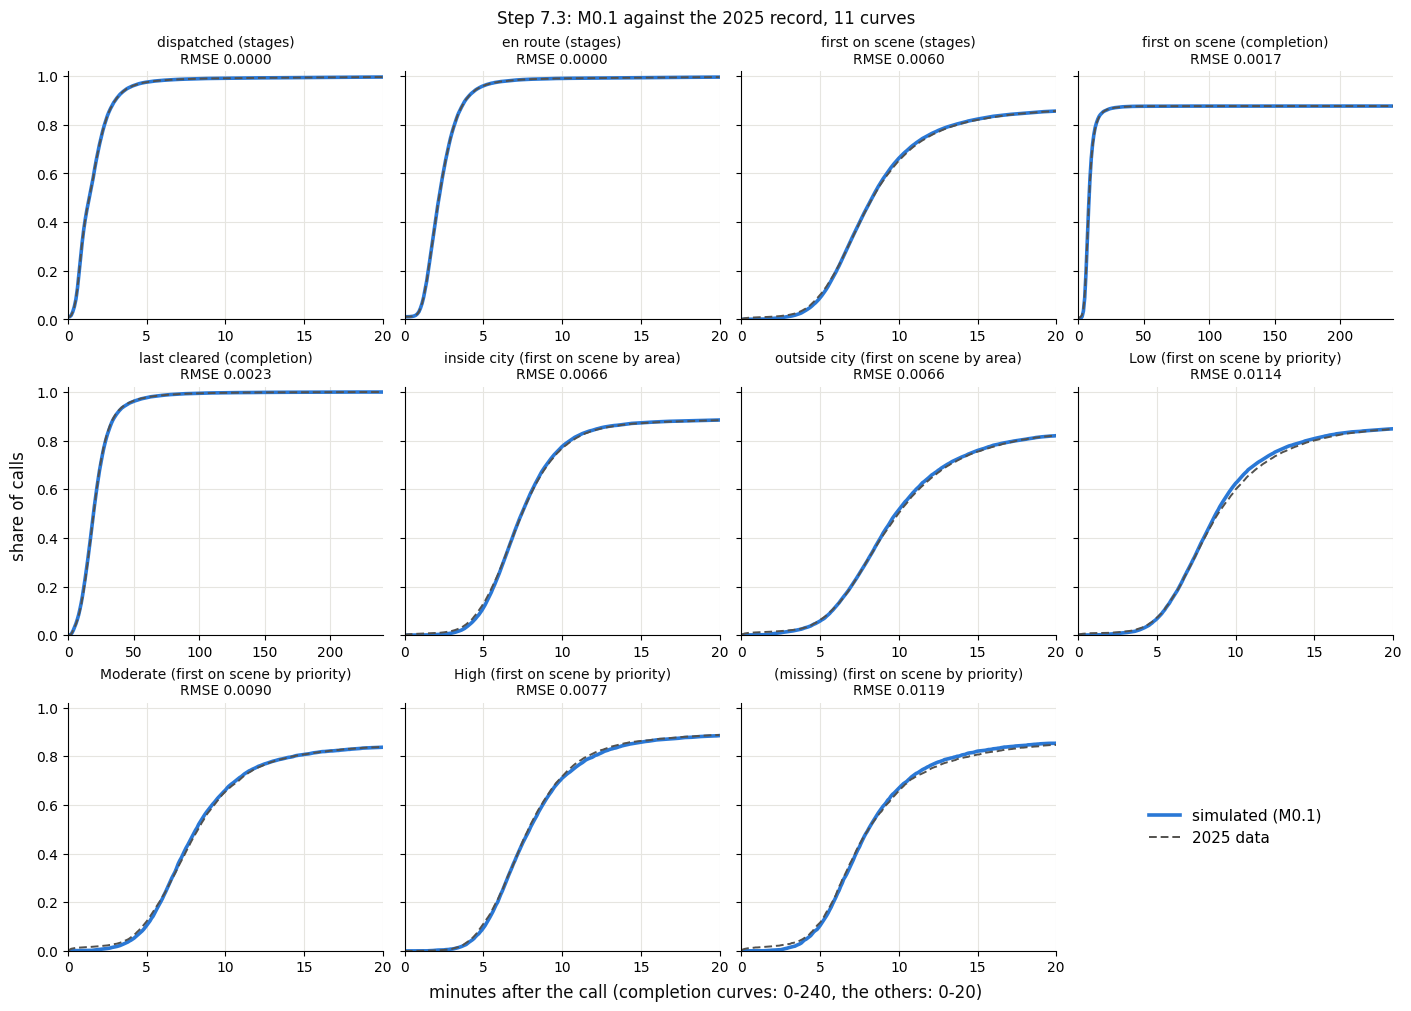

In [76]:
call_inside_city = dispatches["focal"].fillna(False).astype(bool)
m01_report = {}
m01_protocol = simulate(
    m0_runs, available=define_available_engines, engines=engines, estimated_travel=boundary_travel,
    choose=lambda run, available, travel: dispatch_closest_with_spread(run, available, travel, travel_spread,
                                                                       call_inside_city, spread_quantile),
    where_engines_are=lambda row, now, state, travel: travel_while_returning(
        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model,
        fitted_dwell_s, fitted_slowdown),
    wait_rank=wait_rank, report=m01_report, counterfactual=True)
m01_engine_check = compare_engines(runs, m01_protocol, dispatches)
m01_table = simulated_dispatch_table(dispatches, m01_protocol, engines, verbose=False)
m01_curves = response_curves(m01_table, verbose=False)
m01_check = compare_curves(m01_curves, curves_2025)
plot_curves(m01_curves, m01_check, "simulated (M0.1)", "Step 7.3: M0.1 against the 2025 record, 11 curves")

## Step 7.4 — E0 again

**Check.** The same state checks, first-on-scene curve RMSE by stratum, the evaluation matrix with M0.1 added (its
last row is M0.1 minus the 2025 record at P90), and the E0 decision.

In [77]:
m01_states = check_counterfactual_run(runs, m01_protocol, dispatches, m01_report)
m01_strata = compare_curves_by_stratum(m01_table, dispatches)
columns["step 7 (M0.1): + travel spread"] = evaluation_column(
    runs, m01_protocol, dispatches, m01_table, dispatches, m01_check, travel_comparison.loc[chosen_form, "mean |error| min"])
evaluation = evaluation_matrix(columns)
e01_passed = decide_e0(m01_states, m01_strata)

--- E0 state checks
runs never served                                           0.0000
runs whose engine was taken by a newer run                  0.0000
runs sent while their engine was still on an earlier run    0.0000
runs with an arrival in 2025 but none simulated             0.0000
runs with times out of order                                0.0000
runs served without a clear                                 0.0000
runs that kept their 2025 times                             4.0000
runs of calls without a location                            4.0000
cancelled requests that never got an engine                 0.0000
calls whose first arrival is the recorded second (share)    0.0003
runs that waited for an engine                              0.0000
wait seconds: median                                           NaN
wait seconds: max                                              NaN



--- E0 first-on-scene curve, simulated vs 2025, by stratum
                                     calls    rmse  max_abs_difference
all calls                          33156.0  0.0060              0.0119
multi-engine calls                  2941.0  0.0445              0.0813
first engine sent away from home    4823.0  0.0312              0.0784
calls with an other-agency engine   1371.0  0.0371              0.0875

--- evaluation matrix
                                                2025 record  step 2: straight line  step 3: road network  step 4: + agency boundaries  step 5.1: + returning engines  step 5.1b: + AVL-fitted return  step 6 (M0): modeled travel for every run  step 7 (M0.1): + travel spread
travel estimate: test mean |error| (min)                NaN                  1.636                 1.547                        1.547                          1.547                           1.547                                      1.547                           1.547
same engine: all ru

## Step 7.5 — Where the first-on-scene curve sits now

**Check.** Quantiles of call-to-first-arrival minutes for the 2025 record, M0 and M0.1, overall and by area, and the
gap between each simulated curve and the record at every 0.1 minute.

In [78]:
quantiles_m01 = {}
for name, table in [("2025 record", dispatches), ("M0", m0_table), ("M0.1", m01_table)]:
    minutes, focal = first_on_scene_minutes(table)
    for area, mask in [("all calls", pd.Series(True, index=minutes.index)), ("inside city", focal.fillna(False)),
                       ("outside city", ~focal.fillna(True))]:
        quantiles_m01[(area, name)] = minutes[mask].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(2).tolist()
print(pd.DataFrame(quantiles_m01, index=["P10", "P25", "P50", "P75", "P90"]).T.to_string())

record_curve = curves_2025.query("curve == 'stages' and series == 'first_on_scene'").set_index("minute")["share"]
gaps = pd.DataFrame({name: simulated_curves.query("curve == 'stages' and series == 'first_on_scene'").set_index("minute")["share"]
                     - record_curve for name, simulated_curves in [("M0", m0_curves), ("M0.1", m01_curves)]})
print(f"first-on-scene curve minus the 2025 record (share of calls), largest gaps:\n"
      f"{gaps.abs().idxmax().rename('at minute').to_frame().join(gaps.abs().max().rename('largest |gap|')).round(3).to_string()}")
print(f"at 5 and 9.4 minutes:\n{gaps.loc[[5.0, 9.4]].round(3).to_string()}")

                           P10   P25   P50    P75    P90
all calls    2025 record  4.83  6.17  7.83  10.08  13.22
inside city  2025 record  4.58  5.75  7.13   8.78  10.80
outside city 2025 record  5.48  7.12  9.18  11.96  15.65
all calls    M0           5.28  6.30  7.56   9.17  11.41
inside city  M0           5.28  6.19  7.27   8.43   9.77
outside city M0           5.28  6.49  8.24  10.52  13.38
all calls    M0.1         4.99  6.19  7.80   9.94  13.00
inside city  M0.1         4.76  5.81  7.10   8.70  10.63
outside city M0.1         5.55  7.11  9.07  11.76  15.42
first-on-scene curve minus the 2025 record (share of calls), largest gaps:
      at minute  largest |gap|
M0          9.4          0.074
M0.1        4.9          0.012
at 5 and 9.4 minutes:
           M0   M0.1
minute              
5.0    -0.040 -0.012
9.4     0.074  0.010


## Step 7.6 — Where the remaining error is: multi-engine calls and fire calls

**Check.** In a multi-engine call, a run's fate (arrives or is cancelled) comes with its row of the record, while the
engine is chosen again in dispatch order. When the first-dispatched run was cancelled in 2025, the simulation gives the
closest engine to that run, and the call is reached by a farther engine. Split by that, and fire calls by single- and
multi-engine.

In [79]:
def first_on_scene_rmse(minutes_simulated, minutes_2025):
    """RMSE between two first-on-scene curves on the 0-20 min grid, as compare_curves computes it (share of the group's
    calls; calls never reached stay in the denominator).

    Example: first_on_scene_rmse(first_on_scene_minutes(m01_table)[0], first_on_scene_minutes(dispatches)[0]) -> 0.006
    """
    shares = [np.searchsorted(np.sort(minutes.dropna().to_numpy()), RESPONSE_GRID_MINUTES, side="right") / len(minutes)
              for minutes in (minutes_simulated, minutes_2025)]
    return float(np.sqrt(np.mean((shares[0] - shares[1]) ** 2)))


minutes_2025, _ = first_on_scene_minutes(dispatches)
minutes_m01, _ = first_on_scene_minutes(m01_table)
multi_runs = dispatches[dispatches["n_engines_sent"] > 1].sort_values(["incident_id", "dispatched_at"])
first_run = multi_runs.groupby("incident_id").head(1).set_index("incident_id")
first_cancelled = first_run["arrived_at"].isna()
call_type = dispatches.groupby("incident_id")["call_type"].first()
multi_engine_call = dispatches.groupby("incident_id")["n_engines_sent"].first() > 1
groups = {"all calls": minutes_2025.index,
          "multi-engine, first-dispatched run arrived in 2025": first_run.index[~first_cancelled],
          "multi-engine, first-dispatched run cancelled in 2025": first_run.index[first_cancelled],
          "fire calls (call type Fire)": call_type.index[call_type == "Fire"],
          "fire calls, single-engine": call_type.index[(call_type == "Fire") & ~multi_engine_call],
          "fire calls, multi-engine": call_type.index[(call_type == "Fire") & multi_engine_call]}
print(f"multi-engine calls whose first-dispatched run was cancelled in 2025: {first_cancelled.mean():.1%} of {len(first_run):,}; "
      f"call types: {call_type[first_run.index[first_cancelled]].value_counts().to_dict()}")
print(pd.DataFrame({name: {"calls": len(ids), "RMSE M0.1": first_on_scene_rmse(minutes_m01[ids], minutes_2025[ids]),
                           "P50 2025": minutes_2025[ids].median(), "P50 M0.1": minutes_m01[ids].median(),
                           "P90 2025": minutes_2025[ids].quantile(0.9), "P90 M0.1": minutes_m01[ids].quantile(0.9)}
                    for name, ids in groups.items()}).T.round(3).to_string())

multi-engine calls whose first-dispatched run was cancelled in 2025: 43.8% of 2,941; call types: {'Fire': 738, 'Medical': 417, 'Rescue': 61, 'Other': 57, 'Special Hazard': 11}
                                                        calls  RMSE M0.1  P50 2025  P50 M0.1  P90 2025  P90 M0.1
all calls                                             33156.0      0.006     7.833     7.805    13.217    13.004
multi-engine, first-dispatched run arrived in 2025     1653.0      0.014     7.783     7.663    13.143    12.695
multi-engine, first-dispatched run cancelled in 2025   1288.0      0.114     8.650    11.102    15.617    19.512
fire calls (call type Fire)                            6742.0      0.009     8.217     8.217    14.150    13.787
fire calls, single-engine                              4595.0      0.023     8.333     8.158    14.483    13.236
fire calls, multi-engine                               2147.0      0.034     7.917     8.404    13.527    14.746


## Section 7 evidence

- **Sections 1–6 are unchanged.** All 37 output files written before M0.1, the `m0_*` files included, are byte-identical
  after the full run.
- **The spread is calibrated on held-out months.**
  - Fitting and test sets: fitted on 19,349 runs that left from home (Oct–Jun) and tested on 6,410 runs (Jul–Sep). The
    test runs are held out from the ratios, although Section 3 chose the travel model's form on their errors.
  - Test travel quantiles, P10/P50/P90 in minutes: recorded 2.97/5.45/10.15; modeled 3.32/5.26/8.29; modeled × drawn
    ratio 3.00/5.42/9.93.
  - Calibration: recorded travel falls below the predicted P10 in 9.5% of test runs and above the predicted P90 in
    10.7%. By area, inside the city 9.5%/10.9% and outside 9.4%/10.4%. Per bin, both shares lie between 6% and 16%.
- **E0 passes.**
  - First-on-scene curve RMSE is 0.0060 (limit 0.03; M0 had 0.0377). It is 0.0066 inside the city and 0.0066 outside;
    the largest of the 11 curves is 0.012.
  - Median first arrival is 7.81 min (2025: 7.83) and P90 is 13.00 min (2025: 13.22).
  - The same state checks are all 0. Only the 4 runs of calls without a location keep their 2025 times, and no run
    waited.
  - For scale, the 2025 curve itself moves by 0.005 between Oct–Jun and Jul–Sep.
- **Remaining error.** These strata are diagnostics, not part of the E0 rule.
  - RMSE is 0.045 for multi-engine calls, 0.031 for calls whose first engine was sent away from home, and 0.037 for
    calls with an other-agency engine. The simulation is slower in all three.
  - Step 7.6: in 43.8% of multi-engine calls, the first-dispatched run was cancelled in 2025. Of these 1,288 calls, 738
    are fire calls. In them the simulation sends the closest engine to the run that is cancelled, and a farther engine
    reaches the call: RMSE 0.114, median 11.10 min against 8.65 recorded. In the other multi-engine calls RMSE is
    0.014.
  - Fire calls overall have RMSE 0.009, but two errors offset each other. Single-engine fire calls arrive earlier than
    recorded (P90 13.24 against 14.48 min), and multi-engine fire calls arrive later (P90 14.75 against 13.53).
- **Next (to decide).**
  - Fix how runs are matched to engines in multi-engine calls.
  - Before interpreting Step 3 policy effects, validate the fire objective and the medical constraint across these
    conditions and across repeated travel seeds.

# Section 8 — What the functions do, printed; and M0.2: the call decides which engines arrive

Two things. First, every new function now prints what it did on concrete cases, so each can be checked against what we
believe: where each engine was when it was sent (at its station, or a point on its drive home), the travel drawn for
it, and which runs of a call arrived. Second, M0.2 fixes how runs are matched to engines in multi-engine calls. Under
M0.1 a run's fate (arrived or cancelled) came with its row of the record while the engine was chosen again in dispatch
order; in 43.8% of 2025 multi-engine calls the first-dispatched run was cancelled, so the closest engine went to a run
that is cancelled and a farther engine reached the call (Step 7.6). Under M0.2 the call keeps its recorded number of
arrivals and its recorded cancellation moments; the first engines to reach the scene arrive, and at each cancellation
moment the call releases the engine that would arrive last. The dispatcher still sends the closest engine and knows
nothing about future cancellations.

**Input/output check before running (gpt-6-astra, read-only).** PASS: the seven implementation choices match the design;
the six small cases and the first-month demo reproduce exactly; the first-month M0.1 runs equal the saved full-year run.

## Step 8.1 — Shared functions: `share_of_way_home`, `travel_while_returning`, `simulate`, `call_fates`

**Change.** `share_of_way_home` is the placement `travel_while_returning` used inline, now on its own so the prints place
engines exactly as the simulation does. `simulate` logs every dispatch (run, time, engine, its last clear, modeled
travel from where it was, travel taken) and, with `fates_by_arrival`, runs multi-run calls by call-level fates.
`call_fates` returns, per multi-run call, the recorded number of arrivals, cancellation moments and on-scene times.
**Check.** M0.1 rerun with the new functions equals Section 7's run.

In [80]:
def share_of_way_home(engine_id, last_clear, now, call_nodes, home_nodes, seconds_from_node, node_position, travel_model,
                      dwell_s=0.0, slowdown=1.0):
    """Where an engine is at `now`, from its last clear in the simulation's engine_state: (share of the way home done,
    network seconds from the scene it left to every node) while it drives home, else (None, None): it is at its station
    because it has not run yet, its last run left no scene, it cleared RETURN_CHECK_SECONDS or more ago, that scene has no
    location, or it is home already. last_clear is (clear s, scene run) after a call it reached: the share is
    return_progress(elapsed, drive home, dwell_s, slowdown); or (clear s, scene run, f) after a cancelled run f of the way
    out (M0): it drives back without dwelling, so the share is 1 - f x (1 - its progress back).

    Example: an engine that cleared 300 s ago from a scene 600 s (calibrated) from home, slowdown 1.18, no dwell:
             share_of_way_home(engine, (cleared_s, scene_run), cleared_s + 300, ...)[0] -> 0.42  # 300 / (1.18 x 600)
             share_of_way_home(engine, None, now, ...) -> (None, None)  # has not run yet: at its station
    """
    if last_clear is None:
        return None, None
    cleared_s, scene_row, *outbound = last_clear
    elapsed = now - cleared_s
    if scene_row is None or elapsed >= RETURN_CHECK_SECONDS:
        return None, None
    scene_node = call_nodes.at[scene_row, "node"]
    if pd.isna(scene_node):
        return None, None
    from_scene = seconds_from_node(int(scene_node))
    drive_home = float(travel_model(from_scene[node_position[home_nodes[engine_id]]], np.nan))
    if outbound:                                                 # M0: released from a cancelled run, f of the way out
        progress_back = return_progress(elapsed, outbound[0] * drive_home, 0.0, slowdown)
        share_home = None if progress_back is None else 1 - outbound[0] * (1 - progress_back)
    else:
        share_home = return_progress(elapsed, drive_home, dwell_s, slowdown)
    return (None, None) if share_home is None else (share_home, from_scene)


def travel_while_returning(row, now, engine_state, travel_for_run, call_nodes, home_nodes, seconds_from_node, node_position,
                           travel_model, dwell_s=0.0, slowdown=1.0):
    """Cases 2 and 3: travel to this run's call for engines still driving home from their last call. An engine that
    cleared t seconds ago from scene S is a share p = return_progress(t, R, dwell_s, slowdown) of the way home, R being
    the calibrated drive S -> home; its travel is (1 - p) x travel(S -> call) + p x travel(home -> call). Other engines
    keep the travel from home. The travel model must be the linear one, which uses network seconds only.
    Section 6 (M0) also stores engines released from a cancelled run as (release, run, f): they were f of the way from
    home to that call and drive back from there without dwelling, so p = 1 - f x (1 - their progress back).

    Example: travel_while_returning(row, now, engine_state, network_travel.loc[row], call_nodes, home_nodes, seconds_from_node,
                                    node_position, network_travel_model)["E3"] -> 512.0 (seconds), roughly
    """
    call_node = call_nodes.at[row, "node"]
    if pd.isna(call_node):
        return travel_for_run
    adjusted = travel_for_run.copy()
    for engine_id, last_clear in engine_state.items():
        if pd.isna(adjusted.get(engine_id)):
            continue
        share_home, from_scene = share_of_way_home(engine_id, last_clear, now, call_nodes, home_nodes, seconds_from_node,
                                                   node_position, travel_model, dwell_s, slowdown)
        if share_home is None:
            continue
        from_scene_to_call = float(travel_model(from_scene[node_position[int(call_node)]], np.nan))
        adjusted[engine_id] = (1 - share_home) * from_scene_to_call + share_home * travel_for_run[engine_id]
    return adjusted


def simulate(runs, available=all_engines_available, choose=dispatched_in_2025, engines=None, estimated_travel=None,
             where_engines_are=None, wait_rank=None, report=None, counterfactual=False, fates_by_arrival=None,
             verbose=VERBOSE):
    """Replay every call in SimPy; returns per run the simulated CAD times (seconds since day zero) and the engine used.

    Each engine is a one-crew simpy.PreemptiveResource. When a run starts (its first recorded time), `available`
    lists the engines CAD may send and `choose` picks one with a travel time (None keeps the recorded times). The run
    then passes its times in time order (two 2025 runs have them out of order). A newer run may take an engine that is
    still on an older run, as when a returning crew picks up a new call (three 2025 runs); the older run keeps its times.
    The defaults (every engine available, the 2025 engine goes) replay the 2025 log.
    Each engine's last clear (time, and the run whose scene it left; None for a cancelled run) is kept in engine_state;
    where_engines_are, if given, turns the travel table's row into travel from where the engines are now.
    If `choose` returns no engine (None), the run waits and never takes a busy engine: each clear offers the engines to
    the waiting runs in order of wait_rank (lower first; all equal if None), then of waiting time, and a run that gets
    an engine moves all its times by its wait. A new run looks for an engine after the clears of its second, except a
    run with a negative wait_rank (Section 13's scheduled outage), which looks before them, so a clear in its first
    second hands the engine to it ahead of every waiting call. counterfactual=True (M0) adds two rules: a request cancelled in the
    record stops waiting at its recorded release and gets no engine, and an engine released from a cancelled run it
    was driving to turns home from where it was (a share of the way to that call, kept in engine_state for
    where_engines_are).
    fates_by_arrival (M0.2; from call_fates): in the calls it lists (two or more runs), the call, not the record's row,
    decides which runs arrive. Each run is sent at its recorded moment with the chosen engine and its recorded turnout.
    The first engines to reach the scene arrive, up to the call's recorded number of arrivals, and take the recorded
    on-scene times in order. At each recorded cancellation moment the call releases one run: one still waiting for an
    engine, else the engine under way that would arrive last, else (none under way) its next run is not sent. An engine
    that reaches the scene after the call has its arrivals is released there.
    `report`, if a dict, receives the rows that kept their recorded times (kept_recorded), the waits (waited_seconds:
    row -> seconds), the rows whose engine a newer run took (taken_by_newer_run), the rows still waiting at the end
    (never_served), the cancelled requests that never got an engine (cancelled_while_waiting), and every dispatch
    (dispatches: run, time, engine, the engine's last clear in engine_state, its modeled travel from where it was, the
    travel it takes).

    Example: simulate(runs).loc[0].tolist() -> [6796.0, 6858.0, 7255.0, 7404.0, 'E62']  # 4 CAD times, engine
    """
    env = simpy.Environment()
    engine_ids = runs["engine_id"].unique() if engines is None else engines["engine_id"]   # every engine CAD could send
    engine_pool = {engine_id: simpy.PreemptiveResource(env, capacity=1) for engine_id in engine_ids}
    engine_state = {}                                            # engine id -> (last clear, seconds; run left, or None)
    simulated = pd.DataFrame(np.nan, index=runs.index, columns=TIME_COLUMNS)
    simulated["engine_id"] = pd.Series(index=runs.index, dtype="object")
    waiting = []                                                 # runs with no engine yet: (rank, since, row, wake-up event)
    kept_recorded, waited_seconds, taken_by_newer_run_rows, cancelled_while_waiting, dispatch_log = [], {}, [], [], []

    def pick(row):
        travel_for_run = None if estimated_travel is None else estimated_travel.loc[row]   # every engine -> this call, seconds
        if where_engines_are is not None:
            travel_for_run = where_engines_are(row, env.now, engine_state, travel_for_run)
        engine_id, travel_seconds = choose(runs.loc[row], available(engine_pool, env.now, engines), travel_for_run)
        if report is not None and engine_id is not None:         # callers send a chosen engine at once
            dispatch_log.append((row, env.now, engine_id, engine_state.get(engine_id),
                                 np.nan if travel_for_run is None else travel_for_run.get(engine_id, np.nan), travel_seconds))
        return engine_id, travel_seconds

    def serve_waiting():
        # ponytail: waiting runs are offered engines only at clears; an engine entering service mid-wait waits for the next clear
        for item in sorted(waiting, key=lambda item: item[:2]):
            engine_id, travel_seconds = pick(item[2])
            if engine_id is not None:
                waiting.remove(item)                             # the request is granted now, so the next run sees the engine busy
                item[3].succeed((engine_id, travel_seconds, engine_pool[engine_id].request(priority=-env.now)))

    def engine_run(row):
        times = runs.loc[row, TIME_COLUMNS]
        start = times.dropna().min()
        if wait_rank is None or wait_rank[row] >= 0:
            yield env.timeout(start - env.now)
            yield env.timeout(0)                                 # runs clearing in this same second free their engines first
        elif start > env.now:                                    # a scheduled outage (negative rank) starts when its call does, so it
            yield env.timeout(start - env.now)                   # looks at once: a new process runs before this second's clears
        engine_id, travel_seconds = pick(row)
        request = None
        if engine_id is None:                                    # no engine to send: wait for a clear
            wake = env.event()
            item = (0 if wait_rank is None else wait_rank[row], env.now, row, wake)
            waiting.append(item)
            cancelled = counterfactual and pd.isna(times["arrived_at"])   # M0: its release time is exogenous
            if cancelled:                                        # it stops waiting at its recorded release
                yield wake | env.timeout(max(0.0, times["cleared_at"] - env.now))
                if not wake.triggered:
                    waiting.remove(item)
                    cancelled_while_waiting.append(row)
                    simulated.at[row, "cleared_at"] = env.now    # the request ends here, with no engine
                    return
            engine_id, travel_seconds, request = yield wake
            waited_seconds[row] = env.now - start
            release = times["cleared_at"]
            times = times + waited_seconds[row]                  # the run starts when it gets its engine
            if cancelled:                                        # ...but a cancelled run still ends at its recorded release
                times["cleared_at"] = release
                if times["enroute_at"] > release:
                    times["enroute_at"] = np.nan
        if travel_seconds is None:
            kept_recorded.append(row)
        recorded = (times if travel_seconds is None else shift_arrival(times, travel_seconds)).dropna().sort_values()
        simulated.at[row, "engine_id"] = engine_id
        taken_by_newer_run = False
        if request is None:
            request = engine_pool[engine_id].request(priority=-recorded.iloc[0])   # newer run ranks first
        with request as engine:
            yield engine
            for column, at in recorded.items():
                try:
                    yield env.timeout(at - env.now)
                except simpy.Interrupt:                                  # engine taken by a newer run
                    taken_by_newer_run = True
                    yield env.timeout(at - env.now)
                simulated.at[row, column] = env.now
        enroute_s = simulated.at[row, "enroute_at"]
        if taken_by_newer_run:
            taken_by_newer_run_rows.append(row)
        elif counterfactual and "arrived_at" not in recorded.index and travel_seconds and not pd.isna(enroute_s):
            # ponytail: the share of the way out assumes the engine left from home; one that left another scene is placed on its home -> call line
            outbound_share = min(1.0, max(0.0, (env.now - enroute_s) / travel_seconds))
            engine_state[engine_id] = (env.now, row, outbound_share) if outbound_share > 0 else (env.now, None)
        else:
            engine_state[engine_id] = (env.now, row if "arrived_at" in recorded.index else None)
        serve_waiting()

    def call_run(row, call_state, under_way):
        # M0.2: one run of a call whose fates are decided by the call (fates_by_arrival), not by this row of the record
        times = runs.loc[row, TIME_COLUMNS]
        yield env.timeout(times["dispatched_at"] - env.now)
        yield env.timeout(0)                                     # runs clearing in this same second free their engines first
        if call_state["releases_pending"]:                       # a release found no run under way: this run is not sent
            call_state["releases_pending"] -= 1
            cancelled_while_waiting.append(row)
            simulated.loc[row, ["dispatched_at", "cleared_at"]] = env.now
            return
        engine_id, travel_seconds = pick(row)
        request = None
        if engine_id is None:                                    # no engine to send: wait; the call may release the wait
            wake = env.event()
            waiting.append((0 if wait_rank is None else wait_rank[row], env.now, row, wake))
            granted = yield wake
            if granted is None:
                cancelled_while_waiting.append(row)
                simulated.loc[row, ["dispatched_at", "cleared_at"]] = [times["dispatched_at"], env.now]
                return
            engine_id, travel_seconds, request = granted
            waited_seconds[row] = env.now - times["dispatched_at"]
        turnout_s = times["enroute_at"] - times["dispatched_at"]
        simulated.at[row, "engine_id"] = engine_id
        with (request or engine_pool[engine_id].request(priority=-env.now)) as engine:
            yield engine
            simulated.at[row, "dispatched_at"] = env.now
            arrival_s = env.now + turnout_s + travel_seconds
            under_way[row] = (arrival_s, env.active_process)
            try:
                yield env.timeout(turnout_s)
                simulated.at[row, "enroute_at"] = env.now
                yield env.timeout(arrival_s - env.now)
            except simpy.Interrupt as interrupt:                 # released by the call at a recorded cancellation moment
                assert interrupt.cause == "released by the call", interrupt.cause
                enroute_s = simulated.at[row, "enroute_at"]
                outbound_share = 0.0 if pd.isna(enroute_s) else min(1.0, (env.now - enroute_s) / travel_seconds)
                engine_state[engine_id] = (env.now, row, outbound_share) if outbound_share > 0 else (env.now, None)
            else:
                under_way.pop(row, None)
                if call_state["arrived"] < call_state["arrivals"]:   # the call still needs an engine on scene
                    simulated.at[row, "arrived_at"] = env.now
                    on_scene_s = call_state["on_scene_s"][call_state["arrived"]]
                    call_state["arrived"] += 1
                    yield env.timeout(on_scene_s)
                    engine_state[engine_id] = (env.now, row)
                else:                                            # the call has its arrivals: released at the scene
                    engine_state[engine_id] = (env.now, row, 1.0)
            simulated.at[row, "cleared_at"] = env.now
        serve_waiting()

    def release_extra_runs(incident, call_state, under_way):
        # M0.2: at each recorded cancellation moment the call releases one run: one still waiting for an engine, else the
        # engine under way that would arrive last, else (none under way) its next run is not sent
        for moment in call_state["release_moments"]:
            yield env.timeout(max(0.0, moment - env.now))
            queued = [item for item in waiting if runs.at[item[2], "incident_id"] == incident]
            if queued:
                waiting.remove(queued[-1])
                queued[-1][3].succeed(None)
            elif under_way:
                last = max(under_way, key=lambda row: under_way[row][0])
                under_way.pop(last)[1].interrupt("released by the call")
            else:
                call_state["releases_pending"] += 1

    def call(call_runs):
        yield env.timeout(runs.at[call_runs[0], "call_received_at"] - env.now)
        incident = runs.at[call_runs[0], "incident_id"]
        if fates_by_arrival is not None and incident in fates_by_arrival:
            arrivals, release_moments, on_scene_s = fates_by_arrival[incident]
            call_state = {"arrivals": arrivals, "release_moments": release_moments, "on_scene_s": on_scene_s,
                          "arrived": 0, "releases_pending": 0}
            under_way = {}                                       # run -> (when its engine would arrive, its process)
            env.process(release_extra_runs(incident, call_state, under_way))
            for row in choose_engines(call_runs):
                env.process(call_run(row, call_state, under_way))
            return
        for row in choose_engines(call_runs):
            env.process(engine_run(row))

    for call_runs in runs.groupby("incident_id", sort=False).groups.values():
        env.process(call(list(call_runs)))
    env.run()
    show_table("simulated CAD times (seconds since day zero) and engine used", simulated, verbose)
    if report is not None:
        report.update(kept_recorded=kept_recorded, waited_seconds=waited_seconds, taken_by_newer_run=taken_by_newer_run_rows,
                      never_served=[item[2] for item in waiting], cancelled_while_waiting=cancelled_while_waiting,
                      dispatches=pd.DataFrame(dispatch_log, columns=["run", "time_s", "engine_id", "last_clear", "modeled_s",
                                                                     "travel_s"]))
    return simulated


def call_fates(runs):
    """M0.2: what the record fixes for each call with two or more runs: how many of its runs arrived, the moments its
    other runs were released (their clears, sorted), and the on-scene seconds of the runs that arrived, in arrival order.

    Example: call_fates(m0_runs)["100124-0344"] -> (1, [38904.0], [121.0])  # 1 arrival; 1 release at 38,904 s; 121 s on scene
             len(call_fates(m0_runs)) -> 2941
    """
    fates = {}
    for incident, call in runs.groupby("incident_id"):
        if len(call) < 2:
            continue
        arrived = call[call["arrived_at"].notna()].sort_values("arrived_at")
        fates[incident] = (len(arrived), sorted(call.loc[call["arrived_at"].isna(), "cleared_at"].tolist()),
                           (arrived["cleared_at"] - arrived["arrived_at"]).tolist())
    return fates


m01_report = {}
m01_again = simulate(
    m0_runs, available=define_available_engines, engines=engines, estimated_travel=boundary_travel,
    choose=lambda run, available, travel: dispatch_closest_with_spread(run, available, travel, travel_spread,
                                                                       call_inside_city, spread_quantile),
    where_engines_are=lambda row, now, state, travel: travel_while_returning(
        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model,
        fitted_dwell_s, fitted_slowdown),
    wait_rank=wait_rank, report=m01_report, counterfactual=True, verbose=False)
print("M0.1 rerun with the new functions, runs with any time or engine different from Section 7:",
      compare_times(m01_protocol, m01_again, verbose=False))
show_table("dispatch log of the M0.1 run (report['dispatches'])", m01_report["dispatches"])

M0.1 rerun with the new functions, runs with any time or engine different from Section 7: 0
--- dispatch log of the M0.1 run (report['dispatches']) (37194, 6)
     run  time_s engine_id                  last_clear   modeled_s    travel_s
0  16205   427.0        Q9                        None  337.153498  271.655825
1  16206  2734.0        Q9  (2227.655825088681, 16205)  332.950284  378.749501
2  16207  5898.0        E3                        None  235.619442  172.249546
3  16208  6128.0        Q9  (4154.749500694979, 16206)  242.630456  257.232554
4      0  6796.0       E62                        None  257.054336  392.514401



## Step 8.2 — What M0.1 did: where engines were when sent, and the travel drawn for them

**Check.** Positions: counts beside the 2025 AVL record, the share of the way home by minutes since clearing (it should
rise with time), examples of each kind, and three checks. Travel: five dispatches (taken = modeled x ratio) and the
drawn ratios per bin beside the fitted ones (they should match).

In [81]:
def describe_engine_origins(dispatch_log, dispatches, estimated_travel, call_nodes, home_nodes, seconds_from_node,
                            node_position, travel_model, dwell_s=0.0, slowdown=1.0, verbose=VERBOSE):
    """Where each engine was when the simulation sent it, from its dispatch log (report["dispatches"]): at its station,
    driving home from a call it reached, or driving home after a cancelled run, placed by share_of_way_home exactly as
    the simulation placed it. Per dispatch: minutes since the engine cleared, share of the way home done, its modeled
    travel from where it was, the travel it took, and the travel from home (estimated_travel), in minutes.
    Prints the counts beside the 2025 record (AVL position at assignment), the share of the way home by minutes since
    clearing, three examples of each kind, and three checks: every share is in [0, 1); nobody counts as on the way home
    RETURN_CHECK_SECONDS or more after clearing; every engine counted at its station got the travel from home.

    Example: describe_engine_origins(m01_report["dispatches"], dispatches, boundary_travel, call_nodes, ...)["origin"]
             .value_counts() -> at station / driving home from a call / driving home after a cancelled run (counts)
    """
    records = []
    for run, time_s, engine_id, last_clear, modeled_s, travel_s in dispatch_log.itertuples(index=False):
        share_home, _ = share_of_way_home(engine_id, last_clear, time_s, call_nodes, home_nodes, seconds_from_node,
                                          node_position, travel_model, dwell_s, slowdown)
        origin = ("at station" if share_home is None else
                  "driving home from a call" if len(last_clear) == 2 else "driving home after a cancelled run")
        records.append({"run": run, "time": DAY_ZERO + pd.Timedelta(seconds=time_s), "engine_id": engine_id, "origin": origin,
                        "minutes since clear": np.nan if last_clear is None else (time_s - last_clear[0]) / 60,
                        "share of way home": np.nan if share_home is None else share_home,
                        "modeled min": modeled_s / 60, "taken min": np.nan if travel_s is None else travel_s / 60,
                        "from home min": estimated_travel.at[run, engine_id] / 60})
    origins = pd.DataFrame(records)
    if verbose:
        recorded = dispatches["at_home"].astype(bool).map({True: "at its station", False: "away from its station"})
        returning = origins[origins["share of way home"].notna()]
        station = origins[origins["origin"] == "at station"]
        print(f"--- where engines were when the simulation sent them\n"
              f"{origins['origin'].value_counts().to_frame('dispatches').assign(share=lambda t: t['dispatches'] / len(origins)).round(3).to_string()}\n"
              f"2025 record, AVL position at assignment: {recorded.value_counts(normalize=True).round(3).to_dict()}\n"
              f"share of the way home by minutes since clearing (engines on the way home):\n"
              f"{returning.groupby(pd.cut(returning['minutes since clear'], [0, 2, 4, 8, 16, 60]), observed=True)['share of way home'].agg(['size', 'median']).round(2).to_string()}\n")
        for origin, part in origins.groupby("origin"):
            print(f"examples, {origin}:\n{part.head(3).round(2).to_string(index=False)}\n")
        print(f"checks: every share of the way home in [0, 1): {bool(returning['share of way home'].between(0, 1, inclusive='left').all())}; "
              f"longest time counted on the way home {returning['minutes since clear'].max():.1f} min (cut-off "
              f"{RETURN_CHECK_SECONDS / 60:.0f}); engines at their station got the travel from home: "
              f"{bool(np.isclose(station['modeled min'], station['from home min'], equal_nan=True).all())}\n")
    return origins


def describe_travel_draws(origins, spread, inside_city, verbose=VERBOSE):
    """What the travel draw did in a run (M0.1 on): per dispatch (describe_engine_origins), the ratio of the travel taken
    to the modeled travel, with the call's area and the bin of the modeled travel. Prints five examples and, per area
    and bin, the drawn ratios' P10, P50 and P90 beside the fitted ones: they should match, because every run draws its
    own quantile from its bin's fitted ratios.

    Example: describe_travel_draws(m01_origins, travel_spread, call_inside_city).loc[(False, 0), "drawn P50"]
             -> about 1.10, beside fitted P50 1.097
    """
    drawn = origins.dropna(subset=["modeled min", "taken min"]).copy()
    drawn["inside_city"] = inside_city[drawn["run"]].to_numpy()
    drawn["ratio"] = drawn["taken min"] / drawn["modeled min"]
    drawn["bin"] = [int(np.searchsorted(spread[inside][0], minutes * 60, side="left"))   # the bin draw_travel_ratio uses
                    for inside, minutes in zip(drawn["inside_city"], drawn["modeled min"])]
    by_bin = drawn.groupby(["inside_city", "bin"])["ratio"].quantile([0.1, 0.5, 0.9]).unstack()
    by_bin.columns = ["drawn P10", "drawn P50", "drawn P90"]
    fitted = pd.DataFrame({(inside, b): np.quantile(ratios, [0.1, 0.5, 0.9])
                           for inside, (_, ratios_by_bin) in spread.items() for b, ratios in enumerate(ratios_by_bin)},
                          index=["fitted P10", "fitted P50", "fitted P90"]).T.rename_axis(["inside_city", "bin"])
    table = by_bin.join(fitted).assign(dispatches=drawn.groupby(["inside_city", "bin"]).size())
    if verbose:
        print(f"--- travel draws: taken = modeled x ratio\n"
              f"{drawn[['run', 'engine_id', 'origin', 'inside_city', 'bin', 'modeled min', 'ratio', 'taken min']].head(5).round(3).to_string(index=False)}\n"
              f"drawn vs fitted ratios by area and bin of modeled travel:\n{table.round(3).to_string()}\n")
    return table


m01_origins = describe_engine_origins(m01_report["dispatches"], dispatches, boundary_travel, call_nodes, home_nodes,
                                      seconds_from_node, node_position, network_travel_model, fitted_dwell_s, fitted_slowdown)
m01_draws = describe_travel_draws(m01_origins, travel_spread, call_inside_city)

--- where engines were when the simulation sent them
                                    dispatches  share
origin                                               
at station                               35691  0.960
driving home from a call                  1082  0.029
driving home after a cancelled run         421  0.011
2025 record, AVL position at assignment: {'at its station': 0.844, 'away from its station': 0.156}
share of the way home by minutes since clearing (engines on the way home):
                     size  median
minutes since clear              
(0, 2]                594    0.19
(2, 4]                377    0.51
(4, 8]                348    0.78
(8, 16]                69    0.85
(16, 60]                4    0.94

examples, at station:
  run                time engine_id     origin  minutes since clear  share of way home  modeled min  taken min  from home min
16205 2024-10-01 00:07:07        Q9 at station                  NaN                NaN         5.62       4.53      

/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/1322079103.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(f"examples, {origin}:\n{part.head(3).round(2).to_string(index=False)}\n")
/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/1322079103.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(f"examples, {origin}:\n{part.head(3).round(2).to_string(index=False)}\n")
/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/1322079103.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(f"examples, {origin}:\n{part.head(3).round(2).to_string(index=False)}\n")


## Step 8.3 — M0.2 small cases with hand-calculated answers

**Check.** A: both runs sent together, the closest engine arrives and the other is released. B: the cancelled run is sent
first; the release takes the farther engine before it leaves. C: an engine reaching the scene after the call has its
arrivals is released there. D: a release that finds nobody under way cancels the call's next run. E: a release takes a
run still waiting for an engine. F: one-run calls are unchanged.

In [82]:
def small_cases_m02():
    """The M0.2 small cases, inside a function so that they do not overwrite notebook variables."""
    free_engines = lambda pool, now, engines: [engine for engine, resource in pool.items() if resource.count == 0]


    def run_case(name, runs, travel, note):
        """Simulate one small case with call-level fates; print input, output and the report; return both."""
        report = {}
        fates = call_fates(runs)
        out = simulate(runs, available=free_engines, choose=dispatch_closest, estimated_travel=travel, report=report,
                           engines=pd.DataFrame({"engine_id": list(travel.columns)}), counterfactual=True,
                           fates_by_arrival=fates, verbose=False)   # the engines that can go are the travel table's
        record = np.where(runs["arrived_at"].notna(), "arrived", "cancelled")
        print(f"=== {name}: {note}\ninput runs (seconds):\n{runs.to_string()}\ntravel from home (s):\n{travel.to_string()}\n"
              f"call fates (arrivals, release moments, on-scene s): {fates}\n"
              f"simulated:\n{out.assign(record=record).to_string()}\n"
              f"cancelled with no engine: {report['cancelled_while_waiting']}; waits: {report['waited_seconds']}\n")
        return out, report


    def call_runs(incident, rows):
        """Runs of one call: rows of (engine in 2025, dispatched, en route, arrived or nan, cleared)."""
        frame = pd.DataFrame(rows, columns=["engine_id", "dispatched_at", "enroute_at", "arrived_at", "cleared_at"])
        return frame.assign(incident_id=incident, call_received_at=frame["dispatched_at"].min())[
            ["incident_id", "engine_id", "call_received_at"] + TIME_COLUMNS]


    # A. both runs sent at 0 s; the record cancelled the first at 270 s. M0.1 would give the closest engine (E1) to that run.
    runs_a = call_runs("A", [("E5", 0.0, 60.0, np.nan, 270.0), ("E6", 0.0, 60.0, 400.0, 1000.0)])
    travel_a = pd.DataFrame({"E1": [200.0, 200.0], "E2": [400.0, 400.0]})
    out_a, _ = run_case("A", runs_a, travel_a, "E1 reaches the scene at 260 s and arrives; at 270 s the call releases E2")
    assert np.allclose(out_a[TIME_COLUMNS].to_numpy(float), [[0, 60, 260, 860], [0, 60, np.nan, 270]], equal_nan=True)
    assert out_a["engine_id"].tolist() == ["E1", "E2"]

    # B. the cancelled run is sent first (0 s, released 100 s); the run that arrives is sent at 60 s, when E1 is busy.
    runs_b = call_runs("B", [("E5", 0.0, 60.0, np.nan, 100.0), ("E6", 60.0, 120.0, 600.0, 1100.0)])
    travel_b = pd.DataFrame({"E1": [200.0, 200.0], "E2": [400.0, 400.0]})
    out_b, _ = run_case("B", runs_b, travel_b, "at 100 s E2 (would arrive 520 s) is released before it leaves; E1 arrives 260 s")
    assert np.allclose(out_b[TIME_COLUMNS].to_numpy(float), [[0, 60, 260, 760], [60, np.nan, np.nan, 100]], equal_nan=True)

    # C. one arrival needed; E2 reaches the scene after E1 arrived: it is released there; the 700 s release finds nobody.
    runs_c = call_runs("C", [("E5", 0.0, 60.0, 300.0, 900.0), ("E6", 0.0, 60.0, np.nan, 700.0)])
    travel_c = pd.DataFrame({"E1": [200.0, 200.0], "E2": [300.0, 300.0]})
    out_c, _ = run_case("C", runs_c, travel_c, "E1 arrives 260 s; E2 is released at the scene at 360 s")
    assert np.allclose(out_c[TIME_COLUMNS].to_numpy(float), [[0, 60, 260, 860], [0, 60, np.nan, 360]], equal_nan=True)

    # D. two arrivals needed; both engines arrive before the 400 s release, which then cancels the run sent at 1,000 s.
    runs_d = call_runs("D", [("E5", 0.0, 60.0, 300.0, 900.0), ("E6", 0.0, 60.0, np.nan, 400.0),
                             ("E7", 1000.0, 1060.0, 1300.0, 1500.0)])
    travel_d = pd.DataFrame({"E1": [200.0] * 3, "E2": [250.0] * 3, "E3": [500.0] * 3})
    out_d, report_d = run_case("D", runs_d, travel_d, "E1 arrives 260 s (600 s on scene), E2 310 s (200 s); run 2 is not sent")
    assert np.allclose(out_d[TIME_COLUMNS].to_numpy(float), [[0, 60, 260, 860], [0, 60, 310, 510], [1000, np.nan, np.nan, 1000]],
                       equal_nan=True)
    assert report_d["cancelled_while_waiting"] == [2] and pd.isna(out_d.at[2, "engine_id"])

    # E. one engine, busy on call Z until 1,000 s; both runs of call E wait; the 200 s release takes the later waiting run.
    runs_e = pd.concat([call_runs("Z", [("E1", 0.0, 10.0, 100.0, 1000.0)]),
                        call_runs("E", [("E5", 100.0, 150.0, 400.0, 700.0), ("E6", 100.0, 150.0, np.nan, 200.0)])],
                       ignore_index=True)
    travel_e = pd.DataFrame({"E1": [90.0, 240.0, 240.0]})
    out_e, report_e = run_case("E", runs_e, travel_e, "run 2 is released while waiting; run 1 gets E1 at 1,000 s, arrives 1,290 s")
    assert np.allclose(out_e[TIME_COLUMNS].to_numpy(float),
                       [[0, 10, 100, 1000], [1000, 1050, 1290, 1590], [100, np.nan, np.nan, 200]], equal_nan=True)
    assert report_e["cancelled_while_waiting"] == [2] and report_e["waited_seconds"] == {1: 900.0}

    # F. calls with one run are untouched by call_fates: same times with and without it.
    runs_f = pd.concat([call_runs("F", [("E1", 0.0, 60.0, 300.0, 900.0)]), call_runs("G", [("E2", 50.0, 90.0, np.nan, 200.0)])],
                       ignore_index=True)
    travel_f = pd.DataFrame({"E1": [200.0, 200.0], "E2": [300.0, 300.0]})
    with_fates = simulate(runs_f, available=free_engines, choose=dispatch_closest, estimated_travel=travel_f,
                              counterfactual=True, fates_by_arrival=call_fates(runs_f), verbose=False)
    without = simulate(runs_f, available=free_engines, choose=dispatch_closest, estimated_travel=travel_f,
                           counterfactual=True, verbose=False)
    assert call_fates(runs_f) == {} and with_fates.equals(without)
    print("=== F: one-run calls give the same times with and without call fates\n")
    print("all M0.2 small cases passed")


small_cases_m02()

=== A: E1 reaches the scene at 260 s and arrives; at 270 s the call releases E2
input runs (seconds):
  incident_id engine_id  call_received_at  dispatched_at  enroute_at  arrived_at  cleared_at
0           A        E5               0.0            0.0        60.0         NaN       270.0
1           A        E6               0.0            0.0        60.0       400.0      1000.0
travel from home (s):
      E1     E2
0  200.0  400.0
1  200.0  400.0
call fates (arrivals, release moments, on-scene s): {'A': (1, [270.0], [600.0])}
simulated:
   dispatched_at  enroute_at  arrived_at  cleared_at engine_id     record
0            0.0        60.0       260.0       860.0        E1  cancelled
1            0.0        60.0         NaN       270.0        E2    arrived
cancelled with no engine: []; waits: {}

=== B: at 100 s E2 (would arrive 520 s) is released before it leaves; E1 arrives 260 s
input runs (seconds):
  incident_id engine_id  call_received_at  dispatched_at  enroute_at  arrived_at  cle

## Step 8.4 — The full year under M0.2

**Change.** The Step 7.3 setting with `fates_by_arrival=call_fates(m0_runs)`.
**Check.** Call fates side by side with examples, and where engines were when sent (now also released at a scene).

--- simulated CAD times (seconds since day zero) and engine used (37194, 5)
   dispatched_at  enroute_at    arrived_at    cleared_at engine_id
0         6796.0      6858.0   7250.514401   7399.514401       E62
1        23905.0     23956.0  24425.492028  25179.492028       E62
2        28215.0     28215.0  28412.330196  30267.330196       E29
3        29358.0     29358.0  29361.000000  31955.000000       E60
4        36851.0     36891.0  37355.456439  38100.456439        E3



--- M0.2 call fates: 2,941 calls with two or more runs, 6,979 runs
simulated  arrived  not sent  released
2025                                  
arrived       3127        18       953
cancelled      971         6      1904
checks: calls whose number of arrivals differs from 2025: 0; released runs with an arrival: 0

call 010125-0176 (first-dispatched run cancelled in 2025):
      engine_id       2025 simulated  travel taken min  2025 dispatched min  2025 arrived min  simulated dispatched min  simulated arrived min
21425        E9  cancelled   arrived              5.03                 0.33               NaN                      0.33                   6.28
21430       NaN    arrived  not sent               NaN                 6.88             13.18                      6.88                    NaN

call 010125-0179 (first-dispatched run cancelled in 2025):
      engine_id       2025 simulated  travel taken min  2025 dispatched min  2025 arrived min  simulated dispatched min  simulated arr

--- where engines were when the simulation sent them
                                    dispatches  share
origin                                               
at station                               35706  0.961
driving home from a call                  1082  0.029
driving home after a cancelled run         382  0.010
2025 record, AVL position at assignment: {'at its station': 0.844, 'away from its station': 0.156}
share of the way home by minutes since clearing (engines on the way home):
                     size  median
minutes since clear              
(0, 2]                567    0.20
(2, 4]                400    0.51
(4, 8]                336    0.78
(8, 16]                66    0.84
(16, 60]                4    0.91

examples, at station:
  run                time engine_id     origin  minutes since clear  share of way home  modeled min  taken min  from home min
16205 2024-10-01 00:07:07        Q9 at station                  NaN                NaN         5.62       4.53      

/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/1322079103.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(f"examples, {origin}:\n{part.head(3).round(2).to_string(index=False)}\n")
/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/1322079103.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(f"examples, {origin}:\n{part.head(3).round(2).to_string(index=False)}\n")
/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/1322079103.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(f"examples, {origin}:\n{part.head(3).round(2).to_string(index=False)}\n")


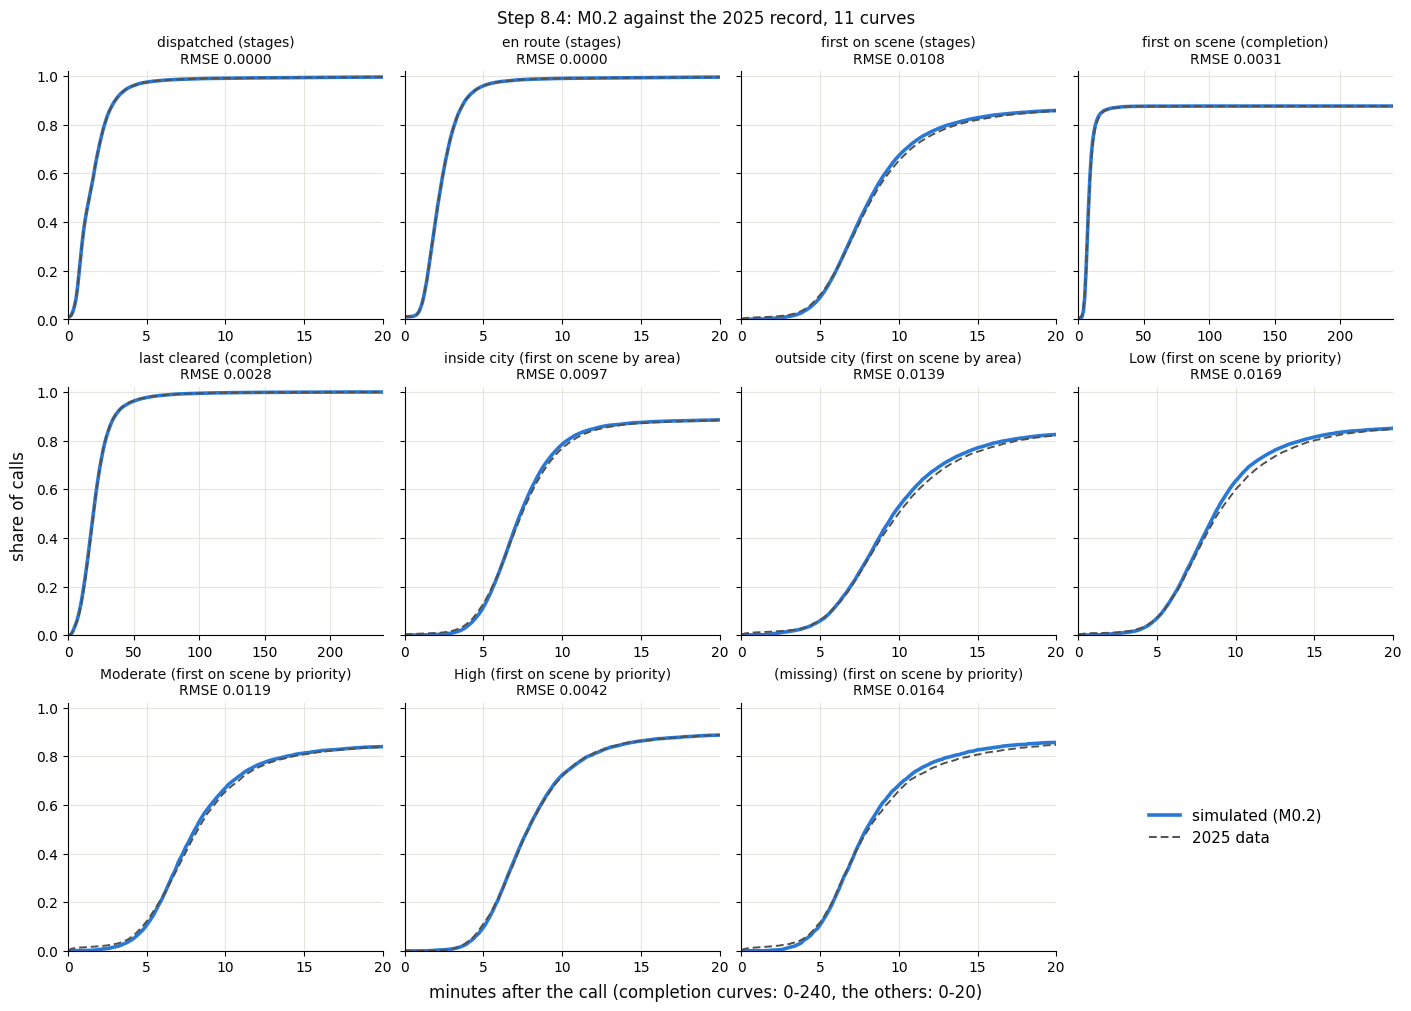

In [83]:
def describe_call_fates(runs, simulated, dispatch_log, fates_by_arrival, verbose=VERBOSE):
    """M0.2: what the call-level fates did. Per run of a call in fates_by_arrival: its fate in the 2025 record (arrived
    or cancelled) and in the simulation (arrived, released, or not sent), its engine, the travel its engine took (from
    the dispatch log), and minutes from the call to its dispatch and arrival in both. Prints the fates side by side,
    two checks (every call keeps its recorded number of arrivals; a released run has no arrival), and three calls whose
    first-dispatched run was cancelled in 2025, run by run.

    Example: describe_call_fates(runs, m02_protocol, m02_report["dispatches"], fates_by_arrival)["simulated"]
             .value_counts() -> arrived / released / not sent (counts)
    """
    rows = runs.index[runs["incident_id"].isin(fates_by_arrival.keys())]
    call_at = runs.loc[rows, "call_received_at"]
    table = pd.DataFrame({
        "incident_id": runs.loc[rows, "incident_id"], "engine_id": simulated.loc[rows, "engine_id"],
        "2025": np.where(runs.loc[rows, "arrived_at"].notna(), "arrived", "cancelled"),
        "simulated": np.select([simulated.loc[rows, "arrived_at"].notna(), simulated.loc[rows, "engine_id"].isna()],
                               ["arrived", "not sent"], "released"),
        "travel taken min": dispatch_log.set_index("run")["travel_s"].reindex(rows).astype(float) / 60,
        "2025 dispatched min": (runs.loc[rows, "dispatched_at"] - call_at) / 60,
        "2025 arrived min": (runs.loc[rows, "arrived_at"] - call_at) / 60,
        "simulated dispatched min": (simulated.loc[rows, "dispatched_at"] - call_at) / 60,
        "simulated arrived min": (simulated.loc[rows, "arrived_at"] - call_at) / 60})
    if verbose:
        arrivals = table.groupby("incident_id")[["2025", "simulated"]].agg(lambda fate: int((fate == "arrived").sum()))
        first = runs.loc[rows].sort_values(["incident_id", "dispatched_at"]).groupby("incident_id").head(1)
        examples = first.loc[first["arrived_at"].isna(), "incident_id"].head(3)
        print(f"--- M0.2 call fates: {len(fates_by_arrival):,} calls with two or more runs, {len(table):,} runs\n"
              f"{pd.crosstab(table['2025'], table['simulated']).to_string()}\n"
              f"checks: calls whose number of arrivals differs from 2025: {int((arrivals['2025'] != arrivals['simulated']).sum())}; "
              f"released runs with an arrival: {int(((table['simulated'] != 'arrived') & table['simulated arrived min'].notna()).sum())}\n")
        for incident in examples:
            print(f"call {incident} (first-dispatched run cancelled in 2025):\n"
                  f"{table[table['incident_id'] == incident].drop(columns='incident_id').round(2).to_string()}\n")
    return table


fates_by_arrival = call_fates(m0_runs)
m02_report = {}
m02_protocol = simulate(
    m0_runs, available=define_available_engines, engines=engines, estimated_travel=boundary_travel,
    choose=lambda run, available, travel: dispatch_closest_with_spread(run, available, travel, travel_spread,
                                                                       call_inside_city, spread_quantile),
    where_engines_are=lambda row, now, state, travel: travel_while_returning(
        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model,
        fitted_dwell_s, fitted_slowdown),
    wait_rank=wait_rank, report=m02_report, counterfactual=True, fates_by_arrival=fates_by_arrival)
m02_fates = describe_call_fates(runs, m02_protocol, m02_report["dispatches"], fates_by_arrival)
m02_origins = describe_engine_origins(m02_report["dispatches"], dispatches, boundary_travel, call_nodes, home_nodes,
                                      seconds_from_node, node_position, network_travel_model, fitted_dwell_s, fitted_slowdown)
m02_engine_check = compare_engines(runs, m02_protocol, dispatches)
m02_table = simulated_dispatch_table(dispatches, m02_protocol, engines, verbose=False)
m02_curves = response_curves(m02_table, verbose=False)
m02_check = compare_curves(m02_curves, curves_2025)
plot_curves(m02_curves, m02_check, "simulated (M0.2)", "Step 8.4: M0.2 against the 2025 record, 11 curves")

## Step 8.5 — E0 again

**Change.** `check_counterfactual_run(arrivals_by_call=True)` counts calls whose number of arrivals differs from 2025
(the record's row fates no longer apply in multi-run calls); `decide_e0` counts whichever arrival check is present.
**Check.** State checks, strata, the evaluation matrix with M0.2 added, and the E0 decision.

In [84]:
def check_counterfactual_run(runs, simulated, dispatches, report, arrivals_by_call=False, verbose=VERBOSE):
    """E0 state checks of a run that should be counterfactual-consistent. The first six must be 0; kept 2025 times
    must not exceed the runs of calls without a location; the rest describe the run. With arrivals_by_call (M0.2, where
    the call decides which of its runs arrive) the arrival check counts calls whose number of arrivals differs from
    2025 instead of runs that lost their arrival.

    Example: check_counterfactual_run(runs, m0_protocol, dispatches, m0_report)["runs never served"] -> 0
    """
    served = simulated["engine_id"].notna()
    order = simulated[served].sort_values(["engine_id", "dispatched_at"])
    still_busy = order["dispatched_at"] < order.groupby("engine_id")["cleared_at"].shift()
    out_of_order = (simulated[TIME_COLUMNS].ffill(axis=1).diff(axis=1).iloc[:, 1:] < 0).any(axis=1)
    waits = pd.Series(report["waited_seconds"], dtype=float)
    if arrivals_by_call:
        arrivals = [frame["arrived_at"].notna().groupby(runs["incident_id"]).sum() for frame in (runs, simulated)]
        arrival_check = {"calls whose number of arrivals differs from 2025": int((arrivals[0] != arrivals[1]).sum())}
    else:
        arrival_check = {"runs with an arrival in 2025 but none simulated":
                         int((runs["arrived_at"].notna() & simulated["arrived_at"].isna()).sum())}
    checks = pd.Series({
        "runs never served": len(report["never_served"]),
        "runs whose engine was taken by a newer run": len(report["taken_by_newer_run"]),
        "runs sent while their engine was still on an earlier run": int(still_busy.sum()),
        **arrival_check,
        "runs with times out of order": int(out_of_order.sum()),
        "runs served without a clear": int((served & simulated["cleared_at"].isna()).sum()),
        "runs that kept their 2025 times": len(report["kept_recorded"]),
        "runs of calls without a location": int(dispatches["incident_lon"].isna().sum()),
        "cancelled requests that never got an engine": len(report["cancelled_while_waiting"]),
        "calls whose first arrival is the recorded second (share)": share_first_arrivals_as_recorded(runs, simulated),
        "runs that waited for an engine": len(waits),
        "wait seconds: median": waits.median(),
        "wait seconds: max": waits.max(),
    })
    if verbose:
        print(f"--- E0 state checks\n{checks.round(4).to_string()}\n")
        if len(waits):
            ranks = dispatches.loc[waits.index, "priority"].astype("string").fillna("(missing)")
            print(f"waits by priority (count, median s):\n{waits.groupby(ranks).agg(['size', 'median']).round(0).to_string()}\n")
    return checks


def decide_e0(states, by_stratum, verbose=VERBOSE):
    """E0 decision (research.md): first-on-scene curve RMSE for all calls at most E0_RMSE_LIMIT, no state violation,
    and only calls without a location keep their 2025 times.

    Example: decide_e0(e0_states, e0_strata) -> False  # FY2025: no state violation, but RMSE 0.0377 > 0.03
    """
    violation_checks = ["runs never served", "runs whose engine was taken by a newer run",
                        "runs sent while their engine was still on an earlier run",
                        "runs with an arrival in 2025 but none simulated", "calls whose number of arrivals differs from 2025",
                        "runs with times out of order", "runs served without a clear"]
    violations = states[states.index.intersection(violation_checks)].sum()   # one of the two arrival checks is present
    passed = bool(by_stratum.loc["all calls", "rmse"] <= E0_RMSE_LIMIT and violations == 0
                  and states["runs that kept their 2025 times"] <= states["runs of calls without a location"])
    if verbose:
        print(f"E0: RMSE all calls {by_stratum.loc['all calls', 'rmse']:.4f} (limit {E0_RMSE_LIMIT}), state violations "
              f"{int(violations)}, kept 2025 times {int(states['runs that kept their 2025 times'])} "
              f"(calls without a location {int(states['runs of calls without a location'])}) -> passed: {passed}\n")
    return passed


m02_states = check_counterfactual_run(runs, m02_protocol, dispatches, m02_report, arrivals_by_call=True)
m02_strata = compare_curves_by_stratum(m02_table, dispatches)
columns["step 8 (M0.2): + arrivals decided by the call"] = evaluation_column(
    runs, m02_protocol, dispatches, m02_table, dispatches, m02_check, travel_comparison.loc[chosen_form, "mean |error| min"])
evaluation = evaluation_matrix(columns)
e02_passed = decide_e0(m02_states, m02_strata)

--- E0 state checks
runs never served                                            0.0000
runs whose engine was taken by a newer run                   0.0000
runs sent while their engine was still on an earlier run     0.0000
calls whose number of arrivals differs from 2025             0.0000
runs with times out of order                                 0.0000
runs served without a clear                                  0.0000
runs that kept their 2025 times                              4.0000
runs of calls without a location                             4.0000
cancelled requests that never got an engine                 24.0000
calls whose first arrival is the recorded second (share)     0.0003
runs that waited for an engine                               0.0000
wait seconds: median                                            NaN
wait seconds: max                                               NaN



--- E0 first-on-scene curve, simulated vs 2025, by stratum
                                     calls    rmse  max_abs_difference
all calls                          33156.0  0.0108              0.0217
multi-engine calls                  2941.0  0.0280              0.0615
first engine sent away from home    4823.0  0.0293              0.0742
calls with an other-agency engine   1371.0  0.0209              0.0576

--- evaluation matrix
                                                2025 record  step 2: straight line  step 3: road network  step 4: + agency boundaries  step 5.1: + returning engines  step 5.1b: + AVL-fitted return  step 6 (M0): modeled travel for every run  step 7 (M0.1): + travel spread  step 8 (M0.2): + arrivals decided by the call
travel estimate: test mean |error| (min)                NaN                  1.636                 1.547                        1.547                          1.547                           1.547                                      1.547     

## Step 8.6 — Multi-engine and fire calls, M0.1 against M0.2

**Check.** The Step 7.6 groups with M0.2 added: first-on-scene curve RMSE, median and P90 against the 2025 record.

In [85]:
minutes_m02, _ = first_on_scene_minutes(m02_table)
print(pd.DataFrame({name: {"calls": len(ids),
                           "RMSE M0.1": first_on_scene_rmse(minutes_m01[ids], minutes_2025[ids]),
                           "RMSE M0.2": first_on_scene_rmse(minutes_m02[ids], minutes_2025[ids]),
                           "P50 2025": minutes_2025[ids].median(), "P50 M0.1": minutes_m01[ids].median(),
                           "P50 M0.2": minutes_m02[ids].median(), "P90 2025": minutes_2025[ids].quantile(0.9),
                           "P90 M0.1": minutes_m01[ids].quantile(0.9), "P90 M0.2": minutes_m02[ids].quantile(0.9)}
                    for name, ids in groups.items()}).T.round(3).to_string())

                                                        calls  RMSE M0.1  RMSE M0.2  P50 2025  P50 M0.1  P50 M0.2  P90 2025  P90 M0.1  P90 M0.2
all calls                                             33156.0      0.006      0.011     7.833     7.805     7.730    13.217    13.004    12.686
multi-engine, first-dispatched run arrived in 2025     1653.0      0.014      0.022     7.783     7.663     7.570    13.143    12.695    12.343
multi-engine, first-dispatched run cancelled in 2025   1288.0      0.114      0.036     8.650    11.102     8.254    15.617    19.512    13.796
fire calls (call type Fire)                            6742.0      0.009      0.024     8.217     8.217     7.970    14.150    13.787    12.933
fire calls, single-engine                              4595.0      0.023      0.023     8.333     8.158     8.157    14.483    13.236    13.236
fire calls, multi-engine                               2147.0      0.034      0.028     7.917     8.404     7.636    13.527    14.746   

## Section 8 evidence

- **Sections 1–7 are unchanged.**
  - All 46 output files written before M0.2 are byte-identical after the full run.
  - M0.1 rerun with the new functions equals Section 7's run (Step 8.1). On the first 30 days it also equals the saved
    full-year run, for all 3,022 runs.
- **The functions do what we believe (printed).**
  - Where engines were when sent, under M0.2: at their station 96.1%, driving home from a call 2.9%, driving home after
    a cancelled run 1.0%.
  - The share of the way home rises with minutes since clearing: medians 0.20, 0.51, 0.78, 0.84 and 0.91 for 0–2, 2–4,
    4–8, 8–16 and 16–60 min.
  - The three position checks pass: every share is in [0, 1), and every engine counted at its station got the travel
    from home.
  - Travel taken equals modeled × ratio, and the drawn ratios match the fitted ones bin by bin: P50 within 0.02. The
    shortest outside-city bin's P10 reflects the quantiles its runs happened to draw.
- **M0.2 works as designed.**
  - The six small cases match the hand-calculated answers.
  - In the full year, every one of the 2,941 multi-run calls keeps its recorded number of arrivals.
  - 971 runs that the record cancelled now arrive, and as many recorded arrivals are released or not sent. 24 runs are
    not sent because a release found no engine under way.
  - In the 1,288 calls whose first-dispatched run was cancelled in 2025, first-on-scene RMSE falls from 0.114 to 0.036.
- **E0 passes.**
  - RMSE is 0.0108 (M0.1: 0.0060): 0.0097 inside the city and 0.0139 outside; the largest of the 11 curves is 0.017.
  - State violations are 0.
  - The diagnostic strata are now all below 0.03: multi-engine 0.028 (M0.1 0.045), first engine away from home 0.029
    (0.031), other-agency 0.021 (0.037).
- **What remains: the simulation reaches calls early.**
  - Overall P90 is 12.69 min against 13.22.
  - Fire calls (call type Fire): P90 12.93 against 14.15. Single-engine fire calls are early as before (P90 13.24
    against 14.48), and multi-engine fire calls are now early too (12.35 against 13.53).
  - In single-engine fire calls the mean error is −23.5 s. About two thirds of it (−15.7 s) comes from the 25% of calls
    where the simulation sends a different engine than CAD did; these are 64 s early on average. A third (−7.8 s) comes
    from the same engine sent from home, 11 s early. In medical calls a different engine is not early (+0.8 s).
  - So for fire calls, CAD often did not send the closest unit, for example to commercial alarms and road crashes.
  - In 2025, 15.6% of engines were away from their station when sent; the simulation has 3.9%.
- **Next (to decide).** Choose between:
  - modeling CAD's fire-call choice and engines that are away from their station;
  - carrying both as sensitivity tests into Step 3, as the reviewer requires before any policy conclusion.

# Section 9 — M0.3: engine types in the protocol, fitted to the 2025 record

The engine-class units are of two types: E, an engine (pumper, 23 units), and Q, a quint (a pumper that also carries an
aerial ladder, 6 units). Up to M0.2 the protocol treated them alike. In 2025, when CAD did not send the closest unit, the
closest was often a quint and CAD sent an engine instead: a quint is kept available for ladder work. M0.3 adds this: a
quint is sent only when its modeled travel beats every available engine's by more than a penalty, fitted so that the rule
sends CAD's engine as often as possible on single-engine calls in Oct–Jun and checked on Jul–Sep. The penalty changes the
ranking only; the engine sent takes its own travel. Fire calls are reported two ways: the CAD Fire category (call type
Fire: alarms, crashes and fires) and the study's fire calls (F67 outside, F69 structure, F71 vehicle, F82 brush fires).

**Input/output check before running (gpt-6-astra, read-only).** PASS; the 10-second penalty confirmed independently and
the 54 earlier outputs unchanged. One optional reporting point, adopted: label the CAD Fire category and report the
study's fire calls separately.

## Step 9.1 — `dispatch_closest` with a ranking penalty

**Change.** `rank_penalty` (engine id -> seconds) is added when ranking only; the engine sent returns its own modeled
travel; ties go to the engine listed first; with no penalty nothing changes.
**Check.** Toy cases with hand-calculated answers, and M0.2 rerun with the new functions equals Section 8's run.

In [86]:
QUINT_PENALTY_GRID_S = np.arange(0, 301, 10)                                # [DESIGN] M0.3: candidate extra seconds a quint must save over an engine before it is sent
STUDY_FIRE_PROTOCOLS = ["F67", "F69", "F71", "F82"]                         # [SOURCE] research.md fire calls: outside, structure, vehicle, brush fires (348 calls Jul-Sep, 317 reached)


def dispatch_closest(run, available_engines, travel_for_run, rank_penalty=None):
    """Section 6 rule for the choice (M0): the available engine with the shortest modeled travel from where it is now
    goes, always with that travel, so no run keeps its 2025 times. Equal travel goes to the engine listed first (engines
    table order), never to the 2025 engine. With no available engine it returns (None, None) and the run waits
    (simulate). A call without a location has no travel for any engine: its 2025 engine goes with its 2025 times when
    free, otherwise the run waits for that engine. rank_penalty (M0.3; engine id -> seconds) is added when ranking only:
    the engine sent still takes its own modeled travel.

    Example: dispatch_closest(runs.loc[0], ["E62", "E3"], boundary_travel.loc[0]) -> ('E62', 257.05...)  # seconds
             dispatch_closest(runs.loc[0], [], boundary_travel.loc[0]) -> (None, None)
    """
    if travel_for_run.isna().all():                              # call without coordinates (4 runs)
        return (run["engine_id"], None) if run["engine_id"] in available_engines else (None, None)
    candidates = travel_for_run[available_engines].dropna()
    if candidates.empty:
        return None, None
    ranked = candidates if rank_penalty is None else candidates + rank_penalty.reindex(candidates.index, fill_value=0.0)
    best = ranked.idxmin()
    return best, float(candidates[best])


def dispatch_closest_with_spread(run, available_engines, travel_for_run, spread, inside_city, spread_quantile,
                                 rank_penalty=None):
    """Section 7 rule (M0.1): the M0 choice (dispatch_closest, on modeled travel, as CAD ranks on its estimate), but
    the chosen engine then takes modeled travel x a ratio drawn at this run's own quantile (spread_quantile: run row ->
    quantile, the same for every policy, so two policies that send different engines to a run share its luck).
    inside_city: run row -> whether the call is inside the city. Runs that keep their 2025 times (calls without a
    location) and runs that must wait pass through unchanged. rank_penalty (M0.3) goes to dispatch_closest.

    Example: dispatch_closest_with_spread(runs.loc[0], ["E62", "E3"], boundary_travel.loc[0], travel_spread,
                                          call_inside_city, spread_quantile) -> ('E62', 392.51...)  # 257.05 s x 1.527
    """
    engine_id, travel_seconds = dispatch_closest(run, available_engines, travel_for_run, rank_penalty)
    if travel_seconds is None:
        return engine_id, None
    ratio = draw_travel_ratio(spread, bool(inside_city[run.name]), travel_seconds, spread_quantile[run.name])
    return engine_id, travel_seconds * ratio


toy_run = pd.Series({"engine_id": "E9"}, name=0)
toy_travel = pd.Series({"E1": 300.0, "Q2": 250.0, "E3": np.nan})
for quint_s, expected in [(None, ("Q2", 250.0)), (30, ("Q2", 250.0)), (49, ("Q2", 250.0)), (50, ("E1", 300.0)), (60, ("E1", 300.0))]:
    toy_penalty = None if quint_s is None else pd.Series({"E1": 0.0, "Q2": float(quint_s)})
    sent = dispatch_closest(toy_run, ["E1", "Q2", "E3"], toy_travel, toy_penalty)
    print(f"Q2 250 s, E1 300 s, quint penalty {quint_s}: sends {sent} (hand: {expected})")
    assert sent == expected

m02_report_again = {}
m02_again = simulate(
    m0_runs, available=define_available_engines, engines=engines, estimated_travel=boundary_travel,
    choose=lambda run, available, travel: dispatch_closest_with_spread(run, available, travel, travel_spread,
                                                                       call_inside_city, spread_quantile),
    where_engines_are=lambda row, now, state, travel: travel_while_returning(
        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model,
        fitted_dwell_s, fitted_slowdown),
    wait_rank=wait_rank, report=m02_report_again, counterfactual=True, fates_by_arrival=fates_by_arrival, verbose=False)
print("M0.2 rerun with the new functions, runs with any time or engine different from Section 8:",
      compare_times(m02_protocol, m02_again, verbose=False))

Q2 250 s, E1 300 s, quint penalty None: sends ('Q2', 250.0) (hand: ('Q2', 250.0))
Q2 250 s, E1 300 s, quint penalty 30: sends ('Q2', 250.0) (hand: ('Q2', 250.0))
Q2 250 s, E1 300 s, quint penalty 49: sends ('Q2', 250.0) (hand: ('Q2', 250.0))
Q2 250 s, E1 300 s, quint penalty 50: sends ('E1', 300.0) (hand: ('E1', 300.0))
Q2 250 s, E1 300 s, quint penalty 60: sends ('E1', 300.0) (hand: ('E1', 300.0))


M0.2 rerun with the new functions, runs with any time or engine different from Section 8: 0


## Step 9.2 — Fit the quint penalty to CAD's choices

**Check.** Share of single-engine calls (engine from its station) where the rule sends CAD's engine, by penalty, on the
fitting and test months, for all calls, the CAD Fire category, the study's fire calls and medical calls; the chosen
penalty; and runs where it changes the closest engine.

In [87]:
def fit_quint_penalty(dispatches, runs, engines, estimated_travel, verbose=VERBOSE):
    """M0.3: how many seconds a quint (Q: a pumper that also carries an aerial ladder) must save over an engine before
    CAD sends it. Fitted on single-engine calls whose 2025 engine left from its station (one choice, a known origin):
    the engines CAD could send are those with an estimate in estimated_travel (in service, allowed by the agency line)
    and not on a 2025 run at that moment (the record's availability; runs gives the repaired 2025 times). The rule
    sends the one with the least modeled travel from home, plus the penalty if it is a quint. The penalty in
    QUINT_PENALTY_GRID_S that sends CAD's engine most often on the fitting months (before TRAVEL_TEST_FROM) is kept;
    the test months (Jul-Sep) check it. Returns the penalty (seconds) and the agreement table (penalty x months x calls).

    Example: quint_penalty_s, penalty_fit = fit_quint_penalty(dispatches, m0_runs, engines, boundary_travel)
             penalty_fit.loc[0, "fit: all"] -> share of fitting runs where the plain closest rule sends CAD's engine
    """
    engine_ids = estimated_travel.columns
    is_quint = (engines.set_index("engine_id").loc[engine_ids, "engine_type"] == "Q").to_numpy()
    rows = dispatches.index[(dispatches["n_engines_sent"] == 1) & dispatches["at_home"].astype(bool)
                            & dispatches["incident_lon"].notna()]
    dispatched_s = runs.loc[rows, "dispatched_at"].to_numpy()
    busy = np.zeros((len(rows), len(engine_ids)), dtype=bool)
    for column, engine_id in enumerate(engine_ids):              # on a 2025 run that started before and clears after
        own = runs[runs["engine_id"] == engine_id].sort_values("dispatched_at")
        starts, ends = own["dispatched_at"].to_numpy(), own["cleared_at"].to_numpy()
        # ponytail: only the engine's last run started before is checked; overlapping runs of one engine are rare (3 in 2025)
        last = np.searchsorted(starts, dispatched_s, side="left") - 1
        busy[:, column] = (last >= 0) & (ends[np.maximum(last, 0)] > dispatched_s)
    travel = estimated_travel.loc[rows, engine_ids].to_numpy()
    travel = np.where(busy | np.isnan(travel), np.inf, travel)
    cad = engine_ids.get_indexer(dispatches.loc[rows, "engine_id"])
    fitting = (dispatches.loc[rows, "dispatched_at"] < TRAVEL_TEST_FROM).to_numpy()
    kind = dispatches.loc[rows, "call_type"].astype(object).fillna("(missing)").to_numpy()
    study_fire = dispatches.loc[rows, "protocol"].isin(STUDY_FIRE_PROTOCOLS).to_numpy()
    groups = [("all", np.ones(len(rows), dtype=bool)), ("CAD Fire category", kind == "Fire"), ("study fires", study_fire),
              ("medical", kind == "Medical")]
    agreement = {}
    for penalty in QUINT_PENALTY_GRID_S:
        same = np.argmin(travel + penalty * is_quint, axis=1) == cad
        agreement[int(penalty)] = {f"{months}: {group}": same[in_months & in_group].mean()
                                   for months, in_months in [("fit", fitting), ("test", ~fitting)] for group, in_group in groups}
    penalty_fit = pd.DataFrame(agreement).T.rename_axis("quint penalty s")
    quint_penalty_s = float(penalty_fit["fit: all"].idxmax())
    if verbose:
        closest = np.argmin(travel, axis=1)
        chosen = np.argmin(travel + quint_penalty_s * is_quint, axis=1)
        changed = np.flatnonzero(closest != chosen)
        examples = pd.DataFrame({
            "run": rows[changed], "call type": kind[changed], "closest (a quint)": engine_ids[closest[changed]],
            "closest travel min": travel[changed, closest[changed]] / 60, "sent instead": engine_ids[chosen[changed]],
            "sent travel min": travel[changed, chosen[changed]] / 60, "CAD sent": dispatches.loc[rows[changed], "engine_id"].to_numpy()})
        shown = penalty_fit.loc[[penalty for penalty in penalty_fit.index if penalty % 30 == 0 or penalty == quint_penalty_s]]
        print(f"--- quint penalty fit: {int(fitting.sum()):,} fitting and {int((~fitting).sum()):,} test runs (single-engine calls, "
              f"engine from its station); CAD's engine among the engines the rule could send: {np.isfinite(travel[np.arange(len(rows)), cad]).mean():.1%}\n"
              f"share of runs where the rule sends CAD's engine, by penalty:\n{shown.round(3).to_string()}\n"
              f"chosen penalty: {quint_penalty_s:.0f} s; it changes the closest engine on {len(changed):,} runs "
              f"({len(changed) / len(rows):.1%}), of which CAD sent the engine the penalty picks: "
              f"{(examples['sent instead'] == examples['CAD sent']).mean():.1%}, the quint: {(examples['closest (a quint)'] == examples['CAD sent']).mean():.1%}\n"
              f"examples:\n{examples.head(5).round(2).to_string(index=False)}\n")
    return quint_penalty_s, penalty_fit


quint_penalty_s, penalty_fit = fit_quint_penalty(dispatches, m0_runs, engines, boundary_travel)
quint_rank_penalty = (engines.set_index("engine_id")["engine_type"] == "Q").astype(float) * quint_penalty_s
print("ranking penalty by engine (seconds):", quint_rank_penalty[quint_rank_penalty > 0].to_dict())

--- quint penalty fit: 19,444 fitting and 6,377 test runs (single-engine calls, engine from its station); CAD's engine among the engines the rule could send: 99.8%
share of runs where the rule sends CAD's engine, by penalty:
                 fit: all  fit: CAD Fire category  fit: study fires  fit: medical  test: all  test: CAD Fire category  test: study fires  test: medical
quint penalty s                                                                                                                                        
0                   0.822                   0.788             0.803         0.835      0.835                    0.779              0.741          0.853
10                  0.866                   0.826             0.836         0.880      0.872                    0.819              0.839          0.887
30                  0.856                   0.817             0.816         0.870      0.861                    0.809              0.825          0.875
60             

## Step 9.3 — The full year under M0.3

**Change.** The Step 8.4 setting with `rank_penalty=quint_rank_penalty`.
**Check.** Engine types sent and agreement with CAD, M0.2 against M0.3, beside 2025.

--- simulated CAD times (seconds since day zero) and engine used (37194, 5)
   dispatched_at  enroute_at    arrived_at    cleared_at engine_id
0         6796.0      6858.0   7250.514401   7399.514401       E62
1        23905.0     23956.0  24425.492028  25179.492028       E62
2        28215.0     28215.0  28412.330196  30267.330196       E29
3        29358.0     29358.0  29361.000000  31955.000000       E60
4        36851.0     36891.0  37355.456439  38100.456439        E3

--- engine types sent, by version
                        runs sent a quint  same engine as CAD  same engine, CAD sent an engine  same engine, CAD sent a quint
2025 all                            0.123                 NaN                              NaN                            NaN
     CAD Fire category              0.179                 NaN                              NaN                            NaN
     study fires                    0.144                 NaN                              NaN               

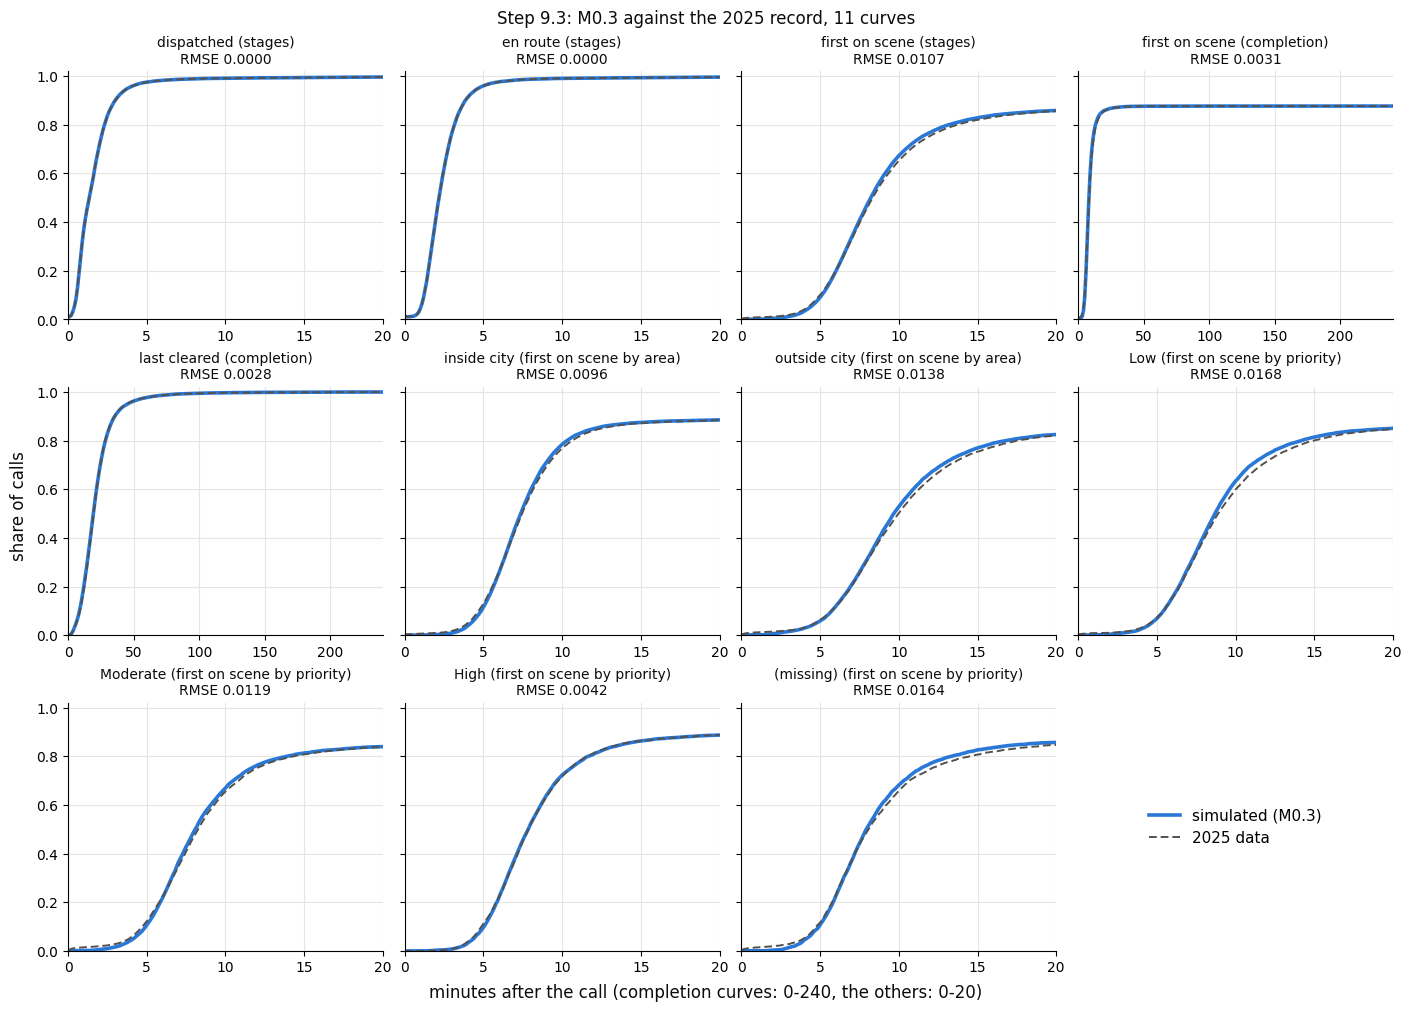

In [88]:
def describe_type_choices(dispatches, versions, verbose=VERBOSE):
    """M0.3: what the quint penalty changed in a full run. Per version (name -> simulated run table, simulate's output)
    and per call group: the share of runs sent a quint (2025 beside), the share that got CAD's engine, split by the type
    CAD sent; and five runs where the first two versions sent different types.

    Call groups: all, the CAD Fire category (call_type Fire: alarms, crashes and fires), the study's fire calls
    (STUDY_FIRE_PROTOCOLS) and medical calls.

    Example: describe_type_choices(dispatches, {"M0.2": m02_protocol, "M0.3": m03_protocol}).loc[("M0.3", "study fires")]
             -> runs sent a quint, same engine as CAD, ...
    """
    kind = dispatches["call_type"].astype(object).fillna("(missing)")
    cad_engine = dispatches["engine_id"].astype(object)
    cad_type = cad_engine.str[0]
    groups = [("all", kind.notna()), ("CAD Fire category", kind == "Fire"),
              ("study fires", dispatches["protocol"].isin(STUDY_FIRE_PROTOCOLS)), ("medical", kind == "Medical")]
    shares = {("2025", group): {"runs sent a quint": (cad_type[mask] == "Q").mean()} for group, mask in groups}
    for name, simulated in versions.items():
        sent = simulated["engine_id"].astype(object)
        same = sent == cad_engine
        for group, mask in groups:
            shares[(name, group)] = {"runs sent a quint": (sent[mask].str[0] == "Q").mean(), "same engine as CAD": same[mask].mean(),
                                     "same engine, CAD sent an engine": same[mask & (cad_type == "E")].mean(),
                                     "same engine, CAD sent a quint": same[mask & (cad_type == "Q")].mean()}
    table = pd.DataFrame(shares).T
    if verbose:
        first, second = list(versions)[:2]
        sent_first, sent_second = (versions[name]["engine_id"].astype(object) for name in (first, second))
        differs = sent_first.str[0].ne(sent_second.str[0]) & sent_first.notna() & sent_second.notna()
        examples = pd.DataFrame({"call type": kind, "CAD sent": cad_engine, first: sent_first, second: sent_second})[differs]
        print(f"--- engine types sent, by version\n{table.round(3).to_string()}\n"
              f"runs where {first} and {second} sent different types: {int(differs.sum()):,}; examples:\n{examples.head(5).to_string()}\n")
    return table


m03_report = {}
m03_protocol = simulate(
    m0_runs, available=define_available_engines, engines=engines, estimated_travel=boundary_travel,
    choose=lambda run, available, travel: dispatch_closest_with_spread(run, available, travel, travel_spread,
                                                                       call_inside_city, spread_quantile, quint_rank_penalty),
    where_engines_are=lambda row, now, state, travel: travel_while_returning(
        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model,
        fitted_dwell_s, fitted_slowdown),
    wait_rank=wait_rank, report=m03_report, counterfactual=True, fates_by_arrival=fates_by_arrival)
type_choices = describe_type_choices(dispatches, {"M0.2": m02_protocol, "M0.3": m03_protocol})
m03_engine_check = compare_engines(runs, m03_protocol, dispatches)
m03_table = simulated_dispatch_table(dispatches, m03_protocol, engines, verbose=False)
m03_curves = response_curves(m03_table, verbose=False)
m03_check = compare_curves(m03_curves, curves_2025)
plot_curves(m03_curves, m03_check, "simulated (M0.3)", "Step 9.3: M0.3 against the 2025 record, 11 curves")

## Step 9.4 — E0 again

**Check.** The same state checks (call-level arrivals), strata, the evaluation matrix with M0.3 added, and the decision.

In [89]:
m03_states = check_counterfactual_run(runs, m03_protocol, dispatches, m03_report, arrivals_by_call=True)
m03_strata = compare_curves_by_stratum(m03_table, dispatches)
columns["step 9 (M0.3): + quint penalty"] = evaluation_column(
    runs, m03_protocol, dispatches, m03_table, dispatches, m03_check, travel_comparison.loc[chosen_form, "mean |error| min"])
evaluation = evaluation_matrix(columns)
e03_passed = decide_e0(m03_states, m03_strata)

--- E0 state checks
runs never served                                            0.0000
runs whose engine was taken by a newer run                   0.0000
runs sent while their engine was still on an earlier run     0.0000
calls whose number of arrivals differs from 2025             0.0000
runs with times out of order                                 0.0000
runs served without a clear                                  0.0000
runs that kept their 2025 times                              4.0000
runs of calls without a location                             4.0000
cancelled requests that never got an engine                 24.0000
calls whose first arrival is the recorded second (share)     0.0004
runs that waited for an engine                               0.0000
wait seconds: median                                            NaN
wait seconds: max                                               NaN



--- E0 first-on-scene curve, simulated vs 2025, by stratum
                                     calls    rmse  max_abs_difference
all calls                          33156.0  0.0107              0.0215
multi-engine calls                  2941.0  0.0280              0.0622
first engine sent away from home    4823.0  0.0296              0.0755
calls with an other-agency engine   1371.0  0.0211              0.0584

--- evaluation matrix
                                                2025 record  step 2: straight line  step 3: road network  step 4: + agency boundaries  step 5.1: + returning engines  step 5.1b: + AVL-fitted return  step 6 (M0): modeled travel for every run  step 7 (M0.1): + travel spread  step 8 (M0.2): + arrivals decided by the call  step 9 (M0.3): + quint penalty
travel estimate: test mean |error| (min)                NaN                  1.636                 1.547                        1.547                          1.547                           1.547                

## Step 9.5 — Where the fire calls stand, and why single-engine fire calls are still early

**Check.** First-on-scene RMSE, median and P90 against 2025 for M0.2 and M0.3, with the study's fire calls added. Then,
for single-engine calls reached in both, simulated minus recorded arrival split by what was sent: CAD's engine (from
its station or not), an engine of the same station as CAD's, or an engine of another station.

In [90]:
minutes_m03, _ = first_on_scene_minutes(m03_table)
study_fire_call = dispatches.groupby("incident_id")["protocol"].first().isin(STUDY_FIRE_PROTOCOLS)
fire_groups = dict(groups, **{"study fire calls": study_fire_call.index[study_fire_call],
                              "study fire calls, single-engine": study_fire_call.index[study_fire_call & ~multi_engine_call],
                              "study fire calls, multi-engine": study_fire_call.index[study_fire_call & multi_engine_call]})
print(pd.DataFrame({name: {"calls": len(ids),
                           "RMSE M0.2": first_on_scene_rmse(minutes_m02[ids], minutes_2025[ids]),
                           "RMSE M0.3": first_on_scene_rmse(minutes_m03[ids], minutes_2025[ids]),
                           "P50 2025": minutes_2025[ids].median(), "P50 M0.3": minutes_m03[ids].median(),
                           "P90 2025": minutes_2025[ids].quantile(0.9), "P90 M0.2": minutes_m02[ids].quantile(0.9),
                           "P90 M0.3": minutes_m03[ids].quantile(0.9)}
                    for name, ids in fire_groups.items()}).T.round(3).to_string())

station_of = engines.set_index("engine_id")["home_station"]
reached = (dispatches["n_engines_sent"] == 1) & dispatches["arrived_at"].notna() & m03_table["arrived_at"].notna()
error_s = (m03_table["arrived_at"] - dispatches["arrived_at"]).dt.total_seconds()
sent, cad_sent = (table["engine_id"].astype(object).fillna("") for table in (m03_table, dispatches))   # "" = not sent
what_was_sent = np.select(
    [sent.eq(cad_sent) & dispatches["at_home"].astype(bool), sent.eq(cad_sent),
     sent.map(station_of).eq(cad_sent.map(station_of))],
    ["CAD's engine, from its station", "CAD's engine, CAD's was away from its station", "an engine of CAD's station"],
    "an engine of another station")
for label, in_group in [("CAD Fire category", dispatches["call_type"].astype(object).eq("Fire")),
                        ("study fire calls", dispatches["protocol"].isin(STUDY_FIRE_PROTOCOLS)),
                        ("medical", dispatches["call_type"].astype(object).eq("Medical"))]:
    part = pd.DataFrame({"error_s": error_s, "sent": what_was_sent})[reached & in_group]
    split = part.groupby("sent")["error_s"].agg(["size", "mean", "median"])
    split["share"] = split["size"] / len(part)
    split["contribution to mean s"] = split["mean"] * split["share"]
    print(f"\nsingle-engine {label}: {len(part):,} runs, mean error {part['error_s'].mean():.1f} s (simulated minus recorded)\n"
          f"{split.round(2).to_string()}")

                                                        calls  RMSE M0.2  RMSE M0.3  P50 2025  P50 M0.3  P90 2025  P90 M0.2  P90 M0.3
all calls                                             33156.0      0.011      0.011     7.833     7.738    13.217    12.686    12.695
multi-engine, first-dispatched run arrived in 2025     1653.0      0.022      0.023     7.783     7.571    13.143    12.343    12.348
multi-engine, first-dispatched run cancelled in 2025   1288.0      0.036      0.036     8.650     8.259    15.617    13.796    13.796
fire calls (call type Fire)                            6742.0      0.024      0.024     8.217     7.975    14.150    12.933    12.938
fire calls, single-engine                              4595.0      0.023      0.023     8.333     8.158    14.483    13.236    13.235
fire calls, multi-engine                               2147.0      0.028      0.028     7.917     7.649    13.527    12.348    12.348
study fire calls                                       1702.0 

## Section 9 evidence

- **Sections 1–8 are unchanged.** All 54 earlier output files are byte-identical after the full run. M0.2 rerun with
  the new functions equals Section 8's run (Step 9.1). The toy cases match the hand-calculated answers, including a tie.
- **The quint penalty is 10 s.**
  - It raises static agreement with CAD from 82.2% to 86.6% on the fitting months, and from 83.5% to 87.2% on Jul–Sep.
    Larger penalties lower it.
  - It changes the closest engine on 1,545 runs (6.0%). On 80.3% of these, CAD sent the engine the penalty picks.
- **Engine types now match the record.**
  - Runs sent a quint: 2025 12.3%, M0.2 17.4%, M0.3 12.5%.
  - Same engine as CAD, across all requests: 69.1% → 72.4%. First engine of each call: 73.6% → 77.1%. Medical calls:
    76.3% → 79.9%. CAD Fire category: 52.9% → 55.5%.
  - Where CAD sent a quint, agreement falls from 59.9% to 57.1%; the gains come where CAD sent an engine.
  - Of the 2,924 runs whose engine type changed, 2,734 are swaps within the same station. Arrival times therefore barely
    move.
- **E0 passes.**
  - RMSE 0.0107 (M0.2: 0.0108), with 0 state violations.
  - Strata: multi-engine 0.028, first engine away from home 0.030, other-agency 0.021.
- **Fire calls: the early arrivals are brush fires (F82).**
  - The study's fire calls (F67/F69/F71/F82) reach P90 at 14.38 min against 15.87 in 2025.
  - F82 brush fires are 127 s early on average over the year and 183 s early in Jul–Sep. They carry about three quarters
    of the signed fire error. Engines take longer to reach brush fires than the road network says: recorded travel P90 is
    17.9 min, simulated 14.3.
  - Without F82, the study fires are 11 s early over the year and 12 s late in Jul–Sep. F69 structure fires are 0.1 s
    late on average over the year.
- **Next (to decide).** Either define the fire outcome without brush fires, or give brush fires their own travel
  calibration. Before Step 3 conclusions, run the reviewer's sensitivity tests (travel, origins, shared seeds).

# Section 10 — M0.4: the quint penalty by call type, and brush fires' own travel spread

**Why.** E0 passed in M0.3, but the outcome research.md compares policies on, first-engine arrival at the study's fire
calls (F67, F69, F71, F82) in Jul–Sep, was early: mean −24.7 s and P90 113.5 s early, against a margin m = 10 s.
Brush fires (F82), which the author keeps in the outcome because they readily cause engine shortages, carried about 77%
of the signed error. And research.md lets the agent choose only among eligible engines, so which unit type a call
type may get has to be the same for every policy.

**What the 2025 record shows.**
- At the four stations with both an engine and a quint, CAD sent the quint to 98% of elevator calls (F56). It sent the
  quint to 7% of medical calls and about 6–11% of alarms and crashes.
- Multi-engine brush fires had a quint in 5–10% of calls; M0.3 sends one in 24–36%.
- In 36% of brush fires the simulation sent CAD's own engine and its station also sent its brush truck. These calls were
  175 s early on average (−64 s of the −127 s). Such engines travel 1.35× longer (mean) than other calls of the same
  area and trip length.

**Change.** Two parts:
1. The quint penalty of M0.3 is fitted per call type (elevator calls, brush fires, all other calls). The data and method
   are those of M0.3; negative penalties are allowed (the quint preferred).
2. Brush-fire runs draw their travel ratio from brush-fire runs only (2 areas × 2 bins of modeled travel). Other runs
   are unchanged.

Not done: crew sharing between brush trucks and engines (mainly station 22), and requiring an aerial unit on multi-engine
fire calls (towers and ladder trucks are not in the engine pool).

**Input/output check before running (gpt-6-astra, read-only).** PASS. Astra independently verified the penalties
−260/+260/+10 s, the travel draws and the bootstrap intervals, and found that all 62 earlier outputs match. Two optional
reporting points were adopted:
- state where the fire interval lies against ±m, besides whether it contains 0;
- judge the brush-fire quint share on the multi-engine calls that got at least one quint.

## Step 10.1 — The quint penalty, fitted per call type

**Change.** `fit_quint_penalty` takes the grid as an argument (default unchanged), and a group without runs gives NaN.
`fit_quint_penalty_by_call_type` runs it on each call type's own rows over −300…300 s.
**Check.**
- Toy cases with hand-calculated answers: the per-call-type penalty changes the ranking only.
- The default call rebuilds `m03_quint_penalty_fit.csv` byte for byte.
- The per-call-type fit, beside M0.3's single 10 s.

In [91]:
QUINT_PENALTY_BY_TYPE_GRID_S = np.arange(-300, 301, 10)                     # [DESIGN] M0.4: candidate quint penalties per call type; negative = CAD prefers the quint
BRUSH_FIRE_PROTOCOL = "F82"                                                 # [SOURCE] MPDS fire protocol 82: vegetation, wildland, brush or grass fire
QUINT_RULE_CALL_TYPES = {"F56": "F56 elevator", BRUSH_FIRE_PROTOCOL: "F82 brush fire"}  # [SOURCE] 2025 record: CAD sent the quint to 98% of elevator calls at stations with both types, and a quint to 5-10% of multi-engine brush fires (M0.3: 24-36%); every other call type shares one penalty
BRUSH_SPREAD_BINS = 2                                                       # [DESIGN] M0.4: bins of modeled travel per area for brush fires' own travel spread (58-97 fitting runs each)
FIRE_MARGIN_S = 10                                                          # [SOURCE] research.md: threshold m (tentative 10 s) for a practical difference in fire arrival
BLOCK_BOOTSTRAP_DRAWS = 2000                                                # [DESIGN] weekly block-bootstrap draws for the interval of a mean arrival error
BLOCK_BOOTSTRAP_SEED = 20250701                                             # [DESIGN] seed of the weekly block bootstrap
BOOTSTRAP_INTERVAL = (0.025, 0.975)                                         # [STANDARD] two-sided 95% interval
QUINT_SHARE_TOLERANCE = 0.05                                                # [DESIGN] M0.4 done-criterion: share of multi-engine brush fires sent a quint within 5 points of 2025 (sampling SE about 2 points on 179 calls)


def fit_quint_penalty(dispatches, runs, engines, estimated_travel, grid=QUINT_PENALTY_GRID_S, verbose=VERBOSE):
    """M0.3: how many seconds a quint (Q: a pumper that also carries an aerial ladder) must save over an engine before
    CAD sends it. Fitted on single-engine calls whose 2025 engine left from its station (one choice, a known origin):
    the engines CAD could send are those with an estimate in estimated_travel (in service, allowed by the agency line)
    and not on a 2025 run at that moment (the record's availability; runs gives the repaired 2025 times). The rule
    sends the one with the least modeled travel from home, plus the penalty if it is a quint. The penalty in `grid`
    that sends CAD's engine most often on the fitting months (before TRAVEL_TEST_FROM) is kept; the test months
    (Jul-Sep) check it. Returns the penalty (seconds) and the agreement table (penalty x months x calls); a group with
    no runs gets NaN. M0.4 fits one call type at a time: pass its rows of dispatches, and a grid with negative penalties.

    Example: quint_penalty_s, penalty_fit = fit_quint_penalty(dispatches, m0_runs, engines, boundary_travel)
             penalty_fit.loc[0, "fit: all"] -> share of fitting runs where the plain closest rule sends CAD's engine
    """
    engine_ids = estimated_travel.columns
    is_quint = (engines.set_index("engine_id").loc[engine_ids, "engine_type"] == "Q").to_numpy()
    rows = dispatches.index[(dispatches["n_engines_sent"] == 1) & dispatches["at_home"].astype(bool)
                            & dispatches["incident_lon"].notna()]
    dispatched_s = runs.loc[rows, "dispatched_at"].to_numpy()
    busy = np.zeros((len(rows), len(engine_ids)), dtype=bool)
    for column, engine_id in enumerate(engine_ids):              # on a 2025 run that started before and clears after
        own = runs[runs["engine_id"] == engine_id].sort_values("dispatched_at")
        starts, ends = own["dispatched_at"].to_numpy(), own["cleared_at"].to_numpy()
        # ponytail: only the engine's last run started before is checked; overlapping runs of one engine are rare (3 in 2025)
        last = np.searchsorted(starts, dispatched_s, side="left") - 1
        busy[:, column] = (last >= 0) & (ends[np.maximum(last, 0)] > dispatched_s)
    travel = estimated_travel.loc[rows, engine_ids].to_numpy()
    travel = np.where(busy | np.isnan(travel), np.inf, travel)
    cad = engine_ids.get_indexer(dispatches.loc[rows, "engine_id"])
    fitting = (dispatches.loc[rows, "dispatched_at"] < TRAVEL_TEST_FROM).to_numpy()
    kind = dispatches.loc[rows, "call_type"].astype(object).fillna("(missing)").to_numpy()
    study_fire = dispatches.loc[rows, "protocol"].isin(STUDY_FIRE_PROTOCOLS).to_numpy()
    groups = [("all", np.ones(len(rows), dtype=bool)), ("CAD Fire category", kind == "Fire"), ("study fires", study_fire),
              ("medical", kind == "Medical")]
    agreement = {}
    for penalty in grid:
        same = np.argmin(travel + penalty * is_quint, axis=1) == cad
        agreement[int(penalty)] = {f"{months}: {group}": same[in_months & in_group].mean() if (in_months & in_group).any() else np.nan
                                   for months, in_months in [("fit", fitting), ("test", ~fitting)] for group, in_group in groups}
    penalty_fit = pd.DataFrame(agreement).T.rename_axis("quint penalty s")
    quint_penalty_s = float(penalty_fit["fit: all"].idxmax())
    if verbose:
        closest = np.argmin(travel, axis=1)
        chosen = np.argmin(travel + quint_penalty_s * is_quint, axis=1)
        changed = np.flatnonzero(closest != chosen)
        examples = pd.DataFrame({
            "run": rows[changed], "call type": kind[changed], "closest (a quint)": engine_ids[closest[changed]],
            "closest travel min": travel[changed, closest[changed]] / 60, "sent instead": engine_ids[chosen[changed]],
            "sent travel min": travel[changed, chosen[changed]] / 60, "CAD sent": dispatches.loc[rows[changed], "engine_id"].to_numpy()})
        shown = penalty_fit.loc[[penalty for penalty in penalty_fit.index if penalty % 30 == 0 or penalty == quint_penalty_s]]
        print(f"--- quint penalty fit: {int(fitting.sum()):,} fitting and {int((~fitting).sum()):,} test runs (single-engine calls, "
              f"engine from its station); CAD's engine among the engines the rule could send: {np.isfinite(travel[np.arange(len(rows)), cad]).mean():.1%}\n"
              f"share of runs where the rule sends CAD's engine, by penalty:\n{shown.round(3).to_string()}\n"
              f"chosen penalty: {quint_penalty_s:.0f} s; it changes the closest engine on {len(changed):,} runs "
              f"({len(changed) / len(rows):.1%}), of which CAD sent the engine the penalty picks: "
              f"{(examples['sent instead'] == examples['CAD sent']).mean():.1%}, the quint: {(examples['closest (a quint)'] == examples['CAD sent']).mean():.1%}\n"
              f"examples:\n{examples.head(5).round(2).to_string(index=False)}\n")
    return quint_penalty_s, penalty_fit


def fit_quint_penalty_by_call_type(dispatches, runs, engines, estimated_travel, call_type_of_run, single_penalty_s,
                                   verbose=VERBOSE):
    """M0.4: the quint penalty fitted separately per call type. call_type_of_run: run row -> label (QUINT_RULE_CALL_TYPES,
    every other call one label). Each label runs fit_quint_penalty on its own rows over QUINT_PENALTY_BY_TYPE_GRID_S, so
    the same runs, availability and months as M0.3 (single-engine calls, engine from its station; fit Oct-Jun, test
    Jul-Sep). A negative penalty means CAD prefers the quint unless an engine is that much closer. single_penalty_s
    (M0.3's one penalty for all calls) is printed beside. Returns {label: penalty seconds} and the agreement table (rows:
    label x penalty; columns: fit and test months).

    Example: quint_penalty_by_type, type_penalty_fit = fit_quint_penalty_by_call_type(
                 dispatches, m0_runs, engines, boundary_travel, call_type_for_quint, quint_penalty_s)
             quint_penalty_by_type -> {'F56 elevator': -260.0, 'F82 brush fire': 260.0, 'all other calls': 10.0}
    """
    quint_penalty_by_type, agreement_by_type = {}, {}
    for label, rows in call_type_of_run.groupby(call_type_of_run).groups.items():
        quint_penalty_by_type[label], fit = fit_quint_penalty(dispatches.loc[rows], runs, engines, estimated_travel,
                                                              grid=QUINT_PENALTY_BY_TYPE_GRID_S, verbose=False)
        agreement_by_type[label] = fit[["fit: all", "test: all"]]
    type_penalty_fit = pd.concat(agreement_by_type, names=["call type"])
    if verbose:
        fitting_rows = dispatches.index[(dispatches["n_engines_sent"] == 1) & dispatches["at_home"].astype(bool)
                                        & dispatches["incident_lon"].notna()]
        months = np.where(dispatches.loc[fitting_rows, "dispatched_at"] < TRAVEL_TEST_FROM, "fitting runs", "test runs")
        summary = pd.crosstab(call_type_of_run[fitting_rows], months).rename_axis(index="call type", columns=None)
        summary["chosen penalty s"] = pd.Series(quint_penalty_by_type)
        for months_column in ["fit: all", "test: all"]:
            summary[f"{months_column[:4]} agreement at chosen"] = [type_penalty_fit.loc[(label, int(penalty)), months_column]
                                                                  for label, penalty in quint_penalty_by_type.items()]
            summary[f"{months_column[:4]} agreement at {single_penalty_s:.0f} s (M0.3)"] = [
                type_penalty_fit.loc[(label, int(single_penalty_s)), months_column] for label in quint_penalty_by_type]
        shown = type_penalty_fit[type_penalty_fit.index.get_level_values(1) % 60 == 0].unstack(0)
        print(f"--- quint penalty by call type (single-engine calls, engine from its station; negative = the quint "
              f"preferred)\n{summary.round(3).to_string()}\n"
              f"share of runs where the rule sends CAD's engine, by penalty:\n{shown.round(3).to_string()}\n")
    return quint_penalty_by_type, type_penalty_fit


import io

toy_run = pd.Series({"engine_id": "E9"}, name=0)
quint_only = pd.Series({"E1": 0.0, "Q2": 1.0})
for label, penalty_s, engine_s, quint_s, expected in [
        ("F56 elevator", -260.0, 300.0, 500.0, ("Q2", 500.0)), ("F56 elevator", -260.0, 200.0, 500.0, ("E1", 200.0)),
        ("F56 elevator", -260.0, 240.0, 500.0, ("E1", 240.0)), ("F82 brush fire", 260.0, 500.0, 250.0, ("E1", 500.0)),
        ("F82 brush fire", 260.0, 520.0, 250.0, ("Q2", 250.0)), ("all other calls", 10.0, 255.0, 250.0, ("E1", 255.0)),
        ("all other calls", 10.0, 265.0, 250.0, ("Q2", 250.0))]:
    sent = dispatch_closest(toy_run, ["E1", "Q2"], pd.Series({"E1": engine_s, "Q2": quint_s}), quint_only * penalty_s)
    print(f"{label}: E1 {engine_s:.0f} s, Q2 {quint_s:.0f} s, quint penalty {penalty_s:+.0f} s -> sends {sent} (hand: {expected})")
    assert sent == expected

_, default_fit = fit_quint_penalty(dispatches, m0_runs, engines, boundary_travel, verbose=False)
text = io.StringIO()
default_fit.to_csv(text)
print("\nfit_quint_penalty with its defaults rebuilds m03_quint_penalty_fit.csv byte for byte:",
      text.getvalue().encode() == (OUTPUT_DIR / "m03_quint_penalty_fit.csv").read_bytes())

call_type_for_quint = dispatches["protocol"].map(QUINT_RULE_CALL_TYPES).fillna("all other calls")   # run row -> label
print("runs by call type:", call_type_for_quint.value_counts().to_dict())
quint_penalty_by_type, type_penalty_fit = fit_quint_penalty_by_call_type(dispatches, m0_runs, engines, boundary_travel,
                                                                         call_type_for_quint, quint_penalty_s)
quint_penalty_of_run = call_type_for_quint.map(quint_penalty_by_type)                 # run row -> seconds added to a quint
quint_indicator = (engines.set_index("engine_id")["engine_type"] == "Q").astype(float)  # engine id -> 1 for a quint
print("chosen:", quint_penalty_by_type)

F56 elevator: E1 300 s, Q2 500 s, quint penalty -260 s -> sends ('Q2', 500.0) (hand: ('Q2', 500.0))
F56 elevator: E1 200 s, Q2 500 s, quint penalty -260 s -> sends ('E1', 200.0) (hand: ('E1', 200.0))
F56 elevator: E1 240 s, Q2 500 s, quint penalty -260 s -> sends ('E1', 240.0) (hand: ('E1', 240.0))
F82 brush fire: E1 500 s, Q2 250 s, quint penalty +260 s -> sends ('E1', 500.0) (hand: ('E1', 500.0))
F82 brush fire: E1 520 s, Q2 250 s, quint penalty +260 s -> sends ('Q2', 250.0) (hand: ('Q2', 250.0))
all other calls: E1 255 s, Q2 250 s, quint penalty +10 s -> sends ('E1', 255.0) (hand: ('E1', 255.0))
all other calls: E1 265 s, Q2 250 s, quint penalty +10 s -> sends ('Q2', 250.0) (hand: ('Q2', 250.0))

fit_quint_penalty with its defaults rebuilds m03_quint_penalty_fit.csv byte for byte: True
runs by call type: {'all other calls': 36450, 'F82 brush fire': 633, 'F56 elevator': 111}


--- quint penalty by call type (single-engine calls, engine from its station; negative = the quint preferred)
                 fitting runs  test runs  chosen penalty s  fit: agreement at chosen  fit: agreement at 10 s (M0.3)  test agreement at chosen  test agreement at 10 s (M0.3)
call type                                                                                                                                                                   
F56 elevator               66         34            -260.0                     0.758                          0.303                     0.765                          0.294
F82 brush fire            162         37             260.0                     0.802                          0.778                     0.784                          0.784
all other calls         19216       6306              10.0                     0.869                          0.869                     0.876                          0.876
share of runs where the r

## Step 10.2 — Brush fires' own travel spread

**Change.** `fit_travel_spread` takes the number of bins as an argument (default unchanged). It is called on the
brush-fire rows with 2 bins per area.
**Check.**
- The default call rebuilds `m01_travel_spread.csv` byte for byte.
- The brush-fire spread and its held-out check.
- The draws of held-out brush-fire runs (Jul–Sep, CAD's engine from its station) under both spreads, at the same quantile,
  beside the recorded travel.

In [92]:
def fit_travel_spread(dispatches, network_seconds, network_km, travel_model, spread_quantile, bin_count=TRAVEL_SPREAD_BINS,
                      verbose=VERBOSE):
    """M0.1: how real travel spreads around the modeled travel. On the travel model's own fitting runs (left from home,
    dispatched before TRAVEL_TEST_FROM; the filter of compare_travel_models), ratio = recorded / modeled travel, kept
    per area (call inside or outside the city) and per `bin_count` equal-count bins of modeled travel. The later
    runs (Jul-Sep; held out from the ratios, though Section 3 chose the travel model's form on their errors) test it:
    each gets modeled travel x the ratio at its own quantile (spread_quantile: run row -> quantile in (0, 1), as in the
    simulation), and recorded travel should fall below the predicted P10 and above the predicted P90 about 10% of the
    time each, per area (the check) and per bin (in the bin table, so short trips are seen on their own). Returns the
    spread (for draw_travel_ratio), the bin table and the check. M0.4 fits brush fires on their own: pass the brush-fire
    rows of dispatches, network_seconds and network_km, with bin_count=BRUSH_SPREAD_BINS.

    Example: travel_spread, spread_table, spread_check = fit_travel_spread(dispatches, network_seconds, network_km,
                                                                           network_travel_model, spread_quantile)
             spread_table.loc[(False, 0), "ratio P50"] -> 1.097  # the shortest trips outside the city take ~10% longer
    """
    rows = np.arange(len(dispatches))
    own_engine = network_seconds.columns.get_indexer(dispatches["engine_id"])
    seconds, km = network_seconds.to_numpy()[rows, own_engine], network_km.to_numpy()[rows, own_engine]
    recorded = dispatches["travel_s"].to_numpy(dtype=float, na_value=np.nan)
    usable = (dispatches["at_home"].astype(bool).to_numpy() & (recorded > 0) & np.isfinite(seconds)
              & ~dispatches["qc_note"].str.contains("implausible|equals_incident").to_numpy())
    trips = pd.DataFrame({"inside_city": dispatches["focal"].fillna(False).astype(bool).to_numpy(),
                          "modeled_s": travel_model(seconds, km), "recorded_s": recorded,
                          "fitting_run": (dispatches["dispatched_at"] < TRAVEL_TEST_FROM).to_numpy()},
                         index=dispatches.index)[usable]
    trips["ratio"] = trips["recorded_s"] / trips["modeled_s"]
    # ponytail: ratios are kept as recorded, CAD button slips included (P1 down to 0.02 on the shortest trips); trim if a use needs physical travel only
    show_table("trips for the travel spread (runs that left from home)", trips, verbose)
    spread, bins = {}, []
    for inside_city, fit in trips[trips["fitting_run"]].groupby("inside_city"):
        bin_of_trip, edges = pd.qcut(fit["modeled_s"], bin_count, labels=False, retbins=True)
        ratios_by_bin = [np.sort(fit["ratio"][bin_of_trip == b].to_numpy()) for b in range(bin_count)]
        spread[inside_city] = (edges[1:-1], ratios_by_bin)
        for b, ratios in enumerate(ratios_by_bin):
            bins.append({"inside_city": inside_city, "bin": b, "modeled from (min)": edges[b] / 60,
                         "modeled to (min)": edges[b + 1] / 60, "fitting runs": len(ratios),
                         **{f"ratio P{q}": np.quantile(ratios, q / 100) for q in (1, 10, 50, 90, 99)}})
    spread_table = pd.DataFrame(bins).set_index(["inside_city", "bin"])
    test = trips[~trips["fitting_run"]].copy()
    quantile_of_run = {"drawn_s": spread_quantile[test.index], "predicted_p10_s": pd.Series(0.1, index=test.index),
                       "predicted_p90_s": pd.Series(0.9, index=test.index)}
    for name, quantile in quantile_of_run.items():
        test[name] = [modeled * draw_travel_ratio(spread, inside, modeled, quantile[row])
                      for row, inside, modeled in zip(test.index, test["inside_city"], test["modeled_s"])]
    test["bin"] = [int(np.searchsorted(spread[inside][0], modeled, side="left"))      # the bin draw_travel_ratio uses
                   for inside, modeled in zip(test["inside_city"], test["modeled_s"])]
    test["below_p10"], test["above_p90"] = test["recorded_s"] < test["predicted_p10_s"], test["recorded_s"] > test["predicted_p90_s"]
    spread_table = spread_table.join(test.groupby(["inside_city", "bin"]).agg(
        **{"held-out runs": ("below_p10", "size"), "held-out below P10": ("below_p10", "mean"),
           "held-out above P90": ("above_p90", "mean")}))
    checks = {}
    for area, part in [("all", test), *[(AREA_LABELS[flag], test[test["inside_city"] == flag]) for flag in (True, False)]]:
        checks[area] = {"test runs": len(part),
                        **{f"{source} P{q} (min)": part[column].quantile(q / 100) / 60
                           for source, column in [("recorded", "recorded_s"), ("modeled", "modeled_s"),
                                                  ("modeled x drawn ratio", "drawn_s")] for q in (10, 50, 90)},
                        "recorded below predicted P10": part["below_p10"].mean(),
                        "recorded above predicted P90": part["above_p90"].mean()}
    spread_check = pd.DataFrame(checks).T
    if verbose:
        print(f"travel spread fitted on {int(trips['fitting_run'].sum()):,} runs before {TRAVEL_TEST_FROM.date()} that left "
              f"from home, tested on {len(test):,} later runs (held out from the ratios; Section 3 chose the travel "
              f"model's form on their errors)\n"
              f"--- ratio recorded / modeled travel by area and bin of modeled travel; held-out shares outside the "
              f"bin's P10-P90 (about 0.10 each if calibrated)\n{spread_table.round(3).to_string()}\n"
              f"--- held-out check (Jul-Sep): travel minutes, and how often recorded travel falls outside the predicted "
              f"P10-P90 (about 0.10 each if calibrated)\n{spread_check.round(3).T.to_string()}\n")
    return spread, spread_table, spread_check


_, default_spread_table, _ = fit_travel_spread(dispatches, network_seconds, network_km, network_travel_model, spread_quantile,
                                               verbose=False)
text = io.StringIO()
default_spread_table.to_csv(text)
print("fit_travel_spread with its defaults rebuilds m01_travel_spread.csv byte for byte:",
      text.getvalue().encode() == (OUTPUT_DIR / "m01_travel_spread.csv").read_bytes(), "\n")

brush_run = dispatches["protocol"].eq(BRUSH_FIRE_PROTOCOL).fillna(False)
brush_spread, brush_spread_table, brush_spread_check = fit_travel_spread(
    dispatches.loc[brush_run], network_seconds.loc[brush_run], network_km.loc[brush_run], network_travel_model,
    spread_quantile, bin_count=BRUSH_SPREAD_BINS)

held_out = dispatches.index[brush_run & dispatches["at_home"].astype(bool) & (dispatches["dispatched_at"] >= TRAVEL_TEST_FROM)
                            & dispatches["travel_s"].notna()]
own_engine = boundary_travel.columns.get_indexer(dispatches.loc[held_out, "engine_id"])
modeled_s = boundary_travel.loc[held_out].to_numpy()[np.arange(len(held_out)), own_engine]
draws = pd.DataFrame({"run": held_out, "inside city": call_inside_city[held_out].to_numpy(), "modeled min": modeled_s / 60,
                      "quantile": spread_quantile[held_out].to_numpy()})
for column, spread in [("all-call ratio (M0.3)", travel_spread), ("brush ratio (M0.4)", brush_spread)]:
    draws[column] = [draw_travel_ratio(spread, inside, seconds, quantile)
                     for inside, seconds, quantile in zip(draws["inside city"], modeled_s, draws["quantile"])]
draws["M0.3 travel min"] = draws["modeled min"] * draws["all-call ratio (M0.3)"]
draws["M0.4 travel min"] = draws["modeled min"] * draws["brush ratio (M0.4)"]
draws["recorded travel min"] = dispatches.loc[held_out, "travel_s"].to_numpy(dtype=float) / 60
print(f"held-out brush-fire runs: six examples, then all {len(draws)}\n{draws.head(6).round(3).to_string(index=False)}\n"
      f"travel minutes, mean / P90: M0.3 {draws['M0.3 travel min'].mean():.2f} / {draws['M0.3 travel min'].quantile(0.9):.2f}, "
      f"M0.4 {draws['M0.4 travel min'].mean():.2f} / {draws['M0.4 travel min'].quantile(0.9):.2f}, "
      f"recorded {draws['recorded travel min'].mean():.2f} / {draws['recorded travel min'].quantile(0.9):.2f}")

fit_travel_spread with its defaults rebuilds m01_travel_spread.csv byte for byte: True 

--- trips for the travel spread (runs that left from home) (362, 5)
     inside_city   modeled_s  recorded_s  fitting_run     ratio
119        False  600.521494       545.0         True  0.907545
235        False  739.670630       930.0         True  1.257316
416        False  561.367993       910.0         True  1.621040
443        False  454.478325       546.0         True  1.201377
469        False  400.514046       405.0         True  1.011200

travel spread fitted on 309 runs before 2025-07-01 that left from home, tested on 53 later runs (held out from the ratios; Section 3 chose the travel model's form on their errors)
--- ratio recorded / modeled travel by area and bin of modeled travel; held-out shares outside the bin's P10-P90 (about 0.10 each if calibrated)
                 modeled from (min)  modeled to (min)  fitting runs  ratio P1  ratio P10  ratio P50  ratio P90  ratio P99  held-out r

## Step 10.3 — The full year under M0.4

**Change.** Section 9's setting, with per run the spread (brush fires: their own) and the quint penalty of its call type.
**Check.**
- The M0.4 code path with M0.3's settings (10 s for every call, the all-call spread) equals Section 9's run.
- The M0.4 run: where the engines left from, the brush-fire travel draws (drawn vs fitted), and the engine types by call
  type beside 2025.

M0.3 settings through the M0.4 code path, runs with any time or engine different from Section 9: 0


--- where engines were when the simulation sent them
                                    dispatches  share
origin                                               
at station                               35688   0.96
driving home from a call                  1101   0.03
driving home after a cancelled run         382   0.01
2025 record, AVL position at assignment: {'at its station': 0.844, 'away from its station': 0.156}
share of the way home by minutes since clearing (engines on the way home):
                     size  median
minutes since clear              
(0, 2]                565    0.20
(2, 4]                410    0.51
(4, 8]                345    0.78
(8, 16]                67    0.84
(16, 60]                4    0.91

examples, at station:
  run                time engine_id     origin  minutes since clear  share of way home  modeled min  taken min  from home min
16205 2024-10-01 00:07:07        E9 at station                  NaN                NaN         5.72       4.61      

/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/1322079103.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(f"examples, {origin}:\n{part.head(3).round(2).to_string(index=False)}\n")
/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/1322079103.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(f"examples, {origin}:\n{part.head(3).round(2).to_string(index=False)}\n")
/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/1322079103.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(f"examples, {origin}:\n{part.head(3).round(2).to_string(index=False)}\n")


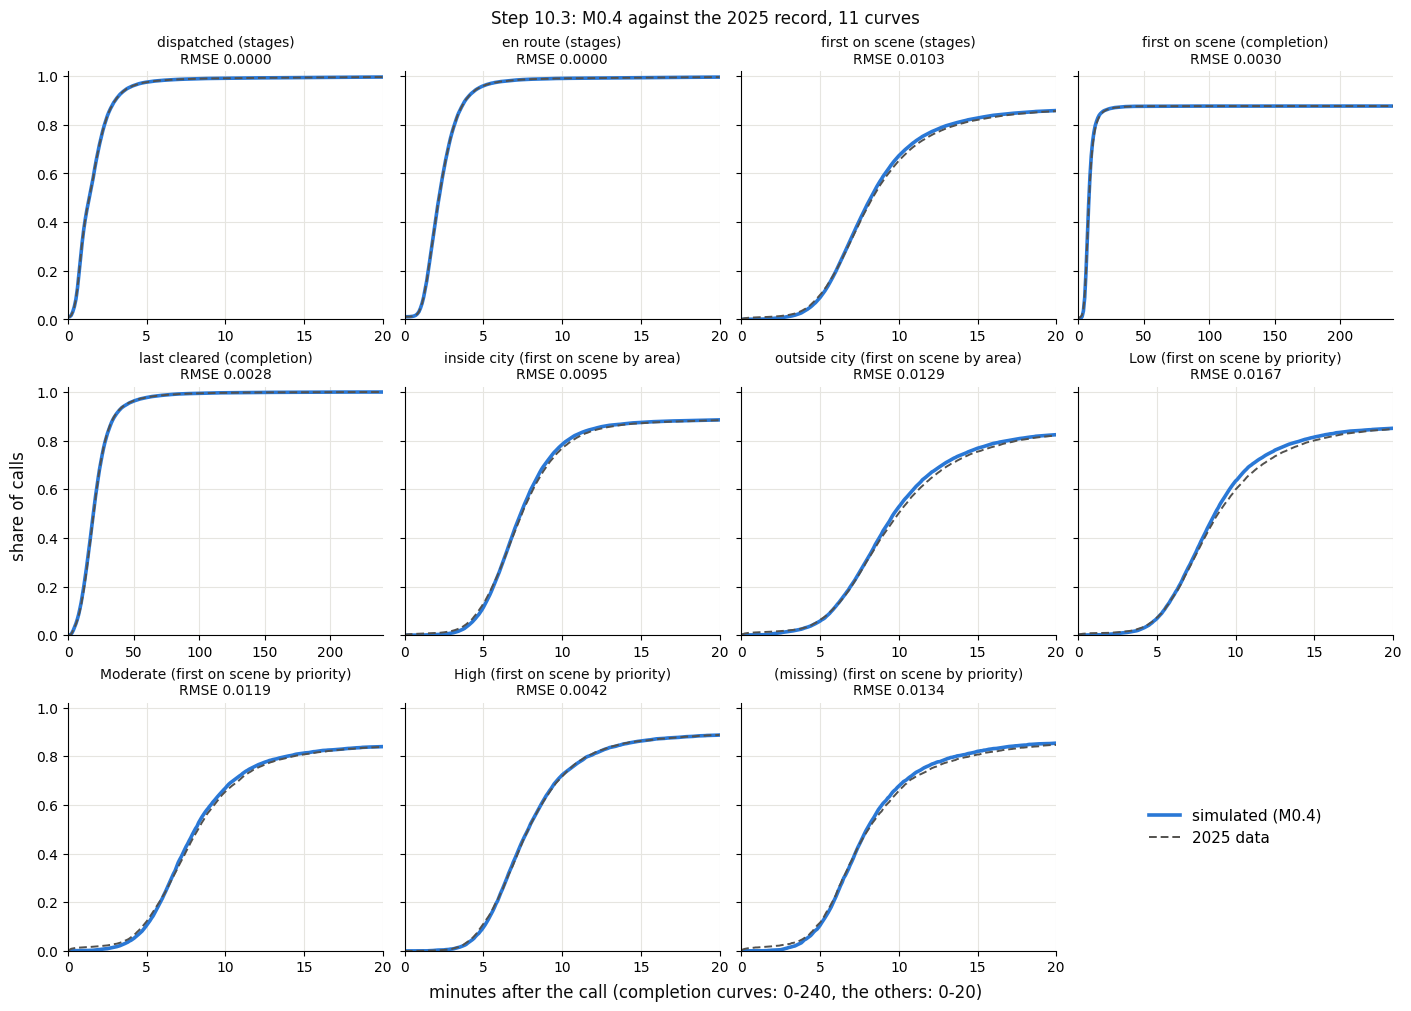

In [93]:
def describe_type_choices(dispatches, versions, groups=None, verbose=VERBOSE):
    """M0.3: what the quint penalty changed in a full run. Per version (name -> simulated run table, simulate's output)
    and per call group: the share of runs sent a quint (2025 beside), the share that got CAD's engine, split by the type
    CAD sent; and five runs where the first two versions sent different types.

    Call groups (default): all, the CAD Fire category (call_type Fire: alarms, crashes and fires), the study's fire calls
    (STUDY_FIRE_PROTOCOLS) and medical calls; `groups` (a list of (name, mask over dispatches rows)) replaces them (M0.4).

    Example: describe_type_choices(dispatches, {"M0.2": m02_protocol, "M0.3": m03_protocol}).loc[("M0.3", "study fires")]
             -> runs sent a quint, same engine as CAD, ...
    """
    kind = dispatches["call_type"].astype(object).fillna("(missing)")
    cad_engine = dispatches["engine_id"].astype(object)
    cad_type = cad_engine.str[0]
    if groups is None:
        groups = [("all", kind.notna()), ("CAD Fire category", kind == "Fire"),
                  ("study fires", dispatches["protocol"].isin(STUDY_FIRE_PROTOCOLS)), ("medical", kind == "Medical")]
    shares = {("2025", group): {"runs sent a quint": (cad_type[mask] == "Q").mean()} for group, mask in groups}
    for name, simulated in versions.items():
        sent = simulated["engine_id"].astype(object)
        same = sent == cad_engine
        for group, mask in groups:
            shares[(name, group)] = {"runs sent a quint": (sent[mask].str[0] == "Q").mean(), "same engine as CAD": same[mask].mean(),
                                     "same engine, CAD sent an engine": same[mask & (cad_type == "E")].mean(),
                                     "same engine, CAD sent a quint": same[mask & (cad_type == "Q")].mean()}
    table = pd.DataFrame(shares).T
    if verbose:
        first, second = list(versions)[:2]
        sent_first, sent_second = (versions[name]["engine_id"].astype(object) for name in (first, second))
        differs = sent_first.str[0].ne(sent_second.str[0]) & sent_first.notna() & sent_second.notna()
        examples = pd.DataFrame({"call type": kind, "CAD sent": cad_engine, first: sent_first, second: sent_second})[differs]
        print(f"--- engine types sent, by version\n{table.round(3).to_string()}\n"
              f"runs where {first} and {second} sent different types: {int(differs.sum()):,}; examples:\n{examples.head(5).to_string()}\n")
    return table


def run_m04_path(penalty_of_run, spread_for_brush, report):
    """The Section 10 simulation: per run, the quint penalty penalty_of_run[row] and, for brush-fire runs, spread_for_brush."""
    return simulate(
        m0_runs, available=define_available_engines, engines=engines, estimated_travel=boundary_travel,
        choose=lambda run, available, travel: dispatch_closest_with_spread(
            run, available, travel, spread_for_brush if brush_run[run.name] else travel_spread, call_inside_city,
            spread_quantile, quint_indicator * penalty_of_run[run.name]),
        where_engines_are=lambda row, now, state, travel: travel_while_returning(
            row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model,
            fitted_dwell_s, fitted_slowdown),
        wait_rank=wait_rank, report=report, counterfactual=True, fates_by_arrival=fates_by_arrival, verbose=False)


m03_again = run_m04_path(pd.Series(quint_penalty_s, index=dispatches.index), travel_spread, {})
print("M0.3 settings through the M0.4 code path, runs with any time or engine different from Section 9:",
      compare_times(m03_protocol, m03_again, verbose=False))

m04_report = {}
m04_protocol = run_m04_path(quint_penalty_of_run, brush_spread, m04_report)
m04_origins = describe_engine_origins(m04_report["dispatches"], dispatches, boundary_travel, call_nodes, home_nodes,
                                      seconds_from_node, node_position, network_travel_model, fitted_dwell_s, fitted_slowdown)
print("brush-fire runs only:")
describe_travel_draws(m04_origins[m04_origins["run"].map(brush_run).astype(bool).to_numpy()], brush_spread, call_inside_city)
describe_type_choices(dispatches, {"M0.3": m03_protocol, "M0.4": m04_protocol},
                      groups=[("all", call_type_for_quint.notna()),
                              *[(label, call_type_for_quint == label) for label in quint_penalty_by_type]])
m04_engine_check = compare_engines(runs, m04_protocol, dispatches)
m04_table = simulated_dispatch_table(dispatches, m04_protocol, engines, verbose=False)
m04_curves = response_curves(m04_table, verbose=False)
m04_check = compare_curves(m04_curves, curves_2025)
plot_curves(m04_curves, m04_check, "simulated (M0.4)", "Step 10.3: M0.4 against the 2025 record, 11 curves")

## Step 10.4 — E0 again

**Check.** The same state checks (call-level arrivals), the strata, the evaluation matrix with M0.4 added, and the decision.

In [94]:
m04_states = check_counterfactual_run(runs, m04_protocol, dispatches, m04_report, arrivals_by_call=True)
m04_strata = compare_curves_by_stratum(m04_table, dispatches)
columns["step 10 (M0.4): + quint penalty by call type, brush travel"] = evaluation_column(
    runs, m04_protocol, dispatches, m04_table, dispatches, m04_check, travel_comparison.loc[chosen_form, "mean |error| min"])
evaluation = evaluation_matrix(columns)
e04_passed = decide_e0(m04_states, m04_strata)

--- E0 state checks
runs never served                                            0.0000
runs whose engine was taken by a newer run                   0.0000
runs sent while their engine was still on an earlier run     0.0000
calls whose number of arrivals differs from 2025             0.0000
runs with times out of order                                 0.0000
runs served without a clear                                  0.0000
runs that kept their 2025 times                              4.0000
runs of calls without a location                             4.0000
cancelled requests that never got an engine                 23.0000
calls whose first arrival is the recorded second (share)     0.0004
runs that waited for an engine                               0.0000
wait seconds: median                                            NaN
wait seconds: max                                               NaN



--- E0 first-on-scene curve, simulated vs 2025, by stratum
                                     calls    rmse  max_abs_difference
all calls                          33156.0  0.0103              0.0208
multi-engine calls                  2941.0  0.0265              0.0609
first engine sent away from home    4823.0  0.0297              0.0757
calls with an other-agency engine   1371.0  0.0211              0.0584

--- evaluation matrix
                                                2025 record  step 2: straight line  step 3: road network  step 4: + agency boundaries  step 5.1: + returning engines  step 5.1b: + AVL-fitted return  step 6 (M0): modeled travel for every run  step 7 (M0.1): + travel spread  step 8 (M0.2): + arrivals decided by the call  step 9 (M0.3): + quint penalty  step 10 (M0.4): + quint penalty by call type, brush travel
travel estimate: test mean |error| (min)                NaN                  1.636                 1.547                        1.547                   

## Step 10.5 — The fire outcome, and M0.4's done-criteria

**Check.**
- First-engine arrival at the study's fire calls: per code and all together, over the year and Jul–Sep. Each row shows
  the mean error with its weekly block-bootstrap interval, whether the interval contains 0, and where it lies against ±m.
- The share of multi-engine brush fires that got a quint, on the same calls.
- The done-criteria:
  - E0 passes;
  - the Jul–Sep mean error for all fire calls is within ±m;
  - the F82 interval contains 0;
  - the brush-fire quint share is within 5 points of 2025.

In [95]:
def weekly_block_interval(errors_s, weeks):
    """Two-sided interval (BOOTSTRAP_INTERVAL) of the mean of errors_s, from BLOCK_BOOTSTRAP_DRAWS weekly block-bootstrap
    draws: the weeks that have calls are resampled with replacement (seed BLOCK_BOOTSTRAP_SEED), so calls of one busy
    week stay together, as research.md specifies for its comparisons. errors_s and weeks share one index; no errors
    give (nan, nan).

    Example: weekly_block_interval(pd.Series([10.0, 30.0, -20.0]), pd.Series([0, 0, 1])) -> (-20.0, 20.0)
             # each draw takes two weeks: means -20, 6.67 or 20 s
    """
    if errors_s.empty:
        return np.nan, np.nan
    sums, counts = errors_s.groupby(weeks).sum().to_numpy(), errors_s.groupby(weeks).size().to_numpy()
    picks = np.random.default_rng(BLOCK_BOOTSTRAP_SEED).integers(0, len(sums), size=(BLOCK_BOOTSTRAP_DRAWS, len(sums)))
    means = sums[picks].sum(axis=1) / counts[picks].sum(axis=1)
    low, high = np.quantile(means, BOOTSTRAP_INTERVAL)
    return float(low), float(high)


def compare_fire_arrivals(dispatches, tables, verbose=VERBOSE):
    """M0.4: first-engine arrival at the study's fire calls (STUDY_FIRE_PROTOCOLS), the outcome research.md compares
    policies on. Per version (tables: name -> simulated dispatch table, from simulated_dispatch_table), per code and for
    all four codes together, over the whole year and over the held-out months (from TRAVEL_TEST_FROM, research.md's
    July-September): calls reached in both, mean simulated minus recorded first arrival (seconds) with its weekly
    block-bootstrap interval, whether that mean is within FIRE_MARGIN_S (research.md's m), whether the interval
    contains 0 (no detectable bias), where the interval lies against +-m (within +-m, early or late beyond m, or
    undetermined when it crosses a bound: the precision), and P90 minutes from the call to the first engine (2025 beside).

    Example: fire_check = compare_fire_arrivals(dispatches, {"M0.3": m03_table, "M0.4": m04_table})
             fire_check.loc[("M0.3", "Jul-Sep", "F82"), "mean error s"] -> -183.4
    """
    study_rows = dispatches["protocol"].isin(STUDY_FIRE_PROTOCOLS).fillna(False).to_numpy()

    def first_arrivals(table):                                   # per call: code, call time, first engine on scene
        return table[study_rows].groupby("incident_id").agg(code=("protocol", "first"), received=("call_received_at", "first"),
                                                            first_on_scene=("arrived_at", "min"))

    recorded = first_arrivals(dispatches)
    rows = {}
    for name, table in tables.items():
        calls = recorded.join(first_arrivals(table)["first_on_scene"].rename("simulated"), how="inner").dropna()
        calls["error_s"] = (calls["simulated"] - calls["first_on_scene"]).dt.total_seconds()
        calls["week"] = (calls["received"] - DAY_ZERO).dt.days // 7
        for period, in_period in [("whole year", calls["received"].notna()), ("Jul-Sep", calls["received"] >= TRAVEL_TEST_FROM)]:
            for code in ["all fire calls", *STUDY_FIRE_PROTOCOLS]:
                part = calls[in_period & ((calls["code"] == code) if code in STUDY_FIRE_PROTOCOLS else True)]
                low, high = weekly_block_interval(part["error_s"], part["week"])
                rows[(name, period, code)] = {
                    "calls reached in both": len(part), "mean error s": part["error_s"].mean(), "interval low s": low,
                    "interval high s": high, "mean within m": abs(part["error_s"].mean()) <= FIRE_MARGIN_S,
                    "interval contains 0": low <= 0 <= high,
                    "interval vs +-m": ("within +-m" if -FIRE_MARGIN_S <= low and high <= FIRE_MARGIN_S else
                                        "early beyond m" if high < -FIRE_MARGIN_S else
                                        "late beyond m" if low > FIRE_MARGIN_S else "undetermined"),
                    "P90 2025 min": ((part["first_on_scene"] - part["received"]).dt.total_seconds() / 60).quantile(0.9),
                    "P90 simulated min": ((part["simulated"] - part["received"]).dt.total_seconds() / 60).quantile(0.9)}
    fire_check = pd.DataFrame.from_dict(rows, orient="index").rename_axis(["version", "period", "calls"])
    if verbose:
        print(f"--- first-engine arrival at the study's fire calls, simulated minus 2025 (m = {FIRE_MARGIN_S} s; "
              f"{int(100 * (BOOTSTRAP_INTERVAL[1] - BOOTSTRAP_INTERVAL[0]))}% weekly block-bootstrap interval)\n"
              f"{fire_check.to_string(float_format=lambda value: f'{value:.2f}')}\n")
    return fire_check


def compare_quint_calls(dispatches, tables, protocol=BRUSH_FIRE_PROTOCOL, verbose=VERBOSE):
    """M0.4: share of one code's multi-engine calls (two or more engine runs in 2025) that got at least one quint, in
    2025 and per version (tables: name -> simulated dispatch table), by area and in all, on the same calls; a version
    meets the done-criterion where its share is within QUINT_SHARE_TOLERANCE of 2025's.

    Example: compare_quint_calls(dispatches, {"M0.3": m03_table}).loc["all", ["2025", "M0.3"]].tolist() -> about [0.07, 0.30]
    """
    rows = dispatches.index[dispatches["protocol"].eq(protocol).fillna(False) & (dispatches["n_engines_sent"] >= 2)]
    incident = dispatches.loc[rows, "incident_id"]
    got_quint = pd.DataFrame({name: table.loc[rows, "engine_id"].astype(object).fillna("").str.startswith("Q")
                              for name, table in {"2025": dispatches, **tables}.items()}).groupby(incident).any()
    area = dispatches.loc[rows].groupby("incident_id")["focal"].first().fillna(False).astype(bool).map(AREA_LABELS)
    shares = pd.concat([got_quint.groupby(area).mean(), got_quint.mean().to_frame("all").T])
    shares.insert(0, "calls", pd.concat([area.value_counts(), pd.Series({"all": len(area)})]))
    for name in tables:
        shares[f"{name} within {QUINT_SHARE_TOLERANCE:.0%}"] = (shares[name] - shares["2025"]).abs() <= QUINT_SHARE_TOLERANCE
    if verbose:
        print(f"--- {protocol} calls with two or more engine runs in 2025: share that got at least one quint\n"
              f"{shares.round(3).to_string()}\n")
    return shares


print("toy weekly block bootstrap, errors 10 and 30 s (week 0) and -20 s (week 1):",
      weekly_block_interval(pd.Series([10.0, 30.0, -20.0]), pd.Series([0, 0, 1])), "(hand: (-20.0, 20.0))\n")
fire_check = compare_fire_arrivals(dispatches, {"M0.3": m03_table, "M0.4": m04_table})
brush_quint_calls = compare_quint_calls(dispatches, {"M0.3": m03_table, "M0.4": m04_table})
all_jul_sep, brush_year, brush_jul_sep = (fire_check.loc[("M0.4", period, calls)] for period, calls in
                                          [("Jul-Sep", "all fire calls"), ("whole year", "F82"), ("Jul-Sep", "F82")])
print(f"done-criteria for M0.4:\n"
      f"  E0 passes: {e04_passed}\n"
      f"  Jul-Sep mean error, all fire calls, within +-{FIRE_MARGIN_S} s: {all_jul_sep['mean within m']} "
      f"({all_jul_sep['mean error s']:+.1f} s; interval {all_jul_sep['interval low s']:+.1f} to {all_jul_sep['interval high s']:+.1f} s, {all_jul_sep['interval vs +-m']})\n"
      f"  F82 interval contains 0: whole year {brush_year['interval contains 0']} ({brush_year['mean error s']:+.1f} s; "
      f"{brush_year['interval vs +-m']}), Jul-Sep {brush_jul_sep['interval contains 0']} ({brush_jul_sep['mean error s']:+.1f} s; {brush_jul_sep['interval vs +-m']})\n"
      f"  multi-engine brush fires with a quint within {QUINT_SHARE_TOLERANCE:.0%} of 2025: "
      f"{bool(brush_quint_calls.loc['all', f'M0.4 within {QUINT_SHARE_TOLERANCE:.0%}'])} "
      f"(2025 {brush_quint_calls.loc['all', '2025']:.1%}, M0.3 {brush_quint_calls.loc['all', 'M0.3']:.1%}, M0.4 {brush_quint_calls.loc['all', 'M0.4']:.1%})")

toy weekly block bootstrap, errors 10 and 30 s (week 0) and -20 s (week 1): (-20.0, 20.0) (hand: (-20.0, 20.0))

--- first-engine arrival at the study's fire calls, simulated minus 2025 (m = 10 s; 95% weekly block-bootstrap interval)
                                   calls reached in both  mean error s  interval low s  interval high s  mean within m  interval contains 0 interval vs +-m  P90 2025 min  P90 simulated min
version period     calls                                                                                                                                                                    
M0.3    whole year all fire calls                   1537        -37.26          -53.61           -21.45          False                False  early beyond m         15.87              14.38
                   F67                               381        -33.23          -60.00            -6.66          False                False    undetermined         15.97              14.60
          

## Section 10 evidence

- **Sections 1–9 are unchanged.**
  - All 62 earlier output files are byte-identical after the full run.
  - Called with their defaults, the two changed fitting functions rebuild `m01_travel_spread.csv` and
    `m03_quint_penalty_fit.csv` byte for byte.
  - M0.3's settings run through the M0.4 code path give the same result as Section 9's run.
- **Quint penalty by call type.**
  - Elevator calls (F56): −260 s. Agreement with CAD rises from 30% to 76% on the fitting months, and from 29% to 77% on
    Jul–Sep.
  - Brush fires (F82): +260 s. Agreement goes from 77.8% to 80.2% on the fitting months and stays at 78.4% on Jul–Sep.
  - All other calls: 10 s, as in M0.3.
- **The engine types sent now follow the call type.**
  - F56: same engine as CAD rises from 29.7% to 76.6%. Runs sent a quint go from 9.0% to 89.2%, against 75.7% in 2025.
  - F82: runs sent a quint fall from 10.3% to 3.0% (2025: 2.8%). Multi-engine brush fires with a quint fall from 30.2% to
    8.4% (2025: 7.3%).
  - Other calls are unchanged. The share sent the same engine as CAD, over all runs, goes from 72.4% to 72.7%.
- **Brush fires have their own travel spread.**
  - It is fitted on 309 brush-fire runs, 2 areas × 2 bins.
  - On the held-out Jul–Sep runs, 5.7% fall below the predicted P10 and 9.4% above the predicted P90. In the full run,
    the drawn ratios match the fitted ones.
  - Applied to CAD's engine leaving from home, the bin-mean ratio misses the recorded travel by +1.8 s in-sample and
    −21 s on the held-out months.
- **E0 passes.**
  - RMSE is 0.0103 (M0.3: 0.0107), with 0 violations.
  - Strata: multi-engine 0.0265, first engine away from home 0.0297, other agency 0.0211.
- **Fire outcome (simulated minus recorded first arrival).**
  - All study fires: annual −37.3 → −23.5 s. Jul–Sep −24.7 → −9.0 s, with interval −30.6 to +15.8 s: the mean is
    within m, but the interval is undetermined against ±m.
  - F82: annual −126.6 → −66.1 s (interval −120 to −16 s). Jul–Sep −183.4 → −99.0 s (interval −175 to −23 s). Brush
    fires are still early beyond m.
  - F69 structure fires: annual −0.2 s. Jul–Sep +20.7 s (interval −1.5 to +44.3 s).
- **Done-criteria.**
  - E0 passes: met.
  - Jul–Sep fire mean within ±m: met.
  - Brush-fire quint share within 5 points of 2025: met.
  - F82 interval contains 0: not met.
- **Where the remaining F82 error comes from (diagnostic).**
  - CAD's engine, when its station also sent its brush truck: −29 s of the −66 s.
  - An engine from another station: −30 s.
  - Single-engine brush calls hold about 80% of the remaining error.
- **Next (to decide).** The reviewer's MUST: resolve the F82 criterion before closing M0.4 or making Step 3 claims. The
  candidates are single-engine brush travel, engines responding with a brush truck, and station choice; any condition
  added must be known at dispatch, and checks should use several seeds. Step 2 interface work can proceed on this
  frozen baseline.

# Section 11 — E1: how well the protocol protects fire calls

**Why.** RQ1 asks: under the protocol, how often and where do fire calls find all engines of their first-due station
committed to other calls? So far research.md has only an approximate record-based count: 127 of 1,702 fire calls (7.5%),
using the straight-line nearest station. E1 answers the question on the frozen M0.4 protocol run, beside the 2025
record, with weekly block-bootstrap intervals and maps. It also builds the fire-call intensity λ_F and the first-engine
travel τ(x, t) that fire readiness and the opportunity-cost rule (research.md 3.3, 3.4) use.

**Two parts.**
- (a) **First-due check.** For each study fire call, the first-due station is the nearest by modeled travel within the
  agency line, as the protocol ranks engines. We check whether every engine of that station was on another call when the
  fire call was first dispatched; if so, which calls held them, and how long the first engine took.
- (b) **Fire readiness.** Between consecutive dispatches and clears (and at every hour), we compute the fire-call-weighted
  mean modeled travel from the nearest idle allowed engine to 1 km cells. It is set against the same quantity with every
  engine idle; the gap is the protection lost to busy engines. Idle engines are placed at their stations.

**Input/output check before running (gpt-6-astra, read-only).** The first round had one MUST: segments crossing an hour
took the starting hour's weight. Segments are now cut at every hour, and a toy with all weight at midnight checks this.
The second round: PASS. astra independently confirmed 121/1,702 committed calls in the record and 126/1,702 in M0.4,
and that all 74 earlier outputs match.

## Step 11.1 — Who holds the first-due engines when a fire call comes in

**Functions.** `holding_runs` gives the run holding each engine at given moments. `check_first_due` gives, per fire
call, the first-due station, whether it was committed, what held it, and the minutes to the first engine.
**Check.**
- A hand-calculated toy for `holding_runs`.
- The check on the 2025 record and on the M0.4 run.
- Two committed fire calls printed in full: the station's engines, the runs holding them, and who came.

In [96]:
TRAINING_MONTHS_END = pd.Timestamp("2025-04-01")                           # [SOURCE] research.md 3.3: training uses October to March (fire-call intensity for readiness)
READINESS_CELL_M = 1000                                                     # [DESIGN] E1: side of the square cells of fire-call intensity and readiness, metres
PROJECTED_CRS = "EPSG:32617"                                                # [STANDARD] WGS 84 / UTM zone 17N: metres over Alachua County
READINESS_CHUNK = 2000                                                      # [DESIGN] E1: time segments per vectorized chunk of the readiness computation


def holding_runs(runs_table, engine_ids, moments):
    """E1: per moment (rows) and engine (columns), the row of the run holding the engine then (dispatched at or before
    the moment, cleared after it), or -1 when it is free. runs_table: simulate's output or the repaired 2025 runs
    (engine_id, dispatched_at, cleared_at in seconds since DAY_ZERO).

    Example: holding_runs(m0_runs, ["E62"], np.array([7000.0]))[0, 0] -> 0  # 2025 run 0 holds E62 at 7,000 s
    """
    holders = np.full((len(moments), len(engine_ids)), -1)
    sent = runs_table.dropna(subset=["engine_id", "dispatched_at", "cleared_at"]).sort_values("dispatched_at")
    for column, engine_id in enumerate(engine_ids):
        own = sent[sent["engine_id"] == engine_id]
        if own.empty:                                            # never sent: free at every moment
            continue
        starts, ends, rows = own["dispatched_at"].to_numpy(), own["cleared_at"].to_numpy(), own.index.to_numpy()
        # ponytail: only the engine's last run started by the moment is checked; overlapping runs of one engine are rare (3 in 2025, none simulated)
        last = np.searchsorted(starts, moments, side="right") - 1
        held = (last >= 0) & (ends[np.maximum(last, 0)] > moments)
        holders[:, column] = np.where(held, rows[np.maximum(last, 0)], -1)
    return holders


def check_first_due(dispatches, runs_table, estimated_travel, engines, verbose=VERBOSE):
    """E1 (research.md RQ1): for each study fire call (STUDY_FIRE_PROTOCOLS, with a location), whether every engine of
    its first-due station was committed to another call when the call was first dispatched. First-due station: the
    station of the engine with the least modeled travel from home (estimated_travel on the call's first run: in service
    and allowed by the agency line), as the protocol ranks engines. Committed: on a run of another call in runs_table
    (simulate's output; or the repaired 2025 runs for the record). Per call: code, area, call time, first-due station and
    its engines, committed or not, the calls holding them (code, call type, priority), minutes from the call to the
    first engine on scene, and how much farther from home (modeled minutes) that engine was than the first-due engine.

    Example: first_due_m04 = check_first_due(dispatches, m04_protocol, boundary_travel, engines)
             first_due_m04["committed"].mean() -> share of fire calls whose first-due station had no free engine
    """
    station_key = engines.set_index("engine_id")["home_station"].astype(object)
    station_key = station_key.where(station_key.notna(), station_key.index.to_series())   # no station id: its own station
    engine_ids = estimated_travel.columns
    station_of_column = station_key.reindex(engine_ids).to_numpy()
    inside_city = dispatches["focal"].fillna(False).astype(bool)
    call_type, protocol, priority = (dispatches[column].astype(object).fillna("(missing)") for column in ["call_type", "protocol", "priority"])
    rows = dispatches.index[dispatches["protocol"].isin(STUDY_FIRE_PROTOCOLS).fillna(False) & dispatches["incident_lon"].notna()]
    sent = runs_table.loc[rows, ["dispatched_at", "arrived_at", "engine_id"]].assign(incident_id=dispatches.loc[rows, "incident_id"])
    first_sent = sent.dropna(subset=["dispatched_at"]).sort_values("dispatched_at").groupby("incident_id").head(1)
    first_on_scene = sent.dropna(subset=["arrived_at"]).sort_values("arrived_at").groupby("incident_id").head(1).set_index("incident_id")
    travel = estimated_travel.loc[first_sent.index].to_numpy()                # every engine, from home, to the call (seconds)
    reachable = np.isfinite(travel)
    first_due_column = np.argmin(np.where(reachable, travel, np.inf), axis=1)
    holders = holding_runs(runs_table, engine_ids, first_sent["dispatched_at"].to_numpy())
    records = []
    for i, (row, incident_id) in enumerate(zip(first_sent.index, first_sent["incident_id"])):
        station = station_of_column[first_due_column[i]]
        columns = np.flatnonzero((station_of_column == station) & reachable[i])
        elsewhere = [holders[i, c] for c in columns if holders[i, c] >= 0 and dispatches.at[holders[i, c], "incident_id"] != incident_id]
        received = dispatches.at[row, "call_received_at"]
        arrival = first_on_scene["arrived_at"].get(incident_id, np.nan)
        arrival_engine = first_on_scene["engine_id"].get(incident_id)
        arrival_column = engine_ids.get_loc(arrival_engine) if arrival_engine in engine_ids else None
        records.append({
            "incident_id": incident_id, "code": protocol.at[row], "inside_city": bool(inside_city.at[row]),
            "received_at": received, "week": (received - DAY_ZERO).days // 7,
            "first_due_station": station, "station_engines": ", ".join(engine_ids[columns]),
            "committed": len(elsewhere) == len(columns),
            "held_by": "; ".join(f"{protocol.at[h]} {call_type.at[h]} {priority.at[h]}" for h in elsewhere),
            "held_by_medical": any(call_type.at[h] == "Medical" for h in elsewhere) and len(elsewhere) == len(columns),
            "held_by_fire_category": any(call_type.at[h] == "Fire" for h in elsewhere) and len(elsewhere) == len(columns),
            "minutes_to_first_on_scene": (arrival - (received - DAY_ZERO).total_seconds()) / 60,
            "first_on_scene_engine": arrival_engine,
            "extra_modeled_min": np.nan if arrival_column is None else (travel[i, arrival_column] - travel[i, first_due_column[i]]) / 60})
    calls = pd.DataFrame(records).set_index("incident_id")
    if verbose:
        show_table("first-due check per fire call", calls, verbose)
        examples = pd.concat([calls[calls["committed"]].head(3), calls[~calls["committed"]].head(2)])
        print(f"fire calls checked: {len(calls):,}; first-due station had no free engine: {int(calls['committed'].sum())} "
              f"({calls['committed'].mean():.1%})\nexamples (three committed, two free):\n"
              f"{examples[['code', 'first_due_station', 'station_engines', 'committed', 'held_by', 'first_on_scene_engine', 'minutes_to_first_on_scene', 'extra_modeled_min']].round(2).to_string()}\n")
    return calls


toy_runs = pd.DataFrame({"engine_id": ["A", "B", "A"], "dispatched_at": [100.0, 150.0, 300.0], "cleared_at": [200.0, 500.0, 400.0]},
                        index=[10, 11, 12])
toy_moments = np.array([50.0, 100.0, 199.0, 200.0, 350.0, 450.0])
print(f"toy holding_runs: A busy 100-200 s and 300-400 s, B 150-500 s; at {toy_moments.tolist()} s (columns A, B):\n"
      f"{holding_runs(toy_runs, ['A', 'B'], toy_moments)}\n")
assert (holding_runs(toy_runs, ["A", "B"], toy_moments) == [[-1, -1], [10, -1], [10, 11], [-1, 11], [12, 11], [-1, 11]]).all()

first_due_record = check_first_due(dispatches, m0_runs, boundary_travel, engines)
first_due_m04 = check_first_due(dispatches, m04_protocol, boundary_travel, engines)
incident_of = dispatches["incident_id"]
for incident_id in first_due_m04.index[first_due_m04["committed"]][:2]:
    call = first_due_m04.loc[incident_id]
    call_rows = dispatches.index[incident_of == incident_id]
    first_row = m04_protocol.loc[call_rows, "dispatched_at"].idxmin()
    moment = m04_protocol.at[first_row, "dispatched_at"]
    print(f"=== {incident_id} ({call['code']}), first dispatched {DAY_ZERO + pd.Timedelta(seconds=moment)}; first-due station "
          f"{call['first_due_station']} ({call['station_engines']})")
    for engine_id in call["station_engines"].split(", "):
        holder = holding_runs(m04_protocol, [engine_id], np.array([moment]))[0, 0]
        print(f"  {engine_id} ({boundary_travel.at[first_row, engine_id] / 60:.2f} min from home): held by {incident_of[holder]} "
              f"{dispatches.at[holder, 'protocol']} {dispatches.at[holder, 'call_type']} {dispatches.at[holder, 'priority']}, "
              f"{DAY_ZERO + pd.Timedelta(seconds=m04_protocol.at[holder, 'dispatched_at'])} to "
              f"{DAY_ZERO + pd.Timedelta(seconds=m04_protocol.at[holder, 'cleared_at'])}")
    print(f"  sent instead: {m04_protocol.loc[call_rows, 'engine_id'].tolist()}; first on scene {call['first_on_scene_engine']} after "
          f"{call['minutes_to_first_on_scene']:.2f} min ({call['extra_modeled_min']:+.2f} modeled min vs the first-due engine)\n")

toy holding_runs: A busy 100-200 s and 300-400 s, B 150-500 s; at [50.0, 100.0, 199.0, 200.0, 350.0, 450.0] s (columns A, B):
[[-1 -1]
 [10 -1]
 [10 11]
 [-1 11]
 [12 11]
 [-1 11]]



--- first-due check per fire call (1702, 13)
            code  inside_city         received_at  week first_due_station station_engines  committed       held_by  held_by_medical  held_by_fire_category  minutes_to_first_on_scene first_on_scene_engine  extra_modeled_min
incident_id                                                                                                                                                                                                                   
100124-0554  F69        False 2024-10-01 13:53:08     0             CO_21             E21      False                          False                  False                  11.450000                   E21           0.000000
100124-0815  F69         True 2024-10-01 18:17:28     0            GFR_02              E2      False                          False                  False                   5.933333                    E2           0.000000
100124-1011  F69         True 2024-10-01 23:00:13     0        

--- first-due check per fire call (1702, 13)
            code  inside_city         received_at  week first_due_station station_engines  committed       held_by  held_by_medical  held_by_fire_category  minutes_to_first_on_scene first_on_scene_engine  extra_modeled_min
incident_id                                                                                                                                                                                                                   
100124-0554  F69        False 2024-10-01 13:53:08     0             CO_21             E21      False                          False                  False                  12.975145                   E21           0.000000
100124-0815  F69         True 2024-10-01 18:17:28     0            GFR_02              E2      False                          False                  False                   6.890356                    E2           0.000000
100124-1011  F69         True 2024-10-01 23:00:13     0        

## Step 11.2 — How often, and where

**Function.** `summarize_first_due` gives shares with weekly block-bootstrap intervals by code, area and months, and
counts per first-due station.
**Check.** The record and the M0.4 run side by side, and a map of where first-due stations were committed (M0.4 run).

--- fire calls whose first-due station had no free engine (95% weekly block-bootstrap interval)
                                  fire calls  no free first-due engine  interval low  interval high  held by medical  held by Fire category  first on scene min, station free: P50  station free: P90  station committed: P50  station committed: P90  extra modeled min when committed: P50
version           calls                                                                                                                                                                                                                                                                     
2025 record       all fire calls      1702.0                     0.071         0.059          0.084            0.587                  0.347                                  8.300             15.847                   9.575                  16.235                                  1.820
                  F67                  431.0     

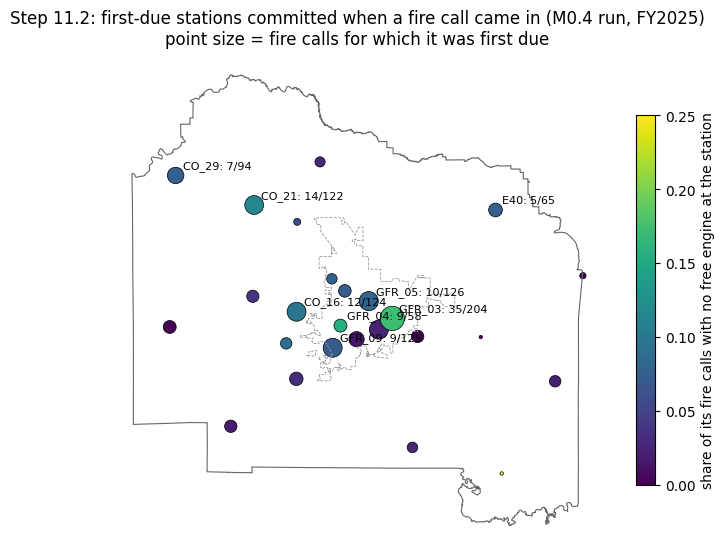

In [97]:
def summarize_first_due(versions, verbose=VERBOSE):
    """E1: per version (name -> check_first_due output) and group of fire calls (all four codes, each code, inside and
    outside the city, Jul-Sep): fire calls; the share whose first-due station had no free engine, with its weekly
    block-bootstrap interval; among those, the share held by a medical call and by a CAD Fire-category call; minutes to
    the first engine on scene (median, P90) when the station had a free engine and when it had none; and the extra
    modeled minutes of the engine that came. Also, per first-due station (where), fire calls and the committed share.

    Example: first_due_summary, first_due_by_station = summarize_first_due({"2025 record": first_due_record,
                                                                            "M0.4 protocol run": first_due_m04})
    """
    rows, stations = {}, {}
    for name, calls in versions.items():
        groups = [("all fire calls", calls.index), *[(code, calls.index[calls["code"] == code]) for code in STUDY_FIRE_PROTOCOLS],
                  ("inside city", calls.index[calls["inside_city"]]), ("outside city", calls.index[~calls["inside_city"]]),
                  ("Jul-Sep", calls.index[calls["received_at"] >= TRAVEL_TEST_FROM])]
        for group, ids in groups:
            part = calls.loc[ids]
            committed, free = part[part["committed"]], part[~part["committed"]]
            low, high = weekly_block_interval(part["committed"].astype(float), part["week"])
            rows[(name, group)] = {
                "fire calls": len(part), "no free first-due engine": part["committed"].mean(), "interval low": low, "interval high": high,
                "held by medical": committed["held_by_medical"].mean(), "held by Fire category": committed["held_by_fire_category"].mean(),
                "first on scene min, station free: P50": free["minutes_to_first_on_scene"].median(),
                "station free: P90": free["minutes_to_first_on_scene"].quantile(0.9),
                "station committed: P50": committed["minutes_to_first_on_scene"].median(),
                "station committed: P90": committed["minutes_to_first_on_scene"].quantile(0.9),
                "extra modeled min when committed: P50": committed["extra_modeled_min"].median()}
        station = calls.groupby("first_due_station").agg(fire_calls=("committed", "size"), committed=("committed", "sum"))
        station["share"] = station["committed"] / station["fire_calls"]
        stations[name] = station
    first_due_summary = pd.DataFrame(rows).T.rename_axis(["version", "calls"])
    first_due_by_station = pd.concat(stations, axis=1).sort_values((list(versions)[-1], "committed"), ascending=False)
    if verbose:
        print(f"--- fire calls whose first-due station had no free engine (95% weekly block-bootstrap interval)\n"
              f"{first_due_summary.round(3).to_string()}\n"
              f"by first-due station (where), ten with the most such calls:\n{first_due_by_station.head(10).round(3).to_string()}\n")
    return first_due_summary, first_due_by_station


import geopandas as gpd

first_due_summary, first_due_by_station = summarize_first_due({"2025 record": first_due_record, "M0.4 protocol run": first_due_m04})
county = gpd.read_file(PROJECT_ROOT / "data" / "raw" / "gnv_alachua" / "alachua_county_boundary.gpkg")
city = gpd.read_file(PROJECT_ROOT / "data" / "raw" / "gnv_alachua" / "gainesville_city_limits_2026.gpkg")
station_key = engines.set_index("engine_id")["home_station"].astype(object)
station_key = station_key.where(station_key.notna(), station_key.index.to_series())
station_points = engines.assign(station=station_key.to_numpy()).groupby("station")[["home_lon", "home_lat"]].mean()
mapped = station_points.join(first_due_by_station["M0.4 protocol run"], how="inner")
figure, axis = plt.subplots(figsize=(8, 8))
county.boundary.plot(ax=axis, color="0.4", linewidth=0.8)
city.boundary.plot(ax=axis, color="0.6", linewidth=0.6, linestyle="--")
points = axis.scatter(mapped["home_lon"], mapped["home_lat"], s=mapped["fire_calls"] * 1.5, c=mapped["share"], cmap="viridis",
                      edgecolor="black", linewidth=0.5)
for station, row in mapped[mapped["committed"] >= 5].iterrows():
    axis.annotate(f"{station}: {int(row['committed'])}/{int(row['fire_calls'])}", (row["home_lon"], row["home_lat"]),
                  xytext=(5, 5), textcoords="offset points", fontsize=8)
figure.colorbar(points, ax=axis, shrink=0.6, label="share of its fire calls with no free engine at the station")
axis.set_title("Step 11.2: first-due stations committed when a fire call came in (M0.4 run, FY2025)\npoint size = fire calls for which it was first due")
axis.set_axis_off()
plt.show()

## Step 11.3 — Fire-call intensity on 1 km cells

**Function.** `build_readiness_cells` gives the Oct–Mar fire calls per cell (call types with automatic aid vs own
agency only), the cell's agency and network node, the travel from every station, and the hour-of-day profile.
**Check.** The printed cells, and a map of where the training fire calls are.

--- readiness cells (training fire calls per cell) (425, 12)
   cell_x  cell_y  calls_aid  calls_other  gfr_share        lon        lat  cell_gfr  weight_aid  weight_own      node       snap_m
0     340    3271          0            1        0.0 -82.646858  29.558544     False    0.000000    0.001042  84934325   178.074692
1     340    3280          1            0        0.0 -82.647244  29.646569     False    0.001042    0.000000  84804790  1055.957890
2     341    3268          1            0        0.0 -82.634273  29.537499     False    0.001042    0.000000  84798500   418.168177
3     341    3276          0            1        0.0 -82.639706  29.609180     False    0.000000    0.001042  84885410     0.000000
4     341    3300          0            1        0.0 -82.644962  29.823081     False    0.000000    0.001042  84774663   200.933956

training fire calls: 960 in 425 cells of 1000 m; with automatic aid 436, own agency only 524; cells mostly GFR 105; snap distance median 99 m, P90

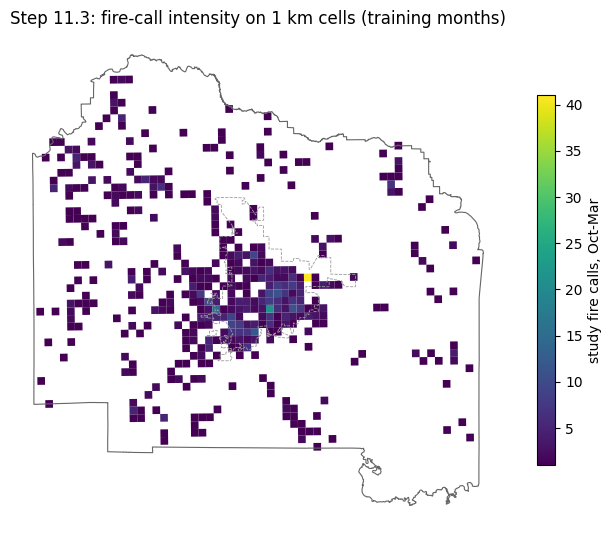

In [98]:
def build_readiness_cells(dispatches, graph, engines, home_nodes, aid_protocols, seconds_from_node, node_position,
                          travel_model, verbose=VERBOSE):
    """E1 (research.md 3.3, fire readiness): the fire-call intensity on READINESS_CELL_M square cells, from the study's
    fire calls in the training months (before TRAINING_MONTHS_END), and the modeled travel from every engine's home
    station to every cell. A cell keeps its share of those calls, split into call types with automatic aid (an engine
    of either agency may come) and the rest (only the cell's own agency: GFR, or everyone else, by the majority of its
    calls), and the mean position of its calls, snapped to the road network. Returns the cells (one row per cell with a
    training fire call), the travel table (rows: engines, columns: cells; seconds) and the share of training fire calls
    by hour of day (lambda_F(x, t) = cell share x hour share).

    Example: cells, travel_to_cells, hour_share = build_readiness_cells(dispatches, graph, engines, home_nodes,
                 aid_protocols, seconds_from_node, node_position, network_travel_model)
             cells[["weight_aid", "weight_own"]].to_numpy().sum() -> 1.0
    """
    calls = dispatches[dispatches["protocol"].isin(STUDY_FIRE_PROTOCOLS).fillna(False) & dispatches["incident_lon"].notna()
                       & (dispatches["call_received_at"] < TRAINING_MONTHS_END)].drop_duplicates("incident_id")
    x, y = pyproj.Transformer.from_crs("EPSG:4326", PROJECTED_CRS, always_xy=True).transform(
        calls["incident_lon"].to_numpy(), calls["incident_lat"].to_numpy())
    calls = calls.assign(cell_x=np.floor(x / READINESS_CELL_M).astype(int), cell_y=np.floor(y / READINESS_CELL_M).astype(int),
                         aid=calls["protocol"].isin(aid_protocols).to_numpy(), in_gfr=calls["jurisdiction"].eq("GFR").fillna(False).to_numpy())
    cells = calls.groupby(["cell_x", "cell_y"]).agg(
        calls_aid=("aid", "sum"), calls_other=("aid", lambda aid: int((~aid).sum())), gfr_share=("in_gfr", "mean"),
        lon=("incident_lon", "mean"), lat=("incident_lat", "mean")).reset_index()
    cells["cell_gfr"] = cells["gfr_share"] > 0.5
    cells["weight_aid"] = cells["calls_aid"] / len(calls)
    cells["weight_own"] = cells["calls_other"] / len(calls)
    cells["node"], cells["snap_m"] = ox.distance.nearest_nodes(graph, X=cells["lon"].to_numpy(), Y=cells["lat"].to_numpy(), return_dist=True)
    positions = node_position[cells["node"]].to_numpy()
    travel_to_cells = pd.DataFrame([travel_model(seconds_from_node(home_nodes[engine_id])[positions], np.nan)
                                    for engine_id in engines["engine_id"]], index=engines["engine_id"], columns=cells.index)
    hour_share = calls["call_received_at"].dt.hour.value_counts(normalize=True).reindex(range(24), fill_value=0.0)
    if verbose:
        show_table("readiness cells (training fire calls per cell)", cells, verbose)
        nearest = travel_to_cells.idxmin().to_numpy()
        print(f"training fire calls: {len(calls):,} in {len(cells):,} cells of {READINESS_CELL_M} m; with automatic aid "
              f"{int(cells['calls_aid'].sum()):,}, own agency only {int(cells['calls_other'].sum()):,}; cells mostly GFR "
              f"{int(cells['cell_gfr'].sum())}; snap distance median {cells['snap_m'].median():.0f} m, P90 {cells['snap_m'].quantile(0.9):.0f} m\n"
              f"busiest cells and their nearest engine (all idle):\n"
              f"{cells.assign(nearest_engine=nearest, nearest_min=travel_to_cells.min().to_numpy() / 60).nlargest(5, 'calls_aid')[['cell_x', 'cell_y', 'calls_aid', 'calls_other', 'cell_gfr', 'nearest_engine', 'nearest_min']].round(2).to_string()}\n"
              f"share of training fire calls by hour (0-23): {hour_share.round(3).tolist()}\n")
    return cells, travel_to_cells, hour_share


readiness_cells, travel_to_cells, fire_hour_share = build_readiness_cells(dispatches, graph, engines, home_nodes, aid_protocols,
                                                                          seconds_from_node, node_position, network_travel_model)
cell_squares = gpd.GeoDataFrame(
    readiness_cells.assign(calls=readiness_cells["calls_aid"] + readiness_cells["calls_other"]),
    geometry=gpd.GeoSeries.from_xy((readiness_cells["cell_x"] + 0.5) * READINESS_CELL_M,
                                   (readiness_cells["cell_y"] + 0.5) * READINESS_CELL_M, crs=PROJECTED_CRS).buffer(READINESS_CELL_M / 2, cap_style="square"),
    crs=PROJECTED_CRS).to_crs("EPSG:4326")
figure, axis = plt.subplots(figsize=(8, 8))
county.boundary.plot(ax=axis, color="0.4", linewidth=0.8)
city.boundary.plot(ax=axis, color="0.6", linewidth=0.6, linestyle="--")
cell_squares.plot(ax=axis, column="calls", cmap="viridis", legend=True, legend_kwds={"shrink": 0.6, "label": "study fire calls, Oct-Mar"})
axis.set_title("Step 11.3: fire-call intensity on 1 km cells (training months)")
axis.set_axis_off()
plt.show()

## Step 11.4 — Fire readiness over the year

**Function.** `fire_readiness` gives R (idle engines) and R_full (every engine idle) per segment between dispatches and
clears, cut at every hour; per-cell means; and the year, by month and by hour.
**Check.**
- Hand-calculated toys: two engines and two cells, and all hourly weight at midnight.
- The record and the M0.4 run.
- The loss by hour of day, and a map of where the loss falls (M0.4 run).

toy: Ea (GFR) busy the first hour; cell 0 (GFR, aid types), cell 1 (outside GFR, own agency); travel Ea 2 / 10 min, Eb 5 / 3 min
   start_s   end_s  idle_engines  R_min  R_full_min  loss_min
0      0.0  3600.0             1    4.0         2.5       1.5
1   3600.0  7200.0             2    2.5         2.5       0.0
hand: first hour R = 0.5 x 5 + 0.5 x 3 = 4.0, R_full = 0.5 x 2 + 0.5 x 3 = 2.5
all hourly weight at midnight: year R 2.50411 (hand: (4.0 + 364 x 2.5) / 365 = 2.50411)



--- readiness segments (between dispatches and clears) (80079, 6)
   start_s   end_s  idle_engines  R_min  R_full_min  loss_min
0      0.0   427.0            27  6.010        6.01     0.000
1    427.0  2734.0            26  6.010        6.01     0.000
2   2734.0  2858.0            25  6.129        6.01     0.119
3   2858.0  3600.0            26  6.017        6.01     0.008
4   3600.0  4127.0            26  6.017        6.01     0.008

segments: 80,079; hours: 8,760; idle engines per segment: median 26, min 12
--- fire readiness (minutes; R: idle engines, R_full: every in-service engine idle)
                                                  R_min  R_full_min  loss_min
year, hour-weighted                               6.221       6.013     0.208
year, time-weighted                               6.194       6.013     0.181
month 2024-10                                     6.185       6.010     0.175
month 2024-11                                     6.185       6.010     0.176
month 2024-

--- readiness segments (between dispatches and clears) (80215, 6)
   start_s    end_s  idle_engines  R_min  R_full_min  loss_min
0     0.00   427.00            27   6.01        6.01       0.0
1   427.00  2232.43            26   6.01        6.01       0.0
2  2232.43  2734.00            27   6.01        6.01       0.0
3  2734.00  3600.00            26   6.01        6.01       0.0
4  3600.00  4161.49            26   6.01        6.01       0.0

segments: 80,215; hours: 8,760; idle engines per segment: median 26, min 12
--- fire readiness (minutes; R: idle engines, R_full: every in-service engine idle)
                                                  R_min  R_full_min  loss_min
year, hour-weighted                               6.224       6.013     0.211
year, time-weighted                               6.196       6.013     0.183
month 2024-10                                     6.187       6.010     0.177
month 2024-11                                     6.186       6.010     0.176
month

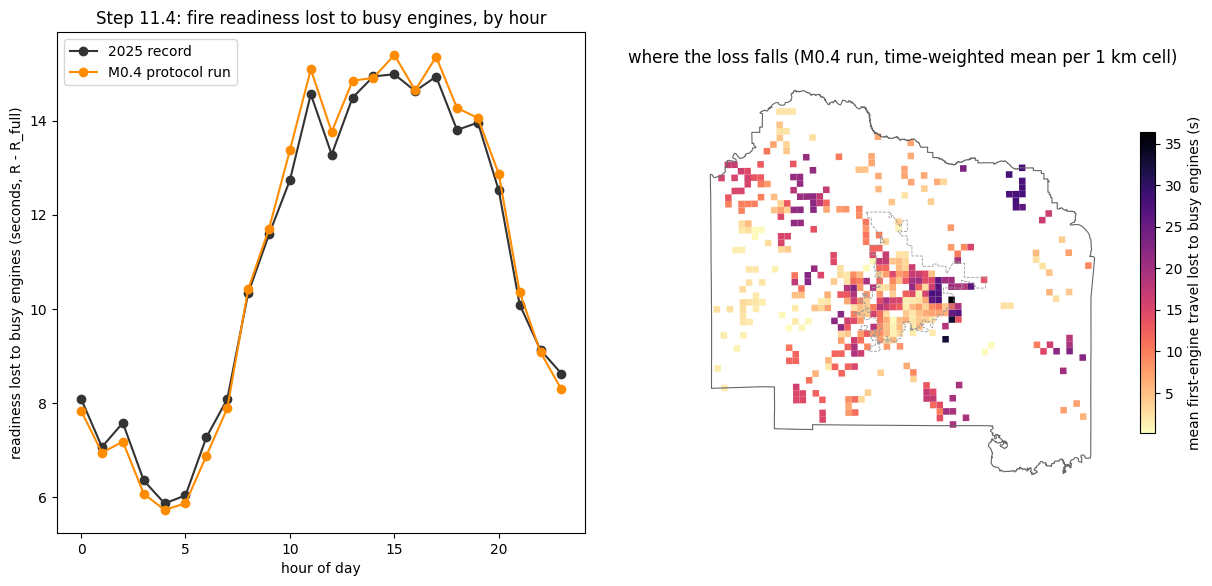

In [99]:
def fire_readiness(runs_table, engines, cells, travel_to_cells, hour_share, wait_for_busy=False, verbose=VERBOSE):
    """E1 (research.md 3.3): fire readiness over FY2025. Between consecutive dispatches, clears and in-service changes
    the set of idle engines is fixed; in each such segment tau(x) is the modeled travel to cell x from the nearest idle
    engine allowed there (the cell's own agency for call types without automatic aid, either agency for the rest), and
    readiness R is the fire-call-weighted mean of tau over the cells, in minutes. R_full is the same with every
    in-service engine idle, so R - R_full is the fire protection lost to engines being busy. Idle engines are placed at
    their home stations. Segments are also cut at every hour, and the yearly value weights each segment by its length
    and its hour's share of training fire calls. Returns the segments (start, end, idle engines, R and R_full), the cells with their time-weighted mean tau and
    tau_full (minutes), and the summary (year; by month; by hour; time-weighted quantiles of R - R_full).
    A segment where some weighted cell has no idle allowed engine is left out (E1: 1-2 a year). With wait_for_busy
    (Section 13; research.md 3.3: tau includes the wait when no engine is free) such a cell instead gets the least
    (minutes until an allowed in-service engine clears, at the segment's middle, + its travel from its station), and the
    segments get waiting_weight, the weight of those cells: every candidate's wait shrinks a minute per minute and no
    run clears inside a segment, so R falls by waiting_weight minutes per minute inside it and its middle value is its mean.

    Example: segments, cell_tau, readiness_summary = fire_readiness(m04_protocol, engines, cells, travel_to_cells, hour_share)
             readiness_summary.loc["year, hour-weighted", "R min"] -> readiness in minutes
             toy: one engine 5 min from the only cell, on a run from 0 to 600 s: the segment 0-600 s (middle 300 s) is
             left out; with wait_for_busy its R = (600 - 300) / 60 + 5 = 10 min and waiting_weight 1 (R runs from 15 to 5 min)
    """
    engine_ids = travel_to_cells.index
    year_end_s = (YEAR_END - DAY_ZERO).total_seconds()
    service = engines.set_index("engine_id").loc[engine_ids]
    service_from = (service["in_service_from"] - DAY_ZERO).dt.total_seconds().to_numpy()
    service_to = (service["in_service_to"] - DAY_ZERO).dt.total_seconds().to_numpy()
    sent = runs_table.dropna(subset=["engine_id", "dispatched_at", "cleared_at"])
    every_hour = np.arange(0.0, year_end_s, 3600.0)             # cut at every hour (so at every month too): a segment takes one hour's weight
    times = np.unique(np.clip(np.concatenate([[0.0, year_end_s], every_hour, sent["dispatched_at"], sent["cleared_at"], service_from,
                                              service_to]), 0.0, year_end_s))
    starts, ends = times[:-1], times[1:]
    middle, duration = (starts + ends) / 2, ends - starts
    in_service = (middle[:, None] >= service_from) & (middle[:, None] < service_to)
    holders = holding_runs(runs_table, engine_ids, middle)
    idle = in_service & (holders < 0)
    if wait_for_busy:                                            # minutes until each engine's holding run clears (0 when idle)
        clears = runs_table["cleared_at"].reindex(holders.ravel()).to_numpy(dtype=float).reshape(holders.shape)
        wait_min = np.where(holders >= 0, (clears - middle[:, None]) / 60, 0.0)
    travel_min = travel_to_cells.to_numpy() / 60
    own_agency = (service["engine_agency"] == "GFR").to_numpy()[:, None] == cells["cell_gfr"].to_numpy()[None, :]
    aid_cells, own_cells = (cells["weight_aid"] > 0).to_numpy(), (cells["weight_own"] > 0).to_numpy()
    weight_aid, weight_own = cells["weight_aid"].to_numpy()[aid_cells], cells["weight_own"].to_numpy()[own_cells]
    cell_weight = (cells["weight_aid"] + cells["weight_own"]).to_numpy()
    readiness, cell_minutes = {}, {}
    waiting_weight = np.zeros(len(starts))                       # weight of the cells whose tau includes a wait (wait_for_busy)
    for name, available in [("R", idle), ("R_full", in_service)]:
        values, cell_total, cell_time = np.empty(len(starts)), np.zeros(len(cells)), np.zeros(len(cells))
        for chunk in range(0, len(starts), READINESS_CHUNK):
            part = slice(chunk, chunk + READINESS_CHUNK)
            tau_any = np.where(available[part, :, None], travel_min[None], np.inf).min(axis=1)
            tau_own = np.where(available[part, :, None] & own_agency[None], travel_min[None], np.inf).min(axis=1)
            if wait_for_busy and name == "R":
                stuck = np.flatnonzero(~np.isfinite(tau_any[:, aid_cells]).all(axis=1) | ~np.isfinite(tau_own[:, own_cells]).all(axis=1))
                if len(stuck):                                   # a weighted cell with no idle allowed engine: wait for the first to clear
                    segment_rows = np.arange(len(starts))[part][stuck]
                    waited = np.where(in_service[segment_rows, :, None], wait_min[segment_rows, :, None] + travel_min[None], np.inf)
                    stuck_any, stuck_own = np.isinf(tau_any[stuck]), np.isinf(tau_own[stuck])
                    tau_any[stuck] = np.where(stuck_any, waited.min(axis=1), tau_any[stuck])
                    tau_own[stuck] = np.where(stuck_own, np.where(own_agency[None], waited, np.inf).min(axis=1), tau_own[stuck])
                    waiting_weight[segment_rows] = stuck_any[:, aid_cells] @ weight_aid + stuck_own[:, own_cells] @ weight_own
            values[part] = tau_any[:, aid_cells] @ weight_aid + tau_own[:, own_cells] @ weight_own
            tau_cell = (np.where(aid_cells, tau_any, 0) * cells["weight_aid"].to_numpy()
                        + np.where(own_cells, tau_own, 0) * cells["weight_own"].to_numpy()) / cell_weight
            reachable = np.isfinite(tau_cell)      # ponytail: a segment with no allowed idle engine for a cell is left out, not given a wait (1-2 segments a year)
            cell_total += duration[part] @ np.where(reachable, tau_cell, 0.0)
            cell_time += duration[part] @ reachable
        readiness[name], cell_minutes[name] = values, cell_total / cell_time
    segments = pd.DataFrame({"start_s": starts, "end_s": ends, "idle_engines": idle.sum(axis=1), "R_min": readiness["R"],
                             "R_full_min": readiness["R_full"]})
    segments["loss_min"] = segments["R_min"] - segments["R_full_min"]
    if wait_for_busy:                                            # R falls by this many minutes per minute inside the segment
        segments["waiting_weight"] = waiting_weight
    cell_tau = cells[["cell_x", "cell_y", "lon", "lat", "calls_aid", "calls_other", "cell_gfr"]].assign(
        tau_full_min=cell_minutes["R_full"], tau_min=cell_minutes["R"], loss_min=cell_minutes["R"] - cell_minutes["R_full"])
    hour = (starts // 3600 % 24).astype(int)
    month = (DAY_ZERO + pd.to_timedelta(starts, unit="s")).strftime("%Y-%m")
    finite = np.isfinite(segments["R_min"].to_numpy())
    weight = duration * hour_share.to_numpy()[hour] * finite

    def weighted(mask, column, weights):
        return float(np.sum(segments[column].to_numpy()[mask & finite] * weights[mask & finite]) / np.sum(weights[mask & finite]))

    every = np.ones(len(starts), dtype=bool)
    summary_rows = {"year, hour-weighted": {column: weighted(every, column, weight) for column in ["R_min", "R_full_min", "loss_min"]},
                    "year, time-weighted": {column: weighted(every, column, duration) for column in ["R_min", "R_full_min", "loss_min"]}}
    for label, mask in [*[(f"month {m}", month == m) for m in sorted(set(month))], *[(f"hour {h:02d}", hour == h) for h in range(24)]]:
        summary_rows[label] = {column: weighted(mask, column, duration) for column in ["R_min", "R_full_min", "loss_min"]}
    readiness_summary = pd.DataFrame(summary_rows).T
    for quantile in (0.5, 0.9, 0.99):
        readiness_summary.loc[f"loss, time-weighted P{int(quantile * 100)}", "loss_min"] = np.quantile(
            segments["loss_min"].to_numpy()[finite], quantile, weights=duration[finite], method="inverted_cdf")
    readiness_summary.loc["hours with loss over 1 min", "loss_min"] = duration[finite & (segments["loss_min"].to_numpy() > 1)].sum() / 3600
    readiness_summary.loc["segments with a cell no allowed engine can reach", "loss_min"] = int((~finite).sum())
    readiness_summary.loc["minutes in those segments (left out)", "loss_min"] = duration[~finite].sum() / 60
    if verbose:
        show_table("readiness segments (between dispatches and clears)", segments.round(3), verbose)
        print(f"segments: {len(segments):,}; hours: {duration.sum() / 3600:,.0f}; idle engines per segment: median "
              f"{np.median(segments['idle_engines']):.0f}, min {segments['idle_engines'].min()}\n"
              f"--- fire readiness (minutes; R: idle engines, R_full: every in-service engine idle)\n{readiness_summary.round(3).to_string()}\n"
              f"cells losing the most (time-weighted mean tau minus tau with every engine idle):\n"
              f"{cell_tau.nlargest(5, 'loss_min').round(2).to_string()}\n")
    return segments, cell_tau, readiness_summary


toy_engines = pd.DataFrame({"engine_id": ["Ea", "Eb"], "engine_agency": ["GFR", "non-GFR"],
                            "in_service_from": [DAY_ZERO] * 2, "in_service_to": [YEAR_END] * 2})
toy_cells = pd.DataFrame({"cell_x": [0, 1], "cell_y": [0, 0], "lon": [0.0, 0.0], "lat": [0.0, 0.0], "calls_aid": [1, 0],
                          "calls_other": [0, 1], "cell_gfr": [True, False], "weight_aid": [0.5, 0.0], "weight_own": [0.0, 0.5]})
toy_travel = pd.DataFrame([[120.0, 600.0], [300.0, 180.0]], index=pd.Index(["Ea", "Eb"], name="engine_id"), columns=toy_cells.index)
toy_busy = pd.DataFrame({"engine_id": ["Ea"], "dispatched_at": [0.0], "cleared_at": [3600.0]})
toy_segments, _, _ = fire_readiness(toy_busy, toy_engines, toy_cells, toy_travel, pd.Series(1 / 24, index=range(24)), verbose=False)
_, _, midnight_summary = fire_readiness(toy_busy, toy_engines, toy_cells, toy_travel, pd.Series([1.0] + [0.0] * 23, index=range(24)),
                                        verbose=False)
print(f"toy: Ea (GFR) busy the first hour; cell 0 (GFR, aid types), cell 1 (outside GFR, own agency); travel Ea 2 / 10 min, Eb 5 / 3 min\n"
      f"{toy_segments.head(2).round(3).to_string()}\n"
      f"hand: first hour R = 0.5 x 5 + 0.5 x 3 = 4.0, R_full = 0.5 x 2 + 0.5 x 3 = 2.5\n"
      f"all hourly weight at midnight: year R {midnight_summary.loc['year, hour-weighted', 'R_min']:.5f} (hand: (4.0 + 364 x 2.5) / 365 = "
      f"{(4.0 + 364 * 2.5) / 365:.5f})\n")
assert np.allclose(toy_segments[["R_min", "R_full_min"]].to_numpy()[:2], [[4.0, 2.5], [2.5, 2.5]])
assert np.isclose(midnight_summary.loc["year, hour-weighted", "R_min"], (4.0 + 364 * 2.5) / 365)

readiness = {name: fire_readiness(runs_table, engines, readiness_cells, travel_to_cells, fire_hour_share)
             for name, runs_table in [("2025 record", m0_runs), ("M0.4 protocol run", m04_protocol)]}
figure, (hours_axis, map_axis) = plt.subplots(1, 2, figsize=(15, 6.5))
for (name, (_, _, summary)), color in zip(readiness.items(), ["0.2", "darkorange"]):
    by_hour = summary.loc[[f"hour {h:02d}" for h in range(24)], "loss_min"] * 60
    hours_axis.plot(range(24), by_hour.to_numpy(), marker="o", color=color, label=name)
hours_axis.set_xlabel("hour of day")
hours_axis.set_ylabel("readiness lost to busy engines (seconds, R - R_full)")
hours_axis.set_title("Step 11.4: fire readiness lost to busy engines, by hour")
hours_axis.legend()
loss_cells = cell_squares.assign(loss_s=readiness["M0.4 protocol run"][1]["loss_min"].to_numpy() * 60)
county.boundary.plot(ax=map_axis, color="0.4", linewidth=0.8)
city.boundary.plot(ax=map_axis, color="0.6", linewidth=0.6, linestyle="--")
loss_cells.plot(ax=map_axis, column="loss_s", cmap="magma_r", legend=True,
                legend_kwds={"shrink": 0.6, "label": "mean first-engine travel lost to busy engines (s)"})
map_axis.set_title("where the loss falls (M0.4 run, time-weighted mean per 1 km cell)")
map_axis.set_axis_off()
plt.show()

## Section 11 evidence

- **Earlier sections are unchanged.** All 74 earlier output files are byte-identical after the full run. The hand-calculated toys pass: `holding_runs`, readiness with two engines and two cells, and all hourly weight at midnight.
- **How often.** A fire call's first-due station had no free engine for:
  - 121 of 1,702 study fire calls in the 2025 record: 7.1%, interval 5.9–8.4%;
  - 126 in the M0.4 run: 7.4%, interval 6.3–8.5%.

  In Jul–Sep the shares are 7.8% (record) and 6.6% (M0.4). research.md's earlier straight-line count was 127 (7.5%).
  - The two versions agree on 97 calls; 24 calls are committed only in the record and 29 only in the run.
  - By code (M0.4): outside fires 9.3%, brush fires 8.8%, vehicle fires 7.3%, structure fires 5.1%. Inside the city 9.2%; outside 5.9%.
- **Held by what.** Medical calls held the station's engines in 57% of committed fire calls (record 59%); calls in the CAD Fire category in 35%. The top holder codes are E06, E17, F69, F52, F77 and F82.
- **Where.** The station most often committed is GFR_03: 35 of its 204 fire calls in the M0.4 run (17%), 28 (14%) in the record. GFR_03, CO_21 and CO_16 together hold 48% of the modeled cases.
- **Delay (an association across different calls, not a causal effect).**
  - First engine on scene: median 8.2 min when the station was free and 9.9 min when it was committed (M0.4); in the record, 8.3 and 9.6.
  - The engine that came was 2.0 modeled minutes farther from home than the first-due engine (median).
  - Spread over all fire calls, that home-travel gap is about 10 s per call (11 s per reached call; 8–9 s in Jul–Sep). This is a descriptive gap, not an upper bound on what a policy could gain.
- **Fire readiness** (Oct–Mar fire calls on 425 cells of 1 km; idle engines at their stations).
  - Year, hour-weighted: R = 6.22 min, against 6.01 with every engine idle. The loss is 12.5 s in the record and 12.7 s in the M0.4 run.
  - Time-weighted P90 of the loss: 27 s; P99: 62 s. The loss exceeds one minute for 93–96 hours a year.
  - The loss peaks at 11:00–17:00 (about 15 s) and is lowest at 03:00–05:00 (about 6 s).
  - The cells losing the most are east of Gainesville, where only ACFR engines answer non-aid call types.
- **Next.** The reviewer suggests the opportunity-cost rule and paired branch simulations before extensive training. A 10 s improvement would be about 79% of the 12.7 s readiness gap. So the aggregate room is limited and the losses are concentrated in place and time.

# Section 12 — The opportunity-cost rule: its room, its year against the protocol, and paired branches

**Why.** research.md compares the learned policy with a simple opportunity-cost rule (3.4). E1 found that busy engines
cost fire readiness about 12.7 s, about the margin m. So before training RL, we measure how much the permitted actions
can change. The agent acts only on low-acuity calls, among engines within Δa of the protocol's engine. This is the room
an RL agent will have. RL stays in the plan whatever the result.

**What is built.** Low-acuity calls are SOC low-priority medical calls plus F53 service calls (7,943 runs). The
opportunity cost of an engine is how much E1's fire readiness R would rise if it left now (idle engines at their
stations). The rule works as follows:
- On a low-acuity call, consider the engines ranked within ACTION_WINDOW_S (60 s; 30 s and 120 s as sensitivity) of the
  protocol's engine.
- Send the one that costs the least readiness. A saving of 1 s or less keeps the protocol's engine; co-located engines
  differ by a few metres.
- Everything else stays the M0.4 protocol.

**The steps.**
- 12.1: the opportunity cost and the rule on toys and on a real decision.
- 12.2: a census of the room on the M0.4 run.
- 12.3: the rule's year against the protocol's under the same travel draws, for five seeds and three windows.
- 12.4: paired branches. For 300 decisions, the protocol and the rule run from the same rebuilt state, two hours ahead.

**Input/output check before running (gpt-6-astra, read-only).** The first round had three MUSTs:
- Branches must rebuild the full state. The warm-up is now 24 h, and a decision counts only if branch A reproduces the
  full run's engines, times and readiness.
- The rule's alternative must be re-checked in the rebuilt state, with returning engines placed. Branch B now applies
  the rule itself at the decision.
- Missing engine ids must compare equal. A comparison of the protocol with itself now shows zero changes.

The second round: PASS.

## Step 12.1 — The opportunity cost and the rule

**Functions.** `make_readiness_tools` gives readiness for one set of idle engines and the opportunity cost.
`choose_by_opportunity_cost` makes the rule's choice, and `dispatch_by_opportunity_cost` is the rule as a dispatch
function.
**Check.**
- Hand-calculated toys: three engines and two cells; the rule under three windows and on a call that is not low-acuity.
- One real low-acuity decision printed in full.

In [100]:
LOW_ACUITY_SERVICE_PROTOCOLS = ["F53"]                                      # [SOURCE] research.md 3.2: low-acuity = SOC low-priority medical codes or a service call (F53 citizen assist)
ACTION_WINDOW_S = 60                                                        # [DESIGN] research.md 3.2 Delta-a (provisional): an engine ranked this close to the protocol's may be sent instead on a low-acuity call
ACTION_WINDOWS_S = [30, ACTION_WINDOW_S, 120]                               # [DESIGN] Section 12: action windows counted in the census and tried in the year (sensitivity)
MEDICAL_MARGIN_S = 10                                                       # [SOURCE] research.md: delta (provisional 10 s), the allowed rise in the high-acuity medical P90
HIGH_ACUITY_LEVELS = ["C", "D", "E"]                                        # [SOURCE] research.md 3.2: Charlie, Delta and Echo medical calls always get the closest engine
HOTSPOT_STATIONS = ["GFR_03", "CO_21", "CO_16"]                             # [SOURCE] E1: first-due stations with 48% of the committed fire calls (pre-specified subgroup)
DAYTIME_HOURS = range(10, 21)                                               # [SOURCE] E1: hours whose readiness loss exceeds the yearly mean (pre-specified subgroup)
POLICY_SEEDS = [TRAVEL_SPREAD_SEED, 1, 2, 3, 4]                             # [DESIGN] Section 12.3: travel-draw seeds shared by both policies (the M0.4 seed first)
BRANCH_DECISIONS = 300                                                      # [DESIGN] Section 12.4: sampled decisions for paired branches
BRANCH_STRATA = 5                                                           # [DESIGN] Section 12.4: equal-count strata of opportunity cost saved, sampled evenly
BRANCH_HORIZON_S = 7200                                                     # [DESIGN] Section 12.4: branch length after the decision (about one engine outing and return)
BRANCH_WARMUP_S = 24 * 3600                                                 # [DESIGN] Section 12.4: calls simulated before the decision to rebuild the engines' state (checked against the full run)
BRANCH_SEED = 20250101                                                      # [DESIGN] Section 12.4: seed of the decision sample
OC_TIE_S = 1.0                                                              # [DESIGN] Section 12: the rule changes the engine only if it saves more than this much fire readiness (s); co-located engines differ by a few metres


def make_readiness_tools(cells, travel_to_cells, engines):
    """Section 12 (research.md 3.3-3.4): E1's fire readiness for one set of idle engines, and the opportunity cost of
    sending an engine. readiness_of(idle mask over travel_to_cells' engines) -> (R in minutes, tau per cell in minutes):
    the fire-call-weighted mean travel from the nearest idle allowed engine at its station (the formula of
    fire_readiness, for one set). opportunity_cost(idle engine ids, candidate ids) -> Series candidate -> minutes: how
    much R rises if that engine leaves now, OC(e) = R(idle without e) - R(idle); inf when it is the only idle engine
    allowed in some weighted cell.

    Example: readiness_of, opportunity_cost = make_readiness_tools(readiness_cells, travel_to_cells, engines)
             opportunity_cost(["E1", "E3", "E5"], ["E1", "E3"]) -> E1 0.21, E3 0.08 (minutes), roughly
    """
    engine_ids = travel_to_cells.index
    position = pd.Series(np.arange(len(engine_ids)), index=engine_ids)
    travel_min = travel_to_cells.to_numpy() / 60
    own_agency = (engines.set_index("engine_id").loc[engine_ids, "engine_agency"] == "GFR").to_numpy()[:, None] == cells["cell_gfr"].to_numpy()[None, :]
    weight_aid, weight_own = cells["weight_aid"].to_numpy(), cells["weight_own"].to_numpy()

    def readiness_of(idle):
        tau_any = np.where(idle[:, None], travel_min, np.inf).min(axis=0)
        tau_own = np.where(idle[:, None] & own_agency, travel_min, np.inf).min(axis=0)
        weighted = np.where(weight_aid > 0, tau_any, 0.0) * weight_aid + np.where(weight_own > 0, tau_own, 0.0) * weight_own
        return float(weighted.sum()), weighted / (weight_aid + weight_own)

    def opportunity_cost(idle_engine_ids, candidate_ids):
        idle = np.zeros(len(engine_ids), dtype=bool)
        idle[position[list(idle_engine_ids)].to_numpy()] = True
        now, _ = readiness_of(idle)
        costs = {}
        for engine_id in candidate_ids:
            without = idle.copy()
            without[position[engine_id]] = False
            costs[engine_id] = readiness_of(without)[0] - now
        return pd.Series(costs, dtype=float)

    return readiness_of, opportunity_cost


def choose_by_opportunity_cost(run, available_engines, travel_for_run, rank_penalty, low_acuity, action_window_s, opportunity_cost):
    """Section 12 rule (research.md 3.2 and 3.4), the choice alone: the M0.4 protocol's engine, except on a low-acuity
    call (low_acuity: run row -> bool). There, among the available engines whose ranking (modeled travel from where
    each is, plus rank_penalty) is within action_window_s of the protocol's engine, the one whose departure costs the
    least fire readiness (opportunity_cost); a saving of OC_TIE_S or less keeps the protocol's engine. Returns the
    protocol's engine, the engine to send, and the opportunity costs of the engines in the window (empty when the call
    is not low-acuity or has one engine in it).

    Example: choose_by_opportunity_cost(m0_runs.loc[25], available, travel_for_run, rank_penalty, low_acuity, 60, opportunity_cost)
             -> ('E21', 'E28', E21 0.179 / E24 0.108 / E28 0.002 minutes)
    """
    protocol_engine, protocol_travel = dispatch_closest(run, available_engines, travel_for_run, rank_penalty)
    costs = pd.Series(dtype=float)
    if protocol_travel is not None and low_acuity[run.name]:
        ranked = (travel_for_run[available_engines] + rank_penalty.reindex(available_engines, fill_value=0.0)).dropna()
        near = ranked.index[ranked <= ranked[protocol_engine] + action_window_s]
        if len(near) > 1:
            costs = opportunity_cost(available_engines, near)
    chosen = costs.idxmin() if len(costs) and costs[protocol_engine] - costs.min() > OC_TIE_S / 60 else protocol_engine
    return protocol_engine, chosen, costs


def dispatch_by_opportunity_cost(run, available_engines, travel_for_run, spread, inside_city, spread_quantile, rank_penalty,
                                 low_acuity, action_window_s, opportunity_cost):
    """Section 12 rule as a dispatch function for simulate: choose_by_opportunity_cost picks the engine, which then takes
    its own modeled travel x the drawn ratio, as in dispatch_closest_with_spread.

    Example: dispatch_by_opportunity_cost(m0_runs.loc[25], available, travel_for_run, travel_spread, call_inside_city,
                                          spread_quantile, rank_penalty, low_acuity, ACTION_WINDOW_S, opportunity_cost)
             -> ('E28', 830.4)  # E21 was 49 s closer but leaves more fire readiness uncovered
    """
    _, chosen, _ = choose_by_opportunity_cost(run, available_engines, travel_for_run, rank_penalty, low_acuity, action_window_s,
                                              opportunity_cost)
    return dispatch_closest_with_spread(run, available_engines if chosen is None else [chosen], travel_for_run, spread, inside_city,
                                        spread_quantile, rank_penalty)


toy_engines = pd.DataFrame({"engine_id": ["Ea", "Eb", "Ec"], "engine_agency": ["GFR"] * 3,
                            "in_service_from": [DAY_ZERO] * 3, "in_service_to": [YEAR_END] * 3})
toy_cells = pd.DataFrame({"cell_x": [0, 1], "cell_y": [0, 0], "lon": [0.0, 0.0], "lat": [0.0, 0.0], "calls_aid": [1, 1],
                          "calls_other": [0, 0], "cell_gfr": [True, True], "weight_aid": [0.5, 0.5], "weight_own": [0.0, 0.0]})
toy_travel = pd.DataFrame([[120.0, 420.0], [240.0, 180.0], [360.0, 210.0]], index=pd.Index(["Ea", "Eb", "Ec"], name="engine_id"),
                          columns=toy_cells.index)
toy_readiness_of, toy_cost = make_readiness_tools(toy_cells, toy_travel, toy_engines)
toy_costs = toy_cost(["Ea", "Eb", "Ec"], ["Ea", "Eb", "Ec"])
print(f"toy: travel (min) Ea 2 / 7, Eb 4 / 3, Ec 6 / 3.5 to cells 0 / 1 (weights 0.5 each); all idle R = "
      f"{toy_readiness_of(np.array([True, True, True]))[0]:.2f} (hand 2.5)\n"
      f"opportunity costs (min): {toy_costs.round(3).to_dict()} (hand: Ea 0.5 x (4 - 2) = 1.0, Eb 0.5 x (3.5 - 3) = 0.25, Ec 0)")
assert np.allclose(toy_costs[["Ea", "Eb", "Ec"]], [1.0, 0.25, 0.0])
flat_spread = {flag: (np.array([]), [np.array([1.0])]) for flag in (True, False)}
toy_call = pd.Series({"engine_id": "Ea"}, name=0)
for low, window, expected in [(True, 60, "Eb"), (True, 120, "Ec"), (True, 30, "Ea"), (False, 120, "Ea")]:
    sent = dispatch_by_opportunity_cost(toy_call, ["Ea", "Eb", "Ec"], pd.Series({"Ea": 200.0, "Eb": 240.0, "Ec": 300.0}), flat_spread,
                                        pd.Series({0: False}), pd.Series({0: 0.5}), pd.Series(0.0, index=["Ea", "Eb", "Ec"]),
                                        pd.Series({0: low}), window, toy_cost)
    print(f"toy call (Ea 200 s, Eb 240 s, Ec 300 s), low-acuity {low}, window {window} s: sends {sent} (hand: {expected})")
    assert sent[0] == expected

low_acuity = ((dispatches["call_type"].eq("Medical") & dispatches["priority"].eq("Low")).fillna(False)
              | dispatches["protocol"].isin(LOW_ACUITY_SERVICE_PROTOCOLS).fillna(False))
readiness_of, opportunity_cost = make_readiness_tools(readiness_cells, travel_to_cells, engines)
example_row = 25
example_moment = m04_protocol.at[example_row, "dispatched_at"]
example_holders = holding_runs(m04_protocol, list(boundary_travel.columns), np.array([example_moment]))[0]
example_idle = [e for e, h in zip(boundary_travel.columns, example_holders) if h < 0 or h == example_row]
example_ranked = (boundary_travel.loc[example_row, example_idle]
                  + quint_indicator.reindex(example_idle) * quint_penalty_of_run[example_row]).dropna().sort_values()
example_near = example_ranked[example_ranked <= example_ranked.iloc[0] + ACTION_WINDOW_S]
print(f"\nlow-acuity runs: {int(low_acuity.sum()):,} of {len(dispatches):,}\n"
      f"=== decision {example_row}: {dispatches.at[example_row, 'problem']} ({dispatches.at[example_row, 'priority']}), "
      f"{DAY_ZERO + pd.Timedelta(seconds=example_moment)}; {len(example_idle)} idle engines\n"
      f"engines within {ACTION_WINDOW_S} s of the closest (ranked travel from home, s): {example_near.round(1).to_dict()}\n"
      f"their opportunity costs (s of fire readiness): {(opportunity_cost(example_idle, example_near.index) * 60).round(2).to_dict()}")

toy: travel (min) Ea 2 / 7, Eb 4 / 3, Ec 6 / 3.5 to cells 0 / 1 (weights 0.5 each); all idle R = 2.50 (hand 2.5)
opportunity costs (min): {'Ea': 1.0, 'Eb': 0.25, 'Ec': 0.0} (hand: Ea 0.5 x (4 - 2) = 1.0, Eb 0.5 x (3.5 - 3) = 0.25, Ec 0)
toy call (Ea 200 s, Eb 240 s, Ec 300 s), low-acuity True, window 60 s: sends ('Eb', 240.0) (hand: Eb)
toy call (Ea 200 s, Eb 240 s, Ec 300 s), low-acuity True, window 120 s: sends ('Ec', 300.0) (hand: Ec)
toy call (Ea 200 s, Eb 240 s, Ec 300 s), low-acuity True, window 30 s: sends ('Ea', 200.0) (hand: Ea)
toy call (Ea 200 s, Eb 240 s, Ec 300 s), low-acuity False, window 120 s: sends ('Ea', 200.0) (hand: Ea)

low-acuity runs: 7,943 of 37,194
=== decision 25: E03A - ANIMAL BITE (Low), 2024-10-01 17:21:57; 28 idle engines
engines within 60 s of the closest (ranked travel from home, s): {'E21': 761.8, 'E24': 800.6, 'E28': 810.4}
their opportunity costs (s of fire readiness): {'E21': 10.71, 'E24': 6.46, 'E28': 0.11}


## Step 12.2 — The room: a census of low-acuity decisions on the M0.4 run

**Function.** `census_decisions` counts, per low-acuity decision and window: the engines in the window, the engine the
rule would send, the readiness it saves and its extra travel. No simulation is involved.
**Check.** The summary by window, and a map of where the rule would change the engine (60 s).

--- low-acuity decisions on the protocol run: the room for another engine
                                                                     30 s      60 s     120 s
low-acuity decisions                                             7932.000  7932.000  7932.000
with two or more engines in the window                              0.240     0.386     0.524
rule sends another engine                                           0.068     0.125     0.226
  per day                                                           1.485     2.710     4.921
  readiness saved when it does (s), median                          6.031     6.015     6.697
  extra modeled travel to the call (s), median                     15.217    29.900    62.173
  saving infinite (protocol engine was the last one for a cell)     0.000     0.000     0.000
protocol engine (from the stations) equals the engine the run sent: 98.8%
examples where the rule sends another engine:
          dispatched_at  inside_city protocol_engine s

/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/2408943026.py:59: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  f"examples where the rule sends another engine:\n{changed.head(5).round(3).to_string()}\n")


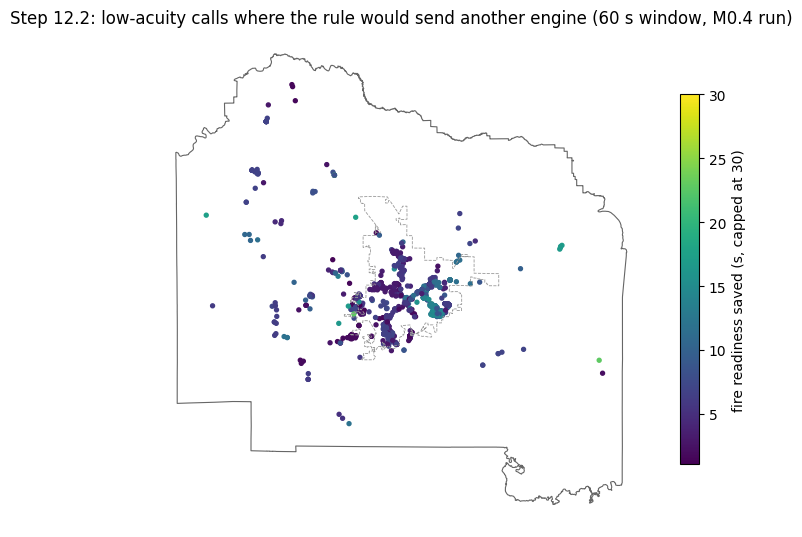

In [101]:
def census_decisions(dispatches, runs_table, estimated_travel, engines, quint_penalty_of_run, quint_indicator, low_acuity,
                     opportunity_cost, action_windows_s, verbose=VERBOSE):
    """Section 12.2: the room the rule (and an RL agent) has, counted on a protocol run without simulating. For every
    low-acuity run, at its dispatch moment in runs_table: the idle in-service engines (holding_runs; the run's own
    engine counts as idle); the protocol's engine (least modeled travel from home plus M0.4's quint penalty, among the
    allowed ones; checked against the engine the run sent); and, per action window in action_windows_s, how many engines
    rank within it of the protocol's engine, the engine the rule would send, the opportunity cost it saves (minutes of
    fire readiness) and its extra modeled travel (seconds). Travel is from the stations, as in the opportunity cost.

    Example: census = census_decisions(dispatches, m04_protocol, boundary_travel, engines, quint_penalty_of_run,
                                       quint_indicator, low_acuity, opportunity_cost, [30, 60, 120])
             census["choices_60"].ge(2).mean() -> share of low-acuity decisions with a choice at a 60 s window
    """
    engine_ids = estimated_travel.columns
    service = engines.set_index("engine_id").loc[engine_ids]
    rows = dispatches.index[low_acuity & dispatches["incident_lon"].notna()]
    rows = rows[runs_table.loc[rows, ["dispatched_at", "engine_id"]].notna().all(axis=1).to_numpy()]
    moments = runs_table.loc[rows, "dispatched_at"].to_numpy()
    when = (DAY_ZERO + pd.to_timedelta(moments, unit="s")).to_numpy()[:, None]
    holders = holding_runs(runs_table, engine_ids, moments)
    idle = ((when >= service["in_service_from"].to_numpy()[None, :]) & (when < service["in_service_to"].to_numpy()[None, :])
            & ((holders < 0) | (holders == rows.to_numpy()[:, None])))
    travel = estimated_travel.loc[rows].to_numpy()
    ranked = travel + quint_penalty_of_run.loc[rows].to_numpy()[:, None] * quint_indicator.reindex(engine_ids).to_numpy()[None, :]
    ranked = np.where(idle & np.isfinite(ranked), ranked, np.inf)
    inside_city = dispatches["focal"].fillna(False).astype(bool)
    records = []
    for i, row in enumerate(rows):
        protocol_column = int(np.argmin(ranked[i]))
        if not np.isfinite(ranked[i, protocol_column]):
            continue
        protocol_engine = engine_ids[protocol_column]
        widest = engine_ids[ranked[i] <= ranked[i, protocol_column] + max(action_windows_s)]
        costs = opportunity_cost(engine_ids[idle[i]], widest)
        record = {"row": row, "dispatched_at": DAY_ZERO + pd.Timedelta(seconds=moments[i]),
                  "inside_city": bool(inside_city.at[row]), "protocol_engine": protocol_engine,
                  "sent_engine": runs_table.at[row, "engine_id"], "oc_protocol_min": costs[protocol_engine]}
        for window in action_windows_s:
            near = engine_ids[ranked[i] <= ranked[i, protocol_column] + window]
            pick = costs[near].idxmin() if costs[protocol_engine] - costs[near].min() > OC_TIE_S / 60 else protocol_engine
            record.update({f"choices_{window}": len(near), f"rule_engine_{window}": pick,
                           f"oc_saving_min_{window}": costs[protocol_engine] - costs[pick],
                           f"extra_travel_s_{window}": travel[i, engine_ids.get_loc(pick)] - travel[i, protocol_column]})
        records.append(record)
    census = pd.DataFrame(records).set_index("row")
    if verbose:
        days = 365
        summary = pd.DataFrame({f"{window} s": {
            "low-acuity decisions": len(census), "with two or more engines in the window": (census[f"choices_{window}"] >= 2).mean(),
            "rule sends another engine": (census[f"rule_engine_{window}"] != census["protocol_engine"]).mean(),
            "  per day": (census[f"rule_engine_{window}"] != census["protocol_engine"]).sum() / days,
            "  readiness saved when it does (s), median": census.loc[census[f"rule_engine_{window}"] != census["protocol_engine"], f"oc_saving_min_{window}"].replace(np.inf, np.nan).median() * 60,
            "  extra modeled travel to the call (s), median": census.loc[census[f"rule_engine_{window}"] != census["protocol_engine"], f"extra_travel_s_{window}"].median(),
            "  saving infinite (protocol engine was the last one for a cell)": int(np.isinf(census[f"oc_saving_min_{window}"]).sum())}
            for window in action_windows_s})
        changed = census[census[f"rule_engine_{ACTION_WINDOW_S}"] != census["protocol_engine"]]
        print(f"--- low-acuity decisions on the protocol run: the room for another engine\n{summary.round(3).to_string()}\n"
              f"protocol engine (from the stations) equals the engine the run sent: {(census['protocol_engine'] == census['sent_engine']).mean():.1%}\n"
              f"examples where the rule sends another engine:\n{changed.head(5).round(3).to_string()}\n")
    return census


census = census_decisions(dispatches, m04_protocol, boundary_travel, engines, quint_penalty_of_run, quint_indicator, low_acuity,
                          opportunity_cost, ACTION_WINDOWS_S)
census_changed = census[census[f"rule_engine_{ACTION_WINDOW_S}"] != census["protocol_engine"]]
changed_points = dispatches.loc[census_changed.index, ["incident_lon", "incident_lat"]].assign(
    saving_s=census_changed[f"oc_saving_min_{ACTION_WINDOW_S}"].to_numpy() * 60)
figure, axis = plt.subplots(figsize=(8, 8))
county.boundary.plot(ax=axis, color="0.4", linewidth=0.8)
city.boundary.plot(ax=axis, color="0.6", linewidth=0.6, linestyle="--")
points = axis.scatter(changed_points["incident_lon"], changed_points["incident_lat"], c=changed_points["saving_s"].clip(upper=30), s=8,
                      cmap="viridis")
figure.colorbar(points, ax=axis, shrink=0.6, label="fire readiness saved (s, capped at 30)")
axis.set_title(f"Step 12.2: low-acuity calls where the rule would send another engine ({ACTION_WINDOW_S} s window, M0.4 run)")
axis.set_axis_off()
plt.show()

## Step 12.3 — The rule's year against the protocol's

**Functions.**
- `compare_policies` gives the policy minus protocol difference on research.md's measures, with weekly block-bootstrap
  intervals and the classes against m (fire) and δ (high-acuity medical).
- `weekly_block_quantile_difference` gives the P90 difference.
- `classify_against_margin` assigns the class.

**Check.**
- The rule's state checks.
- Five seeds at 60 s and the 30 s and 120 s windows on the M0.4 seed.
- The summary over seeds.

In [102]:
def weekly_block_quantile_difference(policy_values, protocol_values, weeks, quantile):
    """Section 12.3: the difference of a quantile (policy minus protocol) over paired calls, with its two-sided interval
    (BOOTSTRAP_INTERVAL) from BLOCK_BOOTSTRAP_DRAWS weekly block-bootstrap draws (weeks resampled with replacement, seed
    BLOCK_BOOTSTRAP_SEED). The three Series share one index.

    Example: weekly_block_quantile_difference(policy_s, protocol_s, weeks, 0.9) -> (4.0, -6.5, 15.1)  # seconds
    """
    week_ids = np.unique(weeks.to_numpy())
    members = [np.flatnonzero(weeks.to_numpy() == week) for week in week_ids]
    policy, protocol = policy_values.to_numpy(), protocol_values.to_numpy()
    rng = np.random.default_rng(BLOCK_BOOTSTRAP_SEED)
    draws = []
    for _ in range(BLOCK_BOOTSTRAP_DRAWS):
        picked = np.concatenate([members[k] for k in rng.integers(0, len(week_ids), len(week_ids))])
        draws.append(np.quantile(policy[picked], quantile) - np.quantile(protocol[picked], quantile))
    low, high = np.quantile(draws, BOOTSTRAP_INTERVAL)
    return float(np.quantile(policy, quantile) - np.quantile(protocol, quantile)), float(low), float(high)


def classify_against_margin(low, high, margin):
    """research.md E3: the class of a difference (policy minus protocol; negative = faster) from its interval and the
    margin: meaningful improvement (the interval is below -margin), practical equivalence (within +-margin), meaningful
    harm (above +margin), otherwise unresolved.

    Example: classify_against_margin(-30.0, -12.0, 10) -> 'meaningful improvement'
    """
    if high < -margin:
        return "meaningful improvement"
    if low > margin:
        return "meaningful harm"
    if -margin <= low and high <= margin:
        return "practical equivalence"
    return "unresolved"


def compare_policies(dispatches, protocol_table, policy_table, first_due_protocol, readiness_protocol, readiness_policy,
                     hour_share, low_acuity, verbose=VERBOSE):
    """Section 12.3: a policy's simulated year against the protocol's under the same random draws, on research.md's
    measures. Per outcome: the policy minus protocol difference (seconds), its weekly block-bootstrap interval and
    research.md's class against the margin (m for fire, delta for the medical constraint):
    - first-engine arrival at the study's fire calls: whole year; Jul-Sep; calls whose first-due station was committed
      under the protocol (first_due_protocol); calls whose first-due station is one of HOTSPOT_STATIONS; calls received
      in DAYTIME_HOURS (the hours whose E1 readiness loss exceeds the yearly mean);
    - fire readiness: the hour-weighted mean R of each week (readiness_*: fire_readiness segments);
    - P90 first arrival at high-acuity medical calls (determinant levels HIGH_ACUITY_LEVELS), against delta;
    - mean first arrival at low-acuity calls, their cost.

    Example: comparison = compare_policies(dispatches, m04_table, rule_table, first_due_m04, readiness_m04, readiness_rule,
                                           fire_hour_share, low_acuity)
             comparison.loc["fire calls, whole year", "class"] -> 'practical equivalence'
    """
    received_s = (dispatches["call_received_at"] - DAY_ZERO).dt.total_seconds()

    def first_arrival_s(table, rows):
        part = table.loc[rows].assign(incident_id=dispatches.loc[rows, "incident_id"]).dropna(subset=["arrived_at"])
        first = part.groupby("incident_id")["arrived_at"].min()
        return (first - DAY_ZERO).dt.total_seconds() - received_s.groupby(dispatches["incident_id"]).first().reindex(first.index)

    def paired(rows):
        both = pd.concat({"policy": first_arrival_s(policy_table, rows), "protocol": first_arrival_s(protocol_table, rows)}, axis=1).dropna()
        call_time = dispatches.loc[rows].groupby("incident_id")["call_received_at"].first().reindex(both.index)
        return both.assign(week=(call_time - DAY_ZERO).dt.days // 7, hour=call_time.dt.hour, received=call_time)

    fire_rows = dispatches.index[dispatches["protocol"].isin(STUDY_FIRE_PROTOCOLS).fillna(False)]
    fire = paired(fire_rows)
    committed = set(first_due_protocol.index[first_due_protocol["committed"]])
    hotspot = set(first_due_protocol.index[first_due_protocol["first_due_station"].isin(HOTSPOT_STATIONS)])
    groups = [("fire calls, whole year", fire.index), ("fire calls, Jul-Sep", fire.index[fire["received"] >= TRAVEL_TEST_FROM]),
              ("fire calls, first-due station committed (protocol)", fire.index[fire.index.isin(committed)]),
              ("fire calls, hotspot first-due stations", fire.index[fire.index.isin(hotspot)]),
              ("fire calls, daytime hours", fire.index[fire["hour"].isin(DAYTIME_HOURS)])]
    rows = {}
    for label, ids in groups:
        part = fire.loc[ids]
        difference = part["policy"] - part["protocol"]
        low, high = weekly_block_interval(difference, part["week"])
        rows[label] = {"calls": len(part), "difference s": difference.mean(), "interval low s": low, "interval high s": high,
                       "class": classify_against_margin(low, high, FIRE_MARGIN_S)}
    weekly = {}
    for name, segments in [("policy", readiness_policy), ("protocol", readiness_protocol)]:
        weight = (segments["end_s"] - segments["start_s"]) * hour_share.to_numpy()[(segments["start_s"] // 3600 % 24).astype(int)]
        weight = weight.where(np.isfinite(segments["R_min"]), 0.0)
        week = segments["start_s"] // (7 * 86400)
        weekly[name] = (segments["R_min"].where(weight > 0, 0.0) * weight).groupby(week).sum() / weight.groupby(week).sum()
    readiness_difference = (weekly["policy"] - weekly["protocol"]) * 60
    low, high = weekly_block_interval(readiness_difference, pd.Series(readiness_difference.index, index=readiness_difference.index))
    rows["fire readiness R, weekly hour-weighted mean"] = {"calls": len(readiness_difference), "difference s": readiness_difference.mean(),
                                                          "interval low s": low, "interval high s": high,
                                                          "class": classify_against_margin(low, high, FIRE_MARGIN_S)}
    high_rows = dispatches.index[dispatches["call_type"].eq("Medical").fillna(False)
                                 & dispatches["determinant_level"].isin(HIGH_ACUITY_LEVELS).fillna(False)]
    medical = paired(high_rows)
    point, low, high = weekly_block_quantile_difference(medical["policy"], medical["protocol"], medical["week"], 0.9)
    rows["high-acuity medical, P90 first arrival"] = {"calls": len(medical), "difference s": point, "interval low s": low, "interval high s": high,
                                                       "class": "within delta" if high <= MEDICAL_MARGIN_S else "beyond delta or unresolved"}
    low_rows = dispatches.index[low_acuity]
    cost = paired(low_rows)
    difference = cost["policy"] - cost["protocol"]
    low, high = weekly_block_interval(difference, cost["week"])
    rows["low-acuity calls, mean first arrival (cost)"] = {"calls": len(cost), "difference s": difference.mean(), "interval low s": low,
                                                          "interval high s": high, "class": ""}
    rows["runs sent another engine than the protocol run"] = {
        "calls": int((policy_table["engine_id"].astype(object).fillna("") != protocol_table["engine_id"].astype(object).fillna("")).sum())}
    comparison = pd.DataFrame(rows).T
    if verbose:
        print(f"--- policy minus protocol, same random draws (seconds; negative = faster; m = {FIRE_MARGIN_S} s, delta = "
              f"{MEDICAL_MARGIN_S} s; 95% weekly block-bootstrap interval)\n{comparison.to_string()}\n")
    return comparison


def run_year(quantile, action_window_s=None, report=None):
    """The full-year M0.4 setting with travel quantiles `quantile`; with action_window_s, the rule on low-acuity calls."""
    def choose(run, available, travel):
        spread, penalty = (brush_spread if brush_run[run.name] else travel_spread), quint_indicator * quint_penalty_of_run[run.name]
        if action_window_s is None:
            return dispatch_closest_with_spread(run, available, travel, spread, call_inside_city, quantile, penalty)
        return dispatch_by_opportunity_cost(run, available, travel, spread, call_inside_city, quantile, penalty, low_acuity,
                                            action_window_s, opportunity_cost)
    return simulate(m0_runs, available=define_available_engines, engines=engines, estimated_travel=boundary_travel, choose=choose,
                    where_engines_are=lambda row, now, state, travel: travel_while_returning(
                        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model,
                        fitted_dwell_s, fitted_slowdown),
                    wait_rank=wait_rank, report=report, counterfactual=True, fates_by_arrival=fates_by_arrival, verbose=False)


comparisons = {}
for seed in POLICY_SEEDS:
    quantile = spread_quantile if seed == TRAVEL_SPREAD_SEED else pd.Series(np.random.default_rng(seed).random(len(runs)), index=runs.index)
    protocol_run = m04_protocol if seed == TRAVEL_SPREAD_SEED else run_year(quantile)
    protocol_table = simulated_dispatch_table(dispatches, protocol_run, engines, verbose=False)
    first_due_protocol = check_first_due(dispatches, protocol_run, boundary_travel, engines, verbose=False)
    readiness_protocol = fire_readiness(protocol_run, engines, readiness_cells, travel_to_cells, fire_hour_share, verbose=False)[0]
    for window_s in (ACTION_WINDOWS_S if seed == TRAVEL_SPREAD_SEED else [ACTION_WINDOW_S]):
        rule_report = {}
        rule_run = run_year(quantile, window_s, rule_report)
        if seed == TRAVEL_SPREAD_SEED and window_s == ACTION_WINDOW_S:
            print("state checks of the rule's year (M0.4 seed, 60 s window):")
            rule_states = check_counterfactual_run(runs, rule_run, dispatches, rule_report, arrivals_by_call=True)
        readiness_rule = fire_readiness(rule_run, engines, readiness_cells, travel_to_cells, fire_hour_share, verbose=False)[0]
        comparisons[(seed, window_s)] = compare_policies(
            dispatches, protocol_table, simulated_dispatch_table(dispatches, rule_run, engines, verbose=False), first_due_protocol,
            readiness_protocol, readiness_rule, fire_hour_share, low_acuity, verbose=(seed == TRAVEL_SPREAD_SEED))
policy_comparison = pd.concat(comparisons, names=["seed", "action_window_s", "outcome"])
main_window = policy_comparison.xs(ACTION_WINDOW_S, level="action_window_s")
over_seeds = pd.DataFrame({
    "mean difference s": main_window["difference s"].astype(float).groupby(level="outcome", sort=False).mean(),
    "lowest s": main_window["difference s"].astype(float).groupby(level="outcome", sort=False).min(),
    "highest s": main_window["difference s"].astype(float).groupby(level="outcome", sort=False).max(),
    "classes over seeds": main_window["class"].fillna("").groupby(level="outcome", sort=False).agg(lambda c: dict(c.value_counts()))})
print(f"--- rule ({ACTION_WINDOW_S} s window) minus protocol over {len(POLICY_SEEDS)} seeds\n{over_seeds.round(2).to_string()}\n"
      f"--- by window, M0.4 seed (difference s, class)\n"
      f"{policy_comparison.xs(TRAVEL_SPREAD_SEED, level='seed')[['difference s', 'class']].unstack(0).to_string()}")

--- policy minus protocol, same random draws (seconds; negative = faster; m = 10 s, delta = 10 s; 95% weekly block-bootstrap interval)
                                                    calls difference s interval low s interval high s                  class
fire calls, whole year                               1537     0.002752      -0.230616        0.239653  practical equivalence
fire calls, Jul-Sep                                   317    -0.308262      -1.035981             0.0  practical equivalence
fire calls, first-due station committed (protocol)    106    -1.716002      -4.477545             0.0  practical equivalence
fire calls, hotspot first-due stations                402    -0.228148      -1.117712        0.465916  practical equivalence
fire calls, daytime hours                            1035     0.004087      -0.341461        0.349008  practical equivalence
fire readiness R, weekly hour-weighted mean            53    -0.110196      -0.128743       -0.094577  practical eq

state checks of the rule's year (M0.4 seed, 60 s window):
--- E0 state checks
runs never served                                            0.0000
runs whose engine was taken by a newer run                   0.0000
runs sent while their engine was still on an earlier run     0.0000
calls whose number of arrivals differs from 2025             0.0000
runs with times out of order                                 0.0000
runs served without a clear                                  0.0000
runs that kept their 2025 times                              4.0000
runs of calls without a location                             4.0000
cancelled requests that never got an engine                 23.0000
calls whose first arrival is the recorded second (share)     0.0004
runs that waited for an engine                               0.0000
wait seconds: median                                            NaN
wait seconds: max                                               NaN



--- policy minus protocol, same random draws (seconds; negative = faster; m = 10 s, delta = 10 s; 95% weekly block-bootstrap interval)
                                                     calls difference s interval low s interval high s                  class
fire calls, whole year                                1537     0.267322      -0.402853        1.060161  practical equivalence
fire calls, Jul-Sep                                    317     0.723639      -2.079714        4.047134  practical equivalence
fire calls, first-due station committed (protocol)     106    -4.036681      -9.582236       -0.057638  practical equivalence
fire calls, hotspot first-due stations                 402     0.490903      -1.703378        3.317477  practical equivalence
fire calls, daytime hours                             1035      0.39698      -0.605548        1.578617  practical equivalence
fire readiness R, weekly hour-weighted mean             53    -0.211474      -0.236733       -0.188874  pract

--- policy minus protocol, same random draws (seconds; negative = faster; m = 10 s, delta = 10 s; 95% weekly block-bootstrap interval)
                                                     calls difference s interval low s interval high s                  class
fire calls, whole year                                1537     0.504581      -0.335442        1.523788  practical equivalence
fire calls, Jul-Sep                                    317     2.071131      -1.498085        6.227822  practical equivalence
fire calls, first-due station committed (protocol)     106    -5.398728      -10.90994       -1.170578             unresolved
fire calls, hotspot first-due stations                 402     0.350069      -1.949546        3.296233  practical equivalence
fire calls, daytime hours                             1035     0.805122      -0.443301        2.309073  practical equivalence
fire readiness R, weekly hour-weighted mean             53    -0.409515      -0.453112       -0.370034  pract

--- rule (60 s window) minus protocol over 5 seeds
                                                    mean difference s  lowest s  highest s                             classes over seeds
outcome                                                                                                                                  
fire calls, whole year                                           0.22      0.07       0.39                   {'practical equivalence': 5}
fire calls, Jul-Sep                                              0.29     -0.33       1.10                   {'practical equivalence': 5}
fire calls, first-due station committed (protocol)              -4.23     -5.41      -3.70  {'unresolved': 3, 'practical equivalence': 2}
fire calls, hotspot first-due stations                          -0.02     -0.57       0.56                   {'practical equivalence': 5}
fire calls, daytime hours                                        0.33      0.07       0.60                   {'practical 

## Step 12.4 — Paired branches: does the readiness saved turn into later benefit?

**Function.** `branch_decisions` runs the protocol and the rule from the same rebuilt state for sampled decisions. Each
decision is checked against the full run.
**Check.**
- The counts.
- The slope of the benefit on the readiness saved, holding extra travel and workload, with a weekly block-bootstrap
  interval.
- The benefit by stratum.
- A plot of benefit against saving, and a map of where the readiness change falls.

--- paired branches: 310 decisions tried, 300 counted; branch A reproduced the full-year run in 100.0%; the rule still changed the engine in the reconstructed state in 96.8%
mean readiness gained over 2 h by the rule's engine: 0.86 s; slope on the opportunity cost saved (holding extra travel and workload): 0.118 (95% weekly block-bootstrap interval 0.080 to 0.165)
by stratum of opportunity cost saved (census):
         decisions  oc_saving_s  benefit_s  extra_travel_s  workload_min  own_call_difference_s
stratum                                                                                        
0               60         2.31       0.31           22.04         18.80                  20.92
1               60         3.76       0.43           41.00         16.71                  34.23
2               60         6.12       0.82           25.18         17.48                  22.23
3               60         7.49       1.12           27.86         19.56                  26.46
4         

/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/3777656288.py:126: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  f"examples:\n{used.head(5).round(2).to_string()}\n")


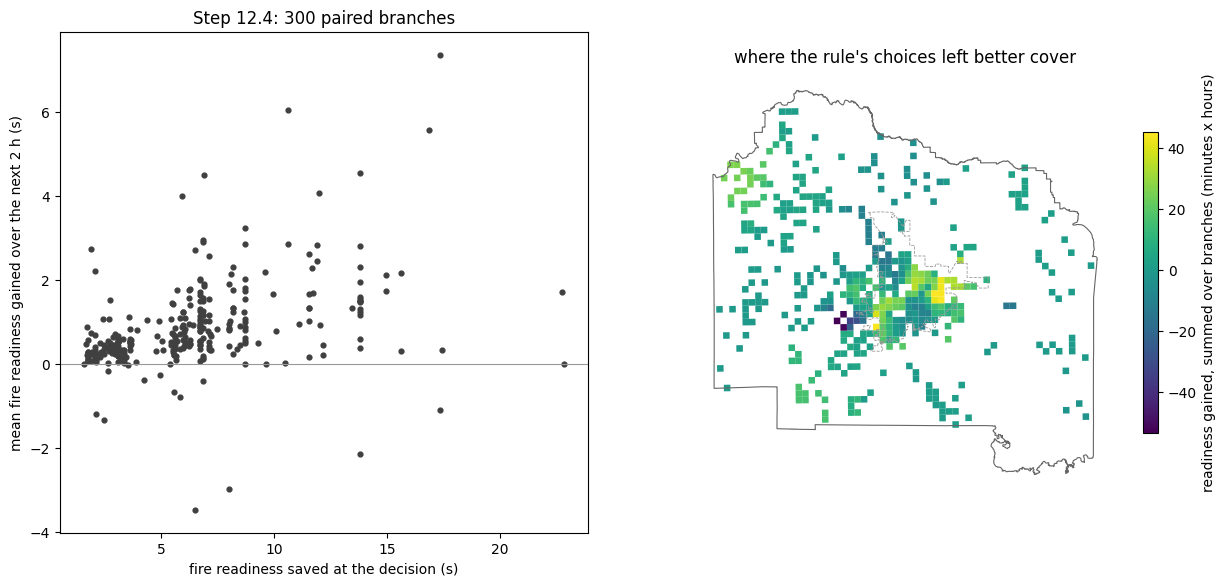

In [103]:
def branch_decisions(dispatches, runs, protocol_run, census, simulate_window, protocol_choose, rule_choice, readiness_of, cells,
                     travel_to_cells, engines, verbose=VERBOSE):
    """Section 12.4 (research.md 3.4, paired branch simulations): does the fire readiness a decision saves turn into
    later benefit? Low-acuity decisions where the census finds the rule would send another engine (ACTION_WINDOW_S) are
    drawn evenly over BRANCH_STRATA strata of the opportunity cost saved (seed BRANCH_SEED). Each decision is simulated
    twice from the same state, rebuilt by simulating the calls first dispatched in the BRANCH_WARMUP_S before it
    (simulate_window on the repaired 2025 runs): branch A follows the protocol (protocol_choose); branch B applies the
    rule (rule_choice: run, available, travel -> protocol's engine, rule's engine, opportunity costs) at the decision,
    in that reconstructed state, and the protocol everywhere else. A decision counts only if branch A reproduces the
    full-year protocol run over the BRANCH_HORIZON_S after the decision (every run's engine and times, rtol 0, and the
    fire readiness) and the rule still changes the engine in that state; drawing goes on, up to three times the target
    per stratum, until BRANCH_DECISIONS such decisions. Over the horizon: each branch's mean fire readiness (readiness_of
    on the idle engines between dispatches and clears), first arrivals at later study fire calls and at the decision's
    own call, and the decision run's busy time (workload). Returns the per-decision table (counted and not) and the cells
    with the readiness change summed over the counted decisions (minutes x hours, A minus B: positive where the rule's
    engine left better cover).

    Example: branches, branch_cells = branch_decisions(dispatches, m0_runs, m04_protocol, census, simulate_window,
                                                       protocol_choose, rule_choice, readiness_of, readiness_cells,
                                                       travel_to_cells, engines)
             branches.loc[branches["counted"], "benefit_s"].mean() -> readiness gained over two hours by the rule (s)
    """
    engine_ids = travel_to_cells.index
    service = engines.set_index("engine_id").loc[engine_ids]
    service_from = (service["in_service_from"] - DAY_ZERO).dt.total_seconds().to_numpy()
    service_to = (service["in_service_to"] - DAY_ZERO).dt.total_seconds().to_numpy()

    def horizon_readiness(table, start, end):
        """Mean fire readiness (minutes) and per-cell tau x time (minutes x hours) over [start, end] for a run table."""
        sent = table.dropna(subset=["engine_id", "dispatched_at", "cleared_at"])
        sent = sent[(sent["dispatched_at"] < end) & (sent["cleared_at"] > start)]     # runs that can hold an engine in the horizon
        times = np.unique(np.clip(np.concatenate([[start, end], sent["dispatched_at"], sent["cleared_at"]]), start, end))
        middle, duration = (times[:-1] + times[1:]) / 2, np.diff(times)
        idle = (middle[:, None] >= service_from) & (middle[:, None] < service_to) & (holding_runs(sent, engine_ids, middle) < 0)
        readiness, tau = zip(*(readiness_of(mask) for mask in idle))
        readiness, tau = np.array(readiness), np.vstack(tau)
        finite = np.isfinite(readiness)
        return (np.sum(readiness[finite] * duration[finite]) / np.sum(duration[finite]),
                np.nansum(np.where(np.isfinite(tau), tau, np.nan) * duration[:, None], axis=0) / 3600)

    changed = census[(census[f"rule_engine_{ACTION_WINDOW_S}"] != census["protocol_engine"]) & np.isfinite(census[f"oc_saving_min_{ACTION_WINDOW_S}"])]
    stratum = pd.qcut(changed[f"oc_saving_min_{ACTION_WINDOW_S}"].rank(method="first"), BRANCH_STRATA, labels=False)
    first_dispatch = runs.groupby("incident_id")["dispatched_at"].transform("min")
    fire_incident = dispatches["protocol"].isin(STUDY_FIRE_PROTOCOLS).fillna(False)
    received_s = (dispatches["call_received_at"] - DAY_ZERO).dt.total_seconds()
    check_columns = TIME_COLUMNS + ["engine_id"]
    target = BRANCH_DECISIONS // BRANCH_STRATA
    records, cell_change = [], np.zeros(len(cells))
    for level in range(BRANCH_STRATA):
        candidates = changed[stratum == level].sample(frac=1.0, random_state=BRANCH_SEED + level).index[:3 * target]
        counted = 0
        for row in candidates:
            if counted == target:
                break
            moment = protocol_run.at[row, "dispatched_at"]
            end = moment + BRANCH_HORIZON_S
            window = runs[(first_dispatch >= moment - BRANCH_WARMUP_S) & (first_dispatch <= end)]
            decision = {}

            def rule_at_decision(run, available, travel):
                if run.name != row:
                    return protocol_choose(run, available, travel)
                protocol_engine, chosen, costs = rule_choice(run, available, travel)
                decision.update(protocol_engine=protocol_engine, rule_engine=chosen,
                                oc_saving_s=(costs[protocol_engine] - costs[chosen]) * 60 if chosen != protocol_engine else 0.0,
                                extra_travel_s=travel[chosen] - travel[protocol_engine])
                return protocol_choose(run, [chosen], travel)

            branch_a, branch_b = simulate_window(window, protocol_choose), simulate_window(window, rule_at_decision)
            horizon_rows = window.index[(protocol_run.loc[window.index, "dispatched_at"] >= moment).to_numpy()
                                        & (protocol_run.loc[window.index, "dispatched_at"] <= end).to_numpy()]
            a_part, full_part = branch_a.loc[horizon_rows, check_columns], protocol_run.loc[horizon_rows, check_columns]
            readiness_a, cells_a = horizon_readiness(branch_a, moment, end)
            readiness_full, _ = horizon_readiness(protocol_run, moment, end)
            reproduced = bool((a_part["engine_id"].astype(object).fillna("") == full_part["engine_id"].astype(object).fillna("")).all()
                              and np.allclose(a_part[TIME_COLUMNS].to_numpy(dtype=float), full_part[TIME_COLUMNS].to_numpy(dtype=float),
                                              rtol=0.0, atol=1e-6, equal_nan=True)
                              and abs(readiness_a - readiness_full) < 1e-9)
            readiness_b, cells_b = horizon_readiness(branch_b, moment, end)
            later_rows = window.index[fire_incident[window.index].to_numpy() & (received_s[window.index] > moment).to_numpy()]
            incident_of = dispatches.loc[later_rows, "incident_id"]
            later = pd.concat({"A": branch_a.loc[later_rows, "arrived_at"].groupby(incident_of).min(),
                               "B": branch_b.loc[later_rows, "arrived_at"].groupby(incident_of).min()}, axis=1).dropna()
            own_rows = window.index[(dispatches.loc[window.index, "incident_id"] == dispatches.at[row, "incident_id"]).to_numpy()]
            is_counted = reproduced and decision.get("rule_engine") not in (None, decision.get("protocol_engine"))
            counted += is_counted
            if is_counted:
                cell_change += cells_a - cells_b
            records.append({"row": row, "stratum": level, "dispatched_at": DAY_ZERO + pd.Timedelta(seconds=moment),
                            "week": int(moment // (7 * 86400)), "engine_A": decision.get("protocol_engine"), "engine_B": decision.get("rule_engine"),
                            "census_oc_saving_s": changed.at[row, f"oc_saving_min_{ACTION_WINDOW_S}"] * 60,
                            "oc_saving_s": decision.get("oc_saving_s"), "extra_travel_s": decision.get("extra_travel_s"),
                            "workload_min": (branch_a.at[row, "cleared_at"] - branch_a.at[row, "dispatched_at"]) / 60,
                            "benefit_s": (readiness_a - readiness_b) * 60, "later_fire_calls": len(later),
                            "later_fire_difference_s": (later["B"] - later["A"]).sum(),
                            "own_call_difference_s": branch_b.loc[own_rows, "arrived_at"].min() - branch_a.loc[own_rows, "arrived_at"].min(),
                            "branch_A_reproduces_protocol_run": reproduced, "counted": is_counted})
    branches = pd.DataFrame(records).set_index("row")
    branch_cells = cells[["cell_x", "cell_y", "lon", "lat"]].assign(readiness_change_min_h=cell_change)
    if verbose:
        used = branches[branches["counted"]]
        design = np.column_stack([np.ones(len(used)), used[["oc_saving_s", "extra_travel_s", "workload_min"]].to_numpy(dtype=float)])
        benefit = used["benefit_s"].to_numpy(dtype=float)
        slope = np.linalg.lstsq(design, benefit, rcond=None)[0][1]
        weeks = used["week"].to_numpy()
        week_ids = np.unique(weeks)
        members = [np.flatnonzero(weeks == week) for week in week_ids]
        rng = np.random.default_rng(BLOCK_BOOTSTRAP_SEED)
        draws = []
        for _ in range(BLOCK_BOOTSTRAP_DRAWS):
            pick = np.concatenate([members[k] for k in rng.integers(0, len(week_ids), len(week_ids))])
            draws.append(np.linalg.lstsq(design[pick], benefit[pick], rcond=None)[0][1])
        low, high = np.quantile(draws, BOOTSTRAP_INTERVAL)
        strata = used.groupby("stratum").agg(decisions=("benefit_s", "size"), oc_saving_s=("oc_saving_s", "mean"),
                                             benefit_s=("benefit_s", "mean"), extra_travel_s=("extra_travel_s", "mean"),
                                             workload_min=("workload_min", "mean"), own_call_difference_s=("own_call_difference_s", "mean"))
        print(f"--- paired branches: {len(branches)} decisions tried, {len(used)} counted; branch A reproduced the full-year run in "
              f"{branches['branch_A_reproduces_protocol_run'].mean():.1%}; the rule still changed the engine in the reconstructed state in "
              f"{(branches['engine_B'] != branches['engine_A']).mean():.1%}\n"
              f"mean readiness gained over {BRANCH_HORIZON_S / 3600:.0f} h by the rule's engine: {used['benefit_s'].mean():.2f} s; "
              f"slope on the opportunity cost saved (holding extra travel and workload): {slope:.3f} "
              f"(95% weekly block-bootstrap interval {low:.3f} to {high:.3f})\n"
              f"by stratum of opportunity cost saved (census):\n{strata.round(2).to_string()}\n"
              f"later study fire calls within the horizon: {int(used['later_fire_calls'].sum())}, first arrival B minus A summed: "
              f"{used['later_fire_difference_s'].sum():.1f} s\n"
              f"examples:\n{used.head(5).round(2).to_string()}\n")
    return branches, branch_cells


def simulate_window(window_runs, choose):
    """A stretch of calls under the M0.4 setting, with its own call fates."""
    return simulate(window_runs, available=define_available_engines, engines=engines, estimated_travel=boundary_travel, choose=choose,
                    where_engines_are=lambda row, now, state, travel: travel_while_returning(
                        row, now, state, travel, call_nodes, home_nodes, seconds_from_node, node_position, network_travel_model,
                        fitted_dwell_s, fitted_slowdown),
                    wait_rank=wait_rank, counterfactual=True, fates_by_arrival=call_fates(window_runs), verbose=False)


branches, branch_cells = branch_decisions(
    dispatches, m0_runs, m04_protocol, census, simulate_window,
    lambda run, available, travel: dispatch_closest_with_spread(run, available, travel, brush_spread if brush_run[run.name] else travel_spread,
                                                                call_inside_city, spread_quantile, quint_indicator * quint_penalty_of_run[run.name]),
    lambda run, available, travel: choose_by_opportunity_cost(run, available, travel, quint_indicator * quint_penalty_of_run[run.name],
                                                              low_acuity, ACTION_WINDOW_S, opportunity_cost),
    readiness_of, readiness_cells, travel_to_cells, engines)
counted = branches[branches["counted"]]
figure, (scatter_axis, map_axis) = plt.subplots(1, 2, figsize=(15, 6.5))
scatter_axis.scatter(counted["oc_saving_s"], counted["benefit_s"], s=12, color="0.25")
scatter_axis.axhline(0, color="0.6", linewidth=0.8)
scatter_axis.set_xlabel("fire readiness saved at the decision (s)")
scatter_axis.set_ylabel("mean fire readiness gained over the next 2 h (s)")
scatter_axis.set_title(f"Step 12.4: {len(counted)} paired branches")
change_cells = cell_squares.assign(change=branch_cells["readiness_change_min_h"].to_numpy())
county.boundary.plot(ax=map_axis, color="0.4", linewidth=0.8)
city.boundary.plot(ax=map_axis, color="0.6", linewidth=0.6, linestyle="--")
change_cells.plot(ax=map_axis, column="change", cmap="viridis", legend=True,
                  legend_kwds={"shrink": 0.6, "label": "readiness gained, summed over branches (minutes x hours)"})
map_axis.set_title("where the rule's choices left better cover")
map_axis.set_axis_off()
plt.show()

## Section 12 evidence

- **Earlier sections are unchanged.** All 80 earlier output files are byte-identical after the full run.
  - The hand-calculated toys pass.
  - The protocol compared with itself shows no changed run and zero differences.
  - The rule's year has 0 state violations.
- **The room (census, M0.4 run).** There are 7,932 low-acuity decisions.
  - At a 60 s window, 38.6% have two or more engines to choose from.
  - The rule sends another engine on 12.5% of them, 2.7 a day. When it does, the median readiness saved is 6.0 s and the
    median extra travel to the call is 30 s.
  - At 30 s the rule changes 1.5 decisions a day; at 120 s, 4.9 a day.
- **The year, rule minus protocol** (same travel draws, five seeds, 60 s).
  - Fire first arrival: +0.2 s over the year and +0.3 s in Jul–Sep. Practical equivalence for every seed and window.
  - Fire calls whose first-due station was committed: −4.2 s (2 seeds equivalence, 3 unresolved). Hotspots and daytime:
    equivalent.
  - Readiness −0.21 s; high-acuity medical P90 −0.4 s, within δ for all seeds; low-acuity calls +3.5 s.
  - Wider windows give more readiness and more cost: at 120 s, readiness −0.41 s and low-acuity +12.8 s.
- **Paired branches.** Of 310 decisions tried, 300 were counted. Branch A reproduced the full run in every one, and the
  rule still changed the engine in 96.8% of the rebuilt states.
  - Mean readiness gained over the next 2 h: 0.86 s; 96% of the branches gain.
  - The gain grows with the readiness saved at the decision: slope 0.118 [0.080, 0.165], holding extra travel and
    workload.
  - Later fire calls within the horizon (115) are too few to show an arrival effect: −0.38 s each.
- **What it means.** The opportunity cost is a real spatial signal: what a decision saves turns into later cover. But at
  today's load the permitted choices move fire outcomes far less than m. The rule is a clear comparator for RL. The
  reviewer asks that research.md separate "the tested policies are practically equivalent" from "the protocol is the
  best these decisions allow", and that E3 report every measure on the same held-out months.

# Section 13 — The scenario generator: nominal scenarios against October–March, and the conditions

**Why.** research.md 3.3 trains the RL agent on synthetic scenarios built from October–March, and E5 checks the
results under demand growth, engine outages and a large fire. Section 12 found that at today's load the tested
opportunity-cost rule moves fire outcomes far less than m (other policies' gains stay open). The author chose heavier
load as the focus for RL's value, so the generator produces both the nominal training scenarios and those conditions. A scenario is only useful if it has the
same room for another engine as the real system. The check is therefore on the room itself (how often a fire call
finds its first-due station busy, how many engines a low-acuity call can choose from, how much readiness a switch
saves), not only on call totals.

**What is built.** Roads, stations and engines stay fixed; calls come from October–March only.
- Other calls: each day copies a whole real day of the same kind (weekday or weekend) within ±14 days, drawn at random.
  Calls drawn one by one missed the record's room: the nearest engine was busy at 10.7% of low-acuity decisions,
  against 8.4% in the record. A real day's calls fall against each other in time in a way that independent draws lose;
  whole days keep it.
- Study fire calls: each day draws a gamma day factor (busy days); each hour gets a Poisson number of calls at that
  hour's mean on the same kind of day within ±14 days; each copies a real study fire call received in the same 4-hour
  block within ±14 days: its type, its location and its recorded fate (number of runs, cancellations, on-scene times).
- `build_scenario` turns the calls into the inputs `simulate` needs, so every M0.4 rule applies unchanged. An engine
  out of service is a stand-in run with no location that holds it.
- Fire readiness now includes the wait when no engine is free (research.md 3.3).

The conditions are:
- other calls ×0.8, 1.1, 1.3, 1.5, with the extra calls placed by 2020 residents;
- short surges of 6, 12 and 24 extra calls in 2 h within 2.5 km, one a day, visiting every first-due area in turn.
  This is a stress test, not a fitted feature: the record holds no local burst beyond chance, and its largest is 7 calls.
- 1–3 engines out of service each day;
- an E1 hotspot station closed;
- a large fire each week (6 engines × 4 h, provisional).

**The steps.**
- 13.1: the inputs.
- 13.2: four nominal scenarios against October–March (the done-criterion).
- 13.3: the conditions on concrete cases.
- 13.4: each condition under the protocol and the opportunity-cost rule.
- 13.5: what a surge costs in fire readiness by first-due area, and the room and the rule under each condition.

**Input/output check before running (gpt-6-astra, read-only).** Three rounds.
- Round 1 had four MUSTs. Scheduled outages must take precedence over new dispatches. Added calls must copy sources
  from the same 4-hour block within ±14 days. Growth must place calls over all populated blocks by residents. The
  nominal check missed one statistic (readiness saved 6.12 s, outside 5.32–6.02), which led to copying whole real days.
- Round 2 had three MUSTs. An outage must win at a same-second clear. Surge travel draws must not change with the surge
  size. A window that cuts a waiting segment must be integrated exactly.
- Round 3: PASS.

## Step 13.1 — The generator's inputs: residents, the call pool, call rates

**Functions.**
- `build_call_pool`: the October–March incidents a scenario copies.
- `build_resident_locations`: every 2020 Census block with residents, snapped to the road network, with network
  seconds from every station; growth and surges put new calls there.
- `draw_source_calls`, `fit_call_rates` and `expected_hourly_counts`: the real call a new call copies, calls per hour on
  the same kind of day within two weeks, and the day-to-day spread beyond chance.
- `generate_calls`: other calls as whole real days of the same kind within two weeks; study fire calls generated.
- `build_scenario`: the calls, then the inputs `simulate` needs.

**Check.** The inputs printed, the spread by group, and (in Step 13.2) the first week's copied days and the first calls
beside the real calls they copy.

In [104]:
import zlib
import scipy.spatial

CENSUS_BLOCKS_GPKG = PROJECT_ROOT / "data" / "raw" / "gnv_alachua" / "census2020_blocks_alachua.gpkg"  # [SOURCE] 2020 Census blocks: residents (POP100) and internal points
SCENARIO_WINDOW_DAYS = 14                                                   # [DESIGN] Section 13: a scenario day's call rates and drawn calls come from training days this close to it
SCENARIO_BAND_HOURS = 4                                                     # [DESIGN] Section 13: a new call copies a real call received in the same block of this many hours
SCENARIO_SEEDS = [101, 102, 103, 104]                                       # [DESIGN] Section 13.2: nominal scenarios, each a whole October-March, checked against the record
STRUCTURE_FIRE_PROTOCOL = "F69"                                             # [SOURCE] MPDS fire protocol 69: structure fire (where a large fire is placed)
DEMAND_FACTORS = [0.8, 1.1, 1.3, 1.5]                                       # [SOURCE] research.md 3.3 (non-fire demand x0.8-1.3) and the author (2026-11-14: up to x1.5, about ten years of 2012-22 growth)
SURGES_PER_DAY = 1                                                          # [DESIGN] Section 13: short surges per day in the surge condition
SURGE_RADIUS_M = 2500                                                       # [DESIGN] Section 13: a short surge's calls fall within this distance of its centre (the record's bursts were counted the same way)
SURGE_HOURS = 2                                                             # [DESIGN] Section 13: length of a short surge (the record's bursts were counted over 2 h)
SURGE_EXTRA_CALLS = [6, 12, 24]                                             # [DESIGN] the author (2026-11-14): a stress sweep; 6 + the usual ~1 = the record's largest local burst (7 other calls within 2.5 km in 2 h), then double and quadruple
OUTAGE_ENGINE_COUNTS = [1, 2, 3]                                            # [PLACEHOLDER] Section 13: engines out of service each day; the records hold no outages, so this is a stress sweep
LARGE_FIRES_PER_WEEK = 1                                                    # [DESIGN] Section 13: large fires per week in the large-fire condition
LARGE_FIRE_ENGINES = 6                                                      # [PLACEHOLDER] Section 13: engines a large fire holds: a first alarm's 3 engine-class units (ACFR response matrix), doubled for a second alarm; to confirm with GFR/ACFR
LARGE_FIRE_ON_SCENE_S = 4 * 3600                                            # [SOURCE] Section 13: the median, over the 8 largest Oct-Mar fires (engine-hours), of their longest single-engine dispatch-to-clear time (4.0 h)
OUT_OF_SERVICE_PROTOCOL = "OUT"                                             # [DESIGN] Section 13: protocol code of the stand-in run that holds an engine while it is out of service
OUT_OF_SERVICE_WAIT_RANK = -1                                               # [DESIGN] Section 13: a pending outage takes its engine at its next clear, before any waiting call (SOC ranks start at 0)


def build_call_pool(dispatches, verbose=VERBOSE):
    """Section 13: the real calls a scenario draws from. One row per incident received in the training months (before
    TRAINING_MONTHS_END) with a location: call time (seconds since DAY_ZERO), day (days since DAY_ZERO), hour, block of
    SCENARIO_BAND_HOURS hours, weekend or not, study fire call (STUDY_FIRE_PROTOCOLS) or not, protocol, agency side of
    the line (jurisdiction) and city flag (focal), position in PROJECTED_CRS and its READINESS_CELL_M cell, the record
    rows of its runs, and the row of its first run to arrive (-1 when none arrived).

    Example: pool = build_call_pool(dispatches)
             pool.loc["100124-0043", ["day", "hour", "fire", "runs"]].tolist() -> [0, 1, False, 1]
    """
    training = dispatches[(dispatches["call_received_at"] < TRAINING_MONTHS_END) & dispatches["incident_lon"].notna()]
    groups = training.groupby("incident_id", sort=False)
    first = groups.head(1)
    first_arrival = training.dropna(subset=["arrived_at"]).sort_values("arrived_at").groupby("incident_id").head(1)
    x, y = pyproj.Transformer.from_crs("EPSG:4326", PROJECTED_CRS, always_xy=True).transform(
        first["incident_lon"].to_numpy(), first["incident_lat"].to_numpy())
    received_s = (first["call_received_at"] - DAY_ZERO).dt.total_seconds().to_numpy()
    pool = pd.DataFrame({
        "received_s": received_s, "day": (received_s // 86400).astype(int), "hour": first["call_received_at"].dt.hour.to_numpy(),
        "weekend": (first["call_received_at"].dt.dayofweek >= 5).to_numpy(),
        "fire": first["protocol"].isin(STUDY_FIRE_PROTOCOLS).fillna(False).to_numpy(dtype=bool),
        "protocol": first["protocol"].astype(object).to_numpy(), "jurisdiction": first["jurisdiction"].astype(object).to_numpy(),
        "focal": first["focal"].fillna(False).to_numpy(dtype=bool), "x": x, "y": y,
        "cell_x": np.floor(x / READINESS_CELL_M).astype(int), "cell_y": np.floor(y / READINESS_CELL_M).astype(int)},
        index=pd.Index(first["incident_id"].astype(object).to_numpy(), name="incident_id"))
    pool["band"] = pool["hour"] // SCENARIO_BAND_HOURS
    rows = groups.groups
    pool["run_rows"] = [np.asarray(rows[incident]) for incident in pool.index]
    pool["runs"] = pool["run_rows"].map(len)
    pool["arrival_row"] = (pd.Series(first_arrival.index.to_numpy(), index=first_arrival["incident_id"].astype(object).to_numpy())
                           .reindex(pool.index).fillna(-1).astype(int))
    show_table("call pool: training-month incidents a scenario draws from", pool, verbose)
    if verbose:
        print(f"incidents {len(pool):,} (study fire calls {int(pool['fire'].sum()):,}), runs {int(pool['runs'].sum()):,}, "
              f"days {pool['day'].nunique()}; incidents per block of {SCENARIO_BAND_HOURS} h: "
              f"{pool.groupby('band').size().to_dict()}\n")
    return pool


def build_resident_locations(pool, graph, home_nodes, seconds_from_node, node_position, engines, verbose=VERBOSE):
    """Section 13 (where growth and surges put new calls: more residents, more calls): every 2020 Census block with
    residents, at its internal point snapped to the road network: residents, position (lon/lat and PROJECTED_CRS), its
    READINESS_CELL_M cell, node and snap distance, the agency side of the line and city flag of the nearest
    training-month call (jurisdiction, focal), its first-due station (the home station of the engine of its own agency
    side with the fewest free-flow network seconds to it; an engine without a station id is its own station, as in
    check_first_due), and the free-flow network seconds from every engine's home station to its node (rows: blocks;
    columns: engines, as network_from_stations gives for a call).

    Example: locations, location_seconds = build_resident_locations(pool, graph, home_nodes, seconds_from_node, node_position, engines)
             locations["residents"].sum() -> 278468; location_seconds.shape -> (blocks with residents, 29)
    """
    blocks = gpd.read_file(CENSUS_BLOCKS_GPKG, ignore_geometry=True)
    show_table("2020 Census blocks (input)", blocks, verbose)
    blocks = blocks[blocks["POP100"] > 0].reset_index(drop=True)
    lon, lat = blocks["INTPTLON"].astype(float).to_numpy(), blocks["INTPTLAT"].astype(float).to_numpy()
    x, y = pyproj.Transformer.from_crs("EPSG:4326", PROJECTED_CRS, always_xy=True).transform(lon, lat)
    nodes, snap_m = ox.distance.nearest_nodes(graph, X=lon, Y=lat, return_dist=True)
    nearest_call = scipy.spatial.cKDTree(pool[["x", "y"]].to_numpy()).query(np.column_stack([x, y]))[1]
    locations = pd.DataFrame({"residents": blocks["POP100"].to_numpy(), "lon": lon, "lat": lat, "x": x, "y": y,
                              "cell_x": np.floor(x / READINESS_CELL_M).astype(int), "cell_y": np.floor(y / READINESS_CELL_M).astype(int),
                              "node": nodes, "snap_m": snap_m, "jurisdiction": pool["jurisdiction"].to_numpy()[nearest_call],
                              "focal": pool["focal"].to_numpy()[nearest_call]})
    positions = node_position[locations["node"]].to_numpy()
    location_seconds = pd.DataFrame({engine_id: seconds_from_node(int(node))[positions] for engine_id, node in home_nodes.items()},
                                    index=locations.index)
    engine_table = engines.set_index("engine_id").loc[location_seconds.columns]
    station_of_engine = engine_table["home_station"].astype(object).where(engine_table["home_station"].notna(), engine_table.index.to_series())
    other_side = (engine_table["engine_agency"] == "GFR").to_numpy()[None, :] != (locations["jurisdiction"] == "GFR").to_numpy()[:, None]
    locations["first_due_station"] = station_of_engine.to_numpy()[np.argmin(np.where(other_side, np.inf, location_seconds.to_numpy()), axis=1)]
    if verbose:
        show_table("residential locations (2020 blocks with residents)", locations, verbose)
        area_residents = locations.groupby("first_due_station")["residents"].sum().sort_values()
        print(f"first-due station areas with residents: {len(area_residents)}; residents per area: fewest {area_residents.index[0]} "
              f"{int(area_residents.iloc[0]):,}, median {int(area_residents.median()):,}, most {area_residents.index[-1]} {int(area_residents.iloc[-1]):,}")
        print(f"blocks with residents {len(locations):,}, residents {int(locations['residents'].sum()):,} in "
              f"{locations.groupby(['cell_x', 'cell_y']).ngroups:,} cells of {READINESS_CELL_M} m; snap distance median "
              f"{locations['snap_m'].median():.0f} m, P90 {locations['snap_m'].quantile(0.9):.0f} m; residents on the GFR side "
              f"{locations.loc[locations['jurisdiction'] == 'GFR', 'residents'].sum() / locations['residents'].sum():.1%}; "
              f"unreachable from some station: {int(np.isinf(location_seconds.to_numpy()).any(axis=1).sum())} blocks\n")
    return locations, location_seconds


def draw_source_calls(pool, day, fire, band, size, rng, candidates):
    """Section 13: `size` real calls (incident ids, drawn with replacement) for a new call on day `day`: same group (fire),
    same SCENARIO_BAND_HOURS block, received within SCENARIO_WINDOW_DAYS of the day (any kind of day). candidates: a dict
    kept by the caller, (day, fire, band) -> pool positions.

    Example: draw_source_calls(pool, 0, False, 3, 2, np.random.default_rng(1), {}) -> two incident ids received 12:00-15:59
             within 14 days of 1 October, e.g. Index(['100824-0213', '101124-0287'])
    """
    key = (day, fire, band)
    if key not in candidates:
        candidates[key] = np.flatnonzero((np.abs(pool["day"].to_numpy() - day) <= SCENARIO_WINDOW_DAYS) & (pool["fire"].to_numpy() == fire)
                                         & (pool["band"].to_numpy() == band))
    return pool.index[rng.choice(candidates[key], size=size)]


def fit_call_rates(pool, verbose=VERBOSE):
    """Section 13: how many calls arrive, from the pool. counts: calls on each training day (rows: days since DAY_ZERO)
    by group and hour (columns: fire False = other calls, True = study fire calls; hours 0-23). dispersion: per group,
    the day-to-day spread beyond chance, phi of a negative binomial (variance = mean + phi x mean^2), fitted by moments on
    each day's total against the mean total of the other days of the same kind (weekday or weekend) within
    SCENARIO_WINDOW_DAYS; 0 when the spread is no wider than chance.

    Example: counts, dispersion = fit_call_rates(pool)
             counts.shape -> (182, 48); dispersion -> {False: 0.01, True: 0.06}, roughly
    """
    days = np.arange((TRAINING_MONTHS_END - DAY_ZERO).days)
    columns = pd.MultiIndex.from_product([[False, True], range(24)], names=["fire", "hour"])
    counts = (pool.groupby(["day", "fire", "hour"]).size().unstack(["fire", "hour"])
              .reindex(index=days, columns=columns).fillna(0).astype(int))
    weekend = (DAY_ZERO + pd.to_timedelta(days, unit="D")).dayofweek >= 5
    dispersion, check = {}, {}
    for fire in (False, True):
        totals = counts.xs(fire, axis=1, level="fire").sum(axis=1).to_numpy(dtype=float)
        means = np.array([totals[(np.abs(days - day) <= SCENARIO_WINDOW_DAYS) & (weekend == weekend[day]) & (days != day)].mean()
                          for day in days])
        dispersion[fire] = max(0.0, float(np.sum((totals - means) ** 2 - means) / np.sum(means ** 2)))
        check["study fire calls" if fire else "other calls"] = {
            "mean per day": totals.mean(), "variance of the day's total around its window mean": np.mean((totals - means) ** 2),
            "chance alone (mean)": means.mean(), "phi": dispersion[fire]}
    if verbose:
        show_table("calls per training day by (fire, hour)", counts, verbose)
        print(f"day-to-day spread (negative binomial phi; variance = mean + phi x mean^2):\n{pd.DataFrame(check).T.round(4).to_string()}\n")
    return counts, dispersion


def expected_hourly_counts(counts, day):
    """Section 13: the mean calls per hour on scenario day `day` (days since DAY_ZERO): each (fire, hour) count averaged
    over the training days of the same kind (weekday or weekend) within SCENARIO_WINDOW_DAYS of it.

    Example: expected_hourly_counts(counts, 0)[(False, 12)] -> 4.9  # other calls, 12:00-13:00 on Tuesday 1 October, roughly
    """
    days = counts.index.to_numpy()
    weekend = (DAY_ZERO + pd.to_timedelta(days, unit="D")).dayofweek >= 5
    near = (np.abs(days - day) <= SCENARIO_WINDOW_DAYS) & (weekend == ((DAY_ZERO + pd.Timedelta(days=int(day))).dayofweek >= 5))
    return counts[near].mean()


def generate_calls(pool, counts, dispersion, days, seed, verbose=VERBOSE):
    """Section 13 (the nominal scenario): calls for `days` (days since DAY_ZERO, in the training months).
    - Other (non-fire) calls: each day copies every other call of one real training day of the same kind (weekday or
      weekend) within SCENARIO_WINDOW_DAYS, drawn at random: each call at its time of day, with its type, location and
      fate. A whole real day keeps how its calls fall against each other in time, which calls drawn one by one lose
      (Section 13.2).
    - Study fire calls: each day draws a day factor from a gamma with mean 1 and variance phi (busy days; dispersion from
      fit_call_rates). Each hour then gets a Poisson number of calls with mean = day factor x expected_hourly_counts, at
      uniform whole seconds of the hour. Each copies a real study fire call received in the same SCENARIO_BAND_HOURS
      block within SCENARIO_WINDOW_DAYS (any kind of day): its type, location and fate.
    Returns the calls (incident_id, received_s, source_incident, fire, large_fire, kind, location: -1 = the source's own
    location), sorted by time, and the day factors (rows: days; columns: fire): for other calls, the copied day's total
    over the day's expected total; for study fire calls, the gamma draw.

    Example: calls, day_factors = generate_calls(pool, counts, dispersion, range(7), seed=101)
             calls.iloc[0].tolist() -> ['syn101-000000', 1873.0, '100424-0016', False, False, 'nominal', -1]  # day 0 copies day 3
    """
    rng = np.random.default_rng(seed)
    training_days = counts.index.to_numpy()
    training_weekend = (DAY_ZERO + pd.to_timedelta(training_days, unit="D")).dayofweek >= 5
    other_pool = pool[~pool["fire"]]
    candidates, moments, sources, groups, factors, copied_days = {}, [], [], [], {}, {}
    for day in days:
        mean_counts = expected_hourly_counts(counts, day)
        same_kind = training_weekend == ((DAY_ZERO + pd.Timedelta(days=int(day))).dayofweek >= 5)
        copied_days[day] = int(rng.choice(training_days[(np.abs(training_days - day) <= SCENARIO_WINDOW_DAYS) & same_kind]))
        copied = other_pool[other_pool["day"] == copied_days[day]]
        sources.extend(copied.index)
        moments.extend(copied["received_s"].to_numpy() + (day - copied_days[day]) * 86400)
        groups.extend([False] * len(copied))
        factors[(day, False)] = len(copied) / mean_counts.xs(False).sum()
        phi = dispersion[True]
        factors[(day, True)] = rng.gamma(1 / phi, phi) if phi > 0 else 1.0
        numbers = rng.poisson(factors[(day, True)] * mean_counts.xs(True).to_numpy())
        for hour in np.flatnonzero(numbers):
            sources.extend(draw_source_calls(pool, day, True, hour // SCENARIO_BAND_HOURS, numbers[hour], rng, candidates))
            moments.extend(day * 86400 + hour * 3600 + rng.integers(0, 3600, size=numbers[hour]))
            groups.extend([True] * numbers[hour])
    calls = pd.DataFrame({"received_s": np.array(moments, dtype=float), "source_incident": sources, "fire": np.array(groups, dtype=bool)})
    calls = calls.sort_values("received_s", kind="stable").reset_index(drop=True)
    calls.insert(0, "incident_id", [f"syn{seed}-{n:06d}" for n in range(len(calls))])
    calls["large_fire"], calls["kind"], calls["location"] = False, "nominal", -1
    day_factors = pd.Series(factors).unstack()
    if verbose:
        show_table(f"generated calls (seed {seed})", calls, verbose)
        first_week = list(days)[:7]
        week = pd.DataFrame({"day": first_week, "copied day": [copied_days[day] for day in first_week]})
        week.insert(1, "weekday", (DAY_ZERO + pd.to_timedelta(week["day"], unit="D")).dt.day_name())
        week["copied weekday"] = (DAY_ZERO + pd.to_timedelta(week["copied day"], unit="D")).dt.day_name()
        week["other calls copied"] = [int((other_pool["day"] == copied_days[day]).sum()) for day in first_week]
        week["expected other calls"] = [expected_hourly_counts(counts, day).xs(False).sum() for day in first_week]
        week["fire day factor"] = [day_factors.at[day, True] for day in first_week]
        first_day = first_week[0]
        expected = expected_hourly_counts(counts, first_day)
        made = calls[calls["received_s"] // 86400 == first_day].assign(hour=lambda c: (c["received_s"] % 86400 // 3600).astype(int))
        by_hour = pd.DataFrame({"expected other calls": expected.xs(False), "copied other calls": made[~made["fire"]].groupby("hour").size(),
                                "expected fire calls": expected.xs(True), "generated fire calls": made[made["fire"]].groupby("hour").size()}).fillna(0)
        source = pool.loc[calls["source_incident"]]
        examples = calls.head(5).assign(source_day=source["day"].to_numpy()[:5], source_hour=source["hour"].to_numpy()[:5],
                                        source_protocol=source["protocol"].to_numpy()[:5], source_runs=source["runs"].to_numpy()[:5],
                                        cell=list(zip(source["cell_x"].to_numpy()[:5], source["cell_y"].to_numpy()[:5])))
        other_calls, call_day = ~calls["fire"].to_numpy(), calls["received_s"].to_numpy() // 86400
        call_weekend = (DAY_ZERO + pd.to_timedelta(call_day, unit="D")).dayofweek >= 5
        print(f"the first week's copied days (other calls) and fire day factors:\n{week.round(3).to_string(index=False)}\n"
              f"day {first_day}, calls by hour (fire: expected before the day factor):\n{by_hour.round(2).T.to_string()}\n"
              f"first calls and the real calls they copy:\n{examples.to_string()}\n"
              f"calls {len(calls):,} over {len(day_factors)} days ({len(calls) / len(day_factors):.1f} a day; study fire calls "
              f"{int(calls['fire'].sum()):,}); largest gap between a call's day and its source's day: "
              f"{int(np.abs(call_day - source['day'].to_numpy()).max())} days\n"
              f"other calls: one copied day per day {bool(pd.Series(source['day'].to_numpy()[other_calls]).groupby(call_day[other_calls]).nunique().max() == 1)}, "
              f"same kind of day {bool((call_weekend == source['weekend'].to_numpy())[other_calls].all())}, same time of day "
              f"{bool(((calls['received_s'].to_numpy() - source['received_s'].to_numpy()) % 86400 == 0)[other_calls].all())}; day factor (copied total / "
              f"expected) mean {day_factors[False].mean():.3f}, SD {day_factors[False].std():.3f}, distinct real days used "
              f"{len(set(copied_days.values()))} of {len(training_days)}\n"
              f"study fire calls: same block of hours as the source "
              f"{bool(((calls['received_s'] % 86400 // 3600) // SCENARIO_BAND_HOURS == source['band'].to_numpy())[~other_calls].all())}; "
              f"day factor mean {day_factors[True].mean():.3f}, SD {day_factors[True].std():.3f} (gamma SD sqrt(phi) {np.sqrt(dispersion[True]):.3f})\n")
    return calls, day_factors


def build_scenario(calls, outages, pool, locations, location_seconds, dispatches, m0_runs, engines, network_seconds, network_km, call_nodes,
                   travel_model, aid_protocols, quint_penalty_by_type, seed, verbose=VERBOSE):
    """Section 13: a scenario as the inputs simulate needs, built from real runs so that every rule of the M0.4 setting
    applies unchanged. Each new call copies the runs of its real incident (the record's 32 columns and the M0-repaired
    times), every time moved by the same whole-second shift (new call time minus the real one), under its new incident
    id. A call placed at a residential block (calls["location"] >= 0, from build_resident_locations) takes the block's
    position, agency side, city flag, network node and network seconds instead of its source's. A large fire copies its
    structure fire's first run to arrive LARGE_FIRE_ENGINES times; all of them arrive and stay LARGE_FIRE_ON_SCENE_S on
    scene. Each outage (engine_id, start_s, end_s) is a stand-in run with no location (protocol OUT_OF_SERVICE_PROTOCOL)
    that holds its engine from start to end: like any call without a location, the protocol sends that engine when it is
    free and otherwise waits for it, ahead of every waiting call (OUT_OF_SERVICE_WAIT_RANK), and the stand-in still ends
    at end_s.
    Returns a dict: dispatches (the record's 32 columns), runs (seconds since DAY_ZERO), source_row (the record row each
    run copies; -1 for a stand-in), large_fire (per run), travel (modeled travel from every station:
    estimate_network_travel_seconds at the scenario's dispatch times, then apply_agency_boundaries), call_nodes,
    spread_quantile (one draw per run from seed and its incident id, so a call keeps its draws when a condition adds
    calls), fates (call_fates), and per run inside_city, wait_rank (SOC priority; stand-ins first),
    quint_penalty (M0.4, by call type), brush (F82) and low_acuity (research.md 3.2).

    Example: scenario = build_scenario(calls, no_outages, pool, locations, location_seconds, dispatches, m0_runs, engines,
                                       network_seconds, network_km, call_nodes, network_travel_model, aid_protocols,
                                       quint_penalty_by_type, seed=101)
             scenario["dispatches"].shape -> (18500, 32), roughly, for a nominal October-March
    """
    time_columns = ["call_received_at"] + TIME_COLUMNS
    copied = []                                                  # (source row, new incident id, shift in seconds, large fire, block)
    for call in calls.itertuples(index=False):
        rows = [pool.at[call.source_incident, "arrival_row"]] * LARGE_FIRE_ENGINES if call.large_fire else pool.at[call.source_incident, "run_rows"]
        shift_s = call.received_s - pool.at[call.source_incident, "received_s"]
        copied += [(row, call.incident_id, shift_s, call.large_fire, call.location) for row in rows]
    copied = pd.DataFrame(copied, columns=["source_row", "incident_id", "shift_s", "large_fire", "location"])
    table = dispatches.loc[copied["source_row"]].reset_index(drop=True)
    runs = m0_runs.loc[copied["source_row"]].reset_index(drop=True)
    for column in time_columns:
        table[column] = table[column] + pd.to_timedelta(copied["shift_s"], unit="s")
        runs[column] = runs[column] + copied["shift_s"]
    table["incident_id"] = copied["incident_id"].astype(dispatches["incident_id"].dtype)
    runs["incident_id"] = copied["incident_id"].to_numpy()
    copied_placed = copied["location"].to_numpy() >= 0
    if copied_placed.any():                                      # the block's position, agency side and city flag
        block = locations.loc[copied.loc[copied_placed, "location"]]
        for column, source in [("incident_lon", "lon"), ("incident_lat", "lat"), ("jurisdiction", "jurisdiction"), ("focal", "focal")]:
            table.loc[copied_placed, column] = pd.Series(block[source].to_numpy(), index=table.index[copied_placed], dtype=dispatches[column].dtype)
    large = copied["large_fire"].to_numpy(dtype=bool)
    if large.any():                                              # every engine of a large fire arrives and stays LARGE_FIRE_ON_SCENE_S
        table.loc[large, "cleared_at"] = table.loc[large, "arrived_at"] + pd.Timedelta(seconds=LARGE_FIRE_ON_SCENE_S)
        runs.loc[large, "cleared_at"] = runs.loc[large, "arrived_at"] + LARGE_FIRE_ON_SCENE_S
        table.loc[large, "on_scene_s"] = LARGE_FIRE_ON_SCENE_S
        table.loc[large, "n_engines_sent"] = LARGE_FIRE_ENGINES
        table.loc[large, "arrival_order"] = table[large].groupby("incident_id").cumcount().to_numpy() + 1
        table.loc[large, "cancelled"] = False
    if len(outages):                                             # stand-in runs, typed like the record (a real row as template)
        stand_in = dispatches.iloc[[0] * len(outages)].reset_index(drop=True)
        home = engines.set_index("engine_id").loc[outages["engine_id"]]
        start = DAY_ZERO + pd.to_timedelta(outages["start_s"].to_numpy(), unit="s")
        values = {"incident_id": [f"out{seed}-{n:05d}" for n in range(len(outages))], "problem": "engine out of service",
                  "call_type": "Out of service", "protocol": OUT_OF_SERVICE_PROTOCOL, "determinant_level": pd.NA, "determinant_code": pd.NA,
                  "priority": pd.NA, "n_engines_sent": 1, "incident_lon": np.nan, "incident_lat": np.nan,
                  "jurisdiction": np.where(home["engine_agency"].eq("GFR"), "GFR", "ACFR"),          # its own agency's side of the line
                  "focal": False, "engine_id": outages["engine_id"].to_numpy(), "engine_type": home["engine_type"].to_numpy(),
                  "engine_agency": home["engine_agency"].to_numpy(), "engine_lon_at_dispatch": home["home_lon"].to_numpy(),
                  "engine_lat_at_dispatch": home["home_lat"].to_numpy(), "from_station": home["home_station"].astype(object).to_numpy(),
                  "at_home": True, "call_received_at": start, "dispatched_at": start, "enroute_at": pd.NaT, "arrived_at": pd.NaT,
                  "cleared_at": DAY_ZERO + pd.to_timedelta(outages["end_s"].to_numpy(), unit="s"), "turnout_s": pd.NA, "travel_s": pd.NA,
                  "on_scene_s": pd.NA, "arrival_order": pd.NA, "staged": False, "cancelled": True, "auto_aid": pd.NA, "qc_note": ""}
        for column, value in values.items():
            stand_in[column] = pd.Series(value if np.ndim(value) else [value] * len(stand_in), dtype=dispatches[column].dtype)
        stand_in_runs = pd.DataFrame({"incident_id": stand_in["incident_id"].astype(object).to_numpy(), "engine_id": outages["engine_id"].to_numpy(),
                                      "call_received_at": outages["start_s"].to_numpy(), "dispatched_at": outages["start_s"].to_numpy(),
                                      "enroute_at": np.nan, "arrived_at": np.nan, "cleared_at": outages["end_s"].to_numpy()})
        table = pd.concat([table, stand_in], ignore_index=True)
        runs = pd.concat([runs, stand_in_runs[runs.columns]], ignore_index=True)
        copied = pd.concat([copied, pd.DataFrame({"source_row": -1, "incident_id": stand_in["incident_id"], "shift_s": np.nan,
                                                  "large_fire": False, "location": -1})], ignore_index=True)
    order = np.argsort(runs["call_received_at"].to_numpy(), kind="stable")
    table, runs = table.iloc[order].reset_index(drop=True), runs.iloc[order].reset_index(drop=True)
    source_row = pd.Series(copied["source_row"].to_numpy()[order], index=table.index)
    location = copied["location"].to_numpy()[order]
    placed = location >= 0
    seconds_rows = network_seconds.reindex(source_row.to_numpy()).set_axis(table.index)
    km_rows = network_km.reindex(source_row.to_numpy()).set_axis(table.index)
    seconds_rows.loc[placed] = location_seconds.loc[location[placed], seconds_rows.columns].to_numpy()
    km_rows.loc[placed] = np.nan                                 # the linear travel model uses network seconds only
    nodes = call_nodes.reindex(source_row.to_numpy()).set_axis(table.index)
    nodes.loc[placed, "node"] = locations.loc[location[placed], "node"].to_numpy()
    nodes.loc[placed, "snap_m"] = locations.loc[location[placed], "snap_m"].to_numpy()
    stand_in_row = table["protocol"].eq(OUT_OF_SERVICE_PROTOCOL).fillna(False)
    run_number = runs.groupby("incident_id", sort=False).cumcount().to_numpy()
    spread_quantile = [np.random.default_rng([seed, zlib.crc32(str(incident).encode())]).random(number + 1)[number]
                       for incident, number in zip(runs["incident_id"], run_number)]
    travel = apply_agency_boundaries(estimate_network_travel_seconds(table, engines, seconds_rows, km_rows, travel_model, verbose=False),
                                     table, engines, aid_protocols, verbose=False)
    call_type_for_quint = table["protocol"].map(QUINT_RULE_CALL_TYPES).fillna("all other calls")
    scenario = {
        "dispatches": table, "runs": runs, "source_row": source_row,
        "large_fire": pd.Series(copied["large_fire"].to_numpy(dtype=bool)[order], index=table.index), "travel": travel,
        "call_nodes": nodes, "spread_quantile": pd.Series(spread_quantile, index=table.index),
        "fates": call_fates(runs), "inside_city": table["focal"].fillna(False).astype(bool),
        "wait_rank": table["priority"].astype("string").map(PRIORITY_RANK).fillna(len(PRIORITY_RANK)).mask(stand_in_row, OUT_OF_SERVICE_WAIT_RANK),
        "quint_penalty": call_type_for_quint.map(quint_penalty_by_type), "brush": table["protocol"].eq(BRUSH_FIRE_PROTOCOL).fillna(False),
        "low_acuity": ((table["call_type"].eq("Medical") & table["priority"].eq("Low")).fillna(False)
                       | table["protocol"].isin(LOW_ACUITY_SERVICE_PROTOCOLS).fillna(False))}
    if verbose:
        show_table(f"scenario dispatch table (seed {seed})", table, verbose)
        copies = (source_row.to_numpy() >= 0) & ~placed
        record = dispatches.loc[source_row[copies & ~scenario["large_fire"].to_numpy()]]
        kept = table[copies & ~scenario["large_fire"].to_numpy()]
        duration_change = ((kept["cleared_at"] - kept["dispatched_at"]).to_numpy() - (record["cleared_at"] - record["dispatched_at"]).to_numpy())
        record_travel = apply_agency_boundaries(estimate_network_travel_seconds(dispatches.loc[source_row[copies]], engines, network_seconds.loc[source_row[copies]],
                                                                                network_km.loc[source_row[copies]], travel_model, verbose=False),
                                                dispatches.loc[source_row[copies]], engines, aid_protocols, verbose=False)
        service_changed = (travel[copies].isna().to_numpy() != record_travel.isna().to_numpy()).any(axis=1)
        print(f"calls {table['incident_id'].nunique():,} ({calls['kind'].value_counts().to_dict()}), runs {len(table):,}, stand-in runs "
              f"{int(stand_in_row.sum())}, large-fire runs {int(scenario['large_fire'].sum())}, runs placed at a residential block {int(placed.sum())}\n"
              f"checks: copied rows all from the training months: {bool((dispatches.loc[source_row[copies], 'call_received_at'] < TRAINING_MONTHS_END).all())}; "
              f"largest change of a copied run's dispatch-to-clear time: {np.nanmax(np.abs(duration_change.astype('timedelta64[s]').astype(float))) if len(kept) else 0:.0f} s; "
              f"copied runs whose engines in service differ from their source's (moved across an engine's first or last day): {int(service_changed.sum())}\n"
              f"multi-run calls with call fates: {len(scenario['fates']):,}; low-acuity runs {int(scenario['low_acuity'].sum()):,}\n")
    return scenario


# Section 13 (research.md 3.3): the scenario generator: nominal scenarios checked against October-March, then the conditions
call_pool = build_call_pool(dispatches)
resident_locations, resident_location_seconds = build_resident_locations(call_pool, graph, home_nodes, seconds_from_node, node_position, engines)
call_counts, call_dispersion = fit_call_rates(call_pool)
training_days = range((TRAINING_MONTHS_END - DAY_ZERO).days)
busiest_cells = call_pool[~call_pool["fire"]].groupby(["cell_x", "cell_y"]).size().nlargest(20).index
no_outages = pd.DataFrame(columns=["engine_id", "start_s", "end_s"])

def make_scenario(scenario_calls, scenario_outages, scenario_seed, verbose=False):
    """A scenario's simulate inputs from its calls and outages (build_scenario with this run's fitted inputs)."""
    return build_scenario(scenario_calls, scenario_outages, call_pool, resident_locations, resident_location_seconds, dispatches, m0_runs,
                          engines, network_seconds, network_km, call_nodes, network_travel_model, aid_protocols, quint_penalty_by_type,
                          scenario_seed, verbose=verbose)

def simulate_scenario(scenario, action_window_s=None, report=None):
    """A scenario under the M0.4 protocol; with action_window_s, the opportunity-cost rule on its low-acuity calls instead."""
    def choose(run, available, travel):
        spread, penalty = (brush_spread if scenario["brush"][run.name] else travel_spread), quint_indicator * scenario["quint_penalty"][run.name]
        if action_window_s is None:
            return dispatch_closest_with_spread(run, available, travel, spread, scenario["inside_city"], scenario["spread_quantile"], penalty)
        return dispatch_by_opportunity_cost(run, available, travel, spread, scenario["inside_city"], scenario["spread_quantile"], penalty,
                                            scenario["low_acuity"], action_window_s, opportunity_cost)
    return simulate(scenario["runs"], available=define_available_engines, engines=engines, estimated_travel=scenario["travel"], choose=choose,
                    where_engines_are=lambda row, now, state, travel: travel_while_returning(
                        row, now, state, travel, scenario["call_nodes"], home_nodes, seconds_from_node, node_position, network_travel_model,
                        fitted_dwell_s, fitted_slowdown),
                    wait_rank=scenario["wait_rank"], report=report, counterfactual=True, fates_by_arrival=scenario["fates"], verbose=False)

def measure_scenario_run(scenario, scenario_run):
    """The first-due check, the census at ACTION_WINDOW_S and fire readiness (with waits) of a scenario's run."""
    return (check_first_due(scenario["dispatches"], scenario_run, scenario["travel"], engines, verbose=False),
            census_decisions(scenario["dispatches"], scenario_run, scenario["travel"], engines, scenario["quint_penalty"], quint_indicator,
                             scenario["low_acuity"], opportunity_cost, [ACTION_WINDOW_S], verbose=False),
            fire_readiness(scenario_run, engines, readiness_cells, travel_to_cells, fire_hour_share, wait_for_busy=True, verbose=False)[0])

--- call pool: training-month incidents a scenario draws from (16508, 16)
             received_s  day  hour  weekend   fire protocol jurisdiction  focal              x             y  cell_x  cell_y  band run_rows  runs  arrival_row
incident_id                                                                                                                                                   
100124-0043      6775.0    0     1    False  False      E06         ACFR  False  394732.579216  3.275206e+06     394    3275     0      [0]     1            0
100124-0113     23852.0    0     6    False  False      E26         ACFR  False  394998.163985  3.274825e+06     394    3274     1      [1]     1            1
100124-0165     28106.0    0     7    False  False      E10         ACFR  False  345978.385836  3.300492e+06     345    3300     1      [2]     1            2
100124-0184     29358.0    0     8    False  False      E06         ACFR  False  376797.708259  3.279446e+06     376    3279     2 

## Step 13.2 — Nominal scenarios against October–March

**Functions.**
- `weekly_calibration_parts`: per week, the numerator and denominator of each statistic.
- `weekly_block_ratio_interval`: the record's weekly block-bootstrap interval of a ratio.
- `compare_scenarios_with_record`: the done-criterion; the pooled value of four seeds must fall inside the record's interval.

**Check.**
- The first seed's calls (copied days, generated fire calls) and scenario table.
- The state checks.
- The calibration table.
- A map of calls per cell (record, a scenario, residents).
- A plot of each statistic against the record's interval.

--- generated calls (seed 101) (16506, 7)
     incident_id  received_s source_incident   fire  large_fire     kind  location
0  syn101-000000      1873.0     100424-0016  False       False  nominal        -1
1  syn101-000001      4507.0     100424-0030  False       False  nominal        -1
2  syn101-000002      4849.0     100424-0033  False       False  nominal        -1
3  syn101-000003      5880.0     100424-0040  False       False  nominal        -1
4  syn101-000004      6186.0     100424-0042  False       False  nominal        -1

the first week's copied days (other calls) and fire day factors:
 day   weekday  copied day copied weekday  other calls copied  expected other calls  fire day factor
   0   Tuesday           3         Friday                  74                84.545            0.474
   1 Wednesday          13         Monday                  82                86.417            1.123
   2  Thursday           0        Tuesday                  88                87.538        

--- scenario dispatch table (seed 101) (18508, 32)
     incident_id    call_received_at                       problem call_type protocol determinant_level determinant_code  priority  n_engines_sent  incident_lon  incident_lat jurisdiction  focal engine_id engine_type engine_agency  engine_lon_at_dispatch  engine_lat_at_dispatch from_station  at_home       dispatched_at          enroute_at          arrived_at          cleared_at  turnout_s  travel_s  on_scene_s  arrival_order  staged  cancelled  auto_aid qc_note
0  syn101-000000 2024-10-01 00:31:13   E12D - CONVULSIONS/SEIZURES   Medical      E12                 D             E12D      High               1    -82.354765     29.706196          GFR   True        Q8           Q           GFR              -82.370836               29.692203       GFR_08     True 2024-10-01 00:32:08 2024-10-01 00:33:00 2024-10-01 00:39:34 2024-10-01 01:00:12         52       394        1238              1   False      False     False        
1  syn101-000001 

nominal scenario, seed 101: protocol run simulated
--- E0 state checks
runs never served                                            0.0000
runs whose engine was taken by a newer run                   0.0000
runs sent while their engine was still on an earlier run     0.0000
calls whose number of arrivals differs from 2025             0.0000
runs with times out of order                                 0.0000
runs served without a clear                                  0.0000
runs that kept their 2025 times                              0.0000
runs of calls without a location                             0.0000
cancelled requests that never got an engine                 13.0000
calls whose first arrival is the recorded second (share)     0.0005
runs that waited for an engine                               0.0000
wait seconds: median                                            NaN
wait seconds: max                                               NaN



nominal scenario, seed 102: protocol run simulated


nominal scenario, seed 103: protocol run simulated


nominal scenario, seed 104: protocol run simulated


--- nominal scenarios against the record, October-March (pooled over 4 seeds; 95% weekly block-bootstrap interval of the record)
                                                      record interval low interval high scenarios inside record interval seed 101 seed 102 seed 103 seed 104 record weekly SD scenario weekly SD
other calls per day                                   85.429       83.917        86.830    84.841                   True   85.363   85.181   84.115   84.703            3.951              3.788
study fire calls per week                             36.923       33.808        40.000    38.173                   True   37.308   37.385   38.154   39.846            8.246              7.758
runs per call                                          1.122        1.114         1.131     1.124                   True    1.121    1.119    1.130    1.125            0.024              0.020
share of other calls in the record's 20 busiest cells  0.242        0.235         0.249     0.243  

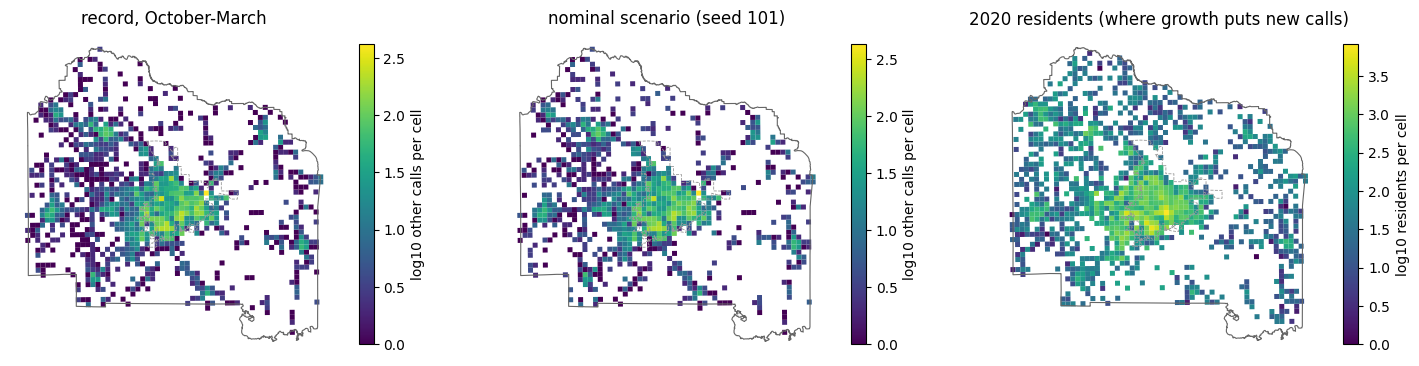

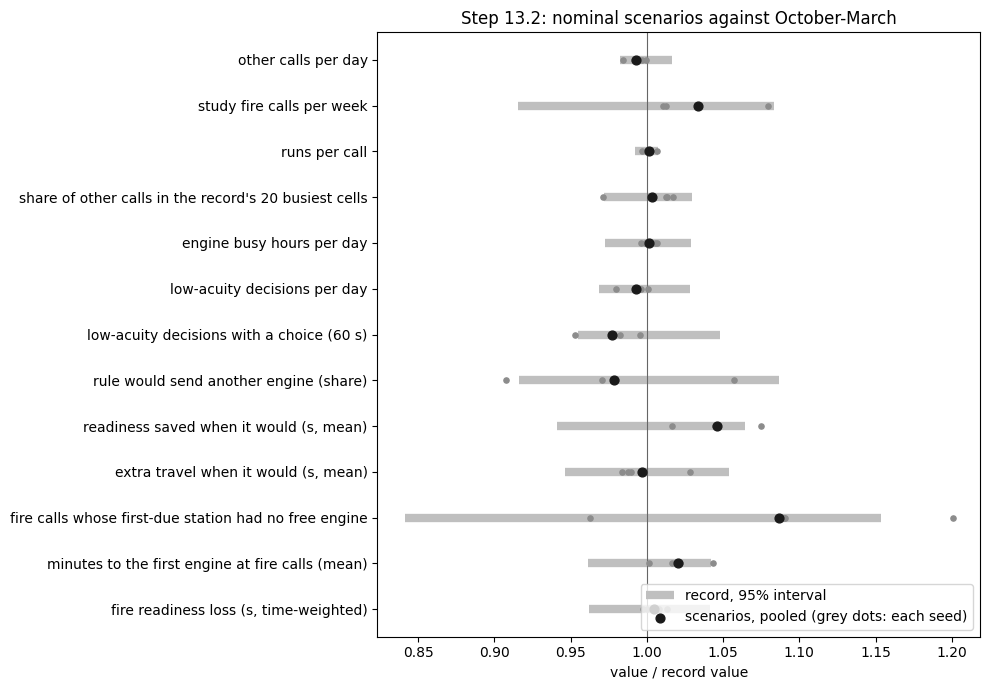

In [105]:
def weekly_block_ratio_interval(numerator, denominator, weeks):
    """Section 13.2: two-sided interval (BOOTSTRAP_INTERVAL) of sum(numerator) / sum(denominator) from
    BLOCK_BOOTSTRAP_DRAWS weekly block-bootstrap draws (weeks resampled with replacement, seed BLOCK_BOOTSTRAP_SEED), as
    weekly_block_interval does for a mean. The three Series share one index (one row per week here).

    Example: weekly_block_ratio_interval(pd.Series([4.0, 2.0]), pd.Series([2.0, 2.0]), pd.Series([0, 1])) -> (1.0, 2.0)
             # each draw takes two weeks: 8/4 = 2, 6/4 = 1.5 or 4/4 = 1
    """
    sums, counts = numerator.groupby(weeks).sum().to_numpy(), denominator.groupby(weeks).sum().to_numpy()
    picks = np.random.default_rng(BLOCK_BOOTSTRAP_SEED).integers(0, len(sums), size=(BLOCK_BOOTSTRAP_DRAWS, len(sums)))
    low, high = np.quantile(sums[picks].sum(axis=1) / counts[picks].sum(axis=1), BOOTSTRAP_INTERVAL)
    return float(low), float(high)


def weekly_calibration_parts(dispatches_table, runs_table, first_due, census, segments, top_cells, days):
    """Section 13.2: per week (days since DAY_ZERO // 7, over `days`), the numerator and denominator of each statistic the
    nominal scenarios must reproduce, for one version (the record's M0.4 run or a scenario's protocol run): calls (other
    calls per day, study fire calls per week, runs per call, share of other calls in the record's 20 busiest cells),
    engine busy hours per day, the room (low-acuity decisions per day, the share with a choice at ACTION_WINDOW_S, the
    share where the rule would send another engine, the readiness saved and the extra travel when it would), fire calls
    whose first-due station had no free engine, minutes to the first engine at fire calls, and the time-weighted fire
    readiness loss. Stand-in runs (outages) are left out. Returns a DataFrame (rows: weeks; columns: (statistic, part)).

    Example: parts = weekly_calibration_parts(dispatches, m04_protocol, first_due_m04, census, record_segments, top_cells, range(182))
             parts[("study fire calls per week", "numerator")].sum() -> 960
    """
    weeks = pd.Index(sorted({day // 7 for day in days}), name="week")
    days_in_week = pd.Series([day // 7 for day in days]).value_counts().reindex(weeks).astype(float)
    start_s, end_s = min(days) * 86400, (max(days) + 1) * 86400
    received_s = (dispatches_table["call_received_at"] - DAY_ZERO).dt.total_seconds()
    real = (~dispatches_table["protocol"].eq(OUT_OF_SERVICE_PROTOCOL).fillna(False) & dispatches_table["incident_lon"].notna()
            & (received_s >= start_s) & (received_s < end_s))
    calls = dispatches_table[real].groupby("incident_id").agg(received_s=("call_received_at", "first"), protocol=("protocol", "first"),
                                                              lon=("incident_lon", "first"), lat=("incident_lat", "first"), runs=("engine_id", "size"))
    calls["week"] = (calls["received_s"] - DAY_ZERO).dt.days // 7
    fire = calls["protocol"].isin(STUDY_FIRE_PROTOCOLS).fillna(False)
    x, y = pyproj.Transformer.from_crs("EPSG:4326", PROJECTED_CRS, always_xy=True).transform(calls["lon"].to_numpy(), calls["lat"].to_numpy())
    in_top = pd.Series(pd.MultiIndex.from_arrays([np.floor(x / READINESS_CELL_M).astype(int), np.floor(y / READINESS_CELL_M).astype(int)]).isin(top_cells),
                       index=calls.index)
    sent = runs_table[real.to_numpy()].dropna(subset=["engine_id", "dispatched_at", "cleared_at"])
    census_week = (census["dispatched_at"] - DAY_ZERO).dt.days // 7
    census = census[(census_week >= weeks.min()) & (census_week <= weeks.max())]
    census_week = census_week[census.index]
    switched = census[f"rule_engine_{ACTION_WINDOW_S}"] != census["protocol_engine"]
    saving = census[f"oc_saving_min_{ACTION_WINDOW_S}"]
    counted_saving = switched & np.isfinite(saving)
    fire_calls = first_due[(first_due["week"] >= weeks.min()) & (first_due["week"] <= weeks.max())]
    reached = fire_calls.dropna(subset=["minutes_to_first_on_scene"])
    segments = segments[(segments["start_s"] >= start_s) & (segments["start_s"] < end_s) & np.isfinite(segments["loss_min"])]
    duration = segments["end_s"] - segments["start_s"]

    def per_week(values, week):
        return pd.Series(values, dtype=float).groupby(np.asarray(week)).sum().reindex(weeks, fill_value=0.0)

    one = pd.Series(1.0, index=weeks)
    statistics = {
        "other calls per day": (per_week((~fire).astype(float), calls["week"]), days_in_week),
        "study fire calls per week": (per_week(fire.astype(float), calls["week"]), one),
        "runs per call": (per_week(calls["runs"].astype(float), calls["week"]), per_week(np.ones(len(calls)), calls["week"])),
        "share of other calls in the record's 20 busiest cells": (per_week((~fire & in_top).astype(float), calls["week"]),
                                                                  per_week((~fire).astype(float), calls["week"])),
        "engine busy hours per day": (per_week(((sent["cleared_at"] - sent["dispatched_at"]) / 3600).to_numpy(), sent["dispatched_at"] // (7 * 86400)),
                                      days_in_week),
        "low-acuity decisions per day": (per_week(np.ones(len(census)), census_week), days_in_week),
        f"low-acuity decisions with a choice ({ACTION_WINDOW_S} s)": (per_week((census[f"choices_{ACTION_WINDOW_S}"] >= 2).astype(float), census_week),
                                                                       per_week(np.ones(len(census)), census_week)),
        "rule would send another engine (share)": (per_week(switched.astype(float), census_week), per_week(np.ones(len(census)), census_week)),
        "readiness saved when it would (s, mean)": (per_week(np.where(counted_saving, 60 * saving.replace(np.inf, 0.0), 0.0), census_week),
                                                    per_week(counted_saving.astype(float), census_week)),
        "extra travel when it would (s, mean)": (per_week(np.where(switched, census[f"extra_travel_s_{ACTION_WINDOW_S}"], 0.0), census_week),
                                                 per_week(switched.astype(float), census_week)),
        "fire calls whose first-due station had no free engine": (per_week(fire_calls["committed"].astype(float), fire_calls["week"]),
                                                                  per_week(np.ones(len(fire_calls)), fire_calls["week"])),
        "minutes to the first engine at fire calls (mean)": (per_week(reached["minutes_to_first_on_scene"].to_numpy(), reached["week"]),
                                                             per_week(np.ones(len(reached)), reached["week"])),
        "fire readiness loss (s, time-weighted)": (per_week((60 * segments["loss_min"] * duration).to_numpy(), segments["start_s"] // (7 * 86400)),
                                                   per_week(duration.to_numpy(), segments["start_s"] // (7 * 86400)))}
    return pd.concat({(name, part): series for name, pair in statistics.items() for part, series in zip(["numerator", "denominator"], pair)}, axis=1)


def compare_scenarios_with_record(record_parts, scenario_parts, verbose=VERBOSE):
    """Section 13.2 (the done-criterion): each statistic of weekly_calibration_parts for the record (its value and weekly
    block-bootstrap interval) beside the nominal scenarios (the value pooled over all their weeks, and per seed), whether
    the pooled value falls inside the record's interval, and the spread of the weekly values (standard deviation) in both.
    scenario_parts: seed -> weekly_calibration_parts.

    Example: calibration = compare_scenarios_with_record(record_parts, {101: parts_101, 102: parts_102})
             calibration.loc["study fire calls per week", "inside record interval"] -> True
    """
    rows = {}
    for name in record_parts.columns.get_level_values(0).unique():
        numerator, denominator = record_parts[(name, "numerator")], record_parts[(name, "denominator")]
        low, high = weekly_block_ratio_interval(numerator, denominator, pd.Series(record_parts.index, index=record_parts.index))
        pooled = (sum(parts[(name, "numerator")].sum() for parts in scenario_parts.values())
                  / sum(parts[(name, "denominator")].sum() for parts in scenario_parts.values()))
        weekly_scenarios = pd.concat([parts[(name, "numerator")] / parts[(name, "denominator")] for parts in scenario_parts.values()])
        rows[name] = {"record": numerator.sum() / denominator.sum(), "interval low": low, "interval high": high, "scenarios": pooled,
                      "inside record interval": bool(low <= pooled <= high),
                      **{f"seed {seed}": parts[(name, "numerator")].sum() / parts[(name, "denominator")].sum() for seed, parts in scenario_parts.items()},
                      "record weekly SD": (numerator / denominator).std(), "scenario weekly SD": weekly_scenarios.std()}
    calibration = pd.DataFrame(rows).T
    if verbose:
        print(f"--- nominal scenarios against the record, October-March (pooled over {len(scenario_parts)} seeds; "
              f"{int(100 * (BOOTSTRAP_INTERVAL[1] - BOOTSTRAP_INTERVAL[0]))}% weekly block-bootstrap interval of the record)\n"
              f"{calibration.to_string(float_format=lambda value: f'{value:.3f}')}\n"
              f"statistics inside the record's interval: {int(calibration['inside record interval'].sum())} of {len(calibration)}\n")
    return calibration


# 13.1-13.2: nominal scenarios (whole October-March each) under the protocol, against the record
record_segments = fire_readiness(m04_protocol, engines, readiness_cells, travel_to_cells, fire_hour_share, wait_for_busy=True, verbose=False)[0]
record_parts = weekly_calibration_parts(dispatches, m04_protocol, first_due_m04, census, record_segments, busiest_cells, training_days)
nominal_scenarios, scenario_parts, scenario_checks = {}, {}, {}
for scenario_seed in SCENARIO_SEEDS:
    first_seed = scenario_seed == SCENARIO_SEEDS[0]
    scenario_calls, scenario_day_factors = generate_calls(call_pool, call_counts, call_dispersion, training_days, scenario_seed, verbose=first_seed)
    nominal_scenario = make_scenario(scenario_calls, no_outages, scenario_seed, verbose=first_seed)
    nominal_report = {}
    nominal_run = simulate_scenario(nominal_scenario, report=nominal_report)
    print(f"nominal scenario, seed {scenario_seed}: protocol run simulated")
    scenario_checks[(f"nominal, seed {scenario_seed}", "protocol")] = check_counterfactual_run(
        nominal_scenario["runs"], nominal_run, nominal_scenario["dispatches"], nominal_report, arrivals_by_call=True, verbose=first_seed)
    nominal_first_due, nominal_census, nominal_segments = measure_scenario_run(nominal_scenario, nominal_run)
    scenario_parts[scenario_seed] = weekly_calibration_parts(nominal_scenario["dispatches"], nominal_run, nominal_first_due, nominal_census,
                                                             nominal_segments, busiest_cells, training_days)
    nominal_scenarios[scenario_seed] = (scenario_calls, scenario_day_factors, nominal_scenario, nominal_run, nominal_first_due, nominal_census,
                                        nominal_segments)
calibration = compare_scenarios_with_record(record_parts, scenario_parts)



import shapely.geometry

record_cells = call_pool[~call_pool["fire"]].groupby(["cell_x", "cell_y"]).size()
scenario_cells = call_pool.loc[nominal_scenarios[SCENARIO_SEEDS[0]][0].query("~fire")["source_incident"]].groupby(["cell_x", "cell_y"]).size()


def cell_squares_of(values):
    """1 km squares (EPSG:4326) for a Series indexed by (cell_x, cell_y)."""
    squares = [shapely.geometry.box(x * READINESS_CELL_M, y * READINESS_CELL_M, (x + 1) * READINESS_CELL_M, (y + 1) * READINESS_CELL_M)
               for x, y in values.index]
    return gpd.GeoDataFrame({"value": values.to_numpy()}, geometry=squares, crs=PROJECTED_CRS).to_crs("EPSG:4326")


figure, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for axis, values, title, label in [(axes[0], record_cells, "record, October-March", "other calls per cell"),
                                   (axes[1], scenario_cells, f"nominal scenario (seed {SCENARIO_SEEDS[0]})", "other calls per cell"),
                                   (axes[2], resident_locations.groupby(["cell_x", "cell_y"])["residents"].sum(), "2020 residents (where growth puts new calls)", "residents per cell")]:
    county.boundary.plot(ax=axis, color="0.4", linewidth=0.8)
    city.boundary.plot(ax=axis, color="0.6", linewidth=0.6, linestyle="--")
    cell_squares_of(np.log10(values.astype(float))).plot(ax=axis, column="value", cmap="viridis", legend=True,
                                                          legend_kwds={"shrink": 0.6, "label": f"log10 {label}"})
    axis.set_title(title)
    axis.set_axis_off()
plt.show()

ratio = calibration[["record", "interval low", "interval high", "scenarios", *[f"seed {seed}" for seed in SCENARIO_SEEDS]]].astype(float)
ratio = ratio.div(ratio["record"], axis=0)
figure, axis = plt.subplots(figsize=(10, 7))
positions = np.arange(len(ratio))[::-1]
axis.hlines(positions, ratio["interval low"], ratio["interval high"], color="0.75", linewidth=6, label="record, 95% interval")
for seed in SCENARIO_SEEDS:
    axis.scatter(ratio[f"seed {seed}"], positions, color="0.55", s=14, zorder=3)
axis.scatter(ratio["scenarios"], positions, color="0.1", s=40, zorder=4, label="scenarios, pooled (grey dots: each seed)")
axis.axvline(1.0, color="0.4", linewidth=0.8)
axis.set_yticks(positions, ratio.index)
axis.set_xlabel("value / record value")
axis.set_title("Step 13.2: nominal scenarios against October-March")
axis.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Step 13.3 — The conditions on concrete cases

**Functions.**
- `add_demand_growth`: other calls ×k, with the extra calls placed by residents.
- `add_short_surges`: short surges of 6, 12 or 24 extra calls in 2 h within 2.5 km, one a day, visiting every
  first-due area in turn; a smaller surge is the start of a larger one (same place, time and travel draws).
- `add_outages` and `close_station`: stand-in runs that hold engines.
- `add_large_fires`: a large fire each week.
- `check_scenario_conditions`: in a simulated run, no real call got an engine while it was out, and every large fire
  got its engines.

**Check.** What each operator added, printed on its first cases; Step 13.4 prints what the outages and large fires did
in the runs.

In [106]:
def add_demand_growth(calls, day_factors, pool, counts, locations, factor, seed, verbose=VERBOSE):
    """Section 13 (more or fewer calls): other (non-fire) calls times `factor`; study fire calls are unchanged. Below 1,
    each other call is dropped with probability 1 - factor. Above 1, each day and hour gets a Poisson number of extra
    other calls with mean (factor - 1) x the day's other-call factor (generate_calls: the copied day's total over the
    expected total) x the hour's expected count, at uniform whole seconds of the
    hour. Each extra call is placed where people live: a residential block (build_resident_locations) drawn in proportion
    to its 2020 residents, every populated block eligible. Its type and fate come from a real other call drawn as for a
    nominal call (draw_source_calls: same block of hours, within SCENARIO_WINDOW_DAYS).

    Example: grown = add_demand_growth(calls, day_factors, pool, counts, locations, 1.3, seed=101)
             (~grown["fire"]).sum() / (~calls["fire"]).sum() -> 1.30, roughly; grown["location"] >= 0 for the extra calls
    """
    rng = np.random.default_rng([seed, 1])
    other = ~calls["fire"].to_numpy()
    if factor <= 1:
        changed = calls[~other | (rng.random(len(calls)) < factor)].reset_index(drop=True)
        extra = changed.iloc[:0]
    else:
        weight = (locations["residents"] / locations["residents"].sum()).to_numpy()
        candidates, moments, sources, places = {}, [], [], []
        for day in day_factors.index:
            numbers = rng.poisson((factor - 1) * day_factors.at[day, False] * expected_hourly_counts(counts, day).xs(False).to_numpy())
            for hour in np.flatnonzero(numbers):
                sources.extend(draw_source_calls(pool, day, False, hour // SCENARIO_BAND_HOURS, numbers[hour], rng, candidates))
                places.extend(rng.choice(len(locations), size=numbers[hour], p=weight))
                moments.extend(day * 86400 + hour * 3600 + rng.integers(0, 3600, size=numbers[hour]))
        seed_label = calls["incident_id"].iloc[0].split("-")[0]
        extra = pd.DataFrame({"incident_id": [f"{seed_label}-g{n:06d}" for n in range(len(moments))], "received_s": np.array(moments, dtype=float),
                              "source_incident": sources, "fire": False, "large_fire": False, "kind": "growth",
                              "location": np.array(places, dtype=int)})
        changed = pd.concat([calls, extra], ignore_index=True).sort_values("received_s", kind="stable").reset_index(drop=True)
    if verbose:
        busiest = pool[~pool["fire"]].groupby(["cell_x", "cell_y"]).size().nlargest(20).index
        source_cells = pd.MultiIndex.from_arrays([pool.loc[calls.loc[other, "source_incident"], "cell_x"], pool.loc[calls.loc[other, "source_incident"], "cell_y"]])
        before, after = int(other.sum()), int((~changed["fire"]).sum())
        message = (f"--- other calls x{factor}: {before:,} -> {after:,} ({after / before:.3f}); study fire calls {int(calls['fire'].sum()):,} -> "
                   f"{int(changed['fire'].sum()):,}\nshare in the record's 20 busiest cells: all other calls {source_cells.isin(busiest).mean():.3f}")
        if len(extra):
            placed = locations.loc[extra["location"]]
            source = pool.loc[extra["source_incident"]]
            message += (f", the extra calls {pd.MultiIndex.from_arrays([placed['cell_x'], placed['cell_y']]).isin(busiest).mean():.3f} (placed by residents)\n"
                        f"extra calls' sources: within {SCENARIO_WINDOW_DAYS} days {bool((np.abs(extra['received_s'].to_numpy() // 86400 - source['day'].to_numpy()) <= SCENARIO_WINDOW_DAYS).all())}, "
                        f"same block of hours {bool(((extra['received_s'] % 86400 // 3600) // SCENARIO_BAND_HOURS == source['band'].to_numpy()).all())}; "
                        f"blocks used {placed.index.nunique():,} of {len(locations):,}\nfirst extra calls (type from the source, place from a block):\n"
                        f"{extra.head(3).assign(source_protocol=source['protocol'].to_numpy()[:3], block_residents=placed['residents'].to_numpy()[:3], block_cell=list(zip(placed['cell_x'].to_numpy()[:3], placed['cell_y'].to_numpy()[:3]))).to_string()}")
        print(message + "\n")
    return changed


def add_short_surges(calls, pool, locations, days, extra_calls, seed, verbose=VERBOSE):
    """Section 13 (a short surge; a stress test, since the record holds no local burst beyond chance, at most 7 other
    calls within SURGE_RADIUS_M in SURGE_HOURS): SURGES_PER_DAY times a day, extra_calls other (non-fire) calls are
    added within SURGE_RADIUS_M of a centre over SURGE_HOURS from a uniform whole second of the day, each at a uniform
    whole second of the surge. Surges visit the first-due station areas in turn, in an order drawn per seed, so every
    area is tested equally often (the risk map of Usanov et al. 2019). The centre is a residential block of that area
    drawn in proportion to its residents; each call is placed at a block inside the disk drawn the same way, with its
    type and fate drawn as for a nominal call (draw_source_calls). Each surge draws from its own random stream ([seed,
    2, surge number]) for max(SURGE_EXTRA_CALLS) calls and keeps the first extra_calls, so a smaller surge is the start
    of a larger one at the same place and time; a call's incident id names its surge and its rank in it, so it also
    keeps its travel draw at every size. Returns the calls with the extra ones (kind 'surge') and one row per surge (with
    the disk's usual other calls over SURGE_HOURS in the training months, for scale).

    Example: surged, surges = add_short_surges(calls, pool, locations, range(182), 12, seed=101)
             surges.iloc[0] -> day 0, start, end, first-due station, centre block, cell, city flag, extra calls 12, usual calls
    """
    areas = np.sort(locations["first_due_station"].unique())
    order = np.random.default_rng([seed, 2]).permutation(len(areas))
    station = locations["first_due_station"].to_numpy()
    block_x, block_y, residents = locations["x"].to_numpy(), locations["y"].to_numpy(), locations["residents"].to_numpy(dtype=float)
    other = pool[~pool["fire"]]
    other_x, other_y = other["x"].to_numpy(), other["y"].to_numpy()
    training_hours = (TRAINING_MONTHS_END - DAY_ZERO).days * 24
    last_day, most = max(days), max(SURGE_EXTRA_CALLS)
    seed_label = calls["incident_id"].iloc[0].split("-")[0]
    candidates, surge_rows, incident_ids, moments, sources, places = {}, [], [], [], [], []
    for position, day in enumerate(days):
        for slot in range(SURGES_PER_DAY):
            number = position * SURGES_PER_DAY + slot
            area = areas[order[number % len(areas)]]
            rng = np.random.default_rng([seed, 2, number])
            in_area = np.flatnonzero(station == area)
            centre = int(rng.choice(in_area, p=residents[in_area] / residents[in_area].sum()))
            inside = np.flatnonzero(np.hypot(block_x - block_x[centre], block_y - block_y[centre]) <= SURGE_RADIUS_M)
            start = day * 86400 + int(rng.integers(0, 86400))
            surge_moments = start + rng.integers(0, SURGE_HOURS * 3600, size=most)
            surge_places = rng.choice(inside, size=most, p=residents[inside] / residents[inside].sum())
            surge_sources = [draw_source_calls(pool, int(min(moment // 86400, last_day)), False, int(moment % 86400 // 3600) // SCENARIO_BAND_HOURS,
                                               1, rng, candidates)[0] for moment in surge_moments]
            incident_ids.extend(f"{seed_label}-s{number:05d}-{rank:02d}" for rank in range(extra_calls))   # same id (so same travel draws) at every size
            moments.extend(surge_moments[:extra_calls])
            places.extend(surge_places[:extra_calls])
            sources.extend(surge_sources[:extra_calls])
            surge_rows.append({"day": day, "start_s": start, "end_s": start + SURGE_HOURS * 3600, "first_due_station": area, "centre_block": centre,
                               "cell_x": int(locations.at[centre, "cell_x"]), "cell_y": int(locations.at[centre, "cell_y"]),
                               "focal": bool(locations.at[centre, "focal"]), "extra_calls": extra_calls,
                               "usual_other_calls_in_disk": int(np.sum(np.hypot(other_x - block_x[centre], other_y - block_y[centre]) <= SURGE_RADIUS_M))
                                                            / training_hours * SURGE_HOURS})
    extra = pd.DataFrame({"incident_id": incident_ids, "received_s": np.array(moments, dtype=float), "source_incident": sources, "fire": False,
                          "large_fire": False, "kind": "surge", "location": np.array(places, dtype=int)})
    surges = pd.DataFrame(surge_rows)
    if verbose:
        show_table(f"short surges ({extra_calls} extra calls each)", surges, verbose)
        surge_of_call = np.repeat(np.arange(len(surges)), extra_calls)
        centre_of_call = surges["centre_block"].to_numpy()[surge_of_call]
        placed = locations.loc[extra["location"]]
        distance = np.hypot(placed["x"].to_numpy() - block_x[centre_of_call], placed["y"].to_numpy() - block_y[centre_of_call])
        source = pool.loc[extra["source_incident"]]
        first = extra.head(extra_calls).assign(minutes_after_start=(extra["received_s"].head(extra_calls) - surges.at[0, "start_s"]) / 60,
                                               source_protocol=source["protocol"].to_numpy()[:extra_calls],
                                               metres_from_centre=distance[:extra_calls].round(0))
        per_area = surges.groupby("first_due_station").size()
        print(f"surges {len(surges)} over {len(per_area)} first-due areas ({per_area.min()}-{per_area.max()} each); extra calls {len(extra):,}; usual other "
              f"calls in the disk over {SURGE_HOURS} h: median {surges['usual_other_calls_in_disk'].median():.2f}, so a surge is "
              f"{np.median(extra_calls / surges['usual_other_calls_in_disk'].clip(lower=0.01)):.0f} times the usual (median)\n"
              f"first surge ({surges.at[0, 'first_due_station']}, day {surges.at[0, 'day']}, from second {surges.at[0, 'start_s']:,} of the period):\n"
              f"{first[['incident_id', 'minutes_after_start', 'source_incident', 'source_protocol', 'location', 'metres_from_centre']].round(1).to_string()}\n"
              f"checks: every call within {SURGE_RADIUS_M} m of its centre {bool((distance <= SURGE_RADIUS_M).all())}, inside its surge's "
              f"{SURGE_HOURS} h {bool(((extra['received_s'].to_numpy() >= surges['start_s'].to_numpy()[surge_of_call]) & (extra['received_s'].to_numpy() < surges['end_s'].to_numpy()[surge_of_call])).all())}, "
              f"source in the same block of hours {bool(((extra['received_s'] % 86400 // 3600) // SCENARIO_BAND_HOURS == source['band'].to_numpy()).all())} "
              f"and within {SCENARIO_WINDOW_DAYS} days {bool((np.abs(np.minimum(extra['received_s'].to_numpy() // 86400, last_day) - source['day'].to_numpy()) <= SCENARIO_WINDOW_DAYS).all())}\n")
    return pd.concat([calls, extra], ignore_index=True).sort_values("received_s", kind="stable").reset_index(drop=True), surges


def add_outages(engines, days, engine_count, seed, verbose=VERBOSE):
    """Section 13 (fewer engines): each day, engine_count engines drawn at random among those in service all that day are
    out of service from midnight to midnight. Returns the outages (engine_id, start_s, end_s; seconds since DAY_ZERO).

    Example: add_outages(engines, range(2), 2, seed=101) -> 4 rows, e.g. E24 0-86,400 s, E5 0-86,400 s, then day 1
    """
    rng = np.random.default_rng([seed, 3, engine_count])
    rows = []
    for day in days:
        start, end = DAY_ZERO + pd.Timedelta(days=day), DAY_ZERO + pd.Timedelta(days=day + 1)
        in_service = engines.loc[(engines["in_service_from"] <= start) & (engines["in_service_to"] >= end), "engine_id"].to_numpy()
        rows += [(engine_id, day * 86400.0, (day + 1) * 86400.0) for engine_id in rng.choice(in_service, size=engine_count, replace=False)]
    outages = pd.DataFrame(rows, columns=["engine_id", "start_s", "end_s"])
    if verbose:
        print(f"--- {engine_count} engines out each day: {len(outages):,} engine-days; first days:\n{outages.head(2 * engine_count).to_string()}\n"
              f"engine-days per engine (top five): {outages['engine_id'].value_counts().head(5).to_dict()}\n")
    return outages


def close_station(engines, station, days, verbose=VERBOSE):
    """Section 13 (a closed station): every engine of `station` out of service from the first of `days` to the end of the
    last. Returns the outages (engine_id, start_s, end_s).

    Example: close_station(engines, "GFR_03", range(182)) -> one row: E3, 0 to 15,724,800 s
    """
    outages = pd.DataFrame({"engine_id": engines.loc[engines["home_station"].eq(station), "engine_id"].to_numpy(),
                            "start_s": min(days) * 86400.0, "end_s": (max(days) + 1) * 86400.0})
    if verbose:
        print(f"--- station {station} closed:\n{outages.to_string()}\n")
    return outages


def add_large_fires(calls, pool, days, seed, verbose=VERBOSE):
    """Section 13 (a large fire): LARGE_FIRES_PER_WEEK in each week (days since DAY_ZERO // 7), at a uniform whole second
    of the week, at the location of a real training-month structure fire (STRUCTURE_FIRE_PROTOCOL, with an engine on
    scene) drawn at random; build_scenario gives it LARGE_FIRE_ENGINES runs that all arrive and stay LARGE_FIRE_ON_SCENE_S.
    Returns the calls with the large fires (kind 'large fire').

    Example: add_large_fires(calls, pool, range(182), seed=101)["large_fire"].sum() -> 26
    """
    rng = np.random.default_rng([seed, 4])
    sites = pool.index[pool["protocol"].eq(STRUCTURE_FIRE_PROTOCOL).fillna(False).to_numpy(dtype=bool) & (pool["arrival_row"] >= 0).to_numpy()]
    moments, sources = [], []
    for week in sorted({day // 7 for day in days}):
        week_days = [day for day in days if day // 7 == week]
        for _ in range(LARGE_FIRES_PER_WEEK):
            moments.append(min(week_days) * 86400 + int(rng.integers(0, len(week_days) * 86400)))
            sources.append(sites[rng.integers(len(sites))])
    seed_label = calls["incident_id"].iloc[0].split("-")[0]
    extra = pd.DataFrame({"incident_id": [f"{seed_label}-L{n:04d}" for n in range(len(moments))], "received_s": np.array(moments, dtype=float),
                          "source_incident": sources, "fire": True, "large_fire": True, "kind": "large fire", "location": -1})
    if verbose:
        print(f"--- large fires: {len(extra)} ({LARGE_FIRE_ENGINES} engines for {LARGE_FIRE_ON_SCENE_S / 3600:.1f} h each), at real "
              f"structure fire locations ({len(sites)} candidates); first three:\n"
              f"{extra.head(3).assign(cell=list(zip(pool.loc[extra['source_incident'].head(3), 'cell_x'], pool.loc[extra['source_incident'].head(3), 'cell_y']))).to_string()}\n")
    return pd.concat([calls, extra], ignore_index=True).sort_values("received_s", kind="stable").reset_index(drop=True)


def check_scenario_conditions(scenario, simulated, verbose=VERBOSE):
    """Section 13.3: what the outages and large fires of a scenario did in a simulated run. Outages: runs of real calls
    sent to an engine during its scheduled outage (from the stand-in's scheduled start to its end; must be 0), and
    stand-ins that waited for their engine to come back from a call (count, median minutes). Large fires: per fire, the engines that reached it, minutes from the call to the
    first and the last arrival, and hours on scene.

    Example: checks, large_fires = check_scenario_conditions(scenario, protocol_run)
             checks["real runs sent to an engine out of service"] -> 0
    """
    table = scenario["dispatches"]
    stand_in = table["protocol"].eq(OUT_OF_SERVICE_PROTOCOL).fillna(False).to_numpy(dtype=bool)
    real_runs = simulated[~stand_in].dropna(subset=["engine_id", "dispatched_at"])
    sent_while_out = 0
    for row in np.flatnonzero(stand_in):
        scheduled_from, scheduled_to = scenario["runs"].at[row, "dispatched_at"], scenario["runs"].at[row, "cleared_at"]
        own = real_runs[real_runs["engine_id"] == scenario["runs"].at[row, "engine_id"]]
        sent_while_out += int(((own["dispatched_at"] >= scheduled_from) & (own["dispatched_at"] < scheduled_to)).sum())
    waited_min = (simulated.loc[stand_in, "dispatched_at"] - scenario["runs"].loc[stand_in, "dispatched_at"]) / 60
    large = scenario["large_fire"].to_numpy(dtype=bool)
    received_s = scenario["runs"].loc[large, "call_received_at"]
    large_fires = simulated[large].assign(incident_id=table.loc[large, "incident_id"].astype(object).to_numpy(), received_s=received_s).groupby("incident_id").agg(
        engines_on_scene=("arrived_at", "count"), engines=("engine_id", lambda engine: ", ".join(engine.dropna())),
        first_arrival_min=("arrived_at", "min"), last_arrival_min=("arrived_at", "max"), received_s=("received_s", "first"),
        on_scene_h=("cleared_at", "max"))
    if len(large_fires):
        large_fires["on_scene_h"] = (large_fires["on_scene_h"] - large_fires["last_arrival_min"]) / 3600
        for column in ["first_arrival_min", "last_arrival_min"]:
            large_fires[column] = (large_fires[column] - large_fires["received_s"]) / 60
    checks = pd.Series({"stand-in runs (engine-outages)": int(stand_in.sum()),
                        "real runs sent to an engine out of service": sent_while_out,
                        "stand-ins that waited for their engine (count)": int((waited_min > 0).sum()),
                        "stand-ins that waited: median minutes": waited_min[waited_min > 0].median(),
                        "large fires": len(large_fires),
                        "large fires with every engine on scene": int((large_fires["engines_on_scene"] == LARGE_FIRE_ENGINES).sum()) if len(large_fires) else 0})
    if verbose:
        print(f"--- what the outages and large fires did\n{checks.round(2).to_string()}\n"
              + (f"large fires (first three):\n{large_fires.head(3).round(2).to_string()}\n" if len(large_fires) else ""))
    return checks, large_fires


def describe_room(dispatches_table, census, first_due, segments, days):
    """Section 13.4: the room for another engine under one condition, from its protocol run over `days`: calls, low-acuity
    decisions per day, the share with a choice at ACTION_WINDOW_S, how often and how much the rule would change, fire
    calls whose first-due station had no free engine, and the time-weighted fire readiness loss.

    Example: describe_room(scenario["dispatches"], census, first_due, segments, range(182))["rule would send another engine"]
             -> 0.117  # nominal October-March, roughly
    """
    start_s, end_s = min(days) * 86400, (max(days) + 1) * 86400
    received_s = (dispatches_table["call_received_at"] - DAY_ZERO).dt.total_seconds()
    real = (~dispatches_table["protocol"].eq(OUT_OF_SERVICE_PROTOCOL).fillna(False) & (received_s >= start_s) & (received_s < end_s))
    calls = dispatches_table[real].groupby("incident_id")["protocol"].first()
    fire = calls.isin(STUDY_FIRE_PROTOCOLS).fillna(False)
    switched = census[f"rule_engine_{ACTION_WINDOW_S}"] != census["protocol_engine"]
    saving = census[f"oc_saving_min_{ACTION_WINDOW_S}"]
    segments = segments[(segments["start_s"] >= start_s) & (segments["start_s"] < end_s)]
    duration = segments["end_s"] - segments["start_s"]
    return pd.Series({
        "other calls per day": (~fire).sum() / len(days), "study fire calls per week": fire.sum() / len(days) * 7,
        "low-acuity decisions per day": len(census) / len(days),
        f"with a choice ({ACTION_WINDOW_S} s)": (census[f"choices_{ACTION_WINDOW_S}"] >= 2).mean(),
        "rule would send another engine": switched.mean(), "  per day": switched.sum() / len(days),
        "  readiness saved (s, mean)": 60 * saving[switched & np.isfinite(saving)].mean(),
        "  saving infinite (the protocol's engine was the last for a cell)": int((switched & ~np.isfinite(saving)).sum()),
        "fire calls with no free first-due engine": first_due["committed"].mean(),
        "fire readiness loss (s, time-weighted)": 60 * np.average(segments["loss_min"], weights=duration),
        "hours with readiness loss over 1 min": duration[segments["loss_min"] > 1].sum() / 3600})


# 13.3-13.4: each condition on the first seed's calls: what it does, its room, and the opportunity-cost rule against the protocol
base_seed = SCENARIO_SEEDS[0]
base_calls, base_day_factors = nominal_scenarios[base_seed][:2]
surge_sets = {count: add_short_surges(base_calls, call_pool, resident_locations, training_days, count, base_seed, verbose=count == SURGE_EXTRA_CALLS[0])
              for count in SURGE_EXTRA_CALLS}
surge_condition_counts = {f"short surges, {count} extra calls": count for count in SURGE_EXTRA_CALLS}
conditions = {"nominal": (base_calls, no_outages),
              **{f"other calls x{factor}": (add_demand_growth(base_calls, base_day_factors, call_pool, call_counts, resident_locations, factor, base_seed),
                                            no_outages) for factor in DEMAND_FACTORS},
              **{name: (surge_sets[count][0], no_outages) for name, count in surge_condition_counts.items()},
              **{f"{count} engines out each day": (base_calls, add_outages(engines, training_days, count, base_seed)) for count in OUTAGE_ENGINE_COUNTS},
              **{f"station {station} closed": (base_calls, close_station(engines, station, training_days)) for station in HOTSPOT_STATIONS},
              "a large fire each week": (add_large_fires(base_calls, call_pool, training_days, base_seed), no_outages)}

--- short surges (6 extra calls each) (182, 10)
   day  start_s   end_s first_due_station  centre_block  cell_x  cell_y  focal  extra_calls  usual_other_calls_in_disk
0    0    69643   76843             CO_16          1198     363    3285  False            6                   0.233516
1    1   100290  107490             CO_21          3592     357    3293  False            6                   0.030678
2    2   234262  241462             CO_24          3810     395    3287  False            6                   0.012821
3    3   280592  287792             CO_31           116     386    3264  False            6                   0.003663
4    4   405398  412598             CO_28            47     344    3284  False            6                   0.043956

surges 182 over 25 first-due areas (7-8 each); extra calls 1,092; usual other calls in the disk over 2 h: median 0.10, so a surge is 62 times the usual (median)
first surge (CO_16, day 0, from second 69,643 of the period):
        incide

--- other calls x0.8: 15,536 -> 12,420 (0.799); study fire calls 970 -> 970
share in the record's 20 busiest cells: all other calls 0.235

--- other calls x1.1: 15,536 -> 17,047 (1.097); study fire calls 970 -> 970
share in the record's 20 busiest cells: all other calls 0.235, the extra calls 0.134 (placed by residents)
extra calls' sources: within 14 days True, same block of hours True; blocks used 912 of 4,261
first extra calls (type from the source, place from a block):
      incident_id  received_s source_incident   fire  large_fire    kind  location source_protocol  block_residents   block_cell
0  syn101-g000000     30555.0     101024-0221  False       False  growth      3949             E24               22  (349, 3300)
1  syn101-g000001     32315.0     101224-0206  False       False  growth      2070             E12               50  (360, 3278)
2  syn101-g000002     37632.0     100924-0238  False       False  growth      2532             E16              486  (374, 3285)



--- other calls x1.3: 15,536 -> 20,226 (1.302); study fire calls 970 -> 970
share in the record's 20 busiest cells: all other calls 0.235, the extra calls 0.146 (placed by residents)
extra calls' sources: within 14 days True, same block of hours True; blocks used 1,813 of 4,261
first extra calls (type from the source, place from a block):
      incident_id  received_s source_incident   fire  large_fire    kind  location source_protocol  block_residents   block_cell
0  syn101-g000000     18843.0     100324-0077  False       False  growth      2575             F52               64  (368, 3280)
1  syn101-g000001     26053.0     101424-0070  False       False  growth      3773             E06              179  (362, 3276)
2  syn101-g000002     27497.0     100524-0142  False       False  growth      2305             E12              120  (368, 3293)



--- other calls x1.5: 15,536 -> 23,369 (1.504); study fire calls 970 -> 970
share in the record's 20 busiest cells: all other calls 0.235, the extra calls 0.145 (placed by residents)
extra calls' sources: within 14 days True, same block of hours True; blocks used 2,324 of 4,261
first extra calls (type from the source, place from a block):
      incident_id  received_s source_incident   fire  large_fire    kind  location source_protocol  block_residents   block_cell
0  syn101-g000000     19220.0     101224-0140  False       False  growth      1760             E26              753  (363, 3286)
1  syn101-g000001     25950.0     100224-0099  False       False  growth      2829             E01               70  (369, 3277)
2  syn101-g000002     26598.0     101324-0192  False       False  growth      1642             E10               11  (344, 3275)

--- 1 engines out each day: 182 engine-days; first days:
  engine_id  start_s     end_s
0        E2      0.0   86400.0
1       Q28  86400.0  1

## Step 13.4 — Each condition: the protocol and the opportunity-cost rule under the same random draws

**Check.** Per condition, the protocol and the rule (60 s) run under the same random draws; the state checks and what
the outages and large fires did are printed for the conditions that have them.

In [107]:
training_end_s = len(training_days) * 86400
condition_rooms, condition_comparisons, surge_segments = {}, {}, {}
for condition_name, (condition_calls, condition_outages) in conditions.items():
    print(f"=== condition: {condition_name}")
    if condition_name == "nominal":
        condition_scenario, condition_protocol_run, condition_first_due, condition_census, condition_segments = nominal_scenarios[base_seed][2:]
    else:
        condition_scenario = make_scenario(condition_calls, condition_outages, base_seed,
                                           verbose=condition_name in (f"{OUTAGE_ENGINE_COUNTS[0]} engines out each day", "a large fire each week"))
        condition_report = {}
        condition_protocol_run = simulate_scenario(condition_scenario, report=condition_report)
        scenario_checks[(condition_name, "protocol")] = check_counterfactual_run(
            condition_scenario["runs"], condition_protocol_run, condition_scenario["dispatches"], condition_report, arrivals_by_call=True, verbose=False)
        condition_first_due, condition_census, condition_segments = measure_scenario_run(condition_scenario, condition_protocol_run)
    condition_effects, _ = check_scenario_conditions(condition_scenario, condition_protocol_run,
                                                     verbose=len(condition_outages) > 0 or bool(condition_scenario["large_fire"].any()))
    scenario_checks[(condition_name, "protocol")] = pd.concat([scenario_checks[(condition_name, "protocol")] if condition_name != "nominal"
                                                               else scenario_checks[(f"nominal, seed {base_seed}", "protocol")], condition_effects])
    condition_rule_report = {}
    condition_rule_run = simulate_scenario(condition_scenario, ACTION_WINDOW_S, condition_rule_report)
    scenario_checks[(condition_name, "opportunity-cost rule")] = check_counterfactual_run(
        condition_scenario["runs"], condition_rule_run, condition_scenario["dispatches"], condition_rule_report, arrivals_by_call=True, verbose=False)
    condition_rule_segments = fire_readiness(condition_rule_run, engines, readiness_cells, travel_to_cells, fire_hour_share,
                                             wait_for_busy=True, verbose=False)[0]
    if condition_name in surge_condition_counts:
        surge_segments[surge_condition_counts[condition_name]] = (condition_segments, condition_rule_segments)
    condition_rooms[condition_name] = describe_room(condition_scenario["dispatches"], condition_census, condition_first_due, condition_segments,
                                                    training_days)
    condition_comparisons[condition_name] = compare_policies(
        condition_scenario["dispatches"], simulated_dispatch_table(condition_scenario["dispatches"], condition_protocol_run, engines, verbose=False),
        simulated_dispatch_table(condition_scenario["dispatches"], condition_rule_run, engines, verbose=False), condition_first_due,
        condition_segments[condition_segments["start_s"] < training_end_s], condition_rule_segments[condition_rule_segments["start_s"] < training_end_s],
        fire_hour_share, condition_scenario["low_acuity"], verbose=False).drop(index="fire calls, Jul-Sep")

=== condition: nominal


=== condition: other calls x0.8


=== condition: other calls x1.1


=== condition: other calls x1.3


=== condition: other calls x1.5


/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/2408943026.py:40: RuntimeWarning: invalid value encountered in scalar subtract
  pick = costs[near].idxmin() if costs[protocol_engine] - costs[near].min() > OC_TIE_S / 60 else protocol_engine
/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/2408943026.py:42: RuntimeWarning: invalid value encountered in scalar subtract
  f"oc_saving_min_{window}": costs[protocol_engine] - costs[pick],


... (27 outputs left out)

--- scenario dispatch table (seed 101) (18664, 32)
     incident_id    call_received_at                       problem call_type protocol determinant_level determinant_code  priority  n_engines_sent  incident_lon  incident_lat jurisdiction  focal engine_id engine_type engine_agency  engine_lon_at_dispatch  engine_lat_at_dispatch from_station  at_home       dispatched_at          enroute_at          arrived_at          cleared_at  turnout_s  travel_s  on_scene_s  arrival_order  staged  cancelled  auto_aid qc_note
0  syn101-000000 2024-10-01 00:31:13   E12D - CONVULSIONS/SEIZURES   Medical      E12                 D             E12D      High               1    -82.354765     29.706196          GFR   True        Q8           Q           GFR              -82.370836               29.692203       GFR_08     True 2024-10-01 00:32:08 2024-10-01 00:33:00 2024-10-01 00:39:34 2024-10-01 01:00:12         52       394        1238              1   False      False     False        
1  syn101-000001 

/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/2408943026.py:40: RuntimeWarning: invalid value encountered in scalar subtract
  pick = costs[near].idxmin() if costs[protocol_engine] - costs[near].min() > OC_TIE_S / 60 else protocol_engine
/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/2408943026.py:42: RuntimeWarning: invalid value encountered in scalar subtract
  f"oc_saving_min_{window}": costs[protocol_engine] - costs[pick],
/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/2408943026.py:40: RuntimeWarning: invalid value encountered in scalar subtract
  pick = costs[near].idxmin() if costs[protocol_engine] - costs[near].min() > OC_TIE_S / 60 else protocol_engine
/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/2408943026.py:42: RuntimeWarning: invalid value encountered in scalar subtract
  f"oc_saving_min_{window}": costs[protocol_engine] - costs[pick],


/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/2408943026.py:40: RuntimeWarning: invalid value encountered in scalar subtract
  pick = costs[near].idxmin() if costs[protocol_engine] - costs[near].min() > OC_TIE_S / 60 else protocol_engine
/var/folders/07/dgkw2fdj0cd4ypmkjh1_92y80000gn/T/ipykernel_53432/2408943026.py:42: RuntimeWarning: invalid value encountered in scalar subtract
  f"oc_saving_min_{window}": costs[protocol_engine] - costs[pick],


--- what the outages and large fires did
stand-in runs (engine-outages)                     0.0
real runs sent to an engine out of service         0.0
stand-ins that waited for their engine (count)     0.0
stand-ins that waited: median minutes              NaN
large fires                                       26.0
large fires with every engine on scene            26.0
large fires (first three):
              engines_on_scene                   engines  first_arrival_min  last_arrival_min  received_s  on_scene_h
incident_id                                                                                                          
syn101-L0000                 6    E2, E1, E3, E5, E9, E4               6.86             15.85    503265.0         4.0
syn101-L0001                 6   E3, E60, E1, E2, E4, E9               7.00             28.78    621579.0         4.0
syn101-L0002                 6  E7, Q8, E4, E5, E25, Q23               5.47             23.06   1489568.0         4.0



## Step 13.5 — Short surges in every first-due area; the room and the rule under each condition

**Functions.** `readiness_loss_in_windows`: the time-weighted readiness loss over a window, exact where a window cuts a
segment with waits.

**Check.**
- For every surge, the fire readiness loss over its 2 h against the same hours without it (four seeds), and the rule
  minus the protocol then (first seed); overall and by first-due area.
- The room table and the rule minus the protocol with research.md's classes, for every condition.
- Figures: the room and the rule's fire difference by condition; a map of what a surge costs by first-due area.

short surges, 6 extra calls, seed 101: readiness during the surges measured


short surges, 6 extra calls, seed 102: readiness during the surges measured


short surges, 6 extra calls, seed 103: readiness during the surges measured


short surges, 6 extra calls, seed 104: readiness during the surges measured
short surges, 12 extra calls, seed 101: readiness during the surges measured


short surges, 12 extra calls, seed 102: readiness during the surges measured


short surges, 12 extra calls, seed 103: readiness during the surges measured


short surges, 12 extra calls, seed 104: readiness during the surges measured
short surges, 24 extra calls, seed 101: readiness during the surges measured


short surges, 24 extra calls, seed 102: readiness during the surges measured


short surges, 24 extra calls, seed 103: readiness during the surges measured


short surges, 24 extra calls, seed 104: readiness during the surges measured
--- short surges (2 h within 2500 m, one a day, visiting every first-due area in turn): the fire readiness loss while a surge lasts, against the same hours without it (four seeds), and the rule minus the protocol then (seed 101)
             surges  usual other calls in the disk  readiness loss without the surge (s)  readiness cost (s)  cost interval low  cost interval high  rule minus protocol (s, first seed)  rule interval low  rule interval high
extra calls                                                                                                                                                                                                                    
6             728.0                           0.25                                 11.37                8.85               8.44                9.21                                -0.43              -0.61               -0.28
12            728.0   

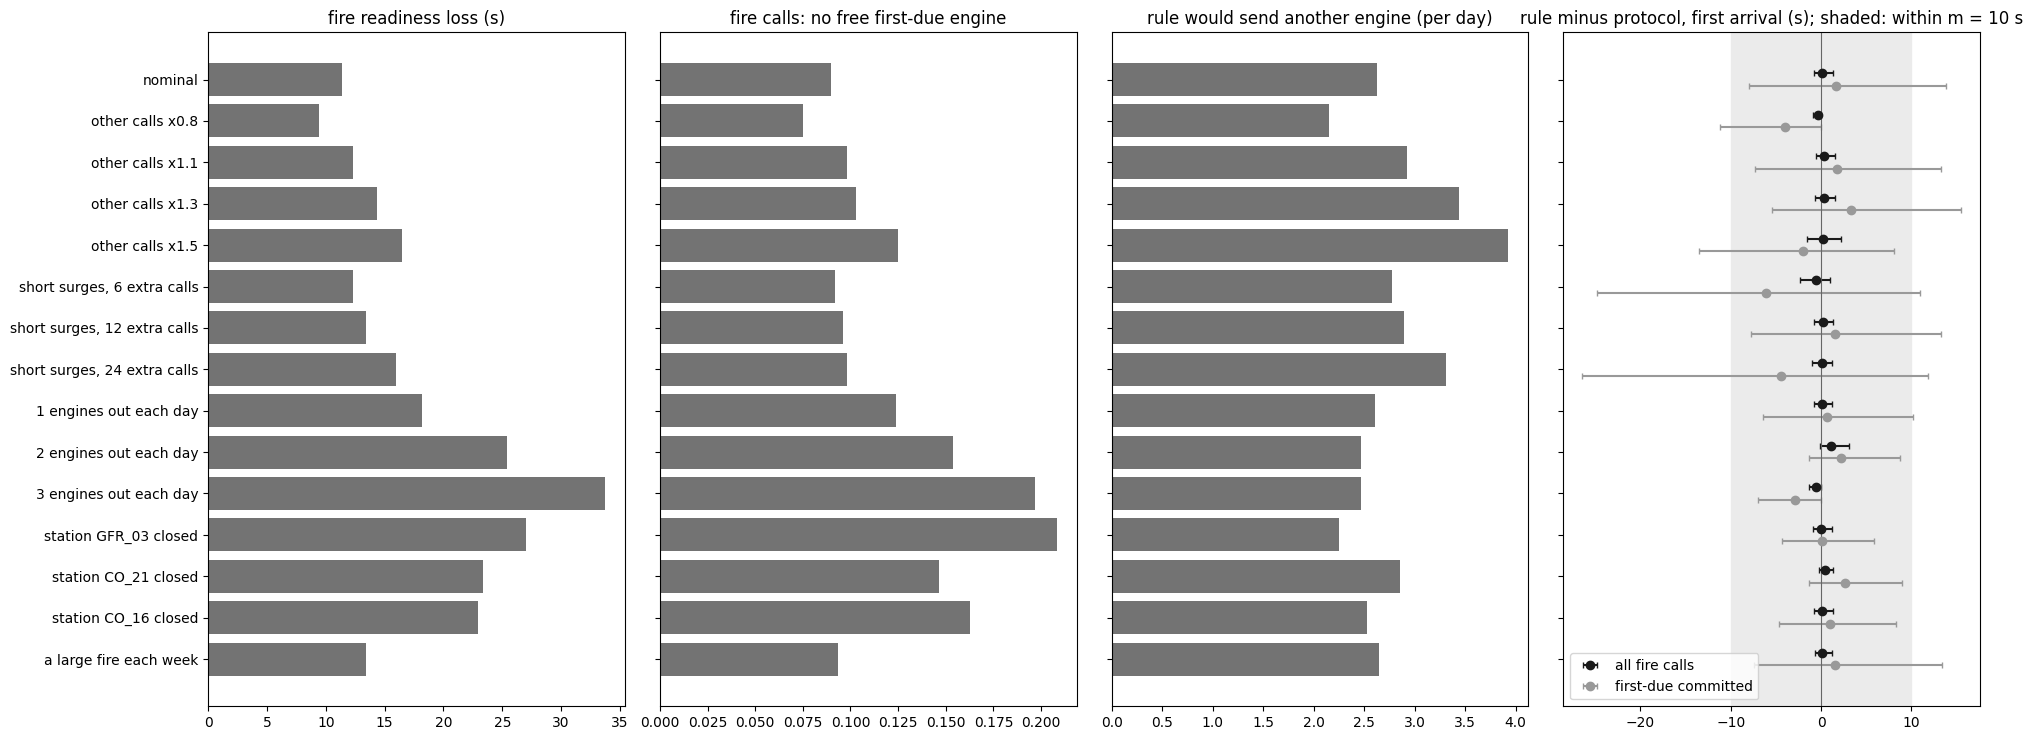

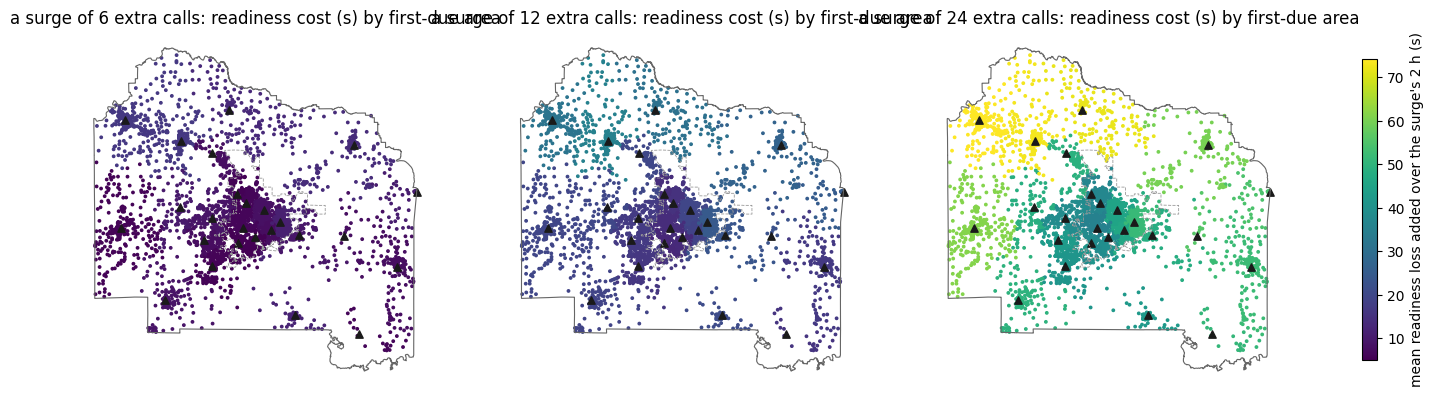

In [108]:
def readiness_loss_in_windows(segments, starts_s, ends_s):
    """Section 13.5: the time-weighted fire readiness loss (R - R_full, seconds) over each window [start, end), from
    fire_readiness's segments (contiguous). Inside a segment the loss is its middle value minus waiting_weight x (time -
    middle) (waiting_weight 0 without waits), so a window that cuts a segment is integrated exactly.

    Example: readiness_loss_in_windows(segments, [0.0], [7200.0]) -> the loss over the first two hours, in seconds
             toys: segments 0-60 s with a loss of 1 min and 60-120 s with 3 min; window 30-90 s -> (30 x 60 + 30 x 180) / 60 = 120 s
                   one segment 0-600 s, loss 5 min at its middle, waiting_weight 1 (falls from 10 to 0 min); window 0-300 s -> 450 s
    """
    segment_start, segment_end = segments["start_s"].to_numpy(), segments["end_s"].to_numpy()
    middle, level = (segment_start + segment_end) / 2, 60 * segments["loss_min"].to_numpy()
    slope = segments["waiting_weight"].to_numpy() if "waiting_weight" in segments else np.zeros(len(segments))
    integral = np.concatenate([[0.0], np.cumsum(level * (segment_end - segment_start))])

    def integral_to(moments):
        i = np.clip(np.searchsorted(segment_start, moments, side="right") - 1, 0, len(segments) - 1)
        return (integral[i] + level[i] * (moments - segment_start[i])
                - slope[i] * ((moments - middle[i]) ** 2 - (segment_start[i] - middle[i]) ** 2) / 2)

    starts, ends = np.asarray(starts_s, dtype=float), np.asarray(ends_s, dtype=float)
    return (integral_to(ends) - integral_to(starts)) / (ends - starts)


# 13.5: short surges in every first-due area (a stress sweep): what a surge costs in fire readiness while it lasts,
# against the same hours without it (four seeds), and what the opportunity-cost rule changes then (first seed)
surge_tables = []
for count in SURGE_EXTRA_CALLS:
    for scenario_seed in SCENARIO_SEEDS:
        if scenario_seed == base_seed:
            seed_surges = surge_sets[count][1]
            seed_surge_segments, seed_rule_segments = surge_segments[count]
        else:
            seed_surged_calls, seed_surges = add_short_surges(nominal_scenarios[scenario_seed][0], call_pool, resident_locations, training_days,
                                                              count, scenario_seed, verbose=False)
            seed_scenario = make_scenario(seed_surged_calls, no_outages, scenario_seed)
            seed_report = {}
            seed_run = simulate_scenario(seed_scenario, report=seed_report)
            scenario_checks[(f"short surges, {count} extra calls, seed {scenario_seed}", "protocol")] = check_counterfactual_run(
                seed_scenario["runs"], seed_run, seed_scenario["dispatches"], seed_report, arrivals_by_call=True, verbose=False)
            seed_surge_segments = fire_readiness(seed_run, engines, readiness_cells, travel_to_cells, fire_hour_share, wait_for_busy=True,
                                                 verbose=False)[0]
            seed_rule_segments = None
        loss_with_surge = readiness_loss_in_windows(seed_surge_segments, seed_surges["start_s"], seed_surges["end_s"])
        surge_tables.append(seed_surges.assign(
            seed=scenario_seed,
            readiness_loss_without_surge_s=readiness_loss_in_windows(nominal_scenarios[scenario_seed][6], seed_surges["start_s"], seed_surges["end_s"]),
            readiness_loss_with_surge_s=loss_with_surge,
            rule_minus_protocol_s=np.nan if seed_rule_segments is None else
            readiness_loss_in_windows(seed_rule_segments, seed_surges["start_s"], seed_surges["end_s"]) - loss_with_surge))
        print(f"short surges, {count} extra calls, seed {scenario_seed}: readiness during the surges measured")
scenario_surges = pd.concat(surge_tables, ignore_index=True)
scenario_surges["readiness_cost_s"] = scenario_surges["readiness_loss_with_surge_s"] - scenario_surges["readiness_loss_without_surge_s"]
surge_area_rows = {}
for count, count_part in scenario_surges.groupby("extra_calls"):
    for area, part in [("all areas", count_part), *count_part.groupby("first_due_station")]:
        rule_part = part.dropna(subset=["rule_minus_protocol_s"])
        cost_low, cost_high = weekly_block_interval(part["readiness_cost_s"], part["day"] // 7)
        rule_low, rule_high = weekly_block_interval(rule_part["rule_minus_protocol_s"], rule_part["day"] // 7)
        surge_area_rows[(count, area)] = {
            "surges": len(part), "usual other calls in the disk": part["usual_other_calls_in_disk"].mean(),
            "readiness loss without the surge (s)": part["readiness_loss_without_surge_s"].mean(), "readiness cost (s)": part["readiness_cost_s"].mean(),
            "cost interval low": cost_low, "cost interval high": cost_high, "rule minus protocol (s, first seed)": rule_part["rule_minus_protocol_s"].mean(),
            "rule interval low": rule_low, "rule interval high": rule_high}
scenario_surge_areas = pd.DataFrame(surge_area_rows).T.rename_axis(["extra calls", "first-due area"])
middle_count = SURGE_EXTRA_CALLS[len(SURGE_EXTRA_CALLS) // 2]
print(f"--- short surges ({SURGE_HOURS} h within {SURGE_RADIUS_M} m, one a day, visiting every first-due area in turn): the fire readiness "
      f"loss while a surge lasts, against the same hours without it (four seeds), and the rule minus the protocol then (seed {base_seed})\n"
      f"{scenario_surge_areas.xs('all areas', level='first-due area').round(2).to_string()}\n"
      f"areas where a surge of {middle_count} extra calls costs most:\n"
      f"{scenario_surge_areas.xs(middle_count, level='extra calls').drop(index='all areas').sort_values('readiness cost (s)', ascending=False).head(5).round(2).to_string()}\n")
room = pd.DataFrame(condition_rooms)
scenario_policy_comparison = pd.concat(condition_comparisons, names=["condition", "outcome"])
rule_summary = pd.DataFrame({condition_name: {
    label: f"{comparison.at[outcome, 'difference s']:+.2f} ({comparison.at[outcome, 'class']})" if comparison.at[outcome, "class"] else
           f"{comparison.at[outcome, 'difference s']:+.2f}"
    for label, outcome in [("fire calls", "fire calls, whole year"), ("first-due committed", "fire calls, first-due station committed (protocol)"),
                           ("readiness R", "fire readiness R, weekly hour-weighted mean"), ("high-acuity P90", "high-acuity medical, P90 first arrival"),
                           ("low-acuity cost", "low-acuity calls, mean first arrival (cost)")]}
    for condition_name, comparison in condition_comparisons.items()}).T
violations = pd.DataFrame(scenario_checks).loc[["runs never served", "runs whose engine was taken by a newer run",
                                                "runs sent while their engine was still on an earlier run",
                                                "calls whose number of arrivals differs from 2025", "runs with times out of order",
                                                "runs served without a clear"]].sum()
print(f"--- the room for another engine under each condition (seed {base_seed}, protocol runs, October-March)\n{room.round(3).to_string()}\n"
      f"--- the opportunity-cost rule ({ACTION_WINDOW_S} s) minus the protocol under each condition (seconds; class against m = "
      f"{FIRE_MARGIN_S} s, delta = {MEDICAL_MARGIN_S} s)\n{rule_summary.to_string()}\n"
      f"state violations over all scenario runs: {int(violations.sum())}; real runs sent to an engine out of service: "
      f"{int(pd.DataFrame(scenario_checks).loc['real runs sent to an engine out of service'].sum())}\n")

order = list(room.columns)
figure, axes = plt.subplots(1, 4, figsize=(20, 7.5), sharey=True)
positions = np.arange(len(order))[::-1]
for axis, row, title in [(axes[0], "fire readiness loss (s, time-weighted)", "fire readiness loss (s)"),
                         (axes[1], "fire calls with no free first-due engine", "fire calls: no free first-due engine"),
                         (axes[2], "  per day", "rule would send another engine (per day)")]:
    axis.barh(positions, room.loc[row, order].astype(float), color="0.45")
    axis.set_title(title)
axes[0].set_yticks(positions, order)
for name, outcome, colour in [("all fire calls", "fire calls, whole year", "0.1"),
                              ("first-due committed", "fire calls, first-due station committed (protocol)", "0.6")]:
    part = scenario_policy_comparison.xs(outcome, level="outcome").loc[order]
    offset = 0.15 if colour == "0.1" else -0.15
    axes[3].errorbar(part["difference s"].astype(float), positions + offset,
                     xerr=[part["difference s"].astype(float) - part["interval low s"].astype(float),
                           part["interval high s"].astype(float) - part["difference s"].astype(float)],
                     fmt="o", color=colour, label=name, capsize=2)
axes[3].axvspan(-FIRE_MARGIN_S, FIRE_MARGIN_S, color="0.92", zorder=0)
axes[3].axvline(0, color="0.4", linewidth=0.8)
axes[3].set_title(f"rule minus protocol, first arrival (s); shaded: within m = {FIRE_MARGIN_S} s")
axes[3].legend(loc="lower left")
plt.tight_layout()
plt.show()

area_cost = scenario_surge_areas["readiness cost (s)"].astype(float).unstack("extra calls").drop(index="all areas")
stations = engines.dropna(subset=["home_lon"]).assign(station=lambda e: e["home_station"].fillna(e["engine_id"])).drop_duplicates("station")
figure, axes = plt.subplots(1, len(SURGE_EXTRA_CALLS), figsize=(6.5 * len(SURGE_EXTRA_CALLS), 6.5))
for axis, count in zip(axes, SURGE_EXTRA_CALLS):
    county.boundary.plot(ax=axis, color="0.4", linewidth=0.8)
    city.boundary.plot(ax=axis, color="0.6", linewidth=0.6, linestyle="--")
    shown = axis.scatter(resident_locations["lon"], resident_locations["lat"], s=3,
                         c=resident_locations["first_due_station"].map(area_cost[count]), cmap="viridis",
                         vmin=area_cost.min().min(), vmax=area_cost.max().max())
    axis.scatter(stations["home_lon"], stations["home_lat"], marker="^", s=28, color="0.1")
    axis.set_title(f"a surge of {count} extra calls: readiness cost (s) by first-due area")
    axis.set_axis_off()
figure.colorbar(shown, ax=axes, shrink=0.6, label="mean readiness loss added over the surge's 2 h (s)")
plt.show()

## Section 13 evidence

- **Earlier sections are unchanged.** The full run took 61 minutes (exit 0), and all 86 earlier output files are
  byte-identical.
  - The toys pass. A scheduled outage takes its engine at a same-second clear, ahead of a waiting call. The
    waiting-weight integral gives the hand values (450 s, 300 s, 112.5 s).
  - Over all scenario runs there are 0 state violations, and 0 real runs went to an engine inside its scheduled outage.
- **The nominal scenarios match October–March.** All 13 statistics, pooled over four seeds, fall inside the record's
  weekly block-bootstrap 95% interval.
  - Engine busy hours per day: 33.49 against 33.44 in the record.
  - Minutes to the first engine at fire calls: 9.73 against 9.53.
  - Fire readiness loss: 11.30 s against 11.24 s.
  - Readiness saved when the rule would switch: 5.92 s against 5.66 s (interval 5.32–6.02). Calls drawn one by one had
    missed this statistic.
- **The conditions add load in different ways** (seed 101, protocol runs; readiness loss in seconds, time-weighted).
  - Nominal 11.4. Other calls ×0.8 to ×1.5: 9.4 to 16.5. Surges of 6, 12 and 24 calls: 12.3, 13.4 and 16.0.
  - One, two and three engines out each day: 18.2, 25.4 and 33.7. A station closed: 23.0 to 27.0. A large fire each
    week: 13.4.
  - Growth gives the rule more chances to switch, from 2.2 a day at ×0.8 to 3.9 at ×1.5. Outages raise the loss but
    shrink the choice: the share of low-acuity decisions with a choice falls from 34.8% to 32.1%.
- **The rule's value stays small for fire calls overall** (rule minus protocol, 60 s).
  - Fire calls: −0.57 to +1.13 s, practical equivalence under all 15 conditions.
  - Fire calls whose first-due station was committed (66–187 calls per condition): unresolved under 10 of 15
    conditions (nominal +1.67 s [−8.01, 13.87]), since one seed holds too few of them; practical equivalence with
    two or three engines out and with a station closed.
  - Readiness R: −0.16 to −0.32 s. Low-acuity calls pay +2.7 to +3.6 s.
  - High-acuity P90 stays within δ. The largest difference is +4.02 s [0.27, 9.35], with surges of 24.
- **A surge costs more than in proportion to its size.** Over a surge's 2 h, the readiness loss rises above the same
  hours without it (11.37 s; 728 surges per size over four seeds):
  - 6 extra calls: +8.85 s [8.44, 9.21];
  - 12 extra calls: +20.31 s [19.66, 20.91];
  - 24 extra calls: +49.72 s [48.69, 50.67].

  The rule recovers 0.43, 0.54 and 0.81 s of it (seed 101).
- **Sparse county areas are the most vulnerable.** With 12 extra calls, CO_21 costs 35.1 s, CO_29 31.8 s and CO_22
  30.6 s; city areas cost least (GFR_09 12.7 s, GFR_02 13.4 s). The group is firm but the order inside it is not:
  CO_21 minus CO_29 is 3.3 s [−0.9, 7.4], and CO_29 leads with 24 extra calls.
- **What it means.** The generator reproduces the record's room, so RL can train on it. Heavier load raises the
  readiness loss, yet the tested rule's value on fire calls overall stays small under every condition; on calls whose
  first-due station was committed, one seed cannot resolve it. Whether other policies do better remains open.
  - The reviewer's diagnosis (gpt-6-astra) requires no parameter change. As OPTIONAL points it suggests a training mix
    of all conditions (surge sizes 6, 12 and 24, days without surges, every area covered evenly), more seeds for the
    rule under surges of 24, and a count of the decisions where every engine's opportunity cost is infinite.
  - Formal E5 remains pending: the frozen policies on July–September under the same conditions.

## Final check: the simulator file on its own (sections 1–13)

In [109]:
import subprocess
import sys

final_run = subprocess.run([sys.executable, "-W", "ignore", str(PROJECT_ROOT / "code" / "reproduce_dispatch_simulator.py")],
                           capture_output=True, text=True, cwd=PROJECT_ROOT)
lines = final_run.stdout.splitlines()
print("exit code", final_run.returncode)
print("\n".join(line for line in lines if any(word in line for word in ("runs compared", "columns that differ", "byte-identical",
                                                                       "still on an earlier", "chosen:", "fitted (", "timelines repaired", "recorded second", "E0:", "travel spread fitted", "M0.2 call fates", "checks:", "chosen penalty", "all fire calls", "F56 elevator", "F82 brush fire", "first-due station had no free engine", "year, hour-weighted", "rule sends another engine", "paired branches", "inside the record's interval", "state violations over all scenario runs"))))
last_matrix = max(index for index, line in enumerate(lines) if line.startswith("--- evaluation matrix"))
print("\n".join(lines[last_matrix:last_matrix + 17]))

exit code 0
runs compared 37,194; runs with any time or engine different: 0
columns that differ from the 2025 table: []; whole table equal: True
response_curves.csv byte-identical to data/reports/engine_dispatches_fy2025/response_curves.csv: True
runs whose engine was still on an earlier run: 0
columns that differ from the 2025 table: ['engine_id', 'engine_type', 'engine_agency', 'engine_lon_at_dispatch', 'engine_lat_at_dispatch', 'from_station', 'at_home', 'arrived_at', 'cleared_at', 'travel_s', 'arrival_order', 'auto_aid']; whole table equal: False
protocol_response_curves.csv byte-identical to data/reports/engine_dispatches_fy2025/response_curves.csv: False
chosen: linear on network time
runs whose engine was still on an earlier run: 0
columns that differ from the 2025 table: ['engine_id', 'engine_type', 'engine_agency', 'engine_lon_at_dispatch', 'engine_lat_at_dispatch', 'from_station', 'at_home', 'arrived_at', 'cleared_at', 'travel_s', 'arrival_order', 'auto_aid']; whole table equ